In [1]:
# ============================================================
# EFFICIENTNET-B0 + FACEFORENSICS++ 
# ROBUST DEEPFAKE DETECTION
# ============================================================

import os
import random
import json
import math
import warnings
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import cv2

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

import torchvision
from torchvision import transforms, models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

print("=" * 70)
print("EFFICIENTNET-B0 + FACEFORENSICS++")
print("ROBUST DEEPFAKE DETECTION")
print("=" * 70)

print("\nPyTorch version :", torch.__version__)
print("Torchvision     :", torchvision.__version__)
print("OpenCV          :", cv2.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device          :", device)

if torch.cuda.is_available():
    print("GPU             :", torch.cuda.get_device_name(0))
    print(
        "GPU Memory     :",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

EFFICIENTNET-B0 + FACEFORENSICS++
ROBUST DEEPFAKE DETECTION

PyTorch version : 2.10.0+cu128
Torchvision     : 0.25.0+cu128
OpenCV          : 4.13.0
Device          : cuda
GPU             : Tesla T4
GPU Memory     : 14.56 GB


In [2]:
# ============================================================
# CELL 2 — REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Make CUDA operations as reproducible as practical
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("=" * 70)
print("REPRODUCIBILITY SETTINGS")
print("=" * 70)

print("Random seed :", SEED)
print("CUDA seed   :", SEED)
print("Deterministic CUDA mode : ON")

REPRODUCIBILITY SETTINGS
Random seed : 42
CUDA seed   : 42
Deterministic CUDA mode : ON


In [3]:
# ============================================================
# CELL 3 — FACEFORENSICS++ DATASET DISCOVERY
# ============================================================

from pathlib import Path

print("=" * 70)
print("SEARCHING FOR FACEFORENSICS++ DATASET")
print("=" * 70)

# Common locations in Kaggle
SEARCH_ROOTS = [
    Path("/kaggle/input"),
    Path("/kaggle/working"),
]

# Names we expect to encounter
FFPP_KEYWORDS = [
    "faceforensics",
    "faceforensics++",
    "ff++",
    "faceshifter",
    "faceswap",
    "face2face",
    "neuraltextures",
    "deepfakes"
]

found_dirs = set()

for root in SEARCH_ROOTS:
    if not root.exists():
        continue

    for path in root.rglob("*"):
        if path.is_dir():
            name = path.name.lower()

            if any(keyword in name for keyword in FFPP_KEYWORDS):
                found_dirs.add(path)

print(f"\nPotential FF++ directories found: {len(found_dirs)}\n")

for path in sorted(found_dirs):
    print("📁", path)

SEARCHING FOR FACEFORENSICS++ DATASET

Potential FF++ directories found: 1

📁 /kaggle/input/notebooks/ramsaikoravi/deepfake-01-faceforensics-preprocessing


In [4]:
# ============================================================
# CELL 4 — INSPECT DISCOVERED FF++-RELATED DIRECTORY
# ============================================================

DISCOVERED_ROOT = Path(
    "/kaggle/input/notebooks/ramsaikoravi/deepfake-01-faceforensics-preprocessing"
)

print("=" * 70)
print("INSPECTING DISCOVERED DIRECTORY")
print("=" * 70)

print("\nRoot:")
print(DISCOVERED_ROOT)

if not DISCOVERED_ROOT.exists():
    print("\n❌ Directory does not exist!")
else:
    print("\nTop-level contents:\n")

    for item in sorted(DISCOVERED_ROOT.iterdir()):
        if item.is_dir():
            print("📁", item.name)
        else:
            size_mb = item.stat().st_size / (1024 * 1024)
            print(f"📄 {item.name} ({size_mb:.2f} MB)")

INSPECTING DISCOVERED DIRECTORY

Root:
/kaggle/input/notebooks/ramsaikoravi/deepfake-01-faceforensics-preprocessing

Top-level contents:

📁 .virtual_documents
📄 __notebook__.ipynb (27.77 MB)
📄 __output__.json (0.00 MB)
📄 __results__.html (0.98 MB)
📁 __results___files
📄 custom.css (0.00 MB)
📁 ffpp_faces_v1


In [5]:
# ============================================================
# CELL 5 — INSPECT EXTRACTED FACE DATASET
# ============================================================

FACES_ROOT = DISCOVERED_ROOT / "ffpp_faces_v1"

print("=" * 70)
print("INSPECTING EXTRACTED FACE DATASET")
print("=" * 70)

print("\nRoot:")
print(FACES_ROOT)

if not FACES_ROOT.exists():
    print("\n❌ ffpp_faces_v1 was not found!")
else:
    print("\nTop-level contents:\n")

    for item in sorted(FACES_ROOT.iterdir()):
        if item.is_dir():
            print("📁", item.name)
        else:
            size_mb = item.stat().st_size / (1024 * 1024)
            print(f"📄 {item.name} ({size_mb:.2f} MB)")

INSPECTING EXTRACTED FACE DATASET

Root:
/kaggle/input/notebooks/ramsaikoravi/deepfake-01-faceforensics-preprocessing/ffpp_faces_v1

Top-level contents:

📄 config.json (0.00 MB)
📄 failures.csv (0.00 MB)
📄 manifest.csv (0.66 MB)
📄 metadata.csv (1.67 MB)
📄 progress.csv (0.76 MB)
📄 repair_log.csv (0.00 MB)
📁 test
📁 train
📁 val


In [6]:
# ============================================================
# CELL 5 — INSPECT TRAIN / VAL / TEST STRUCTURE
# ============================================================

print("=" * 70)
print("INSPECTING DATASET SPLITS")
print("=" * 70)

for split in ["train", "val", "test"]:
    split_root = FACES_ROOT / split

    print(f"\n{'-' * 70}")
    print(f"{split.upper()}")
    print(f"{'-' * 70}")

    if not split_root.exists():
        print("❌ Split directory not found")
        continue

    for item in sorted(split_root.iterdir()):
        if item.is_dir():
            print("📁", item.name)

            # Count files directly under this directory
            files = [
                p for p in item.rglob("*")
                if p.is_file()
            ]

            print(f"   Files: {len(files):,}")

        else:
            size_mb = item.stat().st_size / (1024 * 1024)
            print(f"📄 {item.name} ({size_mb:.2f} MB)")

INSPECTING DATASET SPLITS

----------------------------------------------------------------------
TRAIN
----------------------------------------------------------------------
📁 fake
   Files: 7,000
📁 real
   Files: 7,000

----------------------------------------------------------------------
VAL
----------------------------------------------------------------------
📁 fake
   Files: 1,500
📁 real
   Files: 1,500

----------------------------------------------------------------------
TEST
----------------------------------------------------------------------
📁 fake
   Files: 1,500
📁 real
   Files: 1,500


In [7]:
# ============================================================
# CELL 6 — INSPECT DATASET METADATA
# ============================================================

print("=" * 70)
print("INSPECTING FF++ DATASET METADATA")
print("=" * 70)

# ------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------

config_path = FACES_ROOT / "config.json"

print("\n" + "-" * 70)
print("CONFIG.JSON")
print("-" * 70)

if config_path.exists():
    with open(config_path, "r") as f:
        config = json.load(f)

    print(json.dumps(config, indent=2))
else:
    print("❌ config.json not found")


# ------------------------------------------------------------
# CSV FILES
# ------------------------------------------------------------

for filename in [
    "manifest.csv",
    "metadata.csv",
    "progress.csv",
    "failures.csv",
    "repair_log.csv"
]:

    csv_path = FACES_ROOT / filename

    print("\n" + "-" * 70)
    print(filename.upper())
    print("-" * 70)

    if not csv_path.exists():
        print("❌ File not found")
        continue

    df = pd.read_csv(csv_path)

    print("Rows    :", f"{len(df):,}")
    print("Columns :", list(df.columns))

    print("\nFirst 3 rows:")
    display(df.head(3))

INSPECTING FF++ DATASET METADATA

----------------------------------------------------------------------
CONFIG.JSON
----------------------------------------------------------------------
{
  "version": "ffpp_faces_v1",
  "crop_size": 224,
  "margin_ratio": 0.2,
  "min_detection_confidence": 0.9,
  "real_faces_per_video": 10,
  "fake_faces_per_video": 2,
  "jpeg_quality": 95,
  "split_seed": 42,
  "methods": [
    "Deepfakes",
    "Face2Face",
    "FaceSwap",
    "NeuralTextures",
    "FaceShifter"
  ]
}

----------------------------------------------------------------------
MANIFEST.CSV
----------------------------------------------------------------------
Rows    : 6,000
Columns : ['video_path', 'video_name', 'split', 'label', 'method', 'target_faces']

First 3 rows:


,video_path,video_name,split,label,method,target_faces
0,/kaggle/input/datasets/xdxd003/ff-c23/FaceFore...,000.mp4,train,REAL,original,10
1,/kaggle/input/datasets/xdxd003/ff-c23/FaceFore...,001.mp4,train,REAL,original,10
2,/kaggle/input/datasets/xdxd003/ff-c23/FaceFore...,002.mp4,train,REAL,original,10



----------------------------------------------------------------------
METADATA.CSV
----------------------------------------------------------------------
Rows    : 20,000
Columns : ['filename', 'split', 'label', 'method', 'source_video', 'frame_index', 'detection_confidence']

First 3 rows:


,filename,split,label,method,source_video,frame_index,detection_confidence
0,train/real/real_000_f0039.jpg,train,REAL,original,000.mp4,39,0.999921
1,train/real/real_000_f0355.jpg,train,REAL,original,000.mp4,355,0.999984
2,train/real/real_000_f0056.jpg,train,REAL,original,000.mp4,56,0.999940



----------------------------------------------------------------------
PROGRESS.CSV
----------------------------------------------------------------------
Rows    : 6,000
Columns : ['video_path', 'video_name', 'split', 'label', 'method', 'target_faces', 'saved_faces', 'total_frames', 'attempted_frames', 'status']

First 3 rows:


,video_path,video_name,split,label,method,target_faces,saved_faces,total_frames,attempted_frames,status
0,/kaggle/input/datasets/xdxd003/ff-c23/FaceFore...,000.mp4,train,REAL,original,10,10,396,10,COMPLETE
1,/kaggle/input/datasets/xdxd003/ff-c23/FaceFore...,001.mp4,train,REAL,original,10,10,460,10,COMPLETE
2,/kaggle/input/datasets/xdxd003/ff-c23/FaceFore...,002.mp4,train,REAL,original,10,10,693,10,COMPLETE



----------------------------------------------------------------------
FAILURES.CSV
----------------------------------------------------------------------
Rows    : 0
Columns : ['video_path', 'video_name', 'split', 'label', 'method', 'target_faces', 'saved_faces', 'total_frames', 'attempted_frames', 'status']

First 3 rows:


,video_path,video_name,split,label,method,target_faces,saved_faces,total_frames,attempted_frames,status



----------------------------------------------------------------------
REPAIR_LOG.CSV
----------------------------------------------------------------------
Rows    : 17
Columns : ['review_id', 'split', 'label', 'method', 'source_video', 'old_filename', 'old_frame', 'old_confidence', 'new_filename', 'new_frame', 'new_confidence']

First 3 rows:


,review_id,split,label,method,source_video,old_filename,old_frame,old_confidence,new_filename,new_frame,new_confidence
0,21,test,FAKE,FaceSwap,004_982.mp4,test/fake/FaceSwap_004_982_f0246.jpg,246,0.943549,test/fake/FaceSwap_004_982_f0269.jpg,269,1.0
1,9,test,REAL,original,004.mp4,test/real/real_004_f0238.jpg,238,0.918704,test/real/real_004_f0080.jpg,80,1.0
2,16,test,REAL,original,004.mp4,test/real/real_004_f0264.jpg,264,0.939086,test/real/real_004_f0097.jpg,97,1.0


In [8]:
# ============================================================
# CELL 7 — SOURCE-LEVEL LEAKAGE & SPLIT AUDIT
# ============================================================

print("=" * 70)
print("SOURCE-LEVEL LEAKAGE & SPLIT AUDIT")
print("=" * 70)

metadata_path = FACES_ROOT / "metadata.csv"

metadata = pd.read_csv(metadata_path)

print("\nTotal metadata rows:", f"{len(metadata):,}")

# ------------------------------------------------------------
# 1. Basic split counts
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("IMAGE COUNTS BY SPLIT AND LABEL")
print("-" * 70)

split_label_counts = pd.crosstab(
    metadata["split"],
    metadata["label"]
)

display(split_label_counts)


# ------------------------------------------------------------
# 2. Unique source videos per split
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("UNIQUE SOURCE VIDEOS BY SPLIT")
print("-" * 70)

source_counts = (
    metadata.groupby("split")["source_video"]
    .nunique()
    .sort_index()
)

print(source_counts)


# ------------------------------------------------------------
# 3. Source-video overlap between splits
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("SOURCE VIDEO OVERLAP")
print("-" * 70)

split_sources = {
    split: set(
        metadata.loc[
            metadata["split"] == split,
            "source_video"
        ].dropna().unique()
    )
    for split in ["train", "val", "test"]
}

train_sources = split_sources["train"]
val_sources   = split_sources["val"]
test_sources  = split_sources["test"]

train_val_overlap = train_sources & val_sources
train_test_overlap = train_sources & test_sources
val_test_overlap = val_sources & test_sources

print("Train ∩ Val  :", len(train_val_overlap))
print("Train ∩ Test :", len(train_test_overlap))
print("Val ∩ Test   :", len(val_test_overlap))

if (
    len(train_val_overlap) == 0
    and len(train_test_overlap) == 0
    and len(val_test_overlap) == 0
):
    print("\n✅ NO DIRECT SOURCE-VIDEO OVERLAP DETECTED")
else:
    print("\n❌ SOURCE-VIDEO OVERLAP DETECTED")

    if train_val_overlap:
        print("\nTrain/Val examples:")
        print(sorted(train_val_overlap)[:20])

    if train_test_overlap:
        print("\nTrain/Test examples:")
        print(sorted(train_test_overlap)[:20])

    if val_test_overlap:
        print("\nVal/Test examples:")
        print(sorted(val_test_overlap)[:20])


# ------------------------------------------------------------
# 4. Manipulation distribution
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("FAKE MANIPULATION DISTRIBUTION")
print("-" * 70)

fake_metadata = metadata[
    metadata["label"].str.upper() == "FAKE"
]

method_distribution = pd.crosstab(
    fake_metadata["split"],
    fake_metadata["method"]
)

display(method_distribution)


# ------------------------------------------------------------
# 5. REAL / FAKE source distribution
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("SOURCE VIDEOS BY LABEL AND SPLIT")
print("-" * 70)

source_label_distribution = (
    metadata
    .groupby(["split", "label"])["source_video"]
    .nunique()
    .unstack(fill_value=0)
)

display(source_label_distribution)


print("\n" + "=" * 70)
print("SOURCE-LEVEL AUDIT COMPLETE")
print("=" * 70)

SOURCE-LEVEL LEAKAGE & SPLIT AUDIT

Total metadata rows: 20,000

----------------------------------------------------------------------
IMAGE COUNTS BY SPLIT AND LABEL
----------------------------------------------------------------------


label,FAKE,REAL
split,,
test,1500,1500
train,7000,7000
val,1500,1500



----------------------------------------------------------------------
UNIQUE SOURCE VIDEOS BY SPLIT
----------------------------------------------------------------------
split
test      300
train    1400
val       300
Name: source_video, dtype: int64

----------------------------------------------------------------------
SOURCE VIDEO OVERLAP
----------------------------------------------------------------------
Train ∩ Val  : 0
Train ∩ Test : 0
Val ∩ Test   : 0

✅ NO DIRECT SOURCE-VIDEO OVERLAP DETECTED

----------------------------------------------------------------------
FAKE MANIPULATION DISTRIBUTION
----------------------------------------------------------------------


method,Deepfakes,Face2Face,FaceShifter,FaceSwap,NeuralTextures
split,,,,,
test,300,300,300,300,300
train,1400,1400,1400,1400,1400
val,300,300,300,300,300



----------------------------------------------------------------------
SOURCE VIDEOS BY LABEL AND SPLIT
----------------------------------------------------------------------


label,FAKE,REAL
split,,
test,150,150
train,700,700
val,150,150



SOURCE-LEVEL AUDIT COMPLETE


In [9]:
# ============================================================
# CELL 8 — INSPECT SOURCE-PAIR NAMING
# ============================================================

print("=" * 70)
print("INSPECTING SOURCE-PAIR NAMING PATTERNS")
print("=" * 70)

# Show examples of REAL source videos
real_sources = (
    metadata.loc[
        metadata["label"].str.upper() == "REAL",
        "source_video"
    ]
    .drop_duplicates()
    .sort_values()
)

# Show examples of FAKE source videos for every method
for method in sorted(fake_metadata["method"].unique()):

    print("\n" + "-" * 70)
    print(f"METHOD: {method}")
    print("-" * 70)

    examples = (
        fake_metadata.loc[
            fake_metadata["method"] == method,
            "source_video"
        ]
        .drop_duplicates()
        .sort_values()
        .head(20)
    )

    print("FAKE examples:")
    for x in examples:
        print(" ", x)

print("\n" + "-" * 70)
print("REAL EXAMPLES")
print("-" * 70)

for x in real_sources.head(30):
    print(" ", x)

INSPECTING SOURCE-PAIR NAMING PATTERNS

----------------------------------------------------------------------
METHOD: Deepfakes
----------------------------------------------------------------------
FAKE examples:
  000_003.mp4
  001_870.mp4
  002_006.mp4
  003_000.mp4
  004_982.mp4
  005_010.mp4
  006_002.mp4
  007_132.mp4
  008_990.mp4
  009_027.mp4
  010_005.mp4
  011_805.mp4
  012_026.mp4
  013_883.mp4
  014_790.mp4
  015_919.mp4
  016_209.mp4
  017_803.mp4
  018_019.mp4
  019_018.mp4

----------------------------------------------------------------------
METHOD: Face2Face
----------------------------------------------------------------------
FAKE examples:
  000_003.mp4
  001_870.mp4
  002_006.mp4
  003_000.mp4
  004_982.mp4
  005_010.mp4
  006_002.mp4
  007_132.mp4
  008_990.mp4
  009_027.mp4
  010_005.mp4
  011_805.mp4
  012_026.mp4
  013_883.mp4
  014_790.mp4
  015_919.mp4
  016_209.mp4
  017_803.mp4
  018_019.mp4
  019_018.mp4

------------------------------------------------

In [10]:
# ============================================================
# CELL 9 — SOURCE-PAIR LEAKAGE AUDIT
# ============================================================

print("=" * 70)
print("SOURCE-PAIR LEAKAGE AUDIT")
print("=" * 70)

audit_df = metadata.copy()

# ------------------------------------------------------------
# 1. Extract canonical source ID
# ------------------------------------------------------------
#
# REAL:
#     000.mp4      -> 000
#
# FAKE:
#     000_003.mp4  -> 000
#
# We use the filename stem and take the first component.

audit_df["video_stem"] = (
    audit_df["source_video"]
    .astype(str)
    .str.replace(".mp4", "", regex=False)
)

audit_df["source_id"] = (
    audit_df["video_stem"]
    .str.split("_")
    .str[0]
)

print("\nExample source mapping:")

display(
    audit_df[
        ["source_video", "label", "method", "split", "source_id"]
    ]
    .drop_duplicates("source_video")
    .sort_values(["source_id", "label", "method"])
    .head(30)
)


# ------------------------------------------------------------
# 2. Check how many splits each source ID appears in
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("SOURCE ID → SPLITS")
print("-" * 70)

source_split_counts = (
    audit_df
    .groupby("source_id")["split"]
    .nunique()
)

print(
    "Source IDs appearing in more than one split:",
    (source_split_counts > 1).sum()
)

if (source_split_counts > 1).any():

    leaked_source_ids = (
        source_split_counts[
            source_split_counts > 1
        ]
        .index
        .tolist()
    )

    print("\n❌ SOURCE-PAIR LEAKAGE DETECTED")

    print("\nLeaked source IDs:")
    print(leaked_source_ids[:50])

else:

    print("\n✅ EVERY SOURCE ID BELONGS TO EXACTLY ONE SPLIT")


# ------------------------------------------------------------
# 3. Show source IDs by split
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("UNIQUE SOURCE IDs BY SPLIT")
print("-" * 70)

source_ids_by_split = (
    audit_df
    .groupby("split")["source_id"]
    .nunique()
)

display(source_ids_by_split)


# ------------------------------------------------------------
# 4. Check REAL/FAKE pairing
# ------------------------------------------------------------
#
# Every source ID should have:
#
#     1 REAL source video
#     5 FAKE manipulation videos
#
# We verify that relationship.

print("\n" + "-" * 70)
print("SOURCE-PAIR COMPLETENESS")
print("-" * 70)

pair_table = (
    audit_df[
        ["source_id", "label", "method", "source_video", "split"]
    ]
    .drop_duplicates()
)

pair_counts = (
    pair_table
    .groupby(["source_id", "split"])
    .agg(
        real_videos=(
            "label",
            lambda x: (x.str.upper() == "REAL").sum()
        ),
        fake_videos=(
            "label",
            lambda x: (x.str.upper() == "FAKE").sum()
        ),
        fake_methods=(
            "method",
            lambda x: set(
                x[
                    pair_table.loc[x.index, "label"]
                    .str.upper()
                    .eq("FAKE")
                ]
            )
        )
    )
    .reset_index()
)

display(pair_counts.head(20))


# ------------------------------------------------------------
# 5. Verify expected structure
# ------------------------------------------------------------

expected_methods = {
    "Deepfakes",
    "Face2Face",
    "FaceSwap",
    "NeuralTextures",
    "FaceShifter"
}

bad_pairs = []

for _, row in pair_counts.iterrows():

    methods = row["fake_methods"]

    if (
        row["real_videos"] != 1
        or row["fake_videos"] != 5
        or set(methods) != expected_methods
    ):
        bad_pairs.append(row)


print("\nPairs failing expected REAL + 5 FAKE structure:")

if len(bad_pairs) == 0:
    print("0")
    print("\n✅ EVERY SOURCE HAS:")
    print("   1 REAL video")
    print("   5 FAKE manipulation videos")
else:
    print(len(bad_pairs))
    print("\n❌ SOURCE-PAIR STRUCTURE PROBLEM DETECTED")
    display(pd.DataFrame(bad_pairs).head(20))


# ------------------------------------------------------------
# 6. Final verdict
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SOURCE-PAIR AUDIT COMPLETE")
print("=" * 70)

SOURCE-PAIR LEAKAGE AUDIT

Example source mapping:


,source_video,label,method,split,source_id
50,000_003.mp4,FAKE,Deepfakes,train,000
0,000.mp4,REAL,original,train,000
10010,001_870.mp4,FAKE,Deepfakes,train,001
10,001.mp4,REAL,original,train,001
10012,002_006.mp4,FAKE,Deepfakes,train,002
20,002.mp4,REAL,original,train,002
10014,003_000.mp4,FAKE,Deepfakes,train,003
30,003.mp4,REAL,original,train,003
10016,004_982.mp4,FAKE,Deepfakes,test,004
40,004.mp4,REAL,original,test,004



----------------------------------------------------------------------
SOURCE ID → SPLITS
----------------------------------------------------------------------
Source IDs appearing in more than one split: 0

✅ EVERY SOURCE ID BELONGS TO EXACTLY ONE SPLIT

----------------------------------------------------------------------
UNIQUE SOURCE IDs BY SPLIT
----------------------------------------------------------------------


split
test     150
train    700
val      150
Name: source_id, dtype: int64


----------------------------------------------------------------------
SOURCE-PAIR COMPLETENESS
----------------------------------------------------------------------


,source_id,split,real_videos,fake_videos,fake_methods
0,000,train,1,5,"{FaceShifter, NeuralTextures, Face2Face, FaceS..."
1,001,train,1,5,"{FaceShifter, NeuralTextures, Face2Face, FaceS..."
2,002,train,1,5,"{FaceShifter, NeuralTextures, Face2Face, FaceS..."
3,003,train,1,5,"{FaceShifter, NeuralTextures, Face2Face, FaceS..."
4,004,test,1,5,"{FaceShifter, NeuralTextures, Face2Face, FaceS..."
5,005,train,1,5,"{FaceShifter, NeuralTextures, Face2Face, FaceS..."
6,006,train,1,5,"{FaceShifter, NeuralTextures, Face2Face, FaceS..."
7,007,train,1,5,"{FaceShifter, NeuralTextures, Face2Face, FaceS..."
8,008,train,1,5,"{FaceShifter, NeuralTextures, Face2Face, FaceS..."
9,009,train,1,5,"{FaceShifter, NeuralTextures, Face2Face, FaceS..."



Pairs failing expected REAL + 5 FAKE structure:
0

✅ EVERY SOURCE HAS:
   1 REAL video
   5 FAKE manipulation videos

SOURCE-PAIR AUDIT COMPLETE


IMAGE QUALITY DISTRIBUTION AUDIT

Sample size per group : 300
Quality audit seed    : 42
TRAIN | REAL | images sampled:  300
TRAIN | FAKE | images sampled:  300
VAL   | REAL | images sampled:  300
VAL   | FAKE | images sampled:  300
TEST  | REAL | images sampled:  300
TEST  | FAKE | images sampled:  300

QUALITY AUDIT DATASET
Successfully analyzed: 1,800 images


,filename,split,label,method,source_video,sharpness,brightness,contrast,noise_proxy
0,train/real/real_921_f0029.jpg,train,REAL,original,921.mp4,385.366791,112.756178,39.155148,4.362601
1,train/real/real_418_f0058.jpg,train,REAL,original,418.mp4,61.162183,115.463887,47.151917,1.828707
2,train/real/real_288_f0099.jpg,train,REAL,original,288.mp4,77.489131,88.300462,43.241336,2.149361
3,train/real/real_035_f0362.jpg,train,REAL,original,035.mp4,29.042725,82.391323,33.994087,1.293977
4,train/real/real_618_f0038.jpg,train,REAL,original,618.mp4,146.816773,92.880062,48.523245,2.773403



----------------------------------------------------------------------
OVERALL REAL vs FAKE QUALITY
----------------------------------------------------------------------


sharpness                   brightness                  contrast  \
           mean   median      std       mean   median     std     mean   
label                                                                    
FAKE    107.403   80.238   97.814    105.591  103.568  23.344   50.957   
REAL    131.252  100.370  123.393    107.662  105.384  23.932   50.808   

                      noise_proxy                
       median     std        mean median    std  
label                                            
FAKE   50.156  10.409       2.282  2.140  0.840  
REAL   50.331  10.200       2.517  2.383  0.933


----------------------------------------------------------------------
FAKE vs REAL — PERCENTAGE DIFFERENCE
----------------------------------------------------------------------


,REAL mean,FAKE mean,FAKE vs REAL (%)
sharpness,131.252,107.403,-18.170
brightness,107.662,105.591,-1.924
contrast,50.808,50.957,0.292
noise_proxy,2.517,2.282,-9.341



----------------------------------------------------------------------
QUALITY BY FAKE MANIPULATION
----------------------------------------------------------------------


sharpness                  brightness                   \
                    mean  median      std       mean   median     std   
method                                                                  
Deepfakes        109.390  84.574   87.846    105.904  104.052  24.265   
Face2Face        124.184  95.884  105.298    106.793  104.298  22.867   
FaceShifter       85.791  66.349  116.468    104.605  101.076  22.844   
FaceSwap         119.252  94.688   83.246    106.567  106.319  23.832   
NeuralTextures   100.064  75.917   84.751    104.252  101.864  23.220   

               contrast                 noise_proxy                
                   mean  median     std        mean median    std  
method                                                             
Deepfakes        50.754  50.174   9.911       2.310  2.175  0.836  
Face2Face        52.087  51.634  11.352       2.437  2.294  0.895  
FaceShifter      50.444  49.517  10.317       2.021  1.907  0.812  
FaceSwap         49.762  49.515   9.202       2.436  2.313  0.764  
NeuralTextures   51.512  50.338  10.837       2.229  2.074  0.816


----------------------------------------------------------------------
REAL vs EACH FAKE MANIPULATION
----------------------------------------------------------------------


,method,feature,REAL mean,FAKE mean,difference (%)
0,Deepfakes,sharpness,131.252,109.390,-16.656
1,Deepfakes,brightness,107.662,105.904,-1.633
2,Deepfakes,contrast,50.808,50.754,-0.108
3,Deepfakes,noise_proxy,2.517,2.310,-8.214
4,Face2Face,sharpness,131.252,124.184,-5.385
5,Face2Face,brightness,107.662,106.793,-0.807
6,Face2Face,contrast,50.808,52.087,2.516
7,Face2Face,noise_proxy,2.517,2.437,-3.194
8,FaceShifter,sharpness,131.252,85.791,-34.636
9,FaceShifter,brightness,107.662,104.605,-2.840


<Figure size 800x500 with 0 Axes>

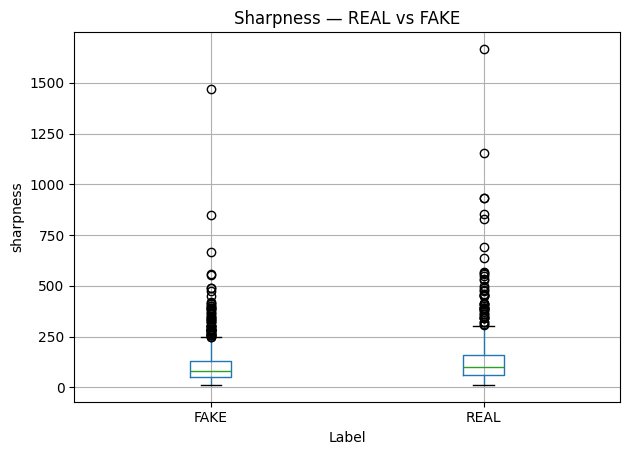

<Figure size 800x500 with 0 Axes>

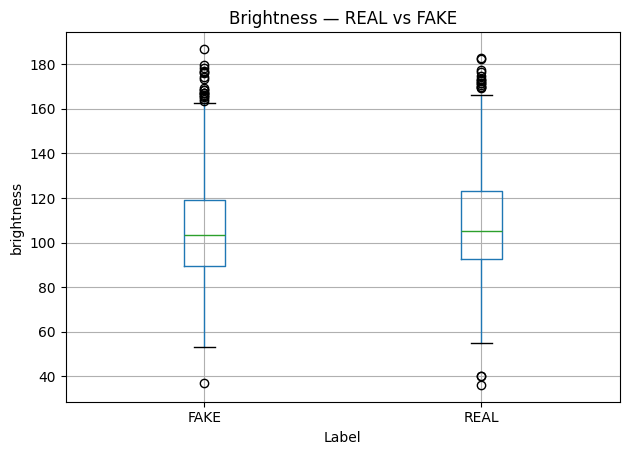

<Figure size 800x500 with 0 Axes>

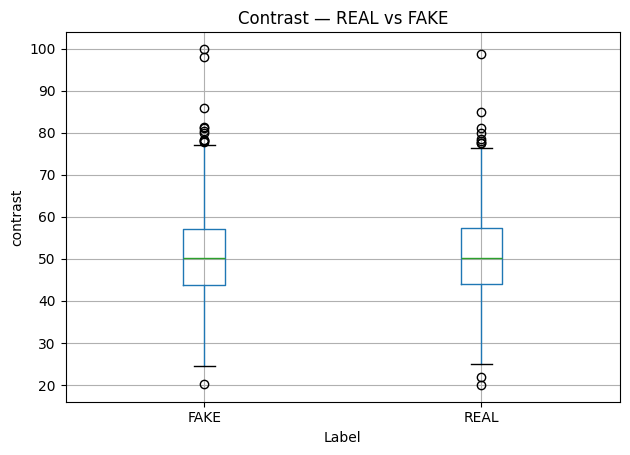

<Figure size 800x500 with 0 Axes>

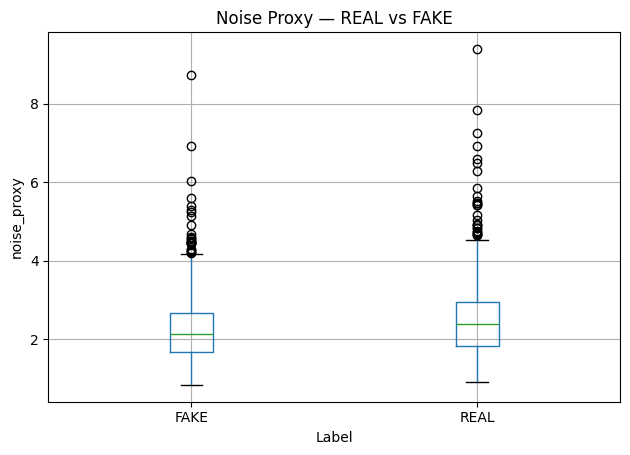

<Figure size 1000x500 with 0 Axes>

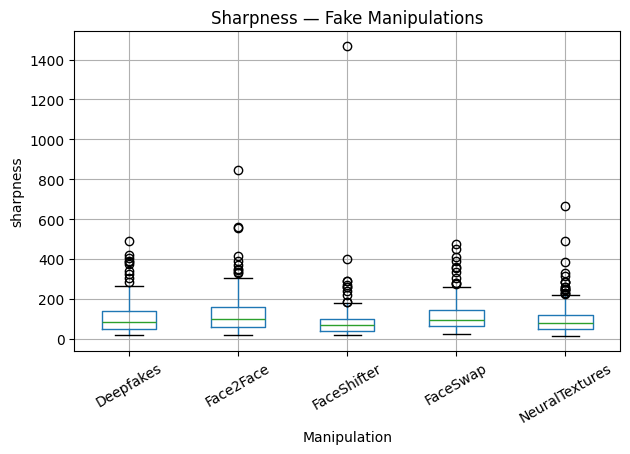

<Figure size 1000x500 with 0 Axes>

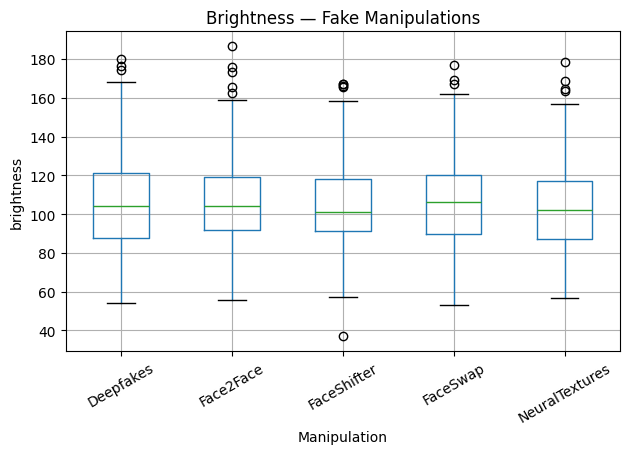

<Figure size 1000x500 with 0 Axes>

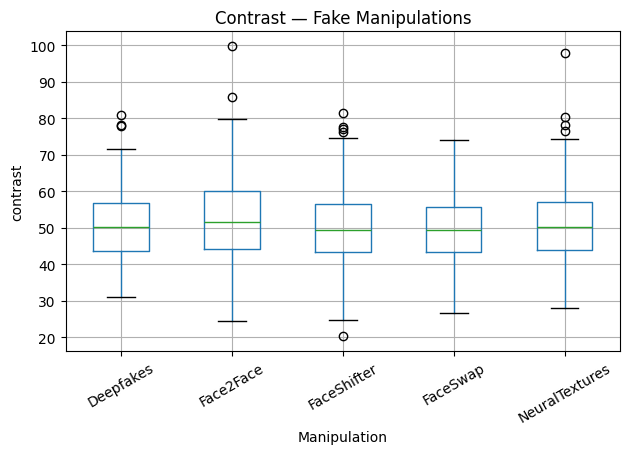

<Figure size 1000x500 with 0 Axes>

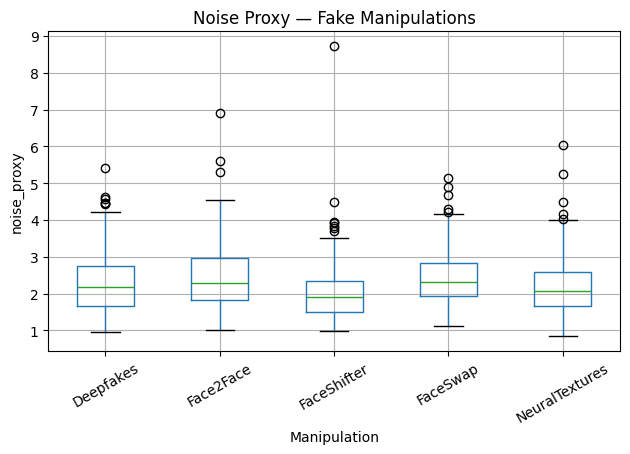


IMAGE QUALITY AUDIT COMPLETE


In [11]:
# ============================================================
# CELL 10 — IMAGE QUALITY DISTRIBUTION AUDIT
# ============================================================

print("=" * 70)
print("IMAGE QUALITY DISTRIBUTION AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

QUALITY_SAMPLE_PER_GROUP = 300

QUALITY_SEED = 42

rng = np.random.default_rng(QUALITY_SEED)

print("\nSample size per group :", QUALITY_SAMPLE_PER_GROUP)
print("Quality audit seed    :", QUALITY_SEED)


# ------------------------------------------------------------
# Helper: calculate image-quality features
# ------------------------------------------------------------

def calculate_quality_features(image_path):
    """
    Calculate simple image-quality proxies.

    Sharpness:
        Variance of Laplacian.

    Brightness:
        Mean grayscale intensity.

    Contrast:
        Standard deviation of grayscale intensity.

    Noise proxy:
        Standard deviation of high-frequency residual.
    """

    image = cv2.imread(str(image_path))

    if image is None:
        return None

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # --------------------------------------------------------
    # Sharpness
    # --------------------------------------------------------
    sharpness = cv2.Laplacian(
        gray,
        cv2.CV_64F
    ).var()

    # --------------------------------------------------------
    # Brightness
    # --------------------------------------------------------
    brightness = gray.mean()

    # --------------------------------------------------------
    # Contrast
    # --------------------------------------------------------
    contrast = gray.std()

    # --------------------------------------------------------
    # Noise proxy
    #
    # Remove low-frequency structure using Gaussian blur.
    # The remaining high-frequency residual is used as a
    # simple noise/detail proxy.
    # --------------------------------------------------------
    blurred = cv2.GaussianBlur(
        gray,
        (3, 3),
        0
    )

    residual = (
        gray.astype(np.float32)
        - blurred.astype(np.float32)
    )

    noise_proxy = residual.std()

    return {
        "sharpness": float(sharpness),
        "brightness": float(brightness),
        "contrast": float(contrast),
        "noise_proxy": float(noise_proxy)
    }


# ------------------------------------------------------------
# Build image-level quality sample
# ------------------------------------------------------------

quality_records = []

for split in ["train", "val", "test"]:

    split_df = metadata[
        metadata["split"] == split
    ].copy()

    for label in ["REAL", "FAKE"]:

        group_df = split_df[
            split_df["label"].str.upper() == label
        ]

        # Reproducible sampling
        sample_size = min(
            QUALITY_SAMPLE_PER_GROUP,
            len(group_df)
        )

        sampled = group_df.sample(
            n=sample_size,
            random_state=QUALITY_SEED
        )

        print(
            f"{split.upper():5s} | "
            f"{label:4s} | "
            f"images sampled: {len(sampled):4d}"
        )

        for _, row in sampled.iterrows():

            image_path = FACES_ROOT / row["filename"]

            features = calculate_quality_features(
                image_path
            )

            if features is None:
                continue

            quality_records.append({
                "filename": row["filename"],
                "split": row["split"],
                "label": row["label"].upper(),
                "method": row["method"],
                "source_video": row["source_video"],
                **features
            })


quality_df = pd.DataFrame(
    quality_records
)

print("\n" + "=" * 70)
print("QUALITY AUDIT DATASET")
print("=" * 70)

print(
    "Successfully analyzed:",
    f"{len(quality_df):,}",
    "images"
)

display(
    quality_df.head()
)


# ------------------------------------------------------------
# Overall REAL vs FAKE statistics
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("OVERALL REAL vs FAKE QUALITY")
print("-" * 70)

quality_summary = (
    quality_df
    .groupby("label")[
        [
            "sharpness",
            "brightness",
            "contrast",
            "noise_proxy"
        ]
    ]
    .agg(["mean", "median", "std"])
)

display(
    quality_summary.round(3)
)


# ------------------------------------------------------------
# Percentage difference: FAKE vs REAL
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("FAKE vs REAL — PERCENTAGE DIFFERENCE")
print("-" * 70)

real_means = (
    quality_df[
        quality_df["label"] == "REAL"
    ][
        [
            "sharpness",
            "brightness",
            "contrast",
            "noise_proxy"
        ]
    ]
    .mean()
)

fake_means = (
    quality_df[
        quality_df["label"] == "FAKE"
    ][
        [
            "sharpness",
            "brightness",
            "contrast",
            "noise_proxy"
        ]
    ]
    .mean()
)

percentage_difference = (
    (fake_means - real_means)
    / real_means
    * 100
)

comparison_df = pd.DataFrame({
    "REAL mean": real_means,
    "FAKE mean": fake_means,
    "FAKE vs REAL (%)": percentage_difference
})

display(
    comparison_df.round(3)
)


# ------------------------------------------------------------
# Per-manipulation analysis
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("QUALITY BY FAKE MANIPULATION")
print("-" * 70)

fake_quality = quality_df[
    quality_df["label"] == "FAKE"
]

method_summary = (
    fake_quality
    .groupby("method")[
        [
            "sharpness",
            "brightness",
            "contrast",
            "noise_proxy"
        ]
    ]
    .agg(["mean", "median", "std"])
)

display(
    method_summary.round(3)
)


# ------------------------------------------------------------
# REAL vs each manipulation
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("REAL vs EACH FAKE MANIPULATION")
print("-" * 70)

real_quality = quality_df[
    quality_df["label"] == "REAL"
]

real_reference = real_quality[
    [
        "sharpness",
        "brightness",
        "contrast",
        "noise_proxy"
    ]
].mean()

method_comparisons = []

for method in sorted(fake_quality["method"].unique()):

    method_values = fake_quality[
        fake_quality["method"] == method
    ][
        [
            "sharpness",
            "brightness",
            "contrast",
            "noise_proxy"
        ]
    ].mean()

    difference = (
        (method_values - real_reference)
        / real_reference
        * 100
    )

    for feature in difference.index:

        method_comparisons.append({
            "method": method,
            "feature": feature,
            "REAL mean": real_reference[feature],
            "FAKE mean": method_values[feature],
            "difference (%)": difference[feature]
        })

method_comparison_df = pd.DataFrame(
    method_comparisons
)

display(
    method_comparison_df.round(3)
)


# ------------------------------------------------------------
# Quality distributions — box plots
# ------------------------------------------------------------

quality_features = [
    "sharpness",
    "brightness",
    "contrast",
    "noise_proxy"
]

for feature in quality_features:

    plt.figure(figsize=(8, 5))

    quality_df.boxplot(
        column=feature,
        by="label"
    )

    plt.title(
        f"{feature.replace('_', ' ').title()} — REAL vs FAKE"
    )

    plt.suptitle("")

    plt.xlabel("Label")
    plt.ylabel(feature)

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# Quality distributions by manipulation
# ------------------------------------------------------------

for feature in quality_features:

    plt.figure(figsize=(10, 5))

    fake_quality.boxplot(
        column=feature,
        by="method",
        rot=30
    )

    plt.title(
        f"{feature.replace('_', ' ').title()} — Fake Manipulations"
    )

    plt.suptitle("")

    plt.xlabel("Manipulation")
    plt.ylabel(feature)

    plt.tight_layout()
    plt.show()


print("\n" + "=" * 70)
print("IMAGE QUALITY AUDIT COMPLETE")
print("=" * 70)

In [12]:
# ============================================================
# CELL 11 — FULL DATASET IMAGE-QUALITY AUDIT
# ============================================================

print("=" * 70)
print("FULL 20,000-IMAGE QUALITY AUDIT")
print("=" * 70)

full_quality_records = []

total_images = len(metadata)

for idx, row in enumerate(
    metadata.itertuples(index=False),
    start=1
):

    image_path = FACES_ROOT / row.filename

    features = calculate_quality_features(
        image_path
    )

    if features is None:
        print(
            f"\n⚠️ Could not read image: {row.filename}"
        )
        continue

    full_quality_records.append({
        "filename": row.filename,
        "split": row.split,
        "label": str(row.label).upper(),
        "method": row.method,
        "source_video": row.source_video,
        **features
    })

    if idx % 1000 == 0 or idx == total_images:
        print(
            f"Processed: {idx:,} / {total_images:,}"
        )


full_quality_df = pd.DataFrame(
    full_quality_records
)

print("\n" + "=" * 70)
print("FULL QUALITY DATASET")
print("=" * 70)

print(
    "Successfully analyzed:",
    f"{len(full_quality_df):,}",
    "images"
)

print(
    "Failed:",
    f"{total_images - len(full_quality_df):,}"
)


# ------------------------------------------------------------
# Overall REAL vs FAKE
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("FULL DATASET — REAL vs FAKE")
print("-" * 70)

full_summary = (
    full_quality_df
    .groupby("label")[
        [
            "sharpness",
            "brightness",
            "contrast",
            "noise_proxy"
        ]
    ]
    .agg(["mean", "median", "std"])
)

display(
    full_summary.round(3)
)


# ------------------------------------------------------------
# Percentage difference
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("FULL DATASET — FAKE vs REAL")
print("-" * 70)

full_real_means = (
    full_quality_df[
        full_quality_df["label"] == "REAL"
    ][
        [
            "sharpness",
            "brightness",
            "contrast",
            "noise_proxy"
        ]
    ]
    .mean()
)

full_fake_means = (
    full_quality_df[
        full_quality_df["label"] == "FAKE"
    ][
        [
            "sharpness",
            "brightness",
            "contrast",
            "noise_proxy"
        ]
    ]
    .mean()
)

full_percentage_difference = (
    (full_fake_means - full_real_means)
    / full_real_means
    * 100
)

full_comparison = pd.DataFrame({
    "REAL mean": full_real_means,
    "FAKE mean": full_fake_means,
    "FAKE vs REAL (%)": full_percentage_difference
})

display(
    full_comparison.round(3)
)


# ------------------------------------------------------------
# Per-manipulation full-dataset analysis
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("FULL DATASET — FAKE MANIPULATIONS")
print("-" * 70)

full_fake_quality = full_quality_df[
    full_quality_df["label"] == "FAKE"
]

full_method_means = (
    full_fake_quality
    .groupby("method")[
        [
            "sharpness",
            "brightness",
            "contrast",
            "noise_proxy"
        ]
    ]
    .mean()
)

display(
    full_method_means.round(3)
)


# ------------------------------------------------------------
# Per-manipulation percentage difference from REAL
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("FULL DATASET — EACH MANIPULATION vs REAL")
print("-" * 70)

full_method_comparisons = []

for method in sorted(
    full_fake_quality["method"].unique()
):

    method_values = (
        full_fake_quality[
            full_fake_quality["method"] == method
        ][
            [
                "sharpness",
                "brightness",
                "contrast",
                "noise_proxy"
            ]
        ]
        .mean()
    )

    difference = (
        (method_values - full_real_means)
        / full_real_means
        * 100
    )

    for feature in difference.index:

        full_method_comparisons.append({
            "method": method,
            "feature": feature,
            "REAL mean": full_real_means[feature],
            "FAKE mean": method_values[feature],
            "difference (%)": difference[feature]
        })

full_method_comparison_df = pd.DataFrame(
    full_method_comparisons
)

display(
    full_method_comparison_df.round(3)
)


# ------------------------------------------------------------
# Quality statistics by split
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("QUALITY BY SPLIT")
print("-" * 70)

split_quality = (
    full_quality_df
    .groupby(["split", "label"])[
        [
            "sharpness",
            "brightness",
            "contrast",
            "noise_proxy"
        ]
    ]
    .mean()
)

display(
    split_quality.round(3)
)

print("\n" + "=" * 70)
print("FULL QUALITY AUDIT COMPLETE")
print("=" * 70)

FULL 20,000-IMAGE QUALITY AUDIT
Processed: 1,000 / 20,000
Processed: 2,000 / 20,000
Processed: 3,000 / 20,000
Processed: 4,000 / 20,000
Processed: 5,000 / 20,000
Processed: 6,000 / 20,000
Processed: 7,000 / 20,000
Processed: 8,000 / 20,000
Processed: 9,000 / 20,000
Processed: 10,000 / 20,000
Processed: 11,000 / 20,000
Processed: 12,000 / 20,000
Processed: 13,000 / 20,000
Processed: 14,000 / 20,000
Processed: 15,000 / 20,000
Processed: 16,000 / 20,000
Processed: 17,000 / 20,000
Processed: 18,000 / 20,000
Processed: 19,000 / 20,000
Processed: 20,000 / 20,000

FULL QUALITY DATASET
Successfully analyzed: 20,000 images
Failed: 0

----------------------------------------------------------------------
FULL DATASET — REAL vs FAKE
----------------------------------------------------------------------


sharpness                  brightness                  contrast          \
           mean  median      std       mean   median     std     mean  median   
label                                                                           
FAKE    107.576  81.622   96.387    106.504  104.515  24.049   50.481  49.833   
REAL    127.764  97.482  112.047    107.036  105.108  23.834   51.011  50.354   

              noise_proxy                
          std        mean median    std  
label                                    
FAKE   10.384       2.284  2.142  0.838  
REAL   10.622       2.485  2.342  0.908


----------------------------------------------------------------------
FULL DATASET — FAKE vs REAL
----------------------------------------------------------------------


,REAL mean,FAKE mean,FAKE vs REAL (%)
sharpness,127.764,107.576,-15.801
brightness,107.036,106.504,-0.497
contrast,51.011,50.481,-1.039
noise_proxy,2.485,2.284,-8.094



----------------------------------------------------------------------
FULL DATASET — FAKE MANIPULATIONS
----------------------------------------------------------------------


,sharpness,brightness,contrast,noise_proxy
method,,,,
Deepfakes,107.433,106.446,50.405,2.277
Face2Face,123.313,107.157,50.544,2.434
FaceShifter,84.742,105.679,50.308,2.045
FaceSwap,129.022,106.794,50.227,2.511
NeuralTextures,93.369,106.444,50.923,2.150



----------------------------------------------------------------------
FULL DATASET — EACH MANIPULATION vs REAL
----------------------------------------------------------------------


,method,feature,REAL mean,FAKE mean,difference (%)
0,Deepfakes,sharpness,127.764,107.433,-15.913
1,Deepfakes,brightness,107.036,106.446,-0.551
2,Deepfakes,contrast,51.011,50.405,-1.190
3,Deepfakes,noise_proxy,2.485,2.277,-8.346
4,Face2Face,sharpness,127.764,123.313,-3.483
5,Face2Face,brightness,107.036,107.157,0.113
6,Face2Face,contrast,51.011,50.544,-0.916
7,Face2Face,noise_proxy,2.485,2.434,-2.048
8,FaceShifter,sharpness,127.764,84.742,-33.673
9,FaceShifter,brightness,107.036,105.679,-1.268



----------------------------------------------------------------------
QUALITY BY SPLIT
----------------------------------------------------------------------


sharpness  brightness  contrast  noise_proxy
split label                                              
test  FAKE     110.812     105.762    51.711        2.301
      REAL     133.660     106.116    52.211        2.517
train FAKE     107.922     106.792    50.292        2.287
      REAL     128.342     107.379    50.854        2.491
val   FAKE     102.725     105.902    50.133        2.249
      REAL     119.167     106.356    50.544        2.424


FULL QUALITY AUDIT COMPLETE


In [13]:
# ============================================================
# CELL 12 — QUALITY-ONLY CLASSIFIER BASELINE
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("=" * 70)
print("QUALITY-ONLY CLASSIFIER BASELINE")
print("=" * 70)

# ------------------------------------------------------------
# Features
# ------------------------------------------------------------

QUALITY_FEATURES = [
    "sharpness",
    "brightness",
    "contrast",
    "noise_proxy"
]

print("\nFeatures used:")
for feature in QUALITY_FEATURES:
    print("  •", feature)

print("\nIMPORTANT:")
print("No image pixels are given to this classifier.")
print("Only low-level quality statistics are used.")


# ------------------------------------------------------------
# Prepare labels
# ------------------------------------------------------------

quality_model_df = full_quality_df.copy()

quality_model_df["target"] = (
    quality_model_df["label"]
    .map({
        "REAL": 0,
        "FAKE": 1
    })
)

# Check for unexpected labels
if quality_model_df["target"].isna().any():
    raise ValueError(
        "Unexpected labels found in quality dataset."
    )


# ------------------------------------------------------------
# Train / validation / test split
#
# We use the EXISTING leakage-safe splits.
# We do NOT randomly split the images again.
# ------------------------------------------------------------

train_quality = quality_model_df[
    quality_model_df["split"] == "train"
].copy()

val_quality = quality_model_df[
    quality_model_df["split"] == "val"
].copy()

test_quality = quality_model_df[
    quality_model_df["split"] == "test"
].copy()


X_train = train_quality[QUALITY_FEATURES]
y_train = train_quality["target"]

X_val = val_quality[QUALITY_FEATURES]
y_val = val_quality["target"]

X_test = test_quality[QUALITY_FEATURES]
y_test = test_quality["target"]


print("\nDataset sizes:")
print("Train:", f"{len(X_train):,}")
print("Val  :", f"{len(X_val):,}")
print("Test :", f"{len(X_test):,}")


# ------------------------------------------------------------
# Build quality-only model
# ------------------------------------------------------------

quality_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])


# ------------------------------------------------------------
# Train ONLY on training data
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("TRAINING QUALITY-ONLY MODEL")
print("-" * 70)

quality_model.fit(
    X_train,
    y_train
)

print("✅ Quality-only classifier trained")


# ------------------------------------------------------------
# Evaluation helper
# ------------------------------------------------------------

def evaluate_quality_model(
    model,
    X,
    y,
    split_name
):

    probabilities = model.predict_proba(X)[:, 1]

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    accuracy = accuracy_score(
        y,
        predictions
    )

    precision = precision_score(
        y,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y,
        predictions,
        zero_division=0
    )

    auc = roc_auc_score(
        y,
        probabilities
    )

    print("\n" + "=" * 70)
    print(f"{split_name.upper()} — QUALITY-ONLY RESULTS")
    print("=" * 70)

    print(f"Accuracy  : {accuracy * 100:.2f}%")
    print(f"Precision : {precision * 100:.2f}%")
    print(f"Recall    : {recall * 100:.2f}%")
    print(f"F1 Score  : {f1 * 100:.2f}%")
    print(f"ROC-AUC   : {auc:.4f}")

    print("\nConfusion Matrix:")
    print(
        confusion_matrix(
            y,
            predictions
        )
    )

    print("\nClassification Report:")
    print(
        classification_report(
            y,
            predictions,
            target_names=["REAL", "FAKE"],
            zero_division=0
        )
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": auc
    }


# ------------------------------------------------------------
# Validation evaluation
#
# Validation is the first evaluation we inspect.
# ------------------------------------------------------------

val_results = evaluate_quality_model(
    quality_model,
    X_val,
    y_val,
    "Validation"
)


# ------------------------------------------------------------
# Test evaluation
#
# The quality-only model has no hyperparameter tuning based
# on the test set. We therefore record the test result as a
# final diagnostic, not as a basis for changing the model.
# ------------------------------------------------------------

test_results = evaluate_quality_model(
    quality_model,
    X_test,
    y_test,
    "Test"
)


# ------------------------------------------------------------
# Compare validation and test
# ------------------------------------------------------------

comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ],
    "Validation": [
        val_results["accuracy"],
        val_results["precision"],
        val_results["recall"],
        val_results["f1"],
        val_results["roc_auc"]
    ],
    "Test": [
        test_results["accuracy"],
        test_results["precision"],
        test_results["recall"],
        test_results["f1"],
        test_results["roc_auc"]
    ]
})

print("\n" + "=" * 70)
print("QUALITY-ONLY BASELINE SUMMARY")
print("=" * 70)

display(
    comparison.style.format({
        "Validation": "{:.4f}",
        "Test": "{:.4f}"
    })
)


# ------------------------------------------------------------
# Logistic regression coefficients
# ------------------------------------------------------------

classifier = quality_model.named_steps[
    "classifier"
]

coefficients = pd.DataFrame({
    "feature": QUALITY_FEATURES,
    "coefficient": classifier.coef_[0]
})

coefficients["absolute_importance"] = (
    coefficients["coefficient"].abs()
)

coefficients = coefficients.sort_values(
    "absolute_importance",
    ascending=False
)

print("\n" + "=" * 70)
print("QUALITY FEATURE COEFFICIENTS")
print("=" * 70)

display(
    coefficients.round(4)
)

print("\n" + "=" * 70)
print("QUALITY-ONLY BASELINE COMPLETE")
print("=" * 70)

QUALITY-ONLY CLASSIFIER BASELINE

Features used:
  • sharpness
  • brightness
  • contrast
  • noise_proxy

IMPORTANT:
No image pixels are given to this classifier.
Only low-level quality statistics are used.

Dataset sizes:
Train: 14,000
Val  : 3,000
Test : 3,000

----------------------------------------------------------------------
TRAINING QUALITY-ONLY MODEL
----------------------------------------------------------------------
✅ Quality-only classifier trained

VALIDATION — QUALITY-ONLY RESULTS
Accuracy  : 55.93%
Precision : 55.87%
Recall    : 56.47%
F1 Score  : 56.17%
ROC-AUC   : 0.5694

Confusion Matrix:
[[831 669]
 [653 847]]

Classification Report:
              precision    recall  f1-score   support

        REAL       0.56      0.55      0.56      1500
        FAKE       0.56      0.56      0.56      1500

    accuracy                           0.56      3000
   macro avg       0.56      0.56      0.56      3000
weighted avg       0.56      0.56      0.56      3000


TEST —

,Metric,Validation,Test
0,Accuracy,0.5593,0.5537
1,Precision,0.5587,0.5515
2,Recall,0.5647,0.5747
3,F1,0.5617,0.5628
4,ROC-AUC,0.5694,0.5745



QUALITY FEATURE COEFFICIENTS


,feature,coefficient,absolute_importance
3,noise_proxy,-0.5937,0.5937
0,sharpness,0.3515,0.3515
1,brightness,0.0625,0.0625
2,contrast,0.0157,0.0157



QUALITY-ONLY BASELINE COMPLETE


LOW-QUALITY REAL COVERAGE AUDIT

----------------------------------------------------------------------
THRESHOLDS FROM TRAINING REAL IMAGES
----------------------------------------------------------------------


,sharpness,noise_proxy
REAL percentile,,
10,38.984,1.496
20,54.735,1.765
25,61.934,1.868



----------------------------------------------------------------------
LOW-SHARPNESS COVERAGE
----------------------------------------------------------------------


,REAL percentile threshold,sharpness threshold,REAL images,REAL %,FAKE images,FAKE %
0,10,38.984,700,10.0,981,14.014
1,20,54.735,1400,20.0,1953,27.900
2,25,61.934,1750,25.0,2352,33.600



----------------------------------------------------------------------
LOW-NOISE COVERAGE
----------------------------------------------------------------------


,REAL percentile threshold,noise threshold,REAL images,REAL %,FAKE images,FAKE %
0,10,1.496,700,10.0,994,14.200
1,20,1.765,1400,20.0,1970,28.143
2,25,1.868,1750,25.0,2332,33.314



----------------------------------------------------------------------
JOINT LOW-SHARPNESS + LOW-NOISE COVERAGE
----------------------------------------------------------------------


,REAL percentile threshold,sharpness threshold,noise threshold,REAL images,REAL %,FAKE images,FAKE %
0,10,38.984,1.496,685,9.786,965,13.786
1,20,54.735,1.765,1371,19.586,1928,27.543
2,25,61.934,1.868,1715,24.500,2298,32.829



----------------------------------------------------------------------
SOURCE DIVERSITY OF LOW-QUALITY REAL IMAGES
----------------------------------------------------------------------
Low-quality REAL images: 1,371
Unique source videos: 212
Total REAL source videos: 700
Source coverage: 30.29%


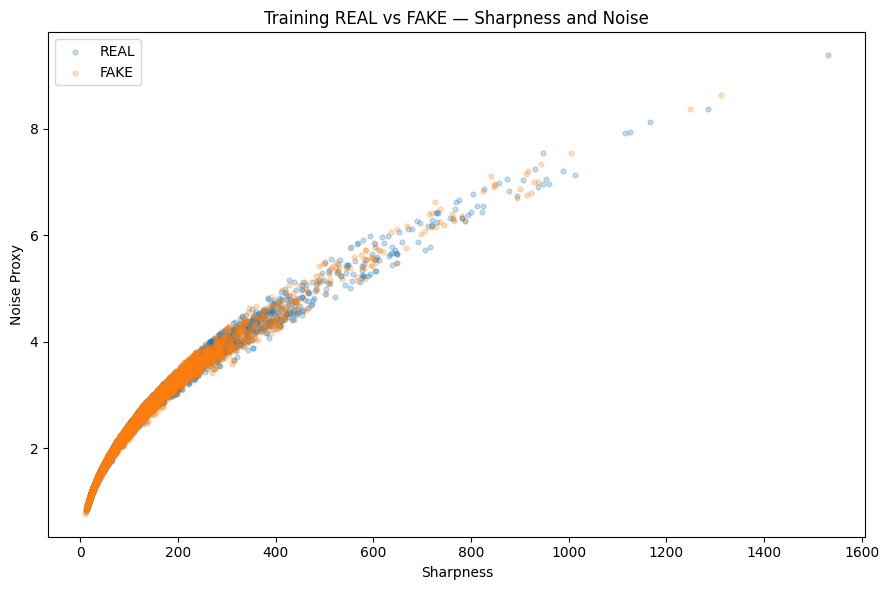


----------------------------------------------------------------------
VALIDATION — TRAIN-DERIVED LOW-QUALITY THRESHOLDS
----------------------------------------------------------------------
Validation low-quality REAL: 300 (20.00%)
Validation low-quality FAKE: 408 (27.20%)

LOW-QUALITY REAL COVERAGE AUDIT COMPLETE


In [14]:
# ============================================================
# CELL 13 — LOW-QUALITY REAL COVERAGE AUDIT
# ============================================================

print("=" * 70)
print("LOW-QUALITY REAL COVERAGE AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# We deliberately use TRAINING data to define thresholds.
# Validation/test are NOT used to define "low quality".
# ------------------------------------------------------------

train_quality = full_quality_df[
    full_quality_df["split"] == "train"
].copy()

val_quality = full_quality_df[
    full_quality_df["split"] == "val"
].copy()


# ------------------------------------------------------------
# Separate REAL and FAKE
# ------------------------------------------------------------

train_real = train_quality[
    train_quality["label"] == "REAL"
].copy()

train_fake = train_quality[
    train_quality["label"] == "FAKE"
].copy()


# ------------------------------------------------------------
# Define quality thresholds from TRAINING REAL images
# ------------------------------------------------------------

thresholds = {}

for percentile in [10, 20, 25]:

    thresholds[percentile] = {
        "sharpness": np.percentile(
            train_real["sharpness"],
            percentile
        ),
        "noise_proxy": np.percentile(
            train_real["noise_proxy"],
            percentile
        )
    }


print("\n" + "-" * 70)
print("THRESHOLDS FROM TRAINING REAL IMAGES")
print("-" * 70)

threshold_table = pd.DataFrame(
    thresholds
).T

threshold_table.index.name = "REAL percentile"

display(
    threshold_table.round(3)
)


# ------------------------------------------------------------
# Count low-sharpness REAL and FAKE
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("LOW-SHARPNESS COVERAGE")
print("-" * 70)

sharpness_rows = []

for percentile, values in thresholds.items():

    threshold = values["sharpness"]

    real_count = (
        train_real["sharpness"] <= threshold
    ).sum()

    fake_count = (
        train_fake["sharpness"] <= threshold
    ).sum()

    real_percentage = (
        real_count / len(train_real) * 100
    )

    fake_percentage = (
        fake_count / len(train_fake) * 100
    )

    sharpness_rows.append({
        "REAL percentile threshold": percentile,
        "sharpness threshold": threshold,
        "REAL images": real_count,
        "REAL %": real_percentage,
        "FAKE images": fake_count,
        "FAKE %": fake_percentage
    })

sharpness_coverage = pd.DataFrame(
    sharpness_rows
)

display(
    sharpness_coverage.round(3)
)


# ------------------------------------------------------------
# Count low-noise REAL and FAKE
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("LOW-NOISE COVERAGE")
print("-" * 70)

noise_rows = []

for percentile, values in thresholds.items():

    threshold = values["noise_proxy"]

    real_count = (
        train_real["noise_proxy"] <= threshold
    ).sum()

    fake_count = (
        train_fake["noise_proxy"] <= threshold
    ).sum()

    real_percentage = (
        real_count / len(train_real) * 100
    )

    fake_percentage = (
        fake_count / len(train_fake) * 100
    )

    noise_rows.append({
        "REAL percentile threshold": percentile,
        "noise threshold": threshold,
        "REAL images": real_count,
        "REAL %": real_percentage,
        "FAKE images": fake_count,
        "FAKE %": fake_percentage
    })

noise_coverage = pd.DataFrame(
    noise_rows
)

display(
    noise_coverage.round(3)
)


# ------------------------------------------------------------
# Joint low-quality condition
#
# This is particularly important because our earlier analysis
# showed BOTH sharpness and noise differences.
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("JOINT LOW-SHARPNESS + LOW-NOISE COVERAGE")
print("-" * 70)

joint_rows = []

for percentile, values in thresholds.items():

    sharp_threshold = values["sharpness"]
    noise_threshold = values["noise_proxy"]

    real_mask = (
        (train_real["sharpness"] <= sharp_threshold)
        &
        (train_real["noise_proxy"] <= noise_threshold)
    )

    fake_mask = (
        (train_fake["sharpness"] <= sharp_threshold)
        &
        (train_fake["noise_proxy"] <= noise_threshold)
    )

    real_count = real_mask.sum()
    fake_count = fake_mask.sum()

    joint_rows.append({
        "REAL percentile threshold": percentile,
        "sharpness threshold": sharp_threshold,
        "noise threshold": noise_threshold,
        "REAL images": real_count,
        "REAL %": real_count / len(train_real) * 100,
        "FAKE images": fake_count,
        "FAKE %": fake_count / len(train_fake) * 100
    })

joint_coverage = pd.DataFrame(
    joint_rows
)

display(
    joint_coverage.round(3)
)


# ------------------------------------------------------------
# Source diversity of low-quality REAL examples
#
# We want to know whether low-quality REAL images occur across
# many different source videos or are concentrated in only a
# few sources.
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("SOURCE DIVERSITY OF LOW-QUALITY REAL IMAGES")
print("-" * 70)

sharp_20_threshold = thresholds[20]["sharpness"]
noise_20_threshold = thresholds[20]["noise_proxy"]

low_quality_real = train_real[
    (train_real["sharpness"] <= sharp_20_threshold)
    &
    (train_real["noise_proxy"] <= noise_20_threshold)
].copy()

unique_sources = (
    low_quality_real["source_video"]
    .nunique()
)

total_real_sources = (
    train_real["source_video"]
    .nunique()
)

print(
    "Low-quality REAL images:",
    f"{len(low_quality_real):,}"
)

print(
    "Unique source videos:",
    f"{unique_sources:,}"
)

print(
    "Total REAL source videos:",
    f"{total_real_sources:,}"
)

print(
    "Source coverage:",
    f"{unique_sources / total_real_sources * 100:.2f}%"
)


# ------------------------------------------------------------
# Distribution plot
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

plt.scatter(
    train_real["sharpness"],
    train_real["noise_proxy"],
    alpha=0.25,
    s=12,
    label="REAL"
)

plt.scatter(
    train_fake["sharpness"],
    train_fake["noise_proxy"],
    alpha=0.25,
    s=12,
    label="FAKE"
)

plt.xlabel("Sharpness")
plt.ylabel("Noise Proxy")
plt.title(
    "Training REAL vs FAKE — Sharpness and Noise"
)

plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Validation check
#
# We apply the TRAIN-derived thresholds to validation.
# This tells us whether the low-quality REAL population exists
# outside the training set as well.
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("VALIDATION — TRAIN-DERIVED LOW-QUALITY THRESHOLDS")
print("-" * 70)

val_real = val_quality[
    val_quality["label"] == "REAL"
].copy()

val_fake = val_quality[
    val_quality["label"] == "FAKE"
].copy()

val_real_low = val_real[
    (val_real["sharpness"] <= sharp_20_threshold)
    &
    (val_real["noise_proxy"] <= noise_20_threshold)
]

val_fake_low = val_fake[
    (val_fake["sharpness"] <= sharp_20_threshold)
    &
    (val_fake["noise_proxy"] <= noise_20_threshold)
]

print(
    "Validation low-quality REAL:",
    f"{len(val_real_low):,}",
    f"({len(val_real_low) / len(val_real) * 100:.2f}%)"
)

print(
    "Validation low-quality FAKE:",
    f"{len(val_fake_low):,}",
    f"({len(val_fake_low) / len(val_fake) * 100:.2f}%)"
)


print("\n" + "=" * 70)
print("LOW-QUALITY REAL COVERAGE AUDIT COMPLETE")
print("=" * 70)

QUALITY-BIN DISTRIBUTION AUDIT

----------------------------------------------------------------------
SHARPNESS QUALITY BINS
----------------------------------------------------------------------

Thresholds derived from TRAINING REAL:
   percentile   threshold
0           0        -inf
1          10   38.983730
2          20   54.735395
3          40   82.638498
4          60  116.716531
5          80  171.369197
6         100         inf

REAL/FAKE distribution:


,REAL,FAKE,TOTAL,REAL %,FAKE %,FAKE/REAL ratio
sharpness quality bin,,,,,,
0-10%,700,981,1681,41.642,58.358,1.401
10-20%,700,972,1672,41.866,58.134,1.389
20-40%,1400,1559,2959,47.313,52.687,1.114
40-60%,1400,1398,2798,50.036,49.964,0.999
60-80%,1400,1095,2495,56.112,43.888,0.782
80-100%,1400,995,2395,58.455,41.545,0.711



----------------------------------------------------------------------
NOISE-PROXY QUALITY BINS
----------------------------------------------------------------------

Thresholds derived from TRAINING REAL:
   percentile  threshold
0           0       -inf
1          10   1.495733
2          20   1.764885
3          40   2.163780
4          60   2.555485
5          80   3.069066
6         100        inf

REAL/FAKE distribution:


,REAL,FAKE,TOTAL,REAL %,FAKE %,FAKE/REAL ratio
noise_proxy quality bin,,,,,,
0-10%,700,994,1694,41.322,58.678,1.420
10-20%,700,976,1676,41.766,58.234,1.394
20-40%,1400,1585,2985,46.901,53.099,1.132
40-60%,1400,1388,2788,50.215,49.785,0.991
60-80%,1400,1071,2471,56.657,43.343,0.765
80-100%,1400,986,2386,58.676,41.324,0.704



----------------------------------------------------------------------
JOINT LOW-QUALITY REGION
----------------------------------------------------------------------


,region,REAL,FAKE,TOTAL,REAL %,FAKE %
0,Very low quality,1371,1928,3299,41.558,58.442
1,Other quality,5629,5072,10701,52.603,47.397



----------------------------------------------------------------------
FAKE MANIPULATIONS ACROSS SHARPNESS BINS
----------------------------------------------------------------------


method,Deepfakes,Face2Face,FaceShifter,FaceSwap,NeuralTextures
sharpness_bin,,,,,
0-10%,193,146,300,84,258
10-20%,207,153,243,145,224
20-40%,334,288,356,270,311
40-60%,265,284,239,313,297
60-80%,191,276,133,329,166
80-100%,210,253,129,259,144


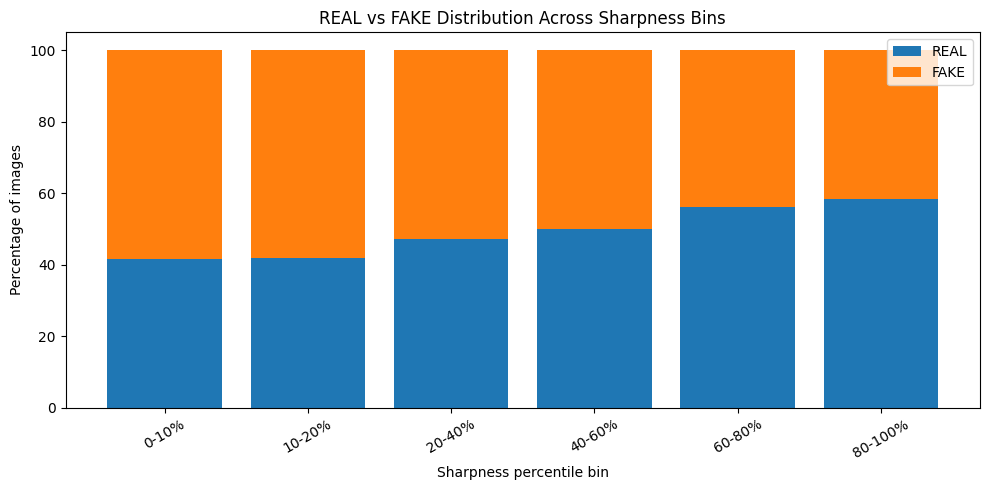

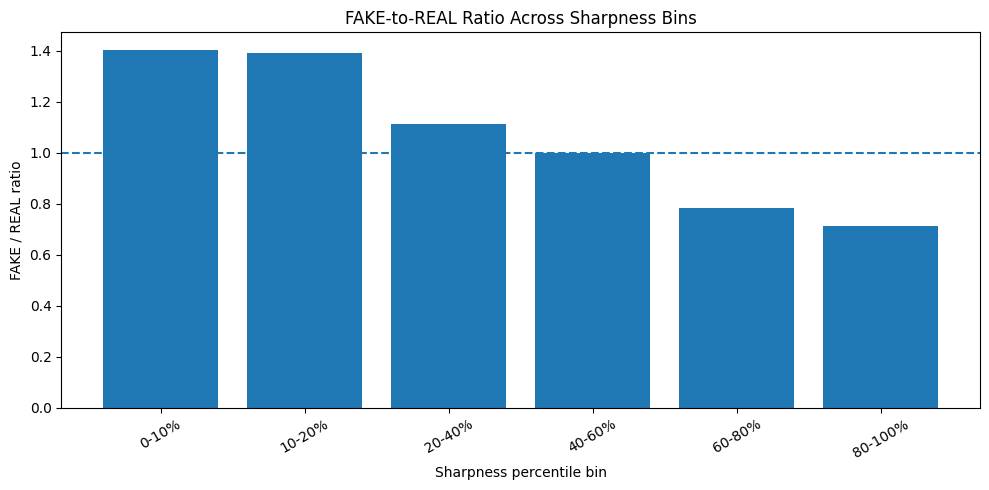


QUALITY-BIN AUDIT COMPLETE


In [15]:
# ============================================================
# CELL 14 — QUALITY-BIN DISTRIBUTION AUDIT
# ============================================================

print("=" * 70)
print("QUALITY-BIN DISTRIBUTION AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# IMPORTANT:
# Bins are defined ONLY from TRAINING REAL images.
# Validation and test are not used to construct thresholds.
# ------------------------------------------------------------

train_real = full_quality_df[
    (full_quality_df["split"] == "train") &
    (full_quality_df["label"] == "REAL")
].copy()

train_fake = full_quality_df[
    (full_quality_df["split"] == "train") &
    (full_quality_df["label"] == "FAKE")
].copy()


# ------------------------------------------------------------
# Define percentile bins
# ------------------------------------------------------------

BIN_PERCENTILES = [0, 10, 20, 40, 60, 80, 100]

BIN_LABELS = [
    "0-10%",
    "10-20%",
    "20-40%",
    "40-60%",
    "60-80%",
    "80-100%"
]


def create_quality_bins(
    real_df,
    fake_df,
    feature
):
    """
    Create bins using the TRAINING REAL distribution.

    The same thresholds are then applied to both REAL and FAKE.
    """

    thresholds = np.percentile(
        real_df[feature],
        BIN_PERCENTILES
    )

    # Ensure monotonically increasing boundaries.
    # Duplicate boundaries can occur with some features.
    thresholds = np.maximum.accumulate(thresholds)

    # Make first/last boundaries safely inclusive.
    thresholds[0] = -np.inf
    thresholds[-1] = np.inf

    real_bins = pd.cut(
        real_df[feature],
        bins=thresholds,
        labels=BIN_LABELS,
        include_lowest=True,
        duplicates="drop"
    )

    fake_bins = pd.cut(
        fake_df[feature],
        bins=thresholds,
        labels=BIN_LABELS,
        include_lowest=True,
        duplicates="drop"
    )

    real_counts = (
        real_bins
        .value_counts(sort=False)
        .reindex(BIN_LABELS, fill_value=0)
    )

    fake_counts = (
        fake_bins
        .value_counts(sort=False)
        .reindex(BIN_LABELS, fill_value=0)
    )

    result = pd.DataFrame({
        "REAL": real_counts,
        "FAKE": fake_counts
    })

    result["TOTAL"] = (
        result["REAL"] +
        result["FAKE"]
    )

    result["REAL %"] = (
        result["REAL"] /
        result["TOTAL"] *
        100
    )

    result["FAKE %"] = (
        result["FAKE"] /
        result["TOTAL"] *
        100
    )

    result["FAKE/REAL ratio"] = (
        result["FAKE"] /
        result["REAL"].replace(0, np.nan)
    )

    result.index.name = (
        f"{feature} quality bin"
    )

    return result, thresholds


# ------------------------------------------------------------
# SHARPNESS BINS
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("SHARPNESS QUALITY BINS")
print("-" * 70)

sharpness_bins, sharpness_thresholds = create_quality_bins(
    train_real,
    train_fake,
    "sharpness"
)

print("\nThresholds derived from TRAINING REAL:")
print(
    pd.DataFrame({
        "percentile": BIN_PERCENTILES,
        "threshold": sharpness_thresholds
    })
)

print("\nREAL/FAKE distribution:")
display(
    sharpness_bins.round(3)
)


# ------------------------------------------------------------
# NOISE BINS
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("NOISE-PROXY QUALITY BINS")
print("-" * 70)

noise_bins, noise_thresholds = create_quality_bins(
    train_real,
    train_fake,
    "noise_proxy"
)

print("\nThresholds derived from TRAINING REAL:")
print(
    pd.DataFrame({
        "percentile": BIN_PERCENTILES,
        "threshold": noise_thresholds
    })
)

print("\nREAL/FAKE distribution:")
display(
    noise_bins.round(3)
)


# ------------------------------------------------------------
# Joint quality bins
#
# We use the two strongest quality signals together.
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("JOINT LOW-QUALITY REGION")
print("-" * 70)

sharp_20 = np.percentile(
    train_real["sharpness"],
    20
)

noise_20 = np.percentile(
    train_real["noise_proxy"],
    20
)

conditions = {
    "Very low quality": (
        lambda df:
        (df["sharpness"] <= sharp_20) &
        (df["noise_proxy"] <= noise_20)
    ),

    "Other quality": (
        lambda df:
        ~(
            (df["sharpness"] <= sharp_20) &
            (df["noise_proxy"] <= noise_20)
        )
    )
}

joint_rows = []

for region_name, condition_fn in conditions.items():

    real_count = condition_fn(
        train_real
    ).sum()

    fake_count = condition_fn(
        train_fake
    ).sum()

    total = real_count + fake_count

    joint_rows.append({
        "region": region_name,
        "REAL": real_count,
        "FAKE": fake_count,
        "TOTAL": total,
        "REAL %": (
            real_count / total * 100
            if total else 0
        ),
        "FAKE %": (
            fake_count / total * 100
            if total else 0
        )
    })

joint_quality_bins = pd.DataFrame(
    joint_rows
)

display(
    joint_quality_bins.round(3)
)


# ------------------------------------------------------------
# Manipulation distribution inside quality bins
#
# This is important because quality differences vary by
# manipulation method.
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("FAKE MANIPULATIONS ACROSS SHARPNESS BINS")
print("-" * 70)

fake_with_bins = train_fake.copy()

fake_with_bins["sharpness_bin"] = pd.cut(
    fake_with_bins["sharpness"],
    bins=sharpness_thresholds,
    labels=BIN_LABELS,
    include_lowest=True,
    duplicates="drop"
)

method_bin_table = pd.crosstab(
    fake_with_bins["sharpness_bin"],
    fake_with_bins["method"]
)

display(
    method_bin_table
)


# ------------------------------------------------------------
# Visualization — REAL/FAKE proportion by sharpness bin
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

x = np.arange(len(sharpness_bins))

plt.bar(
    x,
    sharpness_bins["REAL %"],
    label="REAL"
)

plt.bar(
    x,
    sharpness_bins["FAKE %"],
    bottom=sharpness_bins["REAL %"],
    label="FAKE"
)

plt.xticks(
    x,
    sharpness_bins.index,
    rotation=30
)

plt.xlabel("Sharpness percentile bin")
plt.ylabel("Percentage of images")
plt.title(
    "REAL vs FAKE Distribution Across Sharpness Bins"
)

plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Visualization — FAKE/REAL ratio
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.bar(
    x,
    sharpness_bins["FAKE/REAL ratio"]
)

plt.axhline(
    1.0,
    linestyle="--"
)

plt.xticks(
    x,
    sharpness_bins.index,
    rotation=30
)

plt.xlabel("Sharpness percentile bin")
plt.ylabel("FAKE / REAL ratio")
plt.title(
    "FAKE-to-REAL Ratio Across Sharpness Bins"
)

plt.tight_layout()
plt.show()


print("\n" + "=" * 70)
print("QUALITY-BIN AUDIT COMPLETE")
print("=" * 70)

SOURCE-PAIRED QUALITY GAP AUDIT

----------------------------------------------------------------------
SOURCE ID VERIFICATION
----------------------------------------------------------------------


,source_video,label,method,source_id
50,000_003.mp4,FAKE,Deepfakes,000
52,000_003.mp4,FAKE,Face2Face,000
58,000_003.mp4,FAKE,FaceShifter,000
54,000_003.mp4,FAKE,FaceSwap,000
56,000_003.mp4,FAKE,NeuralTextures,000
0,000.mp4,REAL,original,000
10010,001_870.mp4,FAKE,Deepfakes,001
12008,001_870.mp4,FAKE,Face2Face,001
18002,001_870.mp4,FAKE,FaceShifter,001
14006,001_870.mp4,FAKE,FaceSwap,001



----------------------------------------------------------------------
PAIRING CHECK
----------------------------------------------------------------------
Unique REAL source IDs: 700
Unique FAKE source IDs: 700
Source-method pairs matched: 3500
Expected source-method pairs: 3500

✅ ALL expected REAL/FAKE source-method pairs were matched.

----------------------------------------------------------------------
WITHIN-SOURCE QUALITY GAPS BY MANIPULATION
----------------------------------------------------------------------


sharpness_gap_pct                 noise_gap_pct          \
                            mean  median     std          mean  median   
method                                                                   
Deepfakes                -14.563 -15.289  19.385        -7.902  -7.927   
Face2Face                 -2.787  -3.178  14.714        -1.979  -1.851   
FaceShifter              -30.930 -31.594  15.594       -16.816 -16.769   
FaceSwap                   7.871   1.954  29.990         2.512   0.580   
NeuralTextures           -25.741 -25.840  12.226       -13.314 -13.184   

                       brightness_gap_pct               contrast_gap_pct  \
                   std               mean median    std             mean   
method                                                                     
Deepfakes       10.372             -0.734 -0.641  4.146           -1.036   
Face2Face        7.148              0.043  0.002  2.292           -1.033   
FaceShifter      8.923             -1.259 -1.146  2.681           -1.427   
FaceSwap        12.689             -0.393 -0.337  2.549           -1.349   
NeuralTextures   6.692             -0.600 -0.607  2.140           -0.186   

                              
               median    std  
method                        
Deepfakes      -1.019  5.616  
Face2Face      -0.794  2.779  
FaceShifter    -1.175  3.657  
FaceSwap       -1.585  4.384  
NeuralTextures -0.124  2.330


----------------------------------------------------------------------
WITHIN-SOURCE DIRECTION CONSISTENCY
----------------------------------------------------------------------


,method,FAKE lower sharpness (%),FAKE lower noise (%),FAKE lower brightness (%),FAKE lower contrast (%)
0,Deepfakes,79.29,78.86,58.00,59.14
1,Face2Face,60.43,62.14,49.86,69.29
2,FaceShifter,97.29,97.57,70.57,63.14
3,FaceSwap,46.71,48.14,57.00,63.00
4,NeuralTextures,97.71,97.71,66.14,53.86



----------------------------------------------------------------------
EXAMPLE SOURCE-PAIRED COMPARISONS
----------------------------------------------------------------------


,source_id,method,real_sharpness,fake_sharpness,sharpness_gap_pct,real_noise,fake_noise,noise_gap_pct
0,000,Deepfakes,189.257,178.744,-5.555,3.275,3.188,-2.677
1,000,Face2Face,189.257,163.572,-13.572,3.275,3.037,-7.267
2,000,FaceShifter,189.257,104.939,-44.552,3.275,2.458,-24.964
3,000,FaceSwap,189.257,171.715,-9.269,3.275,3.105,-5.194
4,000,NeuralTextures,189.257,126.009,-33.419,3.275,2.692,-17.798
5,001,Deepfakes,58.967,58.258,-1.202,1.835,1.828,-0.362
6,001,Face2Face,58.967,50.491,-14.374,1.835,1.688,-8.008
7,001,FaceShifter,58.967,47.379,-19.651,1.835,1.653,-9.876
8,001,FaceSwap,58.967,52.492,-10.981,1.835,1.715,-6.539
9,001,NeuralTextures,58.967,47.607,-19.265,1.835,1.655,-9.766


<Figure size 1000x600 with 0 Axes>

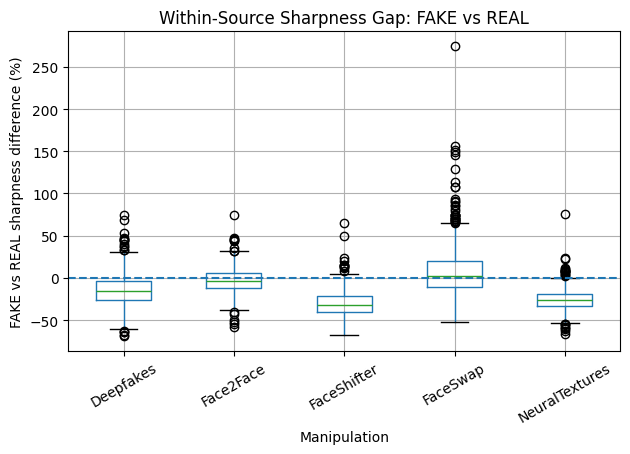

<Figure size 1000x600 with 0 Axes>

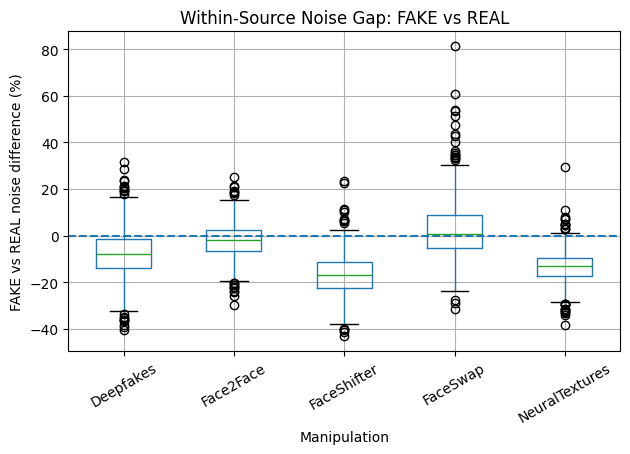


SOURCE-PAIRED QUALITY AUDIT COMPLETE


In [17]:
# ============================================================
# CELL 15 — CORRECTED SOURCE-PAIRED QUALITY GAP AUDIT
# ============================================================

print("=" * 70)
print("SOURCE-PAIRED QUALITY GAP AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# TRAINING DATA ONLY
# ------------------------------------------------------------

train_q = full_quality_df[
    full_quality_df["split"] == "train"
].copy()


# ------------------------------------------------------------
# IMPORTANT:
# REAL and FAKE source_video names are different.
#
# REAL:
#     000.mp4
#
# FAKE:
#     000_003.mp4
#
# Both map to:
#     source_id = 000
#
# Therefore we MUST create canonical source_id.
# ------------------------------------------------------------

train_q["video_stem"] = (
    train_q["source_video"]
    .astype(str)
    .str.replace(".mp4", "", regex=False)
)

train_q["source_id"] = (
    train_q["video_stem"]
    .str.split("_")
    .str[0]
)


# ------------------------------------------------------------
# Verify source ID extraction
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("SOURCE ID VERIFICATION")
print("-" * 70)

display(
    train_q[
        [
            "source_video",
            "label",
            "method",
            "source_id"
        ]
    ]
    .drop_duplicates()
    .sort_values(
        ["source_id", "label", "method"]
    )
    .head(20)
)


# ------------------------------------------------------------
# Separate REAL and FAKE
# ------------------------------------------------------------

train_real_q = train_q[
    train_q["label"] == "REAL"
].copy()

train_fake_q = train_q[
    train_q["label"] == "FAKE"
].copy()


# ------------------------------------------------------------
# REAL quality per SOURCE ID
# ------------------------------------------------------------

real_by_source = (
    train_real_q
    .groupby("source_id")[
        [
            "sharpness",
            "noise_proxy",
            "brightness",
            "contrast"
        ]
    ]
    .mean()
    .rename(columns={
        "sharpness": "real_sharpness",
        "noise_proxy": "real_noise",
        "brightness": "real_brightness",
        "contrast": "real_contrast"
    })
)


# ------------------------------------------------------------
# FAKE quality per SOURCE ID + METHOD
# ------------------------------------------------------------

fake_by_source = (
    train_fake_q
    .groupby(
        ["source_id", "method"]
    )[
        [
            "sharpness",
            "noise_proxy",
            "brightness",
            "contrast"
        ]
    ]
    .mean()
    .rename(columns={
        "sharpness": "fake_sharpness",
        "noise_proxy": "fake_noise",
        "brightness": "fake_brightness",
        "contrast": "fake_contrast"
    })
)


# ------------------------------------------------------------
# Join using SOURCE ID
# ------------------------------------------------------------

paired = fake_by_source.join(
    real_by_source,
    how="inner"
)


# ------------------------------------------------------------
# SAFETY CHECK
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("PAIRING CHECK")
print("-" * 70)

print(
    "Unique REAL source IDs:",
    real_by_source.index.nunique()
)

print(
    "Unique FAKE source IDs:",
    fake_by_source.index.get_level_values(
        "source_id"
    ).nunique()
)

print(
    "Source-method pairs matched:",
    len(paired)
)

expected_pairs = (
    real_by_source.index.nunique()
    * 5
)

print(
    "Expected source-method pairs:",
    expected_pairs
)

if len(paired) == 0:
    raise RuntimeError(
        "No source pairs matched. "
        "Check source_id construction."
    )

if len(paired) != expected_pairs:
    print(
        "\n⚠️ WARNING: matched pair count differs "
        "from expected count."
    )
else:
    print(
        "\n✅ ALL expected REAL/FAKE source-method "
        "pairs were matched."
    )


# ------------------------------------------------------------
# Calculate within-source percentage gaps
# ------------------------------------------------------------

paired["sharpness_gap_pct"] = (
    (
        paired["fake_sharpness"]
        - paired["real_sharpness"]
    )
    / paired["real_sharpness"]
    * 100
)

paired["noise_gap_pct"] = (
    (
        paired["fake_noise"]
        - paired["real_noise"]
    )
    / paired["real_noise"]
    * 100
)

paired["brightness_gap_pct"] = (
    (
        paired["fake_brightness"]
        - paired["real_brightness"]
    )
    / paired["real_brightness"]
    * 100
)

paired["contrast_gap_pct"] = (
    (
        paired["fake_contrast"]
        - paired["real_contrast"]
    )
    / paired["real_contrast"]
    * 100
)


# ------------------------------------------------------------
# Summary by manipulation
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("WITHIN-SOURCE QUALITY GAPS BY MANIPULATION")
print("-" * 70)

paired_summary = (
    paired
    .groupby("method")[
        [
            "sharpness_gap_pct",
            "noise_gap_pct",
            "brightness_gap_pct",
            "contrast_gap_pct"
        ]
    ]
    .agg([
        "mean",
        "median",
        "std"
    ])
)

display(
    paired_summary.round(3)
)


# ------------------------------------------------------------
# Direction consistency
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("WITHIN-SOURCE DIRECTION CONSISTENCY")
print("-" * 70)

direction_rows = []

for method, group in paired.groupby("method"):

    direction_rows.append({
        "method": method,

        "FAKE lower sharpness (%)": (
            group["sharpness_gap_pct"] < 0
        ).mean() * 100,

        "FAKE lower noise (%)": (
            group["noise_gap_pct"] < 0
        ).mean() * 100,

        "FAKE lower brightness (%)": (
            group["brightness_gap_pct"] < 0
        ).mean() * 100,

        "FAKE lower contrast (%)": (
            group["contrast_gap_pct"] < 0
        ).mean() * 100
    })

direction_df = pd.DataFrame(
    direction_rows
)

display(
    direction_df.round(2)
)


# ------------------------------------------------------------
# Show example source-level comparisons
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("EXAMPLE SOURCE-PAIRED COMPARISONS")
print("-" * 70)

example_columns = [
    "real_sharpness",
    "fake_sharpness",
    "sharpness_gap_pct",
    "real_noise",
    "fake_noise",
    "noise_gap_pct"
]

display(
    paired[
        example_columns
    ]
    .reset_index()
    .sort_values(
        ["source_id", "method"]
    )
    .head(25)
    .round(3)
)


# ------------------------------------------------------------
# Visualization — sharpness
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

paired.reset_index().boxplot(
    column="sharpness_gap_pct",
    by="method",
    rot=30
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title(
    "Within-Source Sharpness Gap: FAKE vs REAL"
)

plt.suptitle("")

plt.xlabel("Manipulation")
plt.ylabel(
    "FAKE vs REAL sharpness difference (%)"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Visualization — noise
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

paired.reset_index().boxplot(
    column="noise_gap_pct",
    by="method",
    rot=30
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title(
    "Within-Source Noise Gap: FAKE vs REAL"
)

plt.suptitle("")

plt.xlabel("Manipulation")
plt.ylabel(
    "FAKE vs REAL noise difference (%)"
)

plt.tight_layout()
plt.show()


print("\n" + "=" * 70)
print("SOURCE-PAIRED QUALITY AUDIT COMPLETE")
print("=" * 70)

In [19]:
# ============================================================
# CELL 16 — TRAINING DATASET INTEGRITY & DATALOADER AUDIT
# ============================================================

import os
import math
import random
import numpy as np
import pandas as pd
from pathlib import Path

from PIL import Image, ImageFile

import torch
from torch.utils.data import Dataset, DataLoader


# Do not silently accept truncated/corrupted JPEGs.
ImageFile.LOAD_TRUNCATED_IMAGES = False


print("=" * 70)
print("TRAINING DATASET INTEGRITY & DATALOADER AUDIT")
print("=" * 70)


# ============================================================
# 1. CONFIGURATION
# ============================================================

DATASET_ROOT = Path(
    "/kaggle/input/notebooks/ramsaikoravi/"
    "deepfake-01-faceforensics-preprocessing/"
    "ffpp_faces_v1"
)

METADATA_PATH = DATASET_ROOT / "metadata.csv"

BATCH_SIZE = 32
NUM_WORKERS = 2

CLASS_TO_INDEX = {
    "REAL": 0,
    "FAKE": 1
}

INDEX_TO_CLASS = {
    0: "REAL",
    1: "FAKE"
}

EXPECTED_FAKE_METHODS = {
    "Deepfakes",
    "Face2Face",
    "FaceSwap",
    "NeuralTextures",
    "FaceShifter"
}


# ============================================================
# 2. CONFIGURATION CHECK
# ============================================================

print("\n" + "-" * 70)
print("CONFIGURATION")
print("-" * 70)

print("Dataset root :", DATASET_ROOT)
print("Metadata     :", METADATA_PATH)
print("Batch size   :", BATCH_SIZE)
print("Workers      :", NUM_WORKERS)
print("Class mapping:", CLASS_TO_INDEX)


if not DATASET_ROOT.exists():
    raise FileNotFoundError(
        f"Dataset root does not exist:\n{DATASET_ROOT}"
    )

if not METADATA_PATH.exists():
    raise FileNotFoundError(
        f"metadata.csv does not exist:\n{METADATA_PATH}"
    )

print("\n✅ Dataset root exists")
print("✅ metadata.csv exists")


# ============================================================
# 3. LOAD METADATA
# ============================================================

metadata = pd.read_csv(METADATA_PATH)

print("\n" + "-" * 70)
print("METADATA")
print("-" * 70)

print("Rows    :", len(metadata))
print("Columns :", list(metadata.columns))


REQUIRED_COLUMNS = [
    "filename",
    "split",
    "label",
    "method",
    "source_video",
    "frame_index",
    "detection_confidence"
]

missing_columns = [
    col
    for col in REQUIRED_COLUMNS
    if col not in metadata.columns
]

if missing_columns:
    raise RuntimeError(
        f"Missing required metadata columns: "
        f"{missing_columns}"
    )

print("✅ Required metadata columns present")


# ============================================================
# 4. BASIC METADATA INTEGRITY
# ============================================================

print("\n" + "-" * 70)
print("BASIC METADATA INTEGRITY")
print("-" * 70)


duplicate_count = (
    metadata["filename"]
    .duplicated()
    .sum()
)

print(
    "Duplicate filenames:",
    duplicate_count
)

if duplicate_count > 0:
    raise RuntimeError(
        "Duplicate filenames detected."
    )

print("✅ No duplicate filenames")


# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

found_labels = set(
    metadata["label"].unique()
)

unexpected_labels = (
    found_labels
    - set(CLASS_TO_INDEX.keys())
)

print(
    "Labels found:",
    sorted(found_labels)
)

if unexpected_labels:
    raise RuntimeError(
        f"Unexpected labels: {unexpected_labels}"
    )

print("✅ Labels are valid")


# ------------------------------------------------------------
# Splits
# ------------------------------------------------------------

EXPECTED_SPLITS = {
    "train",
    "val",
    "test"
}

found_splits = set(
    metadata["split"].unique()
)

unexpected_splits = (
    found_splits
    - EXPECTED_SPLITS
)

print(
    "Splits found:",
    sorted(found_splits)
)

if unexpected_splits:
    raise RuntimeError(
        f"Unexpected splits: {unexpected_splits}"
    )

print("✅ Splits are valid")


# ============================================================
# 5. EXACT IMAGE COUNTS
# ============================================================

print("\n" + "-" * 70)
print("IMAGE COUNTS")
print("-" * 70)


count_table = pd.crosstab(
    metadata["split"],
    metadata["label"]
)

count_table = count_table.reindex(
    index=["train", "val", "test"],
    columns=["REAL", "FAKE"],
    fill_value=0
)

display(count_table)


EXPECTED_COUNTS = {
    ("train", "REAL"): 7000,
    ("train", "FAKE"): 7000,
    ("val", "REAL"): 1500,
    ("val", "FAKE"): 1500,
    ("test", "REAL"): 1500,
    ("test", "FAKE"): 1500
}


for (split, label), expected in EXPECTED_COUNTS.items():

    actual = int(
        count_table.loc[split, label]
    )

    if actual != expected:
        raise RuntimeError(
            f"{split}/{label}: "
            f"expected {expected}, got {actual}"
        )

print("\n✅ Exact expected image counts confirmed")


# ============================================================
# 6. IMAGE FILE EXISTENCE
# ============================================================

print("\n" + "-" * 70)
print("VERIFYING IMAGE FILES")
print("-" * 70)


metadata["image_path"] = metadata[
    "filename"
].apply(
    lambda x: DATASET_ROOT / str(x)
)


missing_mask = ~metadata[
    "image_path"
].apply(
    Path.exists
)

missing_count = int(
    missing_mask.sum()
)

print(
    "Images missing:",
    missing_count
)

if missing_count > 0:

    display(
        metadata.loc[
            missing_mask,
            [
                "filename",
                "split",
                "label"
            ]
        ].head(20)
    )

    raise RuntimeError(
        f"{missing_count} image files are missing."
    )

print("✅ Every metadata image exists")


# ============================================================
# 7. FILE FORMAT CHECK
# ============================================================

print("\n" + "-" * 70)
print("FILE FORMAT CHECK")
print("-" * 70)


extensions = (
    metadata["filename"]
    .str.lower()
    .str.extract(
        r"(\.[^.]+)$"
    )[0]
    .value_counts()
)

display(extensions)


ALLOWED_EXTENSIONS = {
    ".jpg",
    ".jpeg"
}

invalid_extensions = (
    set(extensions.index)
    - ALLOWED_EXTENSIONS
)

if invalid_extensions:
    raise RuntimeError(
        f"Unexpected extensions: "
        f"{invalid_extensions}"
    )

print("✅ All images use JPEG extensions")


# ============================================================
# 8. SOURCE ID RECONSTRUCTION
# ============================================================

print("\n" + "-" * 70)
print("SOURCE ID RECONSTRUCTION")
print("-" * 70)


metadata["video_stem"] = (
    metadata["source_video"]
    .astype(str)
    .str.replace(
        ".mp4",
        "",
        regex=False
    )
)

metadata["source_id"] = (
    metadata["video_stem"]
    .str.split("_")
    .str[0]
)


print(
    "Unique source IDs:",
    metadata["source_id"].nunique()
)


print("\nExample mapping:")

display(
    metadata[
        [
            "source_video",
            "label",
            "method",
            "source_id"
        ]
    ]
    .drop_duplicates()
    .sort_values(
        [
            "source_id",
            "label",
            "method"
        ]
    )
    .head(20)
)


# ============================================================
# 9. SOURCE-LEVEL SPLIT LEAKAGE
# ============================================================

print("\n" + "-" * 70)
print("SOURCE-LEVEL SPLIT LEAKAGE")
print("-" * 70)


source_split_counts = (
    metadata
    .groupby("source_id")["split"]
    .nunique()
)

leaking_sources = (
    source_split_counts[
        source_split_counts > 1
    ]
)

print(
    "Sources crossing splits:",
    len(leaking_sources)
)

if len(leaking_sources) > 0:

    display(
        leaking_sources.head(20)
    )

    raise RuntimeError(
        "Source-level leakage detected."
    )

print(
    "✅ No source ID appears "
    "in multiple splits"
)


# ============================================================
# 10. CORRECT SOURCE-PAIR STRUCTURE
# ============================================================

print("\n" + "-" * 70)
print("SOURCE-PAIR STRUCTURE")
print("-" * 70)

print(
    """
Expected structure per source_id:

    1 REAL source video
          +
    1 FAKE source video
          +
    5 FAKE manipulation methods

Therefore:

    REAL videos  = 1
    FAKE videos  = 1
    FAKE methods = 5
"""
)


# ------------------------------------------------------------
# Source-level structure
# ------------------------------------------------------------

source_groups = []

for (source_id, split), group in (
    metadata.groupby(
        ["source_id", "split"]
    )
):

    real_rows = group[
        group["label"] == "REAL"
    ]

    fake_rows = group[
        group["label"] == "FAKE"
    ]

    real_videos = (
        real_rows[
            "source_video"
        ]
        .nunique()
    )

    fake_videos = (
        fake_rows[
            "source_video"
        ]
        .nunique()
    )

    fake_methods = set(
        fake_rows[
            "method"
        ].dropna().unique()
    )

    source_groups.append({
        "source_id": source_id,
        "split": split,
        "real_videos": real_videos,
        "fake_videos": fake_videos,
        "fake_methods": fake_methods
    })


source_structure = pd.DataFrame(
    source_groups
)


# ------------------------------------------------------------
# Validate structure
# ------------------------------------------------------------

bad_structure = source_structure[
    (source_structure["real_videos"] != 1) |
    (source_structure["fake_videos"] != 1) |
    (
        source_structure["fake_methods"]
        != EXPECTED_FAKE_METHODS
    )
]


print(
    "Total source/split groups:",
    len(source_structure)
)

print(
    "Groups failing expected structure:",
    len(bad_structure)
)


if len(bad_structure) > 0:

    print(
        "\nFirst problematic groups:"
    )

    display(
        bad_structure.head(20)
    )

    raise RuntimeError(
        "Source-pair structure is invalid."
    )


print(
    "✅ Every source has "
    "1 REAL video + 1 FAKE video "
    "+ all 5 manipulation methods"
)


# ============================================================
# 11. SOURCE DISTRIBUTION BY SPLIT
# ============================================================

print("\n" + "-" * 70)
print("SOURCE IDs BY SPLIT")
print("-" * 70)


source_counts_by_split = (
    source_structure
    .groupby("split")["source_id"]
    .nunique()
)

display(
    source_counts_by_split
)


expected_source_counts = {
    "train": 700,
    "val": 150,
    "test": 150
}

for split, expected in (
    expected_source_counts.items()
):

    actual = int(
        source_counts_by_split
        .get(split, 0)
    )

    if actual != expected:

        raise RuntimeError(
            f"{split}: expected "
            f"{expected} source IDs, "
            f"got {actual}"
        )


print(
    "✅ Source counts match expected split structure"
)


# ============================================================
# 12. VERIFY IMAGE DECODING
# ============================================================

print("\n" + "-" * 70)
print("VERIFYING IMAGE DECODING")
print("-" * 70)


decode_failures = []


for i, path in enumerate(
    metadata["image_path"]
):

    try:

        with Image.open(path) as img:

            img.load()

            width, height = img.size

            if (
                width <= 0
                or height <= 0
            ):

                raise ValueError(
                    "Invalid image dimensions"
                )

    except Exception as e:

        decode_failures.append({
            "filename":
                metadata.iloc[i]["filename"],
            "error":
                str(e)
        })


    if (i + 1) % 2000 == 0:

        print(
            f"Decoded: "
            f"{i + 1:,} / "
            f"{len(metadata):,}"
        )


print(
    "\nDecode failures:",
    len(decode_failures)
)


if decode_failures:

    display(
        pd.DataFrame(
            decode_failures
        ).head(20)
    )

    raise RuntimeError(
        "One or more images cannot be decoded."
    )


print(
    "✅ All 20,000 images decoded successfully"
)


# ============================================================
# 13. IMAGE DIMENSION CHECK
# ============================================================

print("\n" + "-" * 70)
print("IMAGE DIMENSION CHECK")
print("-" * 70)


dimension_counts = {}


for path in metadata["image_path"]:

    with Image.open(path) as img:

        size = img.size

    dimension_counts[size] = (
        dimension_counts.get(size, 0)
        + 1
    )


dimension_table = pd.DataFrame(
    [
        {
            "width": size[0],
            "height": size[1],
            "count": count
        }

        for size, count
        in dimension_counts.items()
    ]
).sort_values(
    "count",
    ascending=False
)


display(dimension_table)


if len(dimension_table) == 1:

    width = int(
        dimension_table.iloc[0]["width"]
    )

    height = int(
        dimension_table.iloc[0]["height"]
    )

    print(
        f"\nAll images are "
        f"{width} × {height}"
    )

else:

    print(
        "\n⚠️ Multiple image dimensions detected."
    )


# ============================================================
# 14. DATASET CLASS
# ============================================================

class FFPPDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.df = (
            dataframe
            .reset_index(drop=True)
            .copy()
        )

        self.transform = transform

        self.labels = (
            self.df["label"]
            .map(CLASS_TO_INDEX)
            .astype(int)
            .values
        )


    def __len__(self):

        return len(self.df)


    def __getitem__(self, index):

        row = self.df.iloc[index]

        image = Image.open(
            row["image_path"]
        ).convert("RGB")


        if self.transform is not None:

            image = self.transform(
                image
            )


        label = torch.tensor(
            self.labels[index],
            dtype=torch.long
        )


        return image, label


# ============================================================
# 15. SPLIT DATAFRAMES
# ============================================================

train_df = metadata[
    metadata["split"] == "train"
].copy()

val_df = metadata[
    metadata["split"] == "val"
].copy()

test_df = metadata[
    metadata["split"] == "test"
].copy()


# ============================================================
# 16. CREATE DATASETS
# ============================================================

train_dataset = FFPPDataset(
    train_df,
    transform=None
)

val_dataset = FFPPDataset(
    val_df,
    transform=None
)

test_dataset = FFPPDataset(
    test_df,
    transform=None
)


# ============================================================
# 17. DATASET LENGTH CHECK
# ============================================================

print("\n" + "-" * 70)
print("PYTORCH DATASET LENGTHS")
print("-" * 70)


print(
    "Train:",
    len(train_dataset)
)

print(
    "Val  :",
    len(val_dataset)
)

print(
    "Test :",
    len(test_dataset)
)


assert len(train_dataset) == 14000
assert len(val_dataset) == 3000
assert len(test_dataset) == 3000


print(
    "\n✅ PyTorch dataset lengths match metadata"
)


# ============================================================
# 18. SINGLE SAMPLE CHECK
# ============================================================

print("\n" + "-" * 70)
print("SINGLE SAMPLE CHECK")
print("-" * 70)


sample_image, sample_label = (
    train_dataset[0]
)


print(
    "Image type :",
    type(sample_image)
)

print(
    "Image size :",
    sample_image.size
)

print(
    "Image mode :",
    sample_image.mode
)

print(
    "Label      :",
    sample_label.item()
)

print(
    "Label name :",
    INDEX_TO_CLASS[
        sample_label.item()
    ]
)


# ============================================================
# 19. AUDIT DATALOADER
# ============================================================

train_loader_audit = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    drop_last=False
)


# ============================================================
# 20. STEPS PER EPOCH
# ============================================================

expected_batches = math.ceil(
    len(train_dataset)
    / BATCH_SIZE
)

actual_batches = len(
    train_loader_audit
)


print("\n" + "-" * 70)
print("DATALOADER COVERAGE")
print("-" * 70)


print(
    "Training images:",
    len(train_dataset)
)

print(
    "Batch size:",
    BATCH_SIZE
)

print(
    "Expected batches:",
    expected_batches
)

print(
    "Actual batches:",
    actual_batches
)


if actual_batches != expected_batches:

    raise RuntimeError(
        "Unexpected DataLoader batch count."
    )


print(
    "\n✅ DataLoader covers "
    "the complete training dataset"
)


# ============================================================
# 21. ONE COMPLETE EPOCH COVERAGE TEST
# ============================================================

print("\n" + "-" * 70)
print("ONE-EPOCH COVERAGE TEST")
print("-" * 70)


images_seen = 0


for batch_images, batch_labels in (
    train_loader_audit
):

    images_seen += (
        batch_images.shape[0]
    )


print(
    "Images returned in one epoch:",
    images_seen
)


if images_seen != len(
    train_dataset
):

    raise RuntimeError(
        "DataLoader did not return "
        "the entire training dataset."
    )


print(
    "✅ One epoch processes all "
    f"{len(train_dataset):,} training images"
)


# ============================================================
# 22. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("DATASET / DATALOADER AUDIT COMPLETE")
print("=" * 70)


print(
    f"""
Train images       : {len(train_dataset):,}
Validation images  : {len(val_dataset):,}
Test images        : {len(test_dataset):,}

Train REAL         : 7,000
Train FAKE         : 7,000

Val REAL           : 1,500
Val FAKE           : 1,500

Test REAL          : 1,500
Test FAKE          : 1,500

Unique source IDs  : {metadata["source_id"].nunique():,}

Source structure:
    REAL videos              : 1
    FAKE videos              : 1
    FAKE manipulation methods: 5

Batch size         : {BATCH_SIZE}
Steps / epoch      : {actual_batches}
Images / epoch     : {images_seen:,}

Class mapping:
    REAL → 0
    FAKE → 1
"""
)

print(
    "======================================================================"
)

TRAINING DATASET INTEGRITY & DATALOADER AUDIT

----------------------------------------------------------------------
CONFIGURATION
----------------------------------------------------------------------
Dataset root : /kaggle/input/notebooks/ramsaikoravi/deepfake-01-faceforensics-preprocessing/ffpp_faces_v1
Metadata     : /kaggle/input/notebooks/ramsaikoravi/deepfake-01-faceforensics-preprocessing/ffpp_faces_v1/metadata.csv
Batch size   : 32
Workers      : 2
Class mapping: {'REAL': 0, 'FAKE': 1}

✅ Dataset root exists
✅ metadata.csv exists

----------------------------------------------------------------------
METADATA
----------------------------------------------------------------------
Rows    : 20000
Columns : ['filename', 'split', 'label', 'method', 'source_video', 'frame_index', 'detection_confidence']
✅ Required metadata columns present

----------------------------------------------------------------------
BASIC METADATA INTEGRITY
-----------------------------------------------

label,REAL,FAKE
split,,
train,7000,7000
val,1500,1500
test,1500,1500



✅ Exact expected image counts confirmed

----------------------------------------------------------------------
VERIFYING IMAGE FILES
----------------------------------------------------------------------
Images missing: 0
✅ Every metadata image exists

----------------------------------------------------------------------
FILE FORMAT CHECK
----------------------------------------------------------------------


0
.jpg    20000
Name: count, dtype: int64

✅ All images use JPEG extensions

----------------------------------------------------------------------
SOURCE ID RECONSTRUCTION
----------------------------------------------------------------------
Unique source IDs: 1000

Example mapping:


,source_video,label,method,source_id
50,000_003.mp4,FAKE,Deepfakes,000
52,000_003.mp4,FAKE,Face2Face,000
58,000_003.mp4,FAKE,FaceShifter,000
54,000_003.mp4,FAKE,FaceSwap,000
56,000_003.mp4,FAKE,NeuralTextures,000
0,000.mp4,REAL,original,000
10010,001_870.mp4,FAKE,Deepfakes,001
12008,001_870.mp4,FAKE,Face2Face,001
18002,001_870.mp4,FAKE,FaceShifter,001
14006,001_870.mp4,FAKE,FaceSwap,001


... (2 outputs left out)

✅ Source counts match expected split structure

----------------------------------------------------------------------
VERIFYING IMAGE DECODING
----------------------------------------------------------------------
Decoded: 2,000 / 20,000
Decoded: 4,000 / 20,000
Decoded: 6,000 / 20,000
Decoded: 8,000 / 20,000
Decoded: 10,000 / 20,000
Decoded: 12,000 / 20,000
Decoded: 14,000 / 20,000
Decoded: 16,000 / 20,000
Decoded: 18,000 / 20,000
Decoded: 20,000 / 20,000

Decode failures: 0
✅ All 20,000 images decoded successfully

----------------------------------------------------------------------
IMAGE DIMENSION CHECK
----------------------------------------------------------------------


,width,height,count
0,224,224,20000



All images are 224 × 224

----------------------------------------------------------------------
PYTORCH DATASET LENGTHS
----------------------------------------------------------------------
Train: 14000
Val  : 3000
Test : 3000

✅ PyTorch dataset lengths match metadata

----------------------------------------------------------------------
SINGLE SAMPLE CHECK
----------------------------------------------------------------------
Image type : <class 'PIL.Image.Image'>
Image size : (224, 224)
Image mode : RGB
Label      : 0
Label name : REAL

----------------------------------------------------------------------
DATALOADER COVERAGE
----------------------------------------------------------------------
Training images: 14000
Batch size: 32
Expected batches: 438
Actual batches: 438

✅ DataLoader covers the complete training dataset

----------------------------------------------------------------------
ONE-EPOCH COVERAGE TEST
--------------------------------------------------------------

TypeError: Caught TypeError in DataLoader worker process 0.
Original Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/_utils/worker.py", line 358, in _worker_loop
    data = fetcher.fetch(index)  # type: ignore[possibly-undefined]
           ^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/_utils/fetch.py", line 57, in fetch
    return self.collate_fn(data)
           ^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/_utils/collate.py", line 401, in default_collate
    return collate(batch, collate_fn_map=default_collate_fn_map)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/_utils/collate.py", line 215, in collate
    collate(samples, collate_fn_map=collate_fn_map)
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/_utils/collate.py", line 243, in collate
    raise T

In [20]:
# ============================================================
# CELL 16B — DATALOADER COVERAGE TEST
# ============================================================

from torchvision import transforms

print("=" * 70)
print("DATALOADER ONE-EPOCH COVERAGE TEST")
print("=" * 70)


# ------------------------------------------------------------
# TEMPORARY CONVERSION ONLY
#
# This is NOT our final training transform.
#
# It simply converts the verified 224x224 RGB PIL image
# into a tensor so PyTorch can batch it.
# ------------------------------------------------------------

audit_tensor_transform = transforms.ToTensor()


train_dataset_audit = FFPPDataset(
    train_df,
    transform=audit_tensor_transform
)


train_loader_audit = DataLoader(
    train_dataset_audit,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    drop_last=False
)


# ------------------------------------------------------------
# Verify one batch
# ------------------------------------------------------------

batch_images, batch_labels = next(
    iter(train_loader_audit)
)


print("\n" + "-" * 70)
print("SINGLE BATCH CHECK")
print("-" * 70)

print(
    "Image batch type :",
    type(batch_images)
)

print(
    "Image batch shape:",
    tuple(batch_images.shape)
)

print(
    "Label batch type :",
    type(batch_labels)
)

print(
    "Label batch shape:",
    tuple(batch_labels.shape)
)

print(
    "Image dtype      :",
    batch_images.dtype
)

print(
    "Label dtype      :",
    batch_labels.dtype
)


# ------------------------------------------------------------
# Expected:
#
# [32, 3, 224, 224]
#
# because:
#     batch = 32
#     channels = 3
#     height = 224
#     width = 224
# ------------------------------------------------------------

assert batch_images.shape == (
    BATCH_SIZE,
    3,
    224,
    224
)

assert batch_labels.shape == (
    BATCH_SIZE,
)

assert batch_images.dtype == torch.float32

assert batch_labels.dtype == torch.int64


print(
    "\n✅ Batch structure is correct"
)


# ============================================================
# COMPLETE ONE-EPOCH COVERAGE
# ============================================================

print("\n" + "-" * 70)
print("ONE-EPOCH COVERAGE")
print("-" * 70)


images_seen = 0
batches_seen = 0

for batch_images, batch_labels in (
    train_loader_audit
):

    batches_seen += 1

    images_seen += (
        batch_images.shape[0]
    )


print(
    "Batches seen:",
    batches_seen
)

print(
    "Images seen :",
    images_seen
)

print(
    "Dataset size:",
    len(train_dataset_audit)
)


# ------------------------------------------------------------
# Final integrity assertions
# ------------------------------------------------------------

assert batches_seen == 438

assert images_seen == 14000


print(
    "\n✅ One complete epoch processed "
    "all 14,000 training images"
)


# ============================================================
# FINAL CELL 16 RESULT
# ============================================================

print("\n" + "=" * 70)
print("CELL 16 — DATASET / DATALOADER AUDIT PASSED")
print("=" * 70)

print(
    """
Dataset integrity        : PASS
Source leakage           : PASS
Source-pair structure    : PASS
Image decoding           : PASS
Image dimensions         : PASS
PyTorch dataset lengths  : PASS
Batch construction       : PASS
Full epoch coverage      : PASS
"""
)

print(
    "Train images / epoch: 14,000"
)

print(
    "Batches / epoch     : 438"
)

print(
    "Batch size          : 32"
)

print(
    "======================================================================"
)

DATALOADER ONE-EPOCH COVERAGE TEST

----------------------------------------------------------------------
SINGLE BATCH CHECK
----------------------------------------------------------------------
Image batch type : <class 'torch.Tensor'>
Image batch shape: (32, 3, 224, 224)
Label batch type : <class 'torch.Tensor'>
Label batch shape: (32,)
Image dtype      : torch.float32
Label dtype      : torch.int64

✅ Batch structure is correct

----------------------------------------------------------------------
ONE-EPOCH COVERAGE
----------------------------------------------------------------------
Batches seen: 438
Images seen : 14000
Dataset size: 14000

✅ One complete epoch processed all 14,000 training images

CELL 16 — DATASET / DATALOADER AUDIT PASSED

Dataset integrity        : PASS
Source leakage           : PASS
Source-pair structure    : PASS
Image decoding           : PASS
Image dimensions         : PASS
PyTorch dataset lengths  : PASS
Batch construction       : PASS
Full epoch cov

In [21]:
import torchvision
from torchvision import transforms

print("torchvision:", torchvision.__version__)

print(
    "Has RandomJPEGCompression:",
    hasattr(transforms, "RandomJPEGCompression")
)

print(
    "Has GaussianBlur:",
    hasattr(transforms, "GaussianBlur")
)

torchvision: 0.25.0+cu128
Has RandomJPEGCompression: False
Has GaussianBlur: True


In [22]:
# ============================================================
# CELL 17 — EFFICIENTNET INPUT TRANSFORMS
# CONTROLLED ROBUSTNESS STRATEGY
# ============================================================

from torchvision import transforms


print("=" * 70)
print("CELL 17 — INPUT TRANSFORM STRATEGY")
print("=" * 70)


# ============================================================
# 1. IMAGE CONFIGURATION
# ============================================================

IMAGE_SIZE = 224

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]


print("\nImage size :", IMAGE_SIZE)

print(
    "ImageNet mean:",
    IMAGENET_MEAN
)

print(
    "ImageNet std :",
    IMAGENET_STD
)


# ============================================================
# 2. TRAINING TRANSFORM
# ============================================================
#
# IMPORTANT:
#
# This is our FIRST controlled robustness experiment.
#
# We are intentionally NOT using aggressive quality
# transformations.
#
# Goal:
#
#   reduce sensitivity to image presentation
#   while preserving genuine forensic information.
# ============================================================

train_transform = transforms.Compose([

    # --------------------------------------------------------
    # Horizontal flip
    # --------------------------------------------------------
    #
    # Probability = 50%.
    #
    # Face manipulation artifacts should not fundamentally
    # depend on whether the face is mirrored horizontally.
    #
    transforms.RandomHorizontalFlip(
        p=0.5
    ),


    # --------------------------------------------------------
    # Mild spatial variation
    # --------------------------------------------------------
    #
    # Original extracted faces are already 224x224.
    #
    # We allow only a relatively small crop:
    #
    #   minimum area = 90%
    #   maximum area = 100%
    #
    # This prevents aggressive removal of eyes/mouth/face
    # regions that may contain forensic evidence.
    #
    transforms.RandomResizedCrop(
        size=IMAGE_SIZE,
        scale=(0.90, 1.00),
        ratio=(0.95, 1.05)
    ),


    # --------------------------------------------------------
    # Mild photometric variation
    # --------------------------------------------------------
    #
    # Our quality audit showed that brightness and contrast
    # are much weaker class differences than sharpness.
    #
    # Nevertheless, mild variation prevents the model from
    # depending too strongly on one particular appearance.
    #
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10,
        hue=0.02
    ),


    # --------------------------------------------------------
    # Convert PIL -> Tensor
    # --------------------------------------------------------

    transforms.ToTensor(),


    # --------------------------------------------------------
    # Occasional mild blur
    # --------------------------------------------------------
    #
    # Sharpness was the strongest quality difference found
    # in our dataset audit.
    #
    # We therefore expose a minority of training examples
    # to mild blur.
    #
    # IMPORTANT:
    #
    # We do NOT blur every image.
    #
    # Genuine manipulation artifacts must remain learnable.
    #
    transforms.RandomApply(
        [
            transforms.GaussianBlur(
                kernel_size=3,
                sigma=(0.1, 1.0)
            )
        ],
        p=0.15
    ),


    # --------------------------------------------------------
    # ImageNet normalization
    # --------------------------------------------------------
    #
    # EfficientNet-B0 will use ImageNet-pretrained weights.
    #
    # These statistics are therefore used to put the input
    # into the distribution expected by the pretrained model.
    #
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# ============================================================
# 3. VALIDATION / TEST TRANSFORM
# ============================================================
#
# NO RANDOM AUGMENTATION.
#
# Evaluation must be deterministic.
# ============================================================

eval_transform = transforms.Compose([

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# ============================================================
# 4. DISPLAY PIPELINES
# ============================================================

print("\n" + "-" * 70)
print("TRAINING TRANSFORM")
print("-" * 70)

print(train_transform)


print("\n" + "-" * 70)
print("VALIDATION / TEST TRANSFORM")
print("-" * 70)

print(eval_transform)


# ============================================================
# 5. CREATE DATASETS
# ============================================================

train_dataset = FFPPDataset(
    train_df,
    transform=train_transform
)

val_dataset = FFPPDataset(
    val_df,
    transform=eval_transform
)

test_dataset = FFPPDataset(
    test_df,
    transform=eval_transform
)


# ============================================================
# 6. OUTPUT CHECK
# ============================================================

print("\n" + "-" * 70)
print("TRANSFORM OUTPUT CHECK")
print("-" * 70)


train_image, train_label = (
    train_dataset[0]
)

val_image, val_label = (
    val_dataset[0]
)


print(
    "Train image type :",
    type(train_image)
)

print(
    "Train image shape:",
    tuple(train_image.shape)
)

print(
    "Train image dtype:",
    train_image.dtype
)

print(
    "Train label      :",
    train_label.item()
)


print(
    "\nValidation image type :",
    type(val_image)
)

print(
    "Validation image shape:",
    tuple(val_image.shape)
)

print(
    "Validation image dtype:",
    val_image.dtype
)

print(
    "Validation label      :",
    val_label.item()
)


# ============================================================
# 7. ASSERTIONS
# ============================================================

assert train_image.shape == (
    3,
    IMAGE_SIZE,
    IMAGE_SIZE
)

assert val_image.shape == (
    3,
    IMAGE_SIZE,
    IMAGE_SIZE
)

assert train_image.dtype == torch.float32
assert val_image.dtype == torch.float32

assert train_label.dtype == torch.int64
assert val_label.dtype == torch.int64


print(
    "\n✅ Transform outputs have the expected format"
)


# ============================================================
# 8. DATASET SIZE CHECK
# ============================================================

print("\n" + "-" * 70)
print("DATASET SIZE CHECK")
print("-" * 70)


print(
    "Train:",
    len(train_dataset)
)

print(
    "Val  :",
    len(val_dataset)
)

print(
    "Test :",
    len(test_dataset)
)


assert len(train_dataset) == 14000
assert len(val_dataset) == 3000
assert len(test_dataset) == 3000


print(
    "\n✅ Transform pipeline does not change dataset size"
)


# ============================================================
# 9. IMPORTANT: RANDOMNESS CHECK
# ============================================================
#
# Training transform should be stochastic.
#
# Calling the same dataset item twice should generally
# produce different augmented versions.
#
# We don't require every call to differ because some random
# operations can legitimately leave an image unchanged.
# ============================================================

train_a, _ = train_dataset[0]
train_b, _ = train_dataset[0]

difference = torch.mean(
    torch.abs(train_a - train_b)
).item()


print("\n" + "-" * 70)
print("TRAINING AUGMENTATION RANDOMNESS CHECK")
print("-" * 70)

print(
    "Mean absolute difference between "
    "two augmented views:",
    f"{difference:.6f}"
)


if difference > 0:

    print(
        "✅ Training transform is producing "
        "different stochastic views"
    )

else:

    print(
        "⚠️ Two views happened to be identical."
    )


# ============================================================
# 10. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("CELL 17 — TRANSFORM SETUP COMPLETE")
print("=" * 70)

print(
    """
Training:
    ✓ Random horizontal flip
    ✓ Mild spatial variation
    ✓ Mild brightness/contrast/saturation variation
    ✓ Occasional mild Gaussian blur
    ✓ Tensor conversion
    ✓ ImageNet normalization

Validation/Test:
    ✓ Tensor conversion
    ✓ ImageNet normalization
    ✓ No random augmentation

JPEG compression augmentation:
    NOT USED IN THIS FIRST EXPERIMENT
    (torchvision 0.25.0 does not provide
     RandomJPEGCompression)

Dataset sizes:
    Train = 14,000
    Val   = 3,000
    Test  = 3,000
"""
)

print(
    "======================================================================"
)

CELL 17 — INPUT TRANSFORM STRATEGY

Image size : 224
ImageNet mean: [0.485, 0.456, 0.406]
ImageNet std : [0.229, 0.224, 0.225]

----------------------------------------------------------------------
TRAINING TRANSFORM
----------------------------------------------------------------------
Compose(
    RandomHorizontalFlip(p=0.5)
    RandomResizedCrop(size=(224, 224), scale=(0.9, 1.0), ratio=(0.95, 1.05), interpolation=bilinear, antialias=True)
    ColorJitter(brightness=(0.85, 1.15), contrast=(0.85, 1.15), saturation=(0.9, 1.1), hue=(-0.02, 0.02))
    ToTensor()
    RandomApply(
    p=0.15
    GaussianBlur(kernel_size=(3, 3), sigma=(0.1, 1.0))
)
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

----------------------------------------------------------------------
VALIDATION / TEST TRANSFORM
----------------------------------------------------------------------
Compose(
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

---------

In [23]:
# ============================================================
# CELL 18 — EFFICIENTNET-B0 MODEL CONSTRUCTION
# FORWARD-PASS & PARAMETER AUDIT
# ============================================================

import torch
import torch.nn as nn
import torchvision

from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights
)


print("=" * 70)
print("CELL 18 — EFFICIENTNET-B0 MODEL CONSTRUCTION")
print("=" * 70)


# ============================================================
# 1. ENVIRONMENT CHECK
# ============================================================

print("\n" + "-" * 70)
print("ENVIRONMENT")
print("-" * 70)

print(
    "PyTorch     :",
    torch.__version__
)

print(
    "Torchvision :",
    torchvision.__version__
)

print(
    "CUDA available:",
    torch.cuda.is_available()
)


if not torch.cuda.is_available():

    raise RuntimeError(
        "CUDA is not available. "
        "Expected Tesla T4 GPU."
    )


DEVICE = torch.device("cuda")

print(
    "Device      :",
    DEVICE
)

print(
    "GPU         :",
    torch.cuda.get_device_name(0)
)


# ============================================================
# 2. LOAD OFFICIAL IMAGENET-PRETRAINED WEIGHTS
# ============================================================

print("\n" + "-" * 70)
print("LOADING EFFICIENTNET-B0")
print("-" * 70)


weights = EfficientNet_B0_Weights.DEFAULT


print(
    "Weights:",
    weights
)


model = efficientnet_b0(
    weights=weights
)


print(
    "✅ EfficientNet-B0 loaded "
    "with pretrained weights"
)


# ============================================================
# 3. INSPECT ORIGINAL CLASSIFIER
# ============================================================

print("\n" + "-" * 70)
print("ORIGINAL CLASSIFIER")
print("-" * 70)


print(
    model.classifier
)


# ============================================================
# 4. REPLACE CLASSIFIER
# ============================================================
#
# ImageNet EfficientNet-B0 predicts 1000 classes.
#
# Our task has exactly two:
#
#       0 = REAL
#       1 = FAKE
#
# We replace ONLY the final classifier layer here.
# ============================================================

original_classifier = model.classifier


in_features = (
    model.classifier[-1].in_features
)


print(
    "\nOriginal classifier input features:",
    in_features
)


model.classifier[-1] = nn.Linear(
    in_features,
    2
)


print(
    "\nNew classifier:"
)

print(
    model.classifier
)


print(
    "\n✅ Classifier changed from "
    "1000 classes → 2 classes"
)


# ============================================================
# 5. CLASSIFIER OUTPUT CHECK
# ============================================================

print("\n" + "-" * 70)
print("CLASSIFIER OUTPUT")
print("-" * 70)


print(
    "REAL → class index 0"
)

print(
    "FAKE → class index 1"
)

print(
    "Output dimension → 2"
)


# ============================================================
# 6. PARAMETER COUNTS
# ============================================================

total_parameters = sum(
    p.numel()
    for p in model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)


print("\n" + "-" * 70)
print("MODEL PARAMETERS")
print("-" * 70)


print(
    "Total parameters     :",
    f"{total_parameters:,}"
)

print(
    "Trainable parameters :",
    f"{trainable_parameters:,}"
)


# ============================================================
# 7. MOVE MODEL TO GPU
# ============================================================

model = model.to(DEVICE)


print(
    "\n✅ Model moved to GPU"
)


# ============================================================
# 8. FORWARD-PASS TEST
# ============================================================
#
# Use one actual transformed batch from our verified dataset.
#
# This is better than generating a random tensor because it
# verifies the COMPLETE path:
#
# JPEG
#   ↓
# PIL
#   ↓
# transform
#   ↓
# tensor
#   ↓
# EfficientNet
#   ↓
# logits
# ============================================================

print("\n" + "-" * 70)
print("FORWARD-PASS TEST")
print("-" * 70)


# Create a temporary loader for the test.
forward_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    drop_last=False
)


sample_images, sample_labels = next(
    iter(forward_loader)
)


print(
    "Input shape:",
    tuple(sample_images.shape)
)

print(
    "Labels shape:",
    tuple(sample_labels.shape)
)


sample_images = sample_images.to(
    DEVICE,
    non_blocking=True
)


sample_labels = sample_labels.to(
    DEVICE,
    non_blocking=True
)


model.eval()


with torch.no_grad():

    logits = model(
        sample_images
    )


print(
    "\nOutput shape:",
    tuple(logits.shape)
)

print(
    "Output dtype:",
    logits.dtype
)


# ============================================================
# 9. VERIFY OUTPUT SHAPE
# ============================================================

assert logits.shape == (
    4,
    2
)


assert logits.dtype == torch.float32


print(
    "\n✅ EfficientNet forward pass successful"
)

print(
    "✅ Output shape is [batch_size, 2]"
)


# ============================================================
# 10. VERIFY LOGITS ARE FINITE
# ============================================================

if not torch.isfinite(
    logits
).all():

    raise RuntimeError(
        "Model produced NaN or Inf logits."
    )


print(
    "✅ All output logits are finite"
)


# ============================================================
# 11. SAMPLE LOGITS
# ============================================================

print("\n" + "-" * 70)
print("SAMPLE OUTPUT")
print("-" * 70)


print(
    "Logits:"
)

print(
    logits.detach()
    .cpu()
    .numpy()
)


print(
    "\nCorresponding labels:"
)

print(
    sample_labels.detach()
    .cpu()
    .numpy()
)


# ============================================================
# 12. SOFTMAX CHECK
# ============================================================

probabilities = torch.softmax(
    logits,
    dim=1
)


probability_sums = (
    probabilities.sum(
        dim=1
    )
)


print("\n" + "-" * 70)
print("SOFTMAX CHECK")
print("-" * 70)


print(
    "Probabilities:"
)

print(
    probabilities.detach()
    .cpu()
    .numpy()
)


print(
    "\nProbability sums:"
)

print(
    probability_sums.detach()
    .cpu()
    .numpy()
)


assert torch.allclose(
    probability_sums,
    torch.ones_like(
        probability_sums
    ),
    atol=1e-5
)


print(
    "\n✅ Softmax probabilities sum to 1"
)


# ============================================================
# 13. PREDICTION CHECK
# ============================================================

predictions = torch.argmax(
    logits,
    dim=1
)


print("\n" + "-" * 70)
print("PREDICTION CHECK")
print("-" * 70)


print(
    "Predicted classes:",
    predictions.cpu().numpy()
)

print(
    "Expected label mapping:",
    CLASS_TO_INDEX
)


# ============================================================
# 14. FINAL MODEL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("CELL 18 — MODEL AUDIT COMPLETE")
print("=" * 70)


print(
    f"""
Architecture       : EfficientNet-B0
Pretrained weights : ImageNet
Input              : 3 × 224 × 224
Output classes     : 2

Class mapping:
    0 → REAL
    1 → FAKE

Total parameters   : {total_parameters:,}
Trainable          : {trainable_parameters:,}

Device             : {DEVICE}
GPU                : {torch.cuda.get_device_name(0)}

Forward pass       : PASS
Finite logits      : PASS
Output shape       : PASS
Softmax check      : PASS
"""
)


print(
    "======================================================================"
)

CELL 18 — EFFICIENTNET-B0 MODEL CONSTRUCTION

----------------------------------------------------------------------
ENVIRONMENT
----------------------------------------------------------------------
PyTorch     : 2.10.0+cu128
Torchvision : 0.25.0+cu128
CUDA available: True
Device      : cuda
GPU         : Tesla T4

----------------------------------------------------------------------
LOADING EFFICIENTNET-B0
----------------------------------------------------------------------
Weights: EfficientNet_B0_Weights.IMAGENET1K_V1
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 128MB/s] 


✅ EfficientNet-B0 loaded with pretrained weights

----------------------------------------------------------------------
ORIGINAL CLASSIFIER
----------------------------------------------------------------------
Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)

Original classifier input features: 1280

New classifier:
Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=2, bias=True)
)

✅ Classifier changed from 1000 classes → 2 classes

----------------------------------------------------------------------
CLASSIFIER OUTPUT
----------------------------------------------------------------------
REAL → class index 0
FAKE → class index 1
Output dimension → 2

----------------------------------------------------------------------
MODEL PARAMETERS
----------------------------------------------------------------------
Total parameters     : 4,010,110
Trainable parameters : 4,010,110

✅ Mod

In [24]:
# ============================================================
# CELL 19 — EFFICIENTNET-B0 LAYER & PARAMETER AUDIT
# ============================================================

print("=" * 70)
print("CELL 19 — EFFICIENTNET-B0 LAYER & PARAMETER AUDIT")
print("=" * 70)


# ============================================================
# 1. OVERALL MODEL STRUCTURE
# ============================================================

print("\n" + "-" * 70)
print("MODEL STRUCTURE")
print("-" * 70)

print(model)


# ============================================================
# 2. FEATURE BLOCK SUMMARY
# ============================================================

print("\n" + "-" * 70)
print("EFFICIENTNET FEATURE BLOCKS")
print("-" * 70)

print(
    f"{'Block':<10}"
    f"{'Parameters':>18}"
    f"{'Trainable':>18}"
)

print("-" * 46)


feature_rows = []

for idx, block in enumerate(model.features):

    total_params = sum(
        p.numel()
        for p in block.parameters()
    )

    trainable_params = sum(
        p.numel()
        for p in block.parameters()
        if p.requires_grad
    )

    feature_rows.append({
        "block": idx,
        "parameters": total_params,
        "trainable": trainable_params
    })

    print(
        f"{idx:<10}"
        f"{total_params:>18,}"
        f"{trainable_params:>18,}"
    )


feature_df = pd.DataFrame(
    feature_rows
)


# ============================================================
# 3. CLASSIFIER PARAMETER SUMMARY
# ============================================================

classifier_total = sum(
    p.numel()
    for p in model.classifier.parameters()
)

classifier_trainable = sum(
    p.numel()
    for p in model.classifier.parameters()
    if p.requires_grad
)


print("\n" + "-" * 70)
print("CLASSIFIER")
print("-" * 70)

print(
    "Total parameters     :",
    f"{classifier_total:,}"
)

print(
    "Trainable parameters :",
    f"{classifier_trainable:,}"
)


# ============================================================
# 4. CUMULATIVE FEATURE PARAMETERS
# ============================================================

print("\n" + "-" * 70)
print("CUMULATIVE FEATURE PARAMETERS")
print("-" * 70)


feature_df["cumulative_parameters"] = (
    feature_df["parameters"].cumsum()
)


display(feature_df)


# ============================================================
# 5. NAMED PARAMETER GROUPS
# ============================================================

print("\n" + "-" * 70)
print("MODEL PARAMETER GROUPS")
print("-" * 70)


parameter_groups = []

for name, parameter in model.named_parameters():

    parameter_groups.append({
        "name": name,
        "shape": tuple(parameter.shape),
        "parameters": parameter.numel(),
        "trainable": parameter.requires_grad
    })


parameter_df = pd.DataFrame(
    parameter_groups
)


display(
    parameter_df.head(30)
)


# ============================================================
# 6. VERIFY CURRENT TRAINABILITY
# ============================================================

print("\n" + "-" * 70)
print("CURRENT TRAINABILITY")
print("-" * 70)


trainable_count = sum(
    p.requires_grad
    for p in model.parameters()
)

frozen_count = sum(
    not p.requires_grad
    for p in model.parameters()
)


print(
    "Trainable tensors:",
    trainable_count
)

print(
    "Frozen tensors   :",
    frozen_count
)


assert frozen_count == 0


print(
    "✅ Currently all model parameters "
    "are trainable"
)


# ============================================================
# 7. IDENTIFY FEATURE BLOCKS
# ============================================================

print("\n" + "-" * 70)
print("FEATURE BLOCK TYPES")
print("-" * 70)


for idx, block in enumerate(model.features):

    print(
        f"\nBlock {idx}:"
    )

    print(
        type(block).__name__
    )


# ============================================================
# 8. CANDIDATE FINE-TUNING STRATEGIES
# ============================================================

print("\n" + "=" * 70)
print("CANDIDATE FINE-TUNING STRATEGIES")
print("=" * 70)


print(
    """
STRATEGY A — CLASSIFIER ONLY
--------------------------------
Backbone : FROZEN
Classifier: TRAINABLE

Purpose:
    Establish a conservative transfer-learning baseline.


STRATEGY B — FULL FINE-TUNING
--------------------------------
Backbone : TRAINABLE
Classifier: TRAINABLE

Purpose:
    Maximum adaptation to FF++.


STRATEGY C — STAGED FINE-TUNING
--------------------------------
Stage 1:
    Backbone mostly frozen
    Classifier trained

Stage 2:
    Selected deeper feature blocks unfrozen
    Classifier remains trainable

Purpose:
    Gradually adapt the pretrained representation
    while reducing the risk of immediately relearning
    FF++-specific shortcuts.
"""
)


# ============================================================
# 9. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("CELL 19 — LAYER AUDIT COMPLETE")
print("=" * 70)

print(
    f"""
EfficientNet-B0 feature blocks : {len(model.features)}
Total model parameters         : {total_parameters:,}
Classifier parameters          : {classifier_total:,}

Current state:
    Backbone  : TRAINABLE
    Classifier: TRAINABLE

No parameters were modified.
No weights were frozen.
No training was performed.
"""
)

print(
    "======================================================================"
)

CELL 19 — EFFICIENTNET-B0 LAYER & PARAMETER AUDIT

----------------------------------------------------------------------
MODEL STRUCTURE
----------------------------------------------------------------------
EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), strid

,block,parameters,trainable,cumulative_parameters
0,0,928,928,928
1,1,1448,1448,2376
2,2,16714,16714,19090
3,3,46640,46640,65730
4,4,242930,242930,308660
5,5,543148,543148,851808
6,6,2026348,2026348,2878156
7,7,717232,717232,3595388
8,8,412160,412160,4007548



----------------------------------------------------------------------
MODEL PARAMETER GROUPS
----------------------------------------------------------------------


,name,shape,parameters,trainable
0,features.0.0.weight,"(32, 3, 3, 3)",864,True
1,features.0.1.weight,"(32,)",32,True
2,features.0.1.bias,"(32,)",32,True
3,features.1.0.block.0.0.weight,"(32, 1, 3, 3)",288,True
4,features.1.0.block.0.1.weight,"(32,)",32,True
5,features.1.0.block.0.1.bias,"(32,)",32,True
6,features.1.0.block.1.fc1.weight,"(8, 32, 1, 1)",256,True
7,features.1.0.block.1.fc1.bias,"(8,)",8,True
8,features.1.0.block.1.fc2.weight,"(32, 8, 1, 1)",256,True
9,features.1.0.block.1.fc2.bias,"(32,)",32,True



----------------------------------------------------------------------
CURRENT TRAINABILITY
----------------------------------------------------------------------
Trainable tensors: 213
Frozen tensors   : 0
✅ Currently all model parameters are trainable

----------------------------------------------------------------------
FEATURE BLOCK TYPES
----------------------------------------------------------------------

Block 0:
Conv2dNormActivation

Block 1:
Sequential

Block 2:
Sequential

Block 3:
Sequential

Block 4:
Sequential

Block 5:
Sequential

Block 6:
Sequential

Block 7:
Sequential

Block 8:
Conv2dNormActivation

CANDIDATE FINE-TUNING STRATEGIES

STRATEGY A — CLASSIFIER ONLY
--------------------------------
Backbone : FROZEN
Classifier: TRAINABLE

Purpose:
    Establish a conservative transfer-learning baseline.


STRATEGY B — FULL FINE-TUNING
--------------------------------
Backbone : TRAINABLE
Classifier: TRAINABLE

Purpose:
    Maximum adaptation to FF++.


STRATEGY C — STAG

In [25]:
# ============================================================
# CELL 20 — STAGE 1 FREEZE + BATCHNORM AUDIT
# ============================================================

import torch
import torch.nn as nn


print("=" * 70)
print("CELL 20 — STAGE 1 FREEZE + BATCHNORM AUDIT")
print("=" * 70)


# ============================================================
# 1. STAGE 1 TRAINING STRATEGY
# ============================================================

print("\n" + "-" * 70)
print("STAGE 1 STRATEGY")
print("-" * 70)

print("""
Backbone:
    EfficientNet-B0 feature extractor → FROZEN

Classifier:
    Dropout + Linear(1280 → 2) → TRAINABLE

Purpose:
    Establish a stable transfer-learning baseline before
    adapting deeper EfficientNet features.
""")


# ============================================================
# 2. FREEZE ENTIRE FEATURE EXTRACTOR
# ============================================================

for parameter in model.features.parameters():
    parameter.requires_grad = False


# ============================================================
# 3. ENABLE CLASSIFIER TRAINING
# ============================================================

for parameter in model.classifier.parameters():
    parameter.requires_grad = True


# ============================================================
# 4. COUNT PARAMETERS
# ============================================================

total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

frozen_parameters = (
    total_parameters - trainable_parameters
)


print("\n" + "-" * 70)
print("PARAMETER STATUS")
print("-" * 70)

print(
    "Total parameters     :",
    f"{total_parameters:,}"
)

print(
    "Trainable parameters :",
    f"{trainable_parameters:,}"
)

print(
    "Frozen parameters    :",
    f"{frozen_parameters:,}"
)


# ============================================================
# 5. VERIFY FEATURE EXTRACTOR IS COMPLETELY FROZEN
# ============================================================

feature_trainable = sum(
    parameter.numel()
    for parameter in model.features.parameters()
    if parameter.requires_grad
)

feature_total = sum(
    parameter.numel()
    for parameter in model.features.parameters()
)


print("\n" + "-" * 70)
print("FEATURE EXTRACTOR AUDIT")
print("-" * 70)

print(
    "Feature parameters:",
    f"{feature_total:,}"
)

print(
    "Feature trainable :",
    f"{feature_trainable:,}"
)


assert feature_trainable == 0

print(
    "✅ Entire EfficientNet feature extractor is frozen"
)


# ============================================================
# 6. VERIFY CLASSIFIER IS TRAINABLE
# ============================================================

classifier_trainable = sum(
    parameter.numel()
    for parameter in model.classifier.parameters()
    if parameter.requires_grad
)

classifier_total = sum(
    parameter.numel()
    for parameter in model.classifier.parameters()
)


print("\n" + "-" * 70)
print("CLASSIFIER AUDIT")
print("-" * 70)

print(
    "Classifier parameters:",
    f"{classifier_total:,}"
)

print(
    "Classifier trainable :",
    f"{classifier_trainable:,}"
)


assert classifier_trainable == classifier_total

print(
    "✅ Entire classifier is trainable"
)


# ============================================================
# 7. BATCHNORM AUDIT
# ============================================================

batchnorm_layers = [
    module
    for module in model.features.modules()
    if isinstance(module, nn.BatchNorm2d)
]


print("\n" + "-" * 70)
print("BATCH NORMALIZATION AUDIT")
print("-" * 70)

print(
    "BatchNorm layers in backbone:",
    len(batchnorm_layers)
)


# ============================================================
# 8. KEEP FROZEN BATCHNORM IN EVAL MODE
# ============================================================
#
# requires_grad=False prevents gradient updates.
#
# However, BatchNorm can still update its running_mean and
# running_var while in training mode.
#
# Therefore frozen BatchNorm layers are explicitly kept
# in evaluation mode.
# ============================================================

for module in batchnorm_layers:
    module.eval()


# ============================================================
# 9. VERIFY BATCHNORM PARAMETERS
# ============================================================

bn_trainable_parameters = 0

for module in batchnorm_layers:

    for parameter in module.parameters():

        if parameter.requires_grad:
            bn_trainable_parameters += parameter.numel()


print(
    "Trainable BatchNorm parameters:",
    bn_trainable_parameters
)


assert bn_trainable_parameters == 0


print(
    "✅ Frozen BatchNorm parameters have no gradients"
)


# ============================================================
# 10. VERIFY BATCHNORM RUNNING-STATISTICS STATE
# ============================================================

bn_training_layers = sum(
    module.training
    for module in batchnorm_layers
)


print(
    "BatchNorm layers currently in training mode:",
    bn_training_layers
)


assert bn_training_layers == 0


print(
    "✅ Frozen BatchNorm layers are in evaluation mode"
)


# ============================================================
# 11. PARAMETER GROUP SUMMARY
# ============================================================

print("\n" + "-" * 70)
print("PARAMETER GROUP SUMMARY")
print("-" * 70)

print(
    f"{'Component':<25}"
    f"{'Total':>15}"
    f"{'Trainable':>15}"
    f"{'Frozen':>15}"
)

print("-" * 70)


feature_frozen = feature_total - feature_trainable

print(
    f"{'EfficientNet features':<25}"
    f"{feature_total:>15,}"
    f"{feature_trainable:>15,}"
    f"{feature_frozen:>15,}"
)

classifier_frozen = classifier_total - classifier_trainable

print(
    f"{'Classifier':<25}"
    f"{classifier_total:>15,}"
    f"{classifier_trainable:>15,}"
    f"{classifier_frozen:>15,}"
)

print("-" * 70)

print(
    f"{'TOTAL':<25}"
    f"{total_parameters:>15,}"
    f"{trainable_parameters:>15,}"
    f"{frozen_parameters:>15,}"
)


# ============================================================
# 12. FINAL TRAINABILITY ASSERTION
# ============================================================

trainable_feature_tensors = sum(
    parameter.requires_grad
    for parameter in model.features.parameters()
)

trainable_classifier_tensors = sum(
    parameter.requires_grad
    for parameter in model.classifier.parameters()
)


assert trainable_feature_tensors == 0
assert trainable_classifier_tensors > 0


# ============================================================
# 13. FORWARD-PASS CHECK AFTER FREEZING
# ============================================================

print("\n" + "-" * 70)
print("POST-FREEZE FORWARD-PASS CHECK")
print("-" * 70)


model.eval()


with torch.no_grad():

    audit_images, audit_labels = next(
        iter(forward_loader)
    )

    audit_images = audit_images.to(
        DEVICE,
        non_blocking=True
    )

    audit_logits = model(
        audit_images
    )


print(
    "Input shape :",
    tuple(audit_images.shape)
)

print(
    "Output shape:",
    tuple(audit_logits.shape)
)

print(
    "Output dtype:",
    audit_logits.dtype
)


assert audit_logits.shape[0] == audit_images.shape[0]
assert audit_logits.shape[1] == 2
assert torch.isfinite(audit_logits).all()


print(
    "✅ Forward pass remains valid after freezing"
)


# ============================================================
# 14. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("CELL 20 — STAGE 1 FREEZE AUDIT COMPLETE")
print("=" * 70)

print(
    f"""
Stage 1 configuration:

EfficientNet backbone : FROZEN
Classifier             : TRAINABLE

Total parameters      : {total_parameters:,}
Trainable parameters  : {trainable_parameters:,}
Frozen parameters     : {frozen_parameters:,}

Backbone BatchNorm    : FROZEN + EVAL MODE

Forward pass          : PASS
Trainability audit    : PASS
BatchNorm audit       : PASS

No optimizer created.
No weights updated.
No training performed.
"""
)

print(
    "======================================================================"
)

CELL 20 — STAGE 1 FREEZE + BATCHNORM AUDIT

----------------------------------------------------------------------
STAGE 1 STRATEGY
----------------------------------------------------------------------

Backbone:
    EfficientNet-B0 feature extractor → FROZEN

Classifier:
    Dropout + Linear(1280 → 2) → TRAINABLE

Purpose:
    Establish a stable transfer-learning baseline before
    adapting deeper EfficientNet features.


----------------------------------------------------------------------
PARAMETER STATUS
----------------------------------------------------------------------
Total parameters     : 4,010,110
Trainable parameters : 2,562
Frozen parameters    : 4,007,548

----------------------------------------------------------------------
FEATURE EXTRACTOR AUDIT
----------------------------------------------------------------------
Feature parameters: 4,007,548
Feature trainable : 0
✅ Entire EfficientNet feature extractor is frozen

-----------------------------------------------

In [26]:
# ============================================================
# CELL 21 — STAGE 1 TRAINING CONFIGURATION AUDIT
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim


print("=" * 70)
print("CELL 21 — STAGE 1 TRAINING CONFIGURATION")
print("=" * 70)


# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

SEED = 42

print("\n" + "-" * 70)
print("REPRODUCIBILITY")
print("-" * 70)

print("Random seed:", SEED)

# Do not reseed the entire notebook here.
# Cell 2 already established our reproducibility settings.


# ============================================================
# 2. TRAINING HYPERPARAMETERS
# ============================================================

NUM_EPOCHS = 5

CLASSIFIER_LR = 1e-3

WEIGHT_DECAY = 1e-4

GRADIENT_CLIP_NORM = 1.0

EARLY_STOPPING_PATIENCE = 2


print("\n" + "-" * 70)
print("HYPERPARAMETERS")
print("-" * 70)

print("Epochs                  :", NUM_EPOCHS)
print("Classifier learning rate:", CLASSIFIER_LR)
print("Weight decay            :", WEIGHT_DECAY)
print("Gradient clip norm      :", GRADIENT_CLIP_NORM)
print("Early stopping patience :", EARLY_STOPPING_PATIENCE)


# ============================================================
# 3. LOSS FUNCTION
# ============================================================
#
# Model output:
#
#     [REAL_logit, FAKE_logit]
#
# CrossEntropyLoss internally performs the appropriate
# log-softmax operation.
#
# Therefore:
#
#     DO NOT apply softmax before this loss.
# ============================================================

criterion = nn.CrossEntropyLoss()


print("\n" + "-" * 70)
print("LOSS FUNCTION")
print("-" * 70)

print(criterion)

print(
    "\n✅ CrossEntropyLoss configured for 2-class logits"
)


# ============================================================
# 4. TRAINABLE PARAMETERS
# ============================================================
#
# Stage 1:
#
#     EfficientNet features → frozen
#     Classifier             → trainable
#
# Only parameters with requires_grad=True are passed to
# the optimizer.
# ============================================================

trainable_params = [
    parameter
    for parameter in model.parameters()
    if parameter.requires_grad
]


print("\n" + "-" * 70)
print("OPTIMIZER PARAMETER AUDIT")
print("-" * 70)

print(
    "Parameters passed to optimizer:",
    len(trainable_params)
)

print(
    "Trainable parameter count:",
    f"{sum(p.numel() for p in trainable_params):,}"
)


assert sum(
    p.numel()
    for p in trainable_params
) == 2562


# ============================================================
# 5. ADAMW OPTIMIZER
# ============================================================
#
# AdamW:
#
# - adaptive learning rates
# - decoupled weight decay
#
# This is a common choice for transfer learning.
# ============================================================

optimizer = optim.AdamW(
    trainable_params,
    lr=CLASSIFIER_LR,
    weight_decay=WEIGHT_DECAY
)


print("\n" + "-" * 70)
print("OPTIMIZER")
print("-" * 70)

print(optimizer)

print(
    "\n✅ AdamW configured"
)


# ============================================================
# 6. LEARNING-RATE SCHEDULER
# ============================================================
#
# ReduceLROnPlateau monitors validation loss.
#
# If validation loss stops improving, the learning rate
# decreases.
#
# This is particularly useful during classifier adaptation,
# where rapid early learning can later become unnecessarily
# aggressive.
# ============================================================

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=1,
    min_lr=1e-6
)


print("\n" + "-" * 70)
print("LEARNING-RATE SCHEDULER")
print("-" * 70)

print(scheduler)

print(
    "\nScheduler:"
)

print(
    "  monitor        = validation loss"
)

print(
    "  mode           = minimize"
)

print(
    "  reduction      = 0.5"
)

print(
    "  patience       = 1 epoch"
)

print(
    "  minimum LR     = 1e-6"
)


# ============================================================
# 7. MIXED PRECISION
# ============================================================
#
# Tesla T4 supports NVIDIA Tensor Cores.
#
# AMP can reduce memory usage and often improve training
# throughput.
#
# We use the modern torch.amp API.
# ============================================================

USE_AMP = torch.cuda.is_available()


if USE_AMP:

    scaler = torch.amp.GradScaler(
        "cuda"
    )

else:

    scaler = None


print("\n" + "-" * 70)
print("MIXED PRECISION")
print("-" * 70)

print(
    "AMP enabled:",
    USE_AMP
)

if USE_AMP:
    print(
        "GradScaler: CUDA AMP"
    )


# ============================================================
# 8. TRAINING DATA LOADER
# ============================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    drop_last=False
)


# ============================================================
# 9. VALIDATION DATA LOADER
# ============================================================

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    drop_last=False
)


# ============================================================
# 10. TEST DATA LOADER
# ============================================================
#
# Test data is NOT used for model selection.
#
# We will evaluate on it only after the training strategy
# has been selected.
# ============================================================

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    drop_last=False
)


print("\n" + "-" * 70)
print("DATALOADERS")
print("-" * 70)

print(
    "Train batches:",
    len(train_loader)
)

print(
    "Val batches  :",
    len(val_loader)
)

print(
    "Test batches :",
    len(test_loader)
)


assert len(train_loader) == 438
assert len(val_loader) == 94
assert len(test_loader) == 94


print(
    "✅ DataLoader sizes verified"
)


# ============================================================
# 11. CHECK CURRENT LEARNING RATE
# ============================================================

current_lr = optimizer.param_groups[0]["lr"]


print("\n" + "-" * 70)
print("INITIAL LEARNING RATE")
print("-" * 70)

print(
    "Current LR:",
    current_lr
)


assert current_lr == CLASSIFIER_LR


# ============================================================
# 12. FINAL CONFIGURATION SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("CELL 21 — TRAINING CONFIGURATION AUDIT COMPLETE")
print("=" * 70)

print(
    f"""
Stage                 : 1
Backbone              : FROZEN
Classifier            : TRAINABLE

Trainable parameters  : 2,562

Epochs                : {NUM_EPOCHS}
Optimizer             : AdamW
Learning rate         : {CLASSIFIER_LR}
Weight decay          : {WEIGHT_DECAY}
Scheduler             : ReduceLROnPlateau
Gradient clipping     : {GRADIENT_CLIP_NORM}
Early stopping        : {EARLY_STOPPING_PATIENCE} epochs

Loss                  : CrossEntropyLoss
AMP                   : {USE_AMP}

Train batches         : {len(train_loader)}
Validation batches    : {len(val_loader)}
Test batches          : {len(test_loader)}

Test set usage:
    NOT used for model selection
"""
)

print(
    "======================================================================"
)

CELL 21 — STAGE 1 TRAINING CONFIGURATION

----------------------------------------------------------------------
REPRODUCIBILITY
----------------------------------------------------------------------
Random seed: 42

----------------------------------------------------------------------
HYPERPARAMETERS
----------------------------------------------------------------------
Epochs                  : 5
Classifier learning rate: 0.001
Weight decay            : 0.0001
Gradient clip norm      : 1.0
Early stopping patience : 2

----------------------------------------------------------------------
LOSS FUNCTION
----------------------------------------------------------------------
CrossEntropyLoss()

✅ CrossEntropyLoss configured for 2-class logits

----------------------------------------------------------------------
OPTIMIZER PARAMETER AUDIT
----------------------------------------------------------------------
Parameters passed to optimizer: 2
Trainable parameter count: 2,562

-----------

In [29]:
# ============================================================
# CELL 22 — STAGE 1 TRAINING ENGINE
# ============================================================

import time
import copy
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)


print("=" * 70)
print("CELL 22 — STAGE 1 TRAINING")
print("=" * 70)


# ============================================================
# 1. OUTPUT CHECKPOINT PATH
# ============================================================

STAGE1_CHECKPOINT = (
    "/kaggle/working/"
    "efficientnet_b0_stage1_best.pth"
)


# ============================================================
# 2. HELPER — KEEP FROZEN BATCHNORM IN EVAL MODE
# ============================================================

def keep_frozen_batchnorm_eval(model):

    for module in model.features.modules():

        if isinstance(
            module,
            nn.BatchNorm2d
        ):

            module.eval()


# ============================================================
# 3. TRAINING FUNCTION
# ============================================================

def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device,
    scaler,
    gradient_clip_norm
):

    model.train()

    # Important:
    # model.train() switches all modules to training mode.
    # Restore frozen BatchNorm layers to evaluation mode.
    keep_frozen_batchnorm_eval(model)

    running_loss = 0.0

    all_predictions = []
    all_labels = []

    total_samples = 0

    epoch_start = time.time()


    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )


        # ----------------------------------------------------
        # Forward + loss
        # ----------------------------------------------------

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=scaler is not None
        ):

            logits = model(images)

            loss = criterion(
                logits,
                labels
            )


        # ----------------------------------------------------
        # Backward
        # ----------------------------------------------------

        if scaler is not None:

            scaler.scale(loss).backward()

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                gradient_clip_norm
            )

            scaler.step(optimizer)

            scaler.update()

        else:

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                gradient_clip_norm
            )

            optimizer.step()


        # ----------------------------------------------------
        # Metrics
        # ----------------------------------------------------

        batch_size = labels.size(0)

        running_loss += (
            loss.item() * batch_size
        )

        predictions = torch.argmax(
            logits,
            dim=1
        )

        all_predictions.extend(
            predictions.detach()
            .cpu()
            .numpy()
        )

        all_labels.extend(
            labels.detach()
            .cpu()
            .numpy()
        )

        total_samples += batch_size


    epoch_loss = (
        running_loss /
        total_samples
    )

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    epoch_time = (
        time.time() -
        epoch_start
    )

    return {
        "loss": epoch_loss,
        "accuracy": epoch_accuracy,
        "time": epoch_time
    }


# ============================================================
# 4. VALIDATION FUNCTION
# ============================================================

def validate_model(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0

    total_samples = 0

    all_labels = []
    all_predictions = []
    all_probabilities = []


    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )


            logits = model(
                images
            )


            loss = criterion(
                logits,
                labels
            )


            batch_size = labels.size(0)

            running_loss += (
                loss.item() *
                batch_size
            )

            total_samples += batch_size


            probabilities = torch.softmax(
                logits,
                dim=1
            )


            predictions = torch.argmax(
                logits,
                dim=1
            )


            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_probabilities.extend(
                probabilities[:, 1]
                .cpu()
                .numpy()
            )


    epoch_loss = (
        running_loss /
        total_samples
    )


    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    precision = precision_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    f1 = f1_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        all_labels,
        all_probabilities
    )


    return {
        "loss": epoch_loss,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": roc_auc,
        "labels": np.array(all_labels),
        "predictions": np.array(all_predictions),
        "probabilities": np.array(all_probabilities)
    }


# ============================================================
# 5. TRAINING HISTORY
# ============================================================

history = []

best_val_auc = -np.inf
best_epoch = 0

epochs_without_improvement = 0


print("\n" + "-" * 70)
print("BEGIN STAGE 1 TRAINING")
print("-" * 70)


# ============================================================
# 6. TRAINING LOOP
# ============================================================

for epoch in range(1, NUM_EPOCHS + 1):

    epoch_start = time.time()


    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    train_metrics = train_one_epoch(
        model=model,
        loader=train_loader,
        criterion=criterion,
        optimizer=optimizer,
        device=DEVICE,
        scaler=scaler,
        gradient_clip_norm=GRADIENT_CLIP_NORM
    )


    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    val_metrics = validate_model(
        model=model,
        loader=val_loader,
        criterion=criterion,
        device=DEVICE
    )


    # --------------------------------------------------------
    # Scheduler
    # --------------------------------------------------------

    scheduler.step(
        val_metrics["loss"]
    )


    current_lr = (
        optimizer.param_groups[0]["lr"]
    )


    # --------------------------------------------------------
    # Save history
    # --------------------------------------------------------

    epoch_record = {

        "epoch": epoch,

        "train_loss":
            train_metrics["loss"],

        "train_accuracy":
            train_metrics["accuracy"],

        "val_loss":
            val_metrics["loss"],

        "val_accuracy":
            val_metrics["accuracy"],

        "val_precision":
            val_metrics["precision"],

        "val_recall":
            val_metrics["recall"],

        "val_f1":
            val_metrics["f1"],

        "val_roc_auc":
            val_metrics["roc_auc"],

        "learning_rate":
            current_lr,

        "epoch_time":
            time.time() - epoch_start
    }


    history.append(
        epoch_record
    )


    # --------------------------------------------------------
    # Display
    # --------------------------------------------------------

    print(
        f"\nEpoch [{epoch}/{NUM_EPOCHS}]"
    )

    print(
        f"Train Loss      : "
        f"{train_metrics['loss']:.4f}"
    )

    print(
        f"Train Accuracy  : "
        f"{train_metrics['accuracy'] * 100:.2f}%"
    )

    print(
        f"Val Loss        : "
        f"{val_metrics['loss']:.4f}"
    )

    print(
        f"Val Accuracy    : "
        f"{val_metrics['accuracy'] * 100:.2f}%"
    )

    print(
        f"Val Precision   : "
        f"{val_metrics['precision']:.4f}"
    )

    print(
        f"Val Recall      : "
        f"{val_metrics['recall']:.4f}"
    )

    print(
        f"Val F1          : "
        f"{val_metrics['f1']:.4f}"
    )

    print(
        f"Val ROC-AUC     : "
        f"{val_metrics['roc_auc']:.4f}"
    )

    print(
        f"Learning Rate   : "
        f"{current_lr:.6f}"
    )

    print(
        f"Epoch Time      : "
        f"{time.time() - epoch_start:.1f}s"
    )


    # --------------------------------------------------------
    # Best-model selection
    # --------------------------------------------------------

    if val_metrics["roc_auc"] > best_val_auc:

        best_val_auc = (
            val_metrics["roc_auc"]
        )

        best_epoch = epoch

        epochs_without_improvement = 0


        torch.save(
            {
                "epoch": epoch,
                "model_state_dict":
                    model.state_dict(),
                "optimizer_state_dict":
                    optimizer.state_dict(),
                "scheduler_state_dict":
                    scheduler.state_dict(),
                "val_roc_auc":
                    best_val_auc,
                "val_loss":
                    val_metrics["loss"],
                "class_to_index":
                    CLASS_TO_INDEX,
                "seed": SEED
            },
            STAGE1_CHECKPOINT
        )


        print(
            "\n★ New best Stage-1 model saved!"
        )

        print(
            f"Best Val ROC-AUC: "
            f"{best_val_auc:.4f}"
        )

    else:

        epochs_without_improvement += 1


    # --------------------------------------------------------
    # Early stopping
    # --------------------------------------------------------

    if (
        epochs_without_improvement
        >= EARLY_STOPPING_PATIENCE
    ):

        print(
            "\nEarly stopping triggered."
        )

        break


# ============================================================
# 7. HISTORY DATAFRAME
# ============================================================

history_df = pd.DataFrame(
    history
)


# ============================================================
# 8. LOAD BEST STAGE-1 MODEL
# ============================================================

checkpoint = torch.load(
    STAGE1_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False
)


model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.to(DEVICE)


print("\n" + "-" * 70)
print("BEST STAGE-1 MODEL")
print("-" * 70)

print(
    "Best epoch:",
    checkpoint["epoch"]
)

print(
    "Best validation ROC-AUC:",
    f"{checkpoint['val_roc_auc']:.4f}"
)

print(
    "Checkpoint:",
    STAGE1_CHECKPOINT
)


# ============================================================
# 9. FINAL VALIDATION OF BEST CHECKPOINT
# ============================================================

best_val_metrics = validate_model(
    model=model,
    loader=val_loader,
    criterion=criterion,
    device=DEVICE
)


print("\n" + "-" * 70)
print("BEST CHECKPOINT — VALIDATION")
print("-" * 70)

print(
    f"Loss      : "
    f"{best_val_metrics['loss']:.4f}"
)

print(
    f"Accuracy  : "
    f"{best_val_metrics['accuracy'] * 100:.2f}%"
)

print(
    f"Precision : "
    f"{best_val_metrics['precision']:.4f}"
)

print(
    f"Recall    : "
    f"{best_val_metrics['recall']:.4f}"
)

print(
    f"F1        : "
    f"{best_val_metrics['f1']:.4f}"
)

print(
    f"ROC-AUC   : "
    f"{best_val_metrics['roc_auc']:.4f}"
)


# ============================================================
# 10. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    best_val_metrics["labels"],
    best_val_metrics["predictions"]
)


print("\n" + "-" * 70)
print("BEST CHECKPOINT — VALIDATION CONFUSION MATRIX")
print("-" * 70)

print(cm)


print("\nClassification Report:")

print(
    classification_report(
        best_val_metrics["labels"],
        best_val_metrics["predictions"],
        target_names=[
            "REAL",
            "FAKE"
        ],
        zero_division=0
    )
)


# ============================================================
# 11. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("CELL 22 — STAGE 1 TRAINING COMPLETE")
print("=" * 70)

print(
    f"""
Best epoch          : {best_epoch}
Best Val ROC-AUC    : {best_val_auc:.4f}

Checkpoint saved    : YES

Test set used       : NO

Stage 1 purpose:
    Establish a classifier-only transfer-learning baseline.
"""
)

print(
    "======================================================================"
)

CELL 22 — STAGE 1 TRAINING

----------------------------------------------------------------------
BEGIN STAGE 1 TRAINING
----------------------------------------------------------------------

Epoch [1/5]
Train Loss      : 0.6638
Train Accuracy  : 59.95%
Val Loss        : 0.6559
Val Accuracy    : 59.83%
Val Precision   : 0.6068
Val Recall      : 0.5587
Val F1          : 0.5817
Val ROC-AUC     : 0.6533
Learning Rate   : 0.001000
Epoch Time      : 101.0s

★ New best Stage-1 model saved!
Best Val ROC-AUC: 0.6533

Epoch [2/5]
Train Loss      : 0.6642
Train Accuracy  : 60.39%
Val Loss        : 0.6754
Val Accuracy    : 58.20%
Val Precision   : 0.6614
Val Recall      : 0.3360
Val F1          : 0.4456
Val ROC-AUC     : 0.6539
Learning Rate   : 0.000500
Epoch Time      : 123.6s

★ New best Stage-1 model saved!
Best Val ROC-AUC: 0.6539

Epoch [3/5]
Train Loss      : 0.6551
Train Accuracy  : 60.94%
Val Loss        : 0.6551
Val Accuracy    : 60.30%
Val Precision   : 0.5812
Val Recall      : 0.737

In [30]:
import os
import torch

checkpoint_path = "/kaggle/working/efficientnet_b0_stage1_best.pth"

print("Checkpoint exists:", os.path.exists(checkpoint_path))

if os.path.exists(checkpoint_path):
    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    print("Saved epoch      :", checkpoint["epoch"])
    print("Val ROC-AUC      :", checkpoint["val_roc_auc"])
    print("Val loss         :", checkpoint["val_loss"])
    print("Seed             :", checkpoint["seed"])

Checkpoint exists: True
Saved epoch      : 4
Val ROC-AUC      : 0.6729128888888889
Val loss         : 0.6476766786575318
Seed             : 42


CELL 23 — STAGE 1 LEARNING CURVE AUDIT

----------------------------------------------------------------------
STAGE 1 TRAINING HISTORY
----------------------------------------------------------------------


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc,learning_rate
0,1,0.6638,0.5995,0.6559,0.5983,0.6068,0.5587,0.5817,0.6533,0.0010
1,2,0.6642,0.6039,0.6754,0.5820,0.6614,0.3360,0.4456,0.6539,0.0005
2,3,0.6551,0.6094,0.6551,0.6030,0.5812,0.7373,0.6500,0.6650,0.0005
3,4,0.6580,0.6063,0.6477,0.6217,0.6141,0.6547,0.6338,0.6729,0.0005
4,5,0.6533,0.6200,0.6497,0.6137,0.6177,0.5967,0.6070,0.6681,0.0005



----------------------------------------------------------------------
BEST VALIDATION EPOCH
----------------------------------------------------------------------
Epoch       : 4
Val Loss    : 0.6477
Val Accuracy: 62.17%
Val F1      : 0.6338
Val ROC-AUC : 0.6729


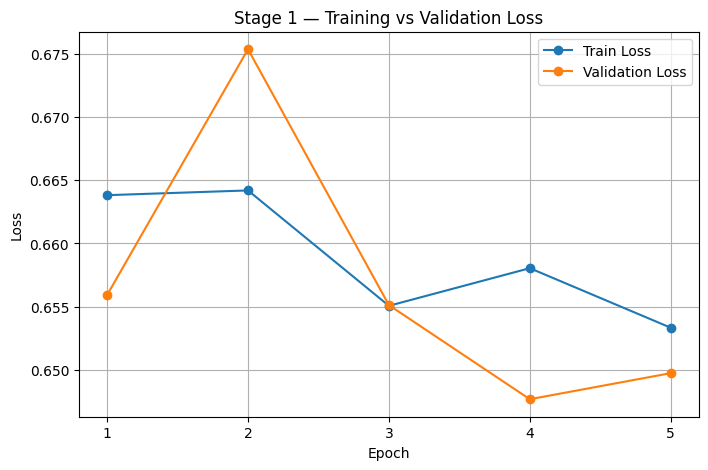

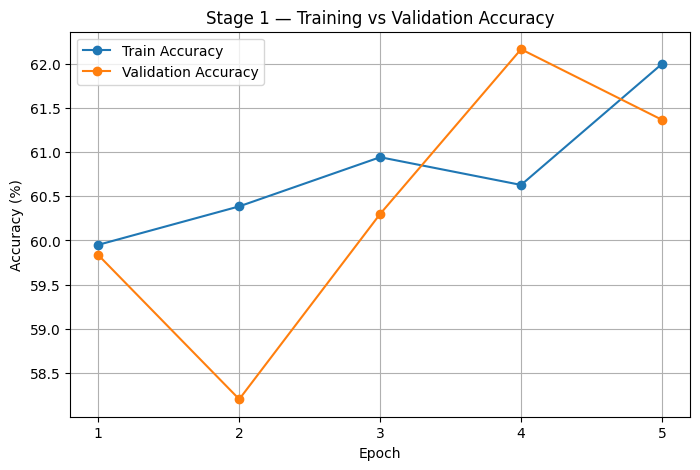

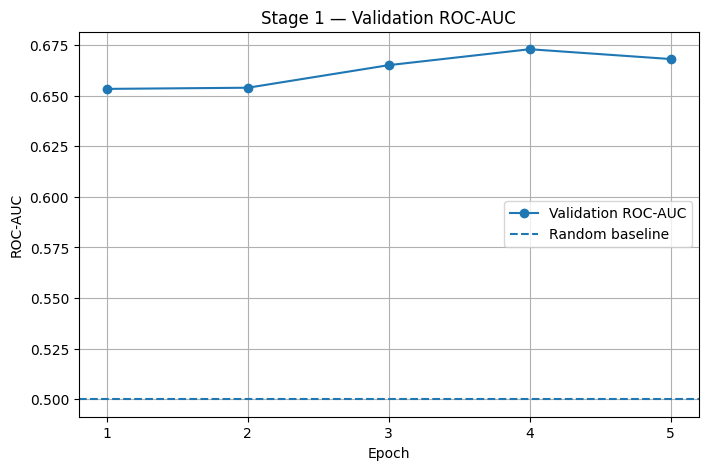

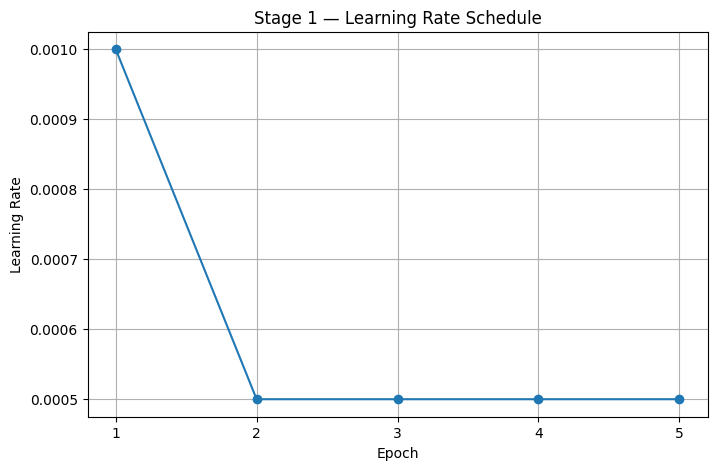


CELL 23 — STAGE 1 AUDIT COMPLETE
History saved: /kaggle/working/efficientnet_b0_stage1_history.csv
Best Val ROC-AUC: 0.6729
Best Epoch: 4

Stage 1 baseline is now recorded.


In [31]:
# ============================================================
# CELL 23 — STAGE 1 LEARNING CURVE AUDIT
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


print("=" * 70)
print("CELL 23 — STAGE 1 LEARNING CURVE AUDIT")
print("=" * 70)


# ------------------------------------------------------------
# Verify history exists
# ------------------------------------------------------------

assert "history_df" in globals()

required_columns = [
    "epoch",
    "train_loss",
    "train_accuracy",
    "val_loss",
    "val_accuracy",
    "val_precision",
    "val_recall",
    "val_f1",
    "val_roc_auc",
    "learning_rate"
]

missing_columns = [
    column
    for column in required_columns
    if column not in history_df.columns
]

assert len(missing_columns) == 0, (
    f"Missing history columns: {missing_columns}"
)


# ------------------------------------------------------------
# Display complete history
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("STAGE 1 TRAINING HISTORY")
print("-" * 70)

display(
    history_df[
        required_columns
    ].round(4)
)


# ------------------------------------------------------------
# Best epoch
# ------------------------------------------------------------

best_idx = history_df[
    "val_roc_auc"
].idxmax()

best_row = history_df.loc[
    best_idx
]

print("\n" + "-" * 70)
print("BEST VALIDATION EPOCH")
print("-" * 70)

print(
    "Epoch       :",
    int(best_row["epoch"])
)

print(
    "Val Loss    :",
    f"{best_row['val_loss']:.4f}"
)

print(
    "Val Accuracy:",
    f"{best_row['val_accuracy'] * 100:.2f}%"
)

print(
    "Val F1      :",
    f"{best_row['val_f1']:.4f}"
)

print(
    "Val ROC-AUC :",
    f"{best_row['val_roc_auc']:.4f}"
)


# ------------------------------------------------------------
# Plot 1 — Loss
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Stage 1 — Training vs Validation Loss")
plt.xticks(
    history_df["epoch"]
)
plt.legend()
plt.grid(True)
plt.show()


# ------------------------------------------------------------
# Plot 2 — Accuracy
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_accuracy"] * 100,
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"] * 100,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Stage 1 — Training vs Validation Accuracy")
plt.xticks(
    history_df["epoch"]
)
plt.legend()
plt.grid(True)
plt.show()


# ------------------------------------------------------------
# Plot 3 — ROC-AUC
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["val_roc_auc"],
    marker="o",
    label="Validation ROC-AUC"
)

plt.axhline(
    0.5,
    linestyle="--",
    label="Random baseline"
)

plt.xlabel("Epoch")
plt.ylabel("ROC-AUC")
plt.title("Stage 1 — Validation ROC-AUC")
plt.xticks(
    history_df["epoch"]
)
plt.legend()
plt.grid(True)
plt.show()


# ------------------------------------------------------------
# Plot 4 — Learning Rate
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["learning_rate"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("Stage 1 — Learning Rate Schedule")
plt.xticks(
    history_df["epoch"]
)
plt.grid(True)
plt.show()


# ------------------------------------------------------------
# Save history
# ------------------------------------------------------------

history_path = (
    "/kaggle/working/"
    "efficientnet_b0_stage1_history.csv"
)

history_df.to_csv(
    history_path,
    index=False
)


print("\n" + "=" * 70)
print("CELL 23 — STAGE 1 AUDIT COMPLETE")
print("=" * 70)

print(
    "History saved:",
    history_path
)

print(
    f"Best Val ROC-AUC: "
    f"{best_row['val_roc_auc']:.4f}"
)

print(
    f"Best Epoch: "
    f"{int(best_row['epoch'])}"
)

print(
    "\nStage 1 baseline is now recorded."
)

print(
    "======================================================================"
)

In [32]:
# ============================================================
# CELL 24 — STAGE 2 SELECTIVE UNFREEZING + BATCHNORM AUDIT
# ============================================================

import torch
import torch.nn as nn


print("=" * 70)
print("CELL 24 — STAGE 2 SELECTIVE UNFREEZING + BATCHNORM AUDIT")
print("=" * 70)


# ============================================================
# 1. STAGE 2 STRATEGY
# ============================================================

print("\n" + "-" * 70)
print("STAGE 2 STRATEGY")
print("-" * 70)

print("""
EfficientNet-B0:

Early feature blocks
    features[0] → features[5]
    FROZEN

Deep feature blocks
    features[6] → features[8]
    TRAINABLE

Classifier
    TRAINABLE

Purpose:
    Adapt deeper EfficientNet features to deepfake-specific
    facial/manipulation patterns while preserving the generic
    low-level ImageNet representation.
""")


# ============================================================
# 2. FIRST FREEZE EVERYTHING
# ============================================================

for parameter in model.parameters():
    parameter.requires_grad = False


# ============================================================
# 3. UNFREEZE DEEP FEATURE BLOCKS
# ============================================================

for block_index in [6, 7, 8]:

    for parameter in model.features[block_index].parameters():
        parameter.requires_grad = True


# ============================================================
# 4. UNFREEZE CLASSIFIER
# ============================================================

for parameter in model.classifier.parameters():
    parameter.requires_grad = True


# ============================================================
# 5. VERIFY FEATURE BLOCK STATUS
# ============================================================

print("\n" + "-" * 70)
print("FEATURE BLOCK TRAINABILITY")
print("-" * 70)

for block_index, block in enumerate(model.features):

    total_params = sum(
        parameter.numel()
        for parameter in block.parameters()
    )

    trainable_params = sum(
        parameter.numel()
        for parameter in block.parameters()
        if parameter.requires_grad
    )

    status = (
        "TRAINABLE"
        if trainable_params > 0
        else "FROZEN"
    )

    print(
        f"features[{block_index}]"
        f" | Total: {total_params:,}"
        f" | Trainable: {trainable_params:,}"
        f" | {status}"
    )


# ============================================================
# 6. VERIFY CLASSIFIER
# ============================================================

classifier_total = sum(
    parameter.numel()
    for parameter in model.classifier.parameters()
)

classifier_trainable = sum(
    parameter.numel()
    for parameter in model.classifier.parameters()
    if parameter.requires_grad
)

print("\n" + "-" * 70)
print("CLASSIFIER STATUS")
print("-" * 70)

print(
    f"Classifier total parameters     : "
    f"{classifier_total:,}"
)

print(
    f"Classifier trainable parameters : "
    f"{classifier_trainable:,}"
)

assert classifier_trainable == classifier_total

print(
    "✅ Entire classifier is trainable"
)


# ============================================================
# 7. GLOBAL PARAMETER AUDIT
# ============================================================

total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

frozen_parameters = (
    total_parameters -
    trainable_parameters
)

print("\n" + "-" * 70)
print("GLOBAL PARAMETER STATUS")
print("-" * 70)

print(
    f"Total parameters     : "
    f"{total_parameters:,}"
)

print(
    f"Trainable parameters : "
    f"{trainable_parameters:,}"
)

print(
    f"Frozen parameters    : "
    f"{frozen_parameters:,}"
)


# ============================================================
# 8. VERIFY EARLY BLOCKS ARE COMPLETELY FROZEN
# ============================================================

for block_index in range(6):

    assert all(
        not parameter.requires_grad
        for parameter in model.features[block_index].parameters()
    )

print(
    "✅ features[0]–features[5] completely frozen"
)


# ============================================================
# 9. VERIFY DEEP BLOCKS ARE TRAINABLE
# ============================================================

for block_index in [6, 7, 8]:

    assert any(
        parameter.requires_grad
        for parameter in model.features[block_index].parameters()
    )

print(
    "✅ features[6]–features[8] trainable"
)


# ============================================================
# 10. BATCH NORMALIZATION AUDIT
# ============================================================

all_batchnorm_layers = []

for module_name, module in model.named_modules():

    if isinstance(
        module,
        (
            nn.BatchNorm1d,
            nn.BatchNorm2d,
            nn.BatchNorm3d
        )
    ):

        all_batchnorm_layers.append(
            (module_name, module)
        )


print("\n" + "-" * 70)
print("BATCH NORMALIZATION AUDIT")
print("-" * 70)

print(
    "Total BatchNorm layers:",
    len(all_batchnorm_layers)
)


# ------------------------------------------------------------
# Frozen early blocks → BatchNorm evaluation mode
# ------------------------------------------------------------

early_bn_count = 0

for block_index in range(6):

    for module in model.features[block_index].modules():

        if isinstance(
            module,
            (
                nn.BatchNorm1d,
                nn.BatchNorm2d,
                nn.BatchNorm3d
            )
        ):

            module.eval()

            early_bn_count += 1


# ------------------------------------------------------------
# Trainable deep blocks → BatchNorm remains trainable
# ------------------------------------------------------------

deep_bn_count = 0

for block_index in [6, 7, 8]:

    for module in model.features[block_index].modules():

        if isinstance(
            module,
            (
                nn.BatchNorm1d,
                nn.BatchNorm2d,
                nn.BatchNorm3d
            )
        ):

            deep_bn_count += 1


print(
    "Frozen early-block BatchNorm layers :",
    early_bn_count
)

print(
    "Deep trainable-block BatchNorm layers:",
    deep_bn_count
)


# ============================================================
# 11. IMPORTANT: CLASSIFIER HAS NO BATCHNORM
# ============================================================

classifier_bn_count = sum(
    1
    for module in model.classifier.modules()
    if isinstance(
        module,
        (
            nn.BatchNorm1d,
            nn.BatchNorm2d,
            nn.BatchNorm3d
        )
    )
)

print(
    "Classifier BatchNorm layers:",
    classifier_bn_count
)


# ============================================================
# 12. MODEL MODE
# ============================================================

model.train()

# Re-apply evaluation mode to frozen early BatchNorm layers
for block_index in range(6):

    for module in model.features[block_index].modules():

        if isinstance(
            module,
            (
                nn.BatchNorm1d,
                nn.BatchNorm2d,
                nn.BatchNorm3d
            )
        ):

            module.eval()


# ============================================================
# 13. VERIFY FROZEN BATCHNORM STATE
# ============================================================

frozen_bn_training = 0

for block_index in range(6):

    for module in model.features[block_index].modules():

        if isinstance(
            module,
            (
                nn.BatchNorm1d,
                nn.BatchNorm2d,
                nn.BatchNorm3d
            )
        ):

            if module.training:
                frozen_bn_training += 1


print(
    "Frozen early BatchNorm layers in training mode:",
    frozen_bn_training
)

assert frozen_bn_training == 0

print(
    "✅ Frozen early BatchNorm layers remain in eval mode"
)


# ============================================================
# 14. FORWARD PASS
# ============================================================

print("\n" + "-" * 70)
print("POST-UNFREEZE FORWARD-PASS CHECK")
print("-" * 70)

model.eval()

with torch.no_grad():

    dummy_input = torch.randn(
        4,
        3,
        224,
        224,
        device=DEVICE
    )

    dummy_output = model(dummy_input)


print(
    "Input shape :",
    tuple(dummy_input.shape)
)

print(
    "Output shape:",
    tuple(dummy_output.shape)
)

print(
    "Output dtype:",
    dummy_output.dtype
)

assert dummy_output.shape == (4, 2)
assert torch.isfinite(dummy_output).all()

print(
    "✅ Forward pass successful"
)


# ============================================================
# 15. FINAL AUDIT SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("CELL 24 — STAGE 2 FREEZE AUDIT COMPLETE")
print("=" * 70)

print("""
Stage 2 configuration:

EfficientNet features[0]–[5] : FROZEN
EfficientNet features[6]–[8] : TRAINABLE
Classifier                   : TRAINABLE

Early BatchNorm              : FROZEN + EVAL
Deep BatchNorm               : TRAINABLE

No optimizer created.
No training performed.
No test set used.
""")

print(
    f"Total parameters      : {total_parameters:,}"
)

print(
    f"Trainable parameters  : {trainable_parameters:,}"
)

print(
    f"Frozen parameters     : {frozen_parameters:,}"
)

print(
    "\nForward pass          : PASS"
)

print(
    "Trainability audit     : PASS"
)

print(
    "BatchNorm audit        : PASS"
)

print("=" * 70)

CELL 24 — STAGE 2 SELECTIVE UNFREEZING + BATCHNORM AUDIT

----------------------------------------------------------------------
STAGE 2 STRATEGY
----------------------------------------------------------------------

EfficientNet-B0:

Early feature blocks
    features[0] → features[5]
    FROZEN

Deep feature blocks
    features[6] → features[8]
    TRAINABLE

Classifier
    TRAINABLE

Purpose:
    Adapt deeper EfficientNet features to deepfake-specific
    facial/manipulation patterns while preserving the generic
    low-level ImageNet representation.


----------------------------------------------------------------------
FEATURE BLOCK TRAINABILITY
----------------------------------------------------------------------
features[0] | Total: 928 | Trainable: 0 | FROZEN
features[1] | Total: 1,448 | Trainable: 0 | FROZEN
features[2] | Total: 16,714 | Trainable: 0 | FROZEN
features[3] | Total: 46,640 | Trainable: 0 | FROZEN
features[4] | Total: 242,930 | Trainable: 0 | FROZEN
features[5] 

In [33]:
# ============================================================
# CELL 25 — STAGE 2 TRAINING CONFIGURATION AUDIT
# ============================================================

import torch
import torch.nn as nn


print("=" * 70)
print("CELL 25 — STAGE 2 TRAINING CONFIGURATION")
print("=" * 70)


# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

print("\n" + "-" * 70)
print("REPRODUCIBILITY")
print("-" * 70)

STAGE2_SEED = 42

print("Random seed:", STAGE2_SEED)


# ============================================================
# 2. STAGE 2 HYPERPARAMETERS
# ============================================================

STAGE2_EPOCHS = 8

BACKBONE_LR = 1e-5
CLASSIFIER_LR = 1e-4

WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0

EARLY_STOPPING_PATIENCE = 3

print("\n" + "-" * 70)
print("HYPERPARAMETERS")
print("-" * 70)

print(f"Epochs                  : {STAGE2_EPOCHS}")
print(f"Deep backbone LR        : {BACKBONE_LR}")
print(f"Classifier LR           : {CLASSIFIER_LR}")
print(f"LR ratio                : {CLASSIFIER_LR / BACKBONE_LR:.0f}x")
print(f"Weight decay            : {WEIGHT_DECAY}")
print(f"Gradient clip norm      : {GRADIENT_CLIP_NORM}")
print(f"Early stopping patience : {EARLY_STOPPING_PATIENCE}")


# ============================================================
# 3. LOSS FUNCTION
# ============================================================

criterion_stage2 = nn.CrossEntropyLoss()

print("\n" + "-" * 70)
print("LOSS FUNCTION")
print("-" * 70)

print("CrossEntropyLoss()")
print("✅ Configured for 2-class logits")


# ============================================================
# 4. VERIFY TRAINABLE PARAMETERS
# ============================================================

print("\n" + "-" * 70)
print("TRAINABLE PARAMETER AUDIT")
print("-" * 70)

deep_parameters = []
classifier_parameters = []

for block_index in [6, 7, 8]:

    for parameter in model.features[block_index].parameters():

        if parameter.requires_grad:
            deep_parameters.append(parameter)


for parameter in model.classifier.parameters():

    if parameter.requires_grad:
        classifier_parameters.append(parameter)


deep_parameter_count = sum(
    parameter.numel()
    for parameter in deep_parameters
)

classifier_parameter_count = sum(
    parameter.numel()
    for parameter in classifier_parameters
)

total_trainable_parameter_count = (
    deep_parameter_count +
    classifier_parameter_count
)

print(
    f"Deep features[6–8] trainable : "
    f"{deep_parameter_count:,}"
)

print(
    f"Classifier trainable         : "
    f"{classifier_parameter_count:,}"
)

print(
    f"Total trainable              : "
    f"{total_trainable_parameter_count:,}"
)

assert deep_parameter_count == 3_155_740
assert classifier_parameter_count == 2_562
assert total_trainable_parameter_count == 3_158_302

print(
    "✅ Trainable parameter count matches Cell 24"
)


# ============================================================
# 5. DIFFERENTIAL LEARNING-RATE PARAMETER GROUPS
# ============================================================

optimizer_stage2 = torch.optim.AdamW(
    [
        {
            "params": deep_parameters,
            "lr": BACKBONE_LR,
            "weight_decay": WEIGHT_DECAY,
            "name": "deep_backbone"
        },
        {
            "params": classifier_parameters,
            "lr": CLASSIFIER_LR,
            "weight_decay": WEIGHT_DECAY,
            "name": "classifier"
        }
    ]
)


print("\n" + "-" * 70)
print("OPTIMIZER PARAMETER GROUP AUDIT")
print("-" * 70)

for index, group in enumerate(
    optimizer_stage2.param_groups
):

    parameter_count = sum(
        parameter.numel()
        for parameter in group["params"]
    )

    print(
        f"Group {index}"
    )

    print(
        f"  Name          : {group['name']}"
    )

    print(
        f"  Parameters    : {parameter_count:,}"
    )

    print(
        f"  Learning rate : {group['lr']}"
    )

    print(
        f"  Weight decay  : {group['weight_decay']}"
    )


assert len(
    optimizer_stage2.param_groups
) == 2

assert (
    optimizer_stage2.param_groups[0]["lr"]
    == BACKBONE_LR
)

assert (
    optimizer_stage2.param_groups[1]["lr"]
    == CLASSIFIER_LR
)

print(
    "✅ Differential learning-rate groups configured correctly"
)


# ============================================================
# 6. SCHEDULER
# ============================================================

scheduler_stage2 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_stage2,
    mode="min",
    factor=0.5,
    patience=1,
    min_lr=1e-7
)


print("\n" + "-" * 70)
print("LEARNING-RATE SCHEDULER")
print("-" * 70)

print(
    "ReduceLROnPlateau"
)

print(
    "Monitor        : validation loss"
)

print(
    "Mode           : minimize"
)

print(
    "Reduction      : 0.5"
)

print(
    "Patience       : 1 epoch"
)

print(
    "Minimum LR     : 1e-7"
)

print(
    "Initial backbone LR   :",
    BACKBONE_LR
)

print(
    "Initial classifier LR :",
    CLASSIFIER_LR
)


# ============================================================
# 7. MIXED PRECISION
# ============================================================

AMP_ENABLED_STAGE2 = (
    DEVICE.type == "cuda"
)

print("\n" + "-" * 70)
print("MIXED PRECISION")
print("-" * 70)

print(
    "AMP enabled:",
    AMP_ENABLED_STAGE2
)

if AMP_ENABLED_STAGE2:
    print(
        "CUDA mixed precision will be used"
    )

else:
    print(
        "CUDA unavailable — FP32 training"
    )


# ============================================================
# 8. DATA LOADER RELIABILITY CONFIGURATION
# ============================================================

STAGE2_NUM_WORKERS = 0

print("\n" + "-" * 70)
print("DATALOADER CONFIGURATION")
print("-" * 70)

print(
    "Batch size :",
    BATCH_SIZE
)

print(
    "Workers    :",
    STAGE2_NUM_WORKERS
)

print(
    "Reason     :",
    "maximum notebook reliability after previous worker hang"
)


# ------------------------------------------------------------
# Build Stage-2 DataLoaders
# ------------------------------------------------------------

train_loader_stage2 = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=STAGE2_NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=False
)

val_loader_stage2 = torch.utils.data.DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=STAGE2_NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=False
)

test_loader_stage2 = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=STAGE2_NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=False
)


print(
    "\nTrain batches:",
    len(train_loader_stage2)
)

print(
    "Val batches  :",
    len(val_loader_stage2)
)

print(
    "Test batches :",
    len(test_loader_stage2)
)


assert len(train_loader_stage2) == 438
assert len(val_loader_stage2) == 94
assert len(test_loader_stage2) == 94

print(
    "✅ DataLoader sizes verified"
)


# ============================================================
# 9. DATALOADER ONE-BATCH TEST
# ============================================================

print("\n" + "-" * 70)
print("DATALOADER ONE-BATCH TEST")
print("-" * 70)

batch_images, batch_labels = next(
    iter(train_loader_stage2)
)

print(
    "Image batch shape:",
    tuple(batch_images.shape)
)

print(
    "Label batch shape:",
    tuple(batch_labels.shape)
)

print(
    "Image dtype:",
    batch_images.dtype
)

print(
    "Label dtype:",
    batch_labels.dtype
)

assert batch_images.shape == (
    BATCH_SIZE,
    3,
    224,
    224
)

assert batch_labels.shape == (
    BATCH_SIZE,
)

assert batch_images.dtype == torch.float32
assert batch_labels.dtype == torch.int64

print(
    "✅ Stage-2 DataLoader batch is valid"
)


# ============================================================
# 10. INITIAL LEARNING RATES
# ============================================================

print("\n" + "-" * 70)
print("INITIAL LEARNING RATES")
print("-" * 70)

for index, group in enumerate(
    optimizer_stage2.param_groups
):

    print(
        f"Group {index} ({group['name']}): "
        f"{group['lr']}"
    )


# ============================================================
# 11. TEST-SET ISOLATION
# ============================================================

print("\n" + "-" * 70)
print("TEST SET ISOLATION")
print("-" * 70)

print(
    "Test loader created : YES"
)

print(
    "Test data used for training : NO"
)

print(
    "Test data used for scheduler : NO"
)

print(
    "Test data used for early stopping : NO"
)

print(
    "Test data used for model selection : NO"
)

print(
    "✅ Test set remains isolated"
)


# ============================================================
# 12. CHECKPOINT PATH
# ============================================================

STAGE2_CHECKPOINT = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_best.pth"
)

print("\n" + "-" * 70)
print("CHECKPOINT")
print("-" * 70)

print(
    "Stage-2 checkpoint:",
    STAGE2_CHECKPOINT
)


# ============================================================
# 13. FINAL CONFIGURATION SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("CELL 25 — STAGE 2 TRAINING CONFIGURATION AUDIT COMPLETE")
print("=" * 70)

print("""
Stage 2:

Early features[0–5] : FROZEN
Deep features[6–8] : TRAINABLE
Classifier          : TRAINABLE

Deep backbone LR    : 1e-5
Classifier LR       : 1e-4

Optimizer           : AdamW
Weight decay        : 1e-4

Scheduler           : ReduceLROnPlateau
Scheduler monitor   : validation loss

Gradient clipping   : 1.0
AMP                 : CUDA enabled when available

DataLoader workers  : 0

Test set            : ISOLATED
Training performed  : NO
""")

print(
    "Trainable parameters:",
    f"{total_trainable_parameter_count:,}"
)

print(
    "Train batches:",
    len(train_loader_stage2)
)

print(
    "Validation batches:",
    len(val_loader_stage2)
)

print(
    "Test batches:",
    len(test_loader_stage2)
)

print(
    "\nConfiguration : PASS"
)

print(
    "DataLoader     : PASS"
)

print(
    "Parameter groups: PASS"
)

print(
    "Test isolation : PASS"
)

print("=" * 70)

CELL 25 — STAGE 2 TRAINING CONFIGURATION

----------------------------------------------------------------------
REPRODUCIBILITY
----------------------------------------------------------------------
Random seed: 42

----------------------------------------------------------------------
HYPERPARAMETERS
----------------------------------------------------------------------
Epochs                  : 8
Deep backbone LR        : 1e-05
Classifier LR           : 0.0001
LR ratio                : 10x
Weight decay            : 0.0001
Gradient clip norm      : 1.0
Early stopping patience : 3

----------------------------------------------------------------------
LOSS FUNCTION
----------------------------------------------------------------------
CrossEntropyLoss()
✅ Configured for 2-class logits

----------------------------------------------------------------------
TRAINABLE PARAMETER AUDIT
----------------------------------------------------------------------
Deep features[6–8] trainable : 3,1

In [34]:
# ============================================================
# CELL 26 — STAGE 2 INITIALIZATION + PRE-TRAINING AUDIT
# ============================================================

import os
import random
import numpy as np
import torch
import torch.nn as nn


print("=" * 70)
print("CELL 26 — STAGE 2 INITIALIZATION + PRE-TRAINING AUDIT")
print("=" * 70)


# ============================================================
# 1. RESET REPRODUCIBILITY STATE
# ============================================================

STAGE2_SEED = 42

random.seed(STAGE2_SEED)
np.random.seed(STAGE2_SEED)
torch.manual_seed(STAGE2_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(STAGE2_SEED)

print("\n" + "-" * 70)
print("REPRODUCIBILITY")
print("-" * 70)

print("Stage-2 seed:", STAGE2_SEED)


# ============================================================
# 2. LOAD BEST STAGE-1 CHECKPOINT
# ============================================================

STAGE1_CHECKPOINT = (
    "/kaggle/working/"
    "efficientnet_b0_stage1_best.pth"
)

print("\n" + "-" * 70)
print("LOADING BEST STAGE-1 CHECKPOINT")
print("-" * 70)

assert os.path.exists(
    STAGE1_CHECKPOINT
), "Best Stage-1 checkpoint not found."

stage1_checkpoint = torch.load(
    STAGE1_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False
)

stage1_epoch = stage1_checkpoint["epoch"]
stage1_val_auc = stage1_checkpoint["val_roc_auc"]
stage1_val_loss = stage1_checkpoint["val_loss"]

print("Checkpoint:", STAGE1_CHECKPOINT)
print("Saved epoch:", stage1_epoch)
print("Val ROC-AUC:", f"{stage1_val_auc:.6f}")
print("Val loss   :", f"{stage1_val_loss:.6f}")

assert stage1_epoch == 4
assert abs(stage1_val_auc - 0.6729128888888889) < 1e-6

print(
    "✅ Confirmed: Stage 2 starts from best Stage-1 Epoch 4"
)


# ============================================================
# 3. RESTORE BEST STAGE-1 WEIGHTS
# ============================================================

model.load_state_dict(
    stage1_checkpoint["model_state_dict"]
)

model.to(DEVICE)

print(
    "\n✅ Best Stage-1 model weights restored"
)


# ============================================================
# 4. FREEZE EVERYTHING FIRST
# ============================================================

for parameter in model.parameters():
    parameter.requires_grad = False


# ============================================================
# 5. UNFREEZE FEATURES 6–8
# ============================================================

for block_index in [6, 7, 8]:

    for parameter in model.features[block_index].parameters():
        parameter.requires_grad = True


# ============================================================
# 6. UNFREEZE CLASSIFIER
# ============================================================

for parameter in model.classifier.parameters():
    parameter.requires_grad = True


# ============================================================
# 7. BATCHNORM CONTROL FUNCTION
# ============================================================

def set_stage2_batchnorm_modes(model):

    # First put entire model in training mode.
    model.train()

    # Then explicitly freeze/eval BatchNorm
    # in features[0]–features[5].
    for block_index in range(6):

        for module in model.features[block_index].modules():

            if isinstance(
                module,
                (
                    nn.BatchNorm1d,
                    nn.BatchNorm2d,
                    nn.BatchNorm3d
                )
            ):

                module.eval()

                # Make sure BN affine parameters
                # cannot accidentally train.
                if module.weight is not None:
                    module.weight.requires_grad = False

                if module.bias is not None:
                    module.bias.requires_grad = False


set_stage2_batchnorm_modes(model)


# ============================================================
# 8. VERIFY PARAMETER COUNTS
# ============================================================

deep_parameters = []

classifier_parameters = []

for block_index in [6, 7, 8]:

    for parameter in model.features[block_index].parameters():

        if parameter.requires_grad:
            deep_parameters.append(parameter)


for parameter in model.classifier.parameters():

    if parameter.requires_grad:
        classifier_parameters.append(parameter)


deep_parameter_count = sum(
    parameter.numel()
    for parameter in deep_parameters
)

classifier_parameter_count = sum(
    parameter.numel()
    for parameter in classifier_parameters
)

total_trainable = (
    deep_parameter_count +
    classifier_parameter_count
)

print("\n" + "-" * 70)
print("TRAINABLE PARAMETER AUDIT")
print("-" * 70)

print(
    "Deep features[6–8] :",
    f"{deep_parameter_count:,}"
)

print(
    "Classifier         :",
    f"{classifier_parameter_count:,}"
)

print(
    "Total trainable    :",
    f"{total_trainable:,}"
)

assert deep_parameter_count == 3_155_740
assert classifier_parameter_count == 2_562
assert total_trainable == 3_158_302

print(
    "✅ Parameter configuration confirmed"
)


# ============================================================
# 9. BATCHNORM MODE AUDIT
# ============================================================

early_bn = []
deep_bn = []

for block_index in range(6):

    for module in model.features[block_index].modules():

        if isinstance(
            module,
            (
                nn.BatchNorm1d,
                nn.BatchNorm2d,
                nn.BatchNorm3d
            )
        ):

            early_bn.append(module)


for block_index in [6, 7, 8]:

    for module in model.features[block_index].modules():

        if isinstance(
            module,
            (
                nn.BatchNorm1d,
                nn.BatchNorm2d,
                nn.BatchNorm3d
            )
        ):

            deep_bn.append(module)


early_bn_training = sum(
    module.training
    for module in early_bn
)

deep_bn_training = sum(
    module.training
    for module in deep_bn
)

print("\n" + "-" * 70)
print("BATCHNORM MODE AUDIT")
print("-" * 70)

print(
    "Early frozen BN layers :",
    len(early_bn)
)

print(
    "Early BN in train mode :",
    early_bn_training
)

print(
    "Deep trainable BN      :",
    len(deep_bn)
)

print(
    "Deep BN in train mode  :",
    deep_bn_training
)

assert early_bn_training == 0
assert deep_bn_training == len(deep_bn)

print(
    "✅ Early BN frozen + eval"
)

print(
    "✅ Deep BN trainable + train mode"
)


# ============================================================
# 10. CREATE DIFFERENTIAL-LR OPTIMIZER
# ============================================================

BACKBONE_LR = 1e-5
CLASSIFIER_LR = 1e-4
WEIGHT_DECAY = 1e-4

optimizer_stage2 = torch.optim.AdamW(
    [
        {
            "params": deep_parameters,
            "lr": BACKBONE_LR,
            "weight_decay": WEIGHT_DECAY,
            "name": "deep_backbone"
        },
        {
            "params": classifier_parameters,
            "lr": CLASSIFIER_LR,
            "weight_decay": WEIGHT_DECAY,
            "name": "classifier"
        }
    ]
)


print("\n" + "-" * 70)
print("OPTIMIZER")
print("-" * 70)

for index, group in enumerate(
    optimizer_stage2.param_groups
):

    print(
        f"Group {index}: "
        f"{group['name']} | "
        f"LR={group['lr']} | "
        f"Parameters={sum(p.numel() for p in group['params']):,}"
    )


# ============================================================
# 11. CREATE SCHEDULER
# ============================================================

scheduler_stage2 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_stage2,
    mode="min",
    factor=0.5,
    patience=1,
    min_lr=1e-7
)

print(
    "\nScheduler: ReduceLROnPlateau"
)

print(
    "Monitor: validation loss"
)


# ============================================================
# 12. FORWARD-PASS TEST
# ============================================================

print("\n" + "-" * 70)
print("FORWARD-PASS TEST")
print("-" * 70)

model.eval()

with torch.no_grad():

    dummy_input = torch.randn(
        4,
        3,
        224,
        224,
        device=DEVICE
    )

    dummy_output = model(
        dummy_input
    )

print(
    "Input shape :",
    tuple(dummy_input.shape)
)

print(
    "Output shape:",
    tuple(dummy_output.shape)
)

assert dummy_output.shape == (4, 2)
assert torch.isfinite(dummy_output).all()

print(
    "✅ Forward pass successful"
)


# ============================================================
# 13. BACKWARD-PASS TEST
# ============================================================

print("\n" + "-" * 70)
print("BACKWARD-PASS TEST")
print("-" * 70)

set_stage2_batchnorm_modes(model)

optimizer_stage2.zero_grad(
    set_to_none=True
)

dummy_input = torch.randn(
    4,
    3,
    224,
    224,
    device=DEVICE
)

dummy_labels = torch.tensor(
    [0, 1, 0, 1],
    dtype=torch.long,
    device=DEVICE
)

dummy_output = model(
    dummy_input
)

dummy_loss = nn.CrossEntropyLoss()(
    dummy_output,
    dummy_labels
)

dummy_loss.backward()


# ------------------------------------------------------------
# Verify gradients
# ------------------------------------------------------------

deep_grad_params = 0
classifier_grad_params = 0

for parameter in deep_parameters:

    if parameter.grad is not None:

        deep_grad_params += 1


for parameter in classifier_parameters:

    if parameter.grad is not None:

        classifier_grad_params += 1


print(
    "Deep parameters with gradients      :",
    deep_grad_params,
    "/",
    len(deep_parameters)
)

print(
    "Classifier parameters with gradients:",
    classifier_grad_params,
    "/",
    len(classifier_parameters)
)

assert deep_grad_params > 0
assert classifier_grad_params > 0

print(
    "✅ Deep backbone receives gradients"
)

print(
    "✅ Classifier receives gradients"
)


# ------------------------------------------------------------
# Clear dummy gradients
# ------------------------------------------------------------

optimizer_stage2.zero_grad(
    set_to_none=True
)


# ============================================================
# 14. FINAL MODEL MODE RESET
# ============================================================

set_stage2_batchnorm_modes(model)


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("CELL 26 — STAGE 2 INITIALIZATION AUDIT COMPLETE")
print("=" * 70)

print("""
Starting point:
    Best Stage-1 checkpoint
    Epoch 4
    Val ROC-AUC = 0.6729

Stage 2:
    features[0–5] → FROZEN
    features[6–8] → TRAINABLE
    classifier     → TRAINABLE

Learning rates:
    Deep backbone → 1e-5
    Classifier    → 1e-4

BatchNorm:
    Early BN → FROZEN + EVAL
    Deep BN  → TRAINABLE + TRAIN

Test set:
    NOT USED

Dataset training:
    NOT PERFORMED
""")

print(
    f"Trainable parameters: {total_trainable:,}"
)

print(
    "\nStarting checkpoint : PASS"
)

print(
    "Parameter audit      : PASS"
)

print(
    "BatchNorm audit      : PASS"
)

print(
    "Forward test         : PASS"
)

print(
    "Backward test        : PASS"
)

print("=" * 70)

CELL 26 — STAGE 2 INITIALIZATION + PRE-TRAINING AUDIT

----------------------------------------------------------------------
REPRODUCIBILITY
----------------------------------------------------------------------
Stage-2 seed: 42

----------------------------------------------------------------------
LOADING BEST STAGE-1 CHECKPOINT
----------------------------------------------------------------------
Checkpoint: /kaggle/working/efficientnet_b0_stage1_best.pth
Saved epoch: 4
Val ROC-AUC: 0.672913
Val loss   : 0.647677
✅ Confirmed: Stage 2 starts from best Stage-1 Epoch 4

✅ Best Stage-1 model weights restored

----------------------------------------------------------------------
TRAINABLE PARAMETER AUDIT
----------------------------------------------------------------------
Deep features[6–8] : 3,155,740
Classifier         : 2,562
Total trainable    : 3,158,302
✅ Parameter configuration confirmed

----------------------------------------------------------------------
BATCHNORM MODE AU

In [35]:
# ============================================================
# CELL 27 — STAGE 2 TRAINING
# ============================================================

import time
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn


print("=" * 70)
print("CELL 27 — STAGE 2 TRAINING")
print("=" * 70)


# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

STAGE2_SEED = 42

random.seed(STAGE2_SEED)
np.random.seed(STAGE2_SEED)
torch.manual_seed(STAGE2_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(STAGE2_SEED)


# ============================================================
# 2. TRAINING SETTINGS
# ============================================================

STAGE2_EPOCHS = 8
EARLY_STOPPING_PATIENCE = 3
GRADIENT_CLIP_NORM = 1.0

BEST_CHECKPOINT = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_best.pth"
)

HISTORY_PATH = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_history.csv"
)


# ============================================================
# 3. LOSS
# ============================================================

criterion_stage2 = nn.CrossEntropyLoss()


# ============================================================
# 4. AMP SETUP
# ============================================================

AMP_ENABLED = (
    DEVICE.type == "cuda"
)

if AMP_ENABLED:

    scaler = torch.amp.GradScaler(
        "cuda"
    )

else:

    scaler = None


# ============================================================
# 5. BATCHNORM CONTROL
# ============================================================

def enforce_stage2_batchnorm_modes(model):

    # Put model in training mode first.
    model.train()

    # Keep BatchNorm in frozen early blocks
    # permanently in evaluation mode.
    for block_index in range(6):

        for module in model.features[block_index].modules():

            if isinstance(
                module,
                (
                    nn.BatchNorm1d,
                    nn.BatchNorm2d,
                    nn.BatchNorm3d
                )
            ):

                module.eval()


# ============================================================
# 6. VERIFY STARTING MODEL
# ============================================================

print("\n" + "-" * 70)
print("STARTING MODEL")
print("-" * 70)

print(
    "Starting checkpoint:",
    STAGE1_CHECKPOINT
)

print(
    "Starting epoch:",
    stage1_epoch
)

print(
    "Starting Val ROC-AUC:",
    f"{stage1_val_auc:.6f}"
)

assert stage1_epoch == 4
assert abs(stage1_val_auc - 0.6729128888888889) < 1e-6

print(
    "✅ Stage 2 starts from best Stage-1 model"
)


# ============================================================
# 7. TRAINING HISTORY
# ============================================================

history = []

best_val_auc = -float("inf")
best_val_loss = float("inf")

best_epoch = None
epochs_without_improvement = 0


# ============================================================
# 8. TRAINING LOOP
# ============================================================

print("\n" + "=" * 70)
print("BEGIN STAGE 2 TRAINING")
print("=" * 70)


for epoch in range(1, STAGE2_EPOCHS + 1):

    epoch_start = time.time()


    # ========================================================
    # TRAINING
    # ========================================================

    enforce_stage2_batchnorm_modes(model)

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader_stage2:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        optimizer_stage2.zero_grad(
            set_to_none=True
        )


        # ----------------------------------------------------
        # Forward + loss
        # ----------------------------------------------------

        if AMP_ENABLED:

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                outputs = model(images)

                loss = criterion_stage2(
                    outputs,
                    labels
                )


            scaler.scale(loss).backward()


            # ------------------------------------------------
            # Unscale before gradient clipping
            # ------------------------------------------------

            scaler.unscale_(
                optimizer_stage2
            )

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                GRADIENT_CLIP_NORM
            )


            scaler.step(
                optimizer_stage2
            )

            scaler.update()

        else:

            outputs = model(images)

            loss = criterion_stage2(
                outputs,
                labels
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                GRADIENT_CLIP_NORM
            )

            optimizer_stage2.step()


        # ----------------------------------------------------
        # Statistics
        # ----------------------------------------------------

        batch_size = labels.size(0)

        running_loss += (
            loss.item() * batch_size
        )

        predictions = outputs.argmax(
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += batch_size


    train_loss = (
        running_loss / total
    )

    train_accuracy = (
        correct / total
    )


    # ========================================================
    # VALIDATION
    # ========================================================

    model.eval()

    val_running_loss = 0.0

    val_correct = 0
    val_total = 0

    all_val_labels = []
    all_val_probabilities = []
    all_val_predictions = []


    with torch.no_grad():

        for images, labels in val_loader_stage2:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )


            if AMP_ENABLED:

                with torch.autocast(
                    device_type="cuda",
                    dtype=torch.float16
                ):

                    outputs = model(images)

                    loss = criterion_stage2(
                        outputs,
                        labels
                    )

            else:

                outputs = model(images)

                loss = criterion_stage2(
                    outputs,
                    labels
                )


            batch_size = labels.size(0)

            val_running_loss += (
                loss.item() * batch_size
            )

            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            predictions = outputs.argmax(
                dim=1
            )


            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += batch_size


            all_val_labels.extend(
                labels.cpu().numpy()
            )

            all_val_probabilities.extend(
                probabilities[:, 1]
                .float()
                .cpu()
                .numpy()
            )

            all_val_predictions.extend(
                predictions.cpu().numpy()
            )


    val_loss = (
        val_running_loss / val_total
    )

    val_accuracy = (
        val_correct / val_total
    )


    # ========================================================
    # VALIDATION METRICS
    # ========================================================

    from sklearn.metrics import (
        accuracy_score,
        precision_score,
        recall_score,
        f1_score,
        roc_auc_score
    )


    val_precision = precision_score(
        all_val_labels,
        all_val_predictions,
        zero_division=0
    )

    val_recall = recall_score(
        all_val_labels,
        all_val_predictions,
        zero_division=0
    )

    val_f1 = f1_score(
        all_val_labels,
        all_val_predictions,
        zero_division=0
    )

    val_roc_auc = roc_auc_score(
        all_val_labels,
        all_val_probabilities
    )


    # ========================================================
    # CURRENT LEARNING RATES
    # ========================================================

    current_backbone_lr = (
        optimizer_stage2.param_groups[0]["lr"]
    )

    current_classifier_lr = (
        optimizer_stage2.param_groups[1]["lr"]
    )


    # ========================================================
    # SCHEDULER
    # ========================================================

    scheduler_stage2.step(
        val_loss
    )


    # ========================================================
    # EPOCH TIME
    # ========================================================

    epoch_time = (
        time.time() - epoch_start
    )


    # ========================================================
    # SAVE HISTORY
    # ========================================================

    history.append(
        {
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "val_precision": val_precision,
            "val_recall": val_recall,
            "val_f1": val_f1,
            "val_roc_auc": val_roc_auc,
            "backbone_lr": current_backbone_lr,
            "classifier_lr": current_classifier_lr,
            "epoch_time_sec": epoch_time
        }
    )


    # ========================================================
    # PRINT RESULTS
    # ========================================================

    print(
        f"\nEpoch [{epoch}/{STAGE2_EPOCHS}]"
    )

    print(
        f"Train Loss      : {train_loss:.4f}"
    )

    print(
        f"Train Accuracy  : {train_accuracy * 100:.2f}%"
    )

    print(
        f"Val Loss        : {val_loss:.4f}"
    )

    print(
        f"Val Accuracy    : {val_accuracy * 100:.2f}%"
    )

    print(
        f"Val Precision   : {val_precision:.4f}"
    )

    print(
        f"Val Recall      : {val_recall:.4f}"
    )

    print(
        f"Val F1          : {val_f1:.4f}"
    )

    print(
        f"Val ROC-AUC     : {val_roc_auc:.4f}"
    )

    print(
        f"Backbone LR     : {current_backbone_lr:.7f}"
    )

    print(
        f"Classifier LR   : {current_classifier_lr:.7f}"
    )

    print(
        f"Epoch Time      : {epoch_time:.1f}s"
    )


    # ========================================================
    # BEST MODEL SELECTION
    # ========================================================

    if val_roc_auc > best_val_auc:

        best_val_auc = val_roc_auc
        best_val_loss = val_loss
        best_epoch = epoch

        epochs_without_improvement = 0


        checkpoint = {

            "epoch": epoch,

            "model_state_dict":
                copy.deepcopy(
                    model.state_dict()
                ),

            "optimizer_state_dict":
                optimizer_stage2.state_dict(),

            "scheduler_state_dict":
                scheduler_stage2.state_dict(),

            "val_loss": val_loss,

            "val_accuracy":
                val_accuracy,

            "val_precision":
                val_precision,

            "val_recall":
                val_recall,

            "val_f1":
                val_f1,

            "val_roc_auc":
                val_roc_auc,

            "seed":
                STAGE2_SEED,

            "stage":
                2,

            "starting_stage1_epoch":
                stage1_epoch,

            "starting_stage1_val_auc":
                stage1_val_auc,

            "backbone_lr":
                BACKBONE_LR,

            "classifier_lr":
                CLASSIFIER_LR,

            "weight_decay":
                WEIGHT_DECAY,

            "batch_size":
                BATCH_SIZE,

            "num_workers":
                STAGE2_NUM_WORKERS
        }


        torch.save(
            checkpoint,
            BEST_CHECKPOINT
        )


        print(
            "\n★ New best Stage-2 model saved!"
        )

        print(
            f"Best Val ROC-AUC: "
            f"{best_val_auc:.4f}"
        )


    else:

        epochs_without_improvement += 1


    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if (
        epochs_without_improvement
        >= EARLY_STOPPING_PATIENCE
    ):

        print(
            "\nEarly stopping triggered."
        )

        print(
            f"No validation ROC-AUC improvement "
            f"for {EARLY_STOPPING_PATIENCE} epochs."
        )

        break


# ============================================================
# 9. SAVE TRAINING HISTORY
# ============================================================

history_df_stage2 = pd.DataFrame(
    history
)

history_df_stage2.to_csv(
    HISTORY_PATH,
    index=False
)


# ============================================================
# 10. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("BEST STAGE-2 MODEL")
print("=" * 70)

print(
    f"Best epoch: {best_epoch}"
)

print(
    f"Best validation ROC-AUC: "
    f"{best_val_auc:.4f}"
)

print(
    f"Best validation loss: "
    f"{best_val_loss:.4f}"
)

print(
    f"Checkpoint: {BEST_CHECKPOINT}"
)

print(
    f"History: {HISTORY_PATH}"
)


print("\n" + "-" * 70)
print("STAGE 2 TRAINING HISTORY")
print("-" * 70)

display(
    history_df_stage2.round(4)
)


print("\n" + "=" * 70)
print("CELL 27 — STAGE 2 TRAINING COMPLETE")
print("=" * 70)

print(
    "Best epoch       :",
    best_epoch
)

print(
    "Best Val ROC-AUC :",
    f"{best_val_auc:.4f}"
)

print(
    "Checkpoint saved :",
    os.path.exists(BEST_CHECKPOINT)
)

print(
    "Test set used    : NO"
)

print("=" * 70)

CELL 27 — STAGE 2 TRAINING

----------------------------------------------------------------------
STARTING MODEL
----------------------------------------------------------------------
Starting checkpoint: /kaggle/working/efficientnet_b0_stage1_best.pth
Starting epoch: 4
Starting Val ROC-AUC: 0.672913
✅ Stage 2 starts from best Stage-1 model

BEGIN STAGE 2 TRAINING

Epoch [1/8]
Train Loss      : 0.7032
Train Accuracy  : 58.51%
Val Loss        : 0.6529
Val Accuracy    : 62.37%
Val Precision   : 0.6377
Val Recall      : 0.5727
Val F1          : 0.6034
Val ROC-AUC     : 0.6761
Backbone LR     : 0.0000100
Classifier LR   : 0.0001000
Epoch Time      : 224.5s

★ New best Stage-2 model saved!
Best Val ROC-AUC: 0.6761

Epoch [2/8]
Train Loss      : 0.6390
Train Accuracy  : 64.11%
Val Loss        : 0.6115
Val Accuracy    : 66.00%
Val Precision   : 0.6773
Val Recall      : 0.6113
Val F1          : 0.6426
Val ROC-AUC     : 0.7315
Backbone LR     : 0.0000100
Classifier LR   : 0.0001000
Epoch Time 

,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc,backbone_lr,classifier_lr,epoch_time_sec
0,1,0.7032,0.5851,0.6529,0.6237,0.6377,0.5727,0.6034,0.6761,0.0,0.0001,224.4538
1,2,0.6390,0.6411,0.6115,0.6600,0.6773,0.6113,0.6426,0.7315,0.0,0.0001,208.8551
2,3,0.5865,0.6869,0.5913,0.6860,0.7376,0.5773,0.6477,0.7690,0.0,0.0001,203.9781
3,4,0.5610,0.7066,0.5697,0.7063,0.7634,0.5980,0.6707,0.7947,0.0,0.0001,210.7281
4,5,0.5301,0.7303,0.5470,0.7200,0.7566,0.6487,0.6985,0.8094,0.0,0.0001,197.5201
5,6,0.5051,0.7507,0.5273,0.7347,0.7554,0.6940,0.7234,0.8221,0.0,0.0001,193.2855
6,7,0.4772,0.7665,0.5433,0.7337,0.7802,0.6507,0.7096,0.8254,0.0,0.0001,209.9109
7,8,0.4514,0.7824,0.5394,0.7437,0.7867,0.6687,0.7229,0.8323,0.0,0.0001,216.6986



CELL 27 — STAGE 2 TRAINING COMPLETE
Best epoch       : 8
Best Val ROC-AUC : 0.8323
Checkpoint saved : True
Test set used    : NO


CELL 28 — STAGE 2 LEARNING-CURVE AUDIT

----------------------------------------------------------------------
STAGE 2 TRAINING HISTORY
----------------------------------------------------------------------


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc,backbone_lr,classifier_lr,epoch_time_sec
0,1,0.7032,0.5851,0.6529,0.6237,0.6377,0.5727,0.6034,0.6761,0.0,0.0001,224.4538
1,2,0.6390,0.6411,0.6115,0.6600,0.6773,0.6113,0.6426,0.7315,0.0,0.0001,208.8551
2,3,0.5865,0.6869,0.5913,0.6860,0.7376,0.5773,0.6477,0.7690,0.0,0.0001,203.9781
3,4,0.5610,0.7066,0.5697,0.7063,0.7634,0.5980,0.6707,0.7947,0.0,0.0001,210.7281
4,5,0.5301,0.7303,0.5470,0.7200,0.7566,0.6487,0.6985,0.8094,0.0,0.0001,197.5201
5,6,0.5051,0.7507,0.5273,0.7347,0.7554,0.6940,0.7234,0.8221,0.0,0.0001,193.2855
6,7,0.4772,0.7665,0.5433,0.7337,0.7802,0.6507,0.7096,0.8254,0.0,0.0001,209.9109
7,8,0.4514,0.7824,0.5394,0.7437,0.7867,0.6687,0.7229,0.8323,0.0,0.0001,216.6986



✅ History structure is valid

----------------------------------------------------------------------
BEST VALIDATION EPOCH
----------------------------------------------------------------------
Epoch       : 8
Val Loss    : 0.5394
Val Accuracy: 74.37%
Val F1      : 0.7229
Val ROC-AUC : 0.8323

----------------------------------------------------------------------
STAGE 1 → STAGE 2 IMPROVEMENT
----------------------------------------------------------------------
ROC-AUC : 0.6729 → 0.8323 (+0.1594)
Relative AUC improvement: +23.68%
Accuracy: 62.17% → 74.37% (+12.20 pp)
F1      : 0.6338 → 0.7229 (+0.0891)
Loss    : 0.6477 → 0.5394 (-0.1083)

----------------------------------------------------------------------
GENERALIZATION GAP
----------------------------------------------------------------------
Final train accuracy: 78.24%
Final val accuracy  : 74.37%
Accuracy gap        : 3.88 percentage points
Final train loss    : 0.4514
Final val loss      : 0.5394
Validation - train loss gap: 

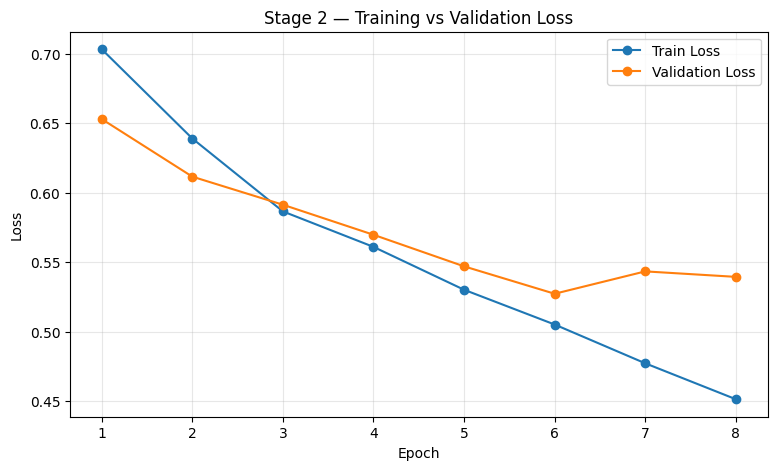

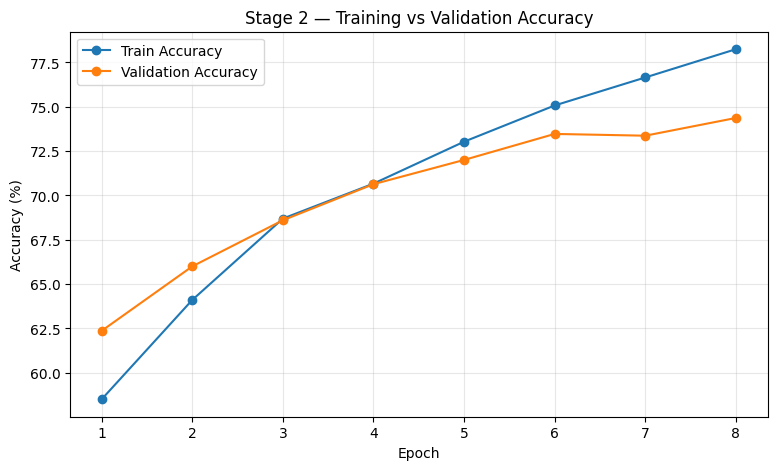

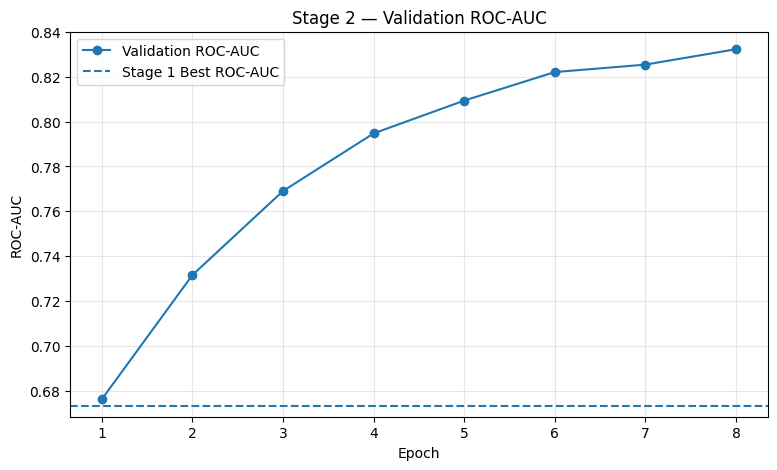


LEARNING-CURVE INTERPRETATION

Stage 2 is being evaluated for:

1. Continued validation improvement
   → Does validation ROC-AUC continue increasing?

2. Overfitting
   → Is training performance improving while
     validation performance deteriorates?

3. Generalization gap
   → How far apart are training and validation
     performance?

4. Stability
   → Are validation metrics behaving reasonably
     rather than oscillating severely?

5. Comparison with Stage 1
   → Did deeper feature adaptation provide a
     meaningful improvement?


Stage 1 best ROC-AUC : 0.6729
Stage 2 best ROC-AUC : 0.8323
Absolute improvement: +0.1594
Relative improvement: +23.68%

Audit saved: /kaggle/working/efficientnet_b0_stage2_learning_curve_audit.csv

CELL 28 — STAGE 2 LEARNING-CURVE AUDIT COMPLETE
Best epoch       : 8
Best Val ROC-AUC : 0.8323
Stage 1 baseline : 0.6729
AUC improvement  : +0.1594
Test set used    : NO


In [36]:
# ============================================================
# CELL 28 — STAGE 2 LEARNING-CURVE AUDIT
# ============================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("CELL 28 — STAGE 2 LEARNING-CURVE AUDIT")
print("=" * 70)


# ============================================================
# 1. LOAD SAVED HISTORY
# ============================================================

HISTORY_PATH = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_history.csv"
)

assert os.path.exists(
    HISTORY_PATH
), "Stage-2 history file not found."

stage2_history = pd.read_csv(
    HISTORY_PATH
)

print("\n" + "-" * 70)
print("STAGE 2 TRAINING HISTORY")
print("-" * 70)

display(
    stage2_history.round(4)
)


# ============================================================
# 2. BASIC HISTORY INTEGRITY
# ============================================================

required_columns = [
    "epoch",
    "train_loss",
    "train_accuracy",
    "val_loss",
    "val_accuracy",
    "val_precision",
    "val_recall",
    "val_f1",
    "val_roc_auc",
    "backbone_lr",
    "classifier_lr",
    "epoch_time_sec"
]

missing_columns = [
    column
    for column in required_columns
    if column not in stage2_history.columns
]

assert len(missing_columns) == 0, (
    f"Missing history columns: {missing_columns}"
)

assert len(stage2_history) > 0

assert stage2_history["epoch"].is_unique

assert np.isfinite(
    stage2_history[
        [
            "train_loss",
            "train_accuracy",
            "val_loss",
            "val_accuracy",
            "val_precision",
            "val_recall",
            "val_f1",
            "val_roc_auc"
        ]
    ].values
).all()

print("\n✅ History structure is valid")


# ============================================================
# 3. BEST EPOCH
# ============================================================

best_index = (
    stage2_history["val_roc_auc"]
    .idxmax()
)

best_row = (
    stage2_history
    .loc[best_index]
)

best_epoch = int(
    best_row["epoch"]
)

best_auc = float(
    best_row["val_roc_auc"]
)

best_val_loss = float(
    best_row["val_loss"]
)

best_val_accuracy = float(
    best_row["val_accuracy"]
)

best_val_f1 = float(
    best_row["val_f1"]
)


print("\n" + "-" * 70)
print("BEST VALIDATION EPOCH")
print("-" * 70)

print(
    "Epoch       :",
    best_epoch
)

print(
    "Val Loss    :",
    f"{best_val_loss:.4f}"
)

print(
    "Val Accuracy:",
    f"{best_val_accuracy * 100:.2f}%"
)

print(
    "Val F1      :",
    f"{best_val_f1:.4f}"
)

print(
    "Val ROC-AUC :",
    f"{best_auc:.4f}"
)


# ============================================================
# 4. STAGE 1 → STAGE 2 COMPARISON
# ============================================================

STAGE1_BEST_AUC = 0.6729128888888889
STAGE1_BEST_ACCURACY = 0.6217
STAGE1_BEST_F1 = 0.6338
STAGE1_BEST_LOSS = 0.6476766786575318

auc_gain = (
    best_auc -
    STAGE1_BEST_AUC
)

relative_auc_gain = (
    auc_gain /
    STAGE1_BEST_AUC
) * 100

accuracy_gain = (
    best_val_accuracy -
    STAGE1_BEST_ACCURACY
)

f1_gain = (
    best_val_f1 -
    STAGE1_BEST_F1
)

loss_change = (
    best_val_loss -
    STAGE1_BEST_LOSS
)


print("\n" + "-" * 70)
print("STAGE 1 → STAGE 2 IMPROVEMENT")
print("-" * 70)

print(
    f"ROC-AUC : "
    f"{STAGE1_BEST_AUC:.4f} → "
    f"{best_auc:.4f} "
    f"(+{auc_gain:.4f})"
)

print(
    f"Relative AUC improvement: "
    f"+{relative_auc_gain:.2f}%"
)

print(
    f"Accuracy: "
    f"{STAGE1_BEST_ACCURACY * 100:.2f}% → "
    f"{best_val_accuracy * 100:.2f}% "
    f"(+{accuracy_gain * 100:.2f} pp)"
)

print(
    f"F1      : "
    f"{STAGE1_BEST_F1:.4f} → "
    f"{best_val_f1:.4f} "
    f"(+{f1_gain:.4f})"
)

print(
    f"Loss    : "
    f"{STAGE1_BEST_LOSS:.4f} → "
    f"{best_val_loss:.4f} "
    f"({loss_change:+.4f})"
)


# ============================================================
# 5. TRAIN / VALIDATION GAP
# ============================================================

stage2_history["accuracy_gap"] = (
    stage2_history["train_accuracy"]
    -
    stage2_history["val_accuracy"]
)

stage2_history["loss_gap"] = (
    stage2_history["val_loss"]
    -
    stage2_history["train_loss"]
)


final_row = stage2_history.iloc[-1]

final_accuracy_gap = float(
    final_row["accuracy_gap"]
)

final_loss_gap = float(
    final_row["loss_gap"]
)


print("\n" + "-" * 70)
print("GENERALIZATION GAP")
print("-" * 70)

print(
    "Final train accuracy:",
    f"{final_row['train_accuracy'] * 100:.2f}%"
)

print(
    "Final val accuracy  :",
    f"{final_row['val_accuracy'] * 100:.2f}%"
)

print(
    "Accuracy gap        :",
    f"{final_accuracy_gap * 100:.2f} percentage points"
)

print(
    "Final train loss    :",
    f"{final_row['train_loss']:.4f}"
)

print(
    "Final val loss      :",
    f"{final_row['val_loss']:.4f}"
)

print(
    "Validation - train loss gap:",
    f"{final_loss_gap:.4f}"
)


# ============================================================
# 6. CHECK VALIDATION AUC TREND
# ============================================================

auc_values = (
    stage2_history["val_roc_auc"]
    .to_numpy()
)

auc_improvements = np.diff(
    auc_values
)

print("\n" + "-" * 70)
print("VALIDATION ROC-AUC TREND")
print("-" * 70)

for i, value in enumerate(
    auc_values,
    start=1
):

    print(
        f"Epoch {i}: {value:.4f}"
    )

print(
    "\nAUC improvements between epochs:"
)

for i, delta in enumerate(
    auc_improvements,
    start=2
):

    print(
        f"Epoch {i-1} → {i}: "
        f"{delta:+.4f}"
    )


# ============================================================
# 7. CHECK WHETHER BEST EPOCH IS FINAL
# ============================================================

if best_epoch == int(
    stage2_history["epoch"].iloc[-1]
):

    print(
        "\n✅ Best validation AUC occurred "
        "at the final trained epoch."
    )

else:

    print(
        "\nℹ️ Best validation AUC occurred "
        "before the final epoch."
    )


# ============================================================
# 8. LEARNING-CURVE PLOTS
# ============================================================

epochs = stage2_history["epoch"]


# ------------------------------------------------------------
# Loss
# ------------------------------------------------------------

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    epochs,
    stage2_history["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    epochs,
    stage2_history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(
    "Stage 2 — Training vs Validation Loss"
)

plt.xticks(epochs)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


# ------------------------------------------------------------
# Accuracy
# ------------------------------------------------------------

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    epochs,
    stage2_history["train_accuracy"] * 100,
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    epochs,
    stage2_history["val_accuracy"] * 100,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title(
    "Stage 2 — Training vs Validation Accuracy"
)

plt.xticks(epochs)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


# ------------------------------------------------------------
# ROC-AUC
# ------------------------------------------------------------

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    epochs,
    stage2_history["val_roc_auc"],
    marker="o",
    label="Validation ROC-AUC"
)

plt.axhline(
    STAGE1_BEST_AUC,
    linestyle="--",
    label="Stage 1 Best ROC-AUC"
)

plt.xlabel("Epoch")
plt.ylabel("ROC-AUC")
plt.title(
    "Stage 2 — Validation ROC-AUC"
)

plt.xticks(epochs)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


# ============================================================
# 9. LEARNING BEHAVIOR INTERPRETATION
# ============================================================

print("\n" + "=" * 70)
print("LEARNING-CURVE INTERPRETATION")
print("=" * 70)

print("""
Stage 2 is being evaluated for:

1. Continued validation improvement
   → Does validation ROC-AUC continue increasing?

2. Overfitting
   → Is training performance improving while
     validation performance deteriorates?

3. Generalization gap
   → How far apart are training and validation
     performance?

4. Stability
   → Are validation metrics behaving reasonably
     rather than oscillating severely?

5. Comparison with Stage 1
   → Did deeper feature adaptation provide a
     meaningful improvement?
""")

print(
    f"\nStage 1 best ROC-AUC : "
    f"{STAGE1_BEST_AUC:.4f}"
)

print(
    f"Stage 2 best ROC-AUC : "
    f"{best_auc:.4f}"
)

print(
    f"Absolute improvement: "
    f"+{auc_gain:.4f}"
)

print(
    f"Relative improvement: "
    f"+{relative_auc_gain:.2f}%"
)


# ============================================================
# 10. SAVE AUDIT TABLE
# ============================================================

AUDIT_PATH = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_learning_curve_audit.csv"
)

stage2_history.to_csv(
    AUDIT_PATH,
    index=False
)

print(
    "\nAudit saved:",
    AUDIT_PATH
)


# ============================================================
# FINAL
# ============================================================

print("\n" + "=" * 70)
print("CELL 28 — STAGE 2 LEARNING-CURVE AUDIT COMPLETE")
print("=" * 70)

print(
    "Best epoch       :",
    best_epoch
)

print(
    "Best Val ROC-AUC :",
    f"{best_auc:.4f}"
)

print(
    "Stage 1 baseline :",
    f"{STAGE1_BEST_AUC:.4f}"
)

print(
    "AUC improvement  :",
    f"+{auc_gain:.4f}"
)

print(
    "Test set used    : NO"
)

print("=" * 70)

In [37]:
# ============================================================
# CELL 29 — STAGE 2 BEST-CHECKPOINT VALIDATION AUDIT
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)


print("=" * 70)
print("CELL 29 — STAGE 2 BEST-CHECKPOINT VALIDATION AUDIT")
print("=" * 70)


# ============================================================
# 1. CONFIGURATION
# ============================================================

STAGE2_CHECKPOINT = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_best.pth"
)

assert os.path.exists(
    STAGE2_CHECKPOINT
), "Stage-2 checkpoint not found."

print("\n" + "-" * 70)
print("CHECKPOINT")
print("-" * 70)

print(
    "Path:",
    STAGE2_CHECKPOINT
)


# ============================================================
# 2. LOAD CHECKPOINT
# ============================================================

checkpoint = torch.load(
    STAGE2_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False
)

print(
    "Saved epoch      :",
    checkpoint["epoch"]
)

print(
    "Saved Val ROC-AUC:",
    f"{checkpoint['val_roc_auc']:.6f}"
)

print(
    "Saved Val loss   :",
    f"{checkpoint['val_loss']:.6f}"
)

print(
    "Saved seed       :",
    checkpoint["seed"]
)

assert checkpoint["epoch"] == 8

assert abs(
    checkpoint["val_roc_auc"] - 0.8323
) < 0.001

print(
    "✅ Correct best Stage-2 checkpoint confirmed"
)


# ============================================================
# 3. LOAD MODEL WEIGHTS
# ============================================================

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(DEVICE)

model.eval()

print(
    "\n✅ Stage-2 best checkpoint loaded"
)


# ============================================================
# 4. VERIFY TRAINABILITY STATE
# ============================================================

frozen_parameters = 0
trainable_parameters = 0

for name, parameter in model.named_parameters():

    if parameter.requires_grad:

        trainable_parameters += (
            parameter.numel()
        )

    else:

        frozen_parameters += (
            parameter.numel()
        )


print("\n" + "-" * 70)
print("MODEL STATE AUDIT")
print("-" * 70)

print(
    "Trainable parameters:",
    trainable_parameters
)

print(
    "Frozen parameters   :",
    frozen_parameters
)

assert trainable_parameters == 3_158_302
assert frozen_parameters == 851_808

print(
    "✅ Parameter trainability state confirmed"
)


# ============================================================
# 5. VALIDATION EVALUATION
# ============================================================

criterion = nn.CrossEntropyLoss()

all_labels = []
all_predictions = []
all_probabilities = []
all_losses = []

total_samples = 0

print("\n" + "-" * 70)
print("VALIDATION EVALUATION")
print("-" * 70)

with torch.no_grad():

    for images, labels in val_loader_stage2:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        if DEVICE.type == "cuda":

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                outputs = model(images)

                loss = criterion(
                    outputs,
                    labels
                )

        else:

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )


        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = outputs.argmax(
            dim=1
        )


        batch_size = labels.size(0)

        all_losses.append(
            loss.item() * batch_size
        )

        total_samples += batch_size


        all_labels.extend(
            labels.cpu().numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_probabilities.extend(
            probabilities[:, 1]
            .float()
            .cpu()
            .numpy()
        )


all_labels = np.asarray(
    all_labels
)

all_predictions = np.asarray(
    all_predictions
)

all_probabilities = np.asarray(
    all_probabilities
)


# ============================================================
# 6. METRICS
# ============================================================

val_loss = (
    sum(all_losses) /
    total_samples
)

val_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

val_precision = precision_score(
    all_labels,
    all_predictions,
    zero_division=0
)

val_recall = recall_score(
    all_labels,
    all_predictions,
    zero_division=0
)

val_f1 = f1_score(
    all_labels,
    all_predictions,
    zero_division=0
)

val_auc = roc_auc_score(
    all_labels,
    all_probabilities
)

cm = confusion_matrix(
    all_labels,
    all_predictions
)


# ============================================================
# 7. RESULTS
# ============================================================

print("\n" + "=" * 70)
print("BEST STAGE-2 CHECKPOINT — VALIDATION RESULTS")
print("=" * 70)

print(
    f"Loss      : {val_loss:.4f}"
)

print(
    f"Accuracy  : {val_accuracy * 100:.2f}%"
)

print(
    f"Precision : {val_precision:.4f}"
)

print(
    f"Recall    : {val_recall:.4f}"
)

print(
    f"F1        : {val_f1:.4f}"
)

print(
    f"ROC-AUC   : {val_auc:.4f}"
)


# ============================================================
# 8. CONSISTENCY CHECK AGAINST SAVED CHECKPOINT
# ============================================================

print("\n" + "-" * 70)
print("CHECKPOINT CONSISTENCY")
print("-" * 70)

print(
    "Saved AUC     :",
    f"{checkpoint['val_roc_auc']:.6f}"
)

print(
    "Recomputed AUC:",
    f"{val_auc:.6f}"
)

auc_difference = abs(
    checkpoint["val_roc_auc"]
    -
    val_auc
)

print(
    "AUC difference:",
    f"{auc_difference:.8f}"
)

assert auc_difference < 1e-5

print(
    "✅ Recomputed validation AUC matches checkpoint"
)


# ============================================================
# 9. CONFUSION MATRIX
# ============================================================

print("\n" + "-" * 70)
print("CONFUSION MATRIX")
print("-" * 70)

print(
    "                 Predicted"
)

print(
    "              REAL    FAKE"
)

print(
    f"Actual REAL   "
    f"{cm[0,0]:5d}   "
    f"{cm[0,1]:5d}"
)

print(
    f"Actual FAKE   "
    f"{cm[1,0]:5d}   "
    f"{cm[1,1]:5d}"
)


print("\nClassification Report:")

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=[
            "REAL",
            "FAKE"
        ],
        digits=4,
        zero_division=0
    )
)


# ============================================================
# 10. PREDICTION CONFIDENCE
# ============================================================

confidence = np.maximum(
    all_probabilities,
    1.0 - all_probabilities
)

print("\n" + "-" * 70)
print("PREDICTION CONFIDENCE")
print("-" * 70)

print(
    f"Mean confidence   : "
    f"{confidence.mean():.4f}"
)

print(
    f"Median confidence : "
    f"{np.median(confidence):.4f}"
)

print(
    f"Std confidence    : "
    f"{confidence.std():.4f}"
)

print(
    f"Low confidence "
    f"(< 0.60)         : "
    f"{(confidence < 0.60).sum()}"
)

print(
    f"High confidence "
    f"(>= 0.90)        : "
    f"{(confidence >= 0.90).sum()}"
)


# ============================================================
# 11. CLASS-WISE CONFIDENCE
# ============================================================

real_mask = (
    all_labels == 0
)

fake_mask = (
    all_labels == 1
)

real_confidence = (
    1.0 - all_probabilities[real_mask]
)

fake_confidence = (
    all_probabilities[fake_mask]
)

print("\n" + "-" * 70)
print("CLASS-WISE CONFIDENCE")
print("-" * 70)

print(
    "REAL mean confidence:",
    f"{real_confidence.mean():.4f}"
)

print(
    "FAKE mean confidence:",
    f"{fake_confidence.mean():.4f}"
)


# ============================================================
# 12. SAMPLE COUNTS
# ============================================================

print("\n" + "-" * 70)
print("VALIDATION SAMPLE COUNTS")
print("-" * 70)

print(
    "Total validation images:",
    len(all_labels)
)

print(
    "REAL:",
    int(real_mask.sum())
)

print(
    "FAKE:",
    int(fake_mask.sum())
)

assert len(all_labels) == 3000
assert real_mask.sum() == 1500
assert fake_mask.sum() == 1500

print(
    "✅ Validation coverage confirmed"
)


# ============================================================
# 13. SAVE VALIDATION PREDICTIONS
# ============================================================

VALIDATION_PREDICTIONS_PATH = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_validation_predictions.csv"
)

validation_predictions_df = pd.DataFrame(
    {
        "true_label": all_labels,
        "predicted_label": all_predictions,
        "fake_probability": all_probabilities,
        "confidence": confidence
    }
)

validation_predictions_df.to_csv(
    VALIDATION_PREDICTIONS_PATH,
    index=False
)

print(
    "\nValidation predictions saved:",
    VALIDATION_PREDICTIONS_PATH
)


# ============================================================
# FINAL
# ============================================================

print("\n" + "=" * 70)
print("CELL 29 — STAGE 2 CHECKPOINT VALIDATION AUDIT COMPLETE")
print("=" * 70)

print(
    "Checkpoint epoch   :",
    checkpoint["epoch"]
)

print(
    "Validation ROC-AUC :",
    f"{val_auc:.4f}"
)

print(
    "Validation accuracy:",
    f"{val_accuracy * 100:.2f}%"
)

print(
    "Test set used      : NO"
)

print("=" * 70)

CELL 29 — STAGE 2 BEST-CHECKPOINT VALIDATION AUDIT

----------------------------------------------------------------------
CHECKPOINT
----------------------------------------------------------------------
Path: /kaggle/working/efficientnet_b0_stage2_best.pth
Saved epoch      : 8
Saved Val ROC-AUC: 0.832292
Saved Val loss   : 0.539407
Saved seed       : 42
✅ Correct best Stage-2 checkpoint confirmed

✅ Stage-2 best checkpoint loaded

----------------------------------------------------------------------
MODEL STATE AUDIT
----------------------------------------------------------------------
Trainable parameters: 3158302
Frozen parameters   : 851808
✅ Parameter trainability state confirmed

----------------------------------------------------------------------
VALIDATION EVALUATION
----------------------------------------------------------------------

BEST STAGE-2 CHECKPOINT — VALIDATION RESULTS
Loss      : 0.5394
Accuracy  : 74.37%
Precision : 0.7867
Recall    : 0.6687
F1        : 0.72

In [39]:
# ============================================================
# CELL 30 — CORRECTED PER-MANIPULATION VALIDATION AUDIT
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

print("=" * 70)
print("CELL 30 — CORRECTED PER-MANIPULATION VALIDATION AUDIT")
print("=" * 70)


# ============================================================
# 1. LOAD VALIDATION METADATA
# ============================================================

metadata_path = (
    "/kaggle/input/notebooks/ramsaikoravi/"
    "deepfake-01-faceforensics-preprocessing/"
    "ffpp_faces_v1/metadata.csv"
)

metadata = pd.read_csv(metadata_path)

val_metadata = metadata[
    metadata["split"] == "val"
].reset_index(drop=True)


print("\n" + "-" * 70)
print("VALIDATION METADATA")
print("-" * 70)

print("Validation rows:", len(val_metadata))
print(
    "REAL:",
    (val_metadata["label"] == "REAL").sum()
)
print(
    "FAKE:",
    (val_metadata["label"] == "FAKE").sum()
)


# ============================================================
# 2. VERIFY PREDICTION DATA
# ============================================================

assert "validation_predictions_df" in globals(), (
    "validation_predictions_df is not available. "
    "Run Cell 29 first."
)

predictions = validation_predictions_df.reset_index(
    drop=True
).copy()

assert len(val_metadata) == len(predictions)

print(
    "Prediction rows:",
    len(predictions)
)

print(
    "✅ Metadata and predictions have identical row counts"
)


# ============================================================
# 3. CREATE ANALYSIS DATAFRAME
# ============================================================

analysis_df = val_metadata.copy()

analysis_df["true_label_numeric"] = (
    analysis_df["label"]
    .map({
        "REAL": 0,
        "FAKE": 1
    })
)

analysis_df["predicted_label"] = (
    predictions["predicted_label"].values
)

analysis_df["fake_probability"] = (
    predictions["fake_probability"].values
)

analysis_df["confidence"] = (
    predictions["confidence"].values
)


# ============================================================
# 4. RECONSTRUCT SOURCE ID
# ============================================================

def reconstruct_source_id(video_name):

    video_name = str(video_name)

    if video_name.endswith(".mp4"):
        video_name = video_name[:-4]

    return video_name.split("_")[0]


analysis_df["source_id"] = (
    analysis_df["source_video"]
    .apply(reconstruct_source_id)
)


# ============================================================
# 5. BASIC SOURCE AUDIT
# ============================================================

print("\n" + "-" * 70)
print("SOURCE ID AUDIT")
print("-" * 70)

unique_sources = (
    analysis_df["source_id"].nunique()
)

print(
    "Unique validation source IDs:",
    unique_sources
)

assert unique_sources == 150

print(
    "✅ Expected 150 validation source IDs confirmed"
)


# ============================================================
# 6. SEPARATE REAL AND FAKE
# ============================================================

real_df = analysis_df[
    analysis_df["label"] == "REAL"
].copy()

fake_df = analysis_df[
    analysis_df["label"] == "FAKE"
].copy()

print("\n" + "-" * 70)
print("VALIDATION CLASS COUNTS")
print("-" * 70)

print("REAL:", len(real_df))
print("FAKE:", len(fake_df))

assert len(real_df) == 1500
assert len(fake_df) == 1500


# ============================================================
# 7. REAL BASELINE
# ============================================================

real_correct = (
    real_df["predicted_label"] == 0
).sum()

real_false_positive = (
    real_df["predicted_label"] == 1
).sum()

real_recall = (
    real_correct / len(real_df)
)

print("\n" + "-" * 70)
print("REAL VALIDATION PERFORMANCE")
print("-" * 70)

print(
    "Correct REAL:",
    int(real_correct)
)

print(
    "REAL → FAKE:",
    int(real_false_positive)
)

print(
    "REAL recall:",
    f"{real_recall:.4f}"
)


# ============================================================
# 8. PER-MANIPULATION ANALYSIS
# ============================================================

methods = [
    "Deepfakes",
    "Face2Face",
    "FaceShifter",
    "FaceSwap",
    "NeuralTextures"
]

results = []

for method in methods:

    method_fake = fake_df[
        fake_df["method"] == method
    ].copy()

    # --------------------------------------------------------
    # Fake detection performance
    # --------------------------------------------------------

    fake_total = len(method_fake)

    fake_correct = (
        method_fake["predicted_label"] == 1
    ).sum()

    fake_as_real = (
        method_fake["predicted_label"] == 0
    ).sum()

    fake_recall = (
        fake_correct / fake_total
    )

    fake_error_rate = (
        fake_as_real / fake_total
    )


    # --------------------------------------------------------
    # Method-vs-REAL discrimination
    #
    # IMPORTANT:
    # ROC-AUC requires BOTH classes.
    #
    # Therefore each manipulation is compared against
    # the 1,500 REAL validation images.
    # --------------------------------------------------------

    comparison_df = pd.concat(
        [
            real_df,
            method_fake
        ],
        ignore_index=True
    )

    y_true = (
        comparison_df[
            "true_label_numeric"
        ].values
    )

    y_probability = (
        comparison_df[
            "fake_probability"
        ].values
    )

    method_auc = roc_auc_score(
        y_true,
        y_probability
    )


    # --------------------------------------------------------
    # Mean probability
    # --------------------------------------------------------

    mean_fake_probability = (
        method_fake[
            "fake_probability"
        ].mean()
    )

    median_fake_probability = (
        method_fake[
            "fake_probability"
        ].median()
    )


    # --------------------------------------------------------
    # Confidence
    # --------------------------------------------------------

    mean_confidence = (
        method_fake[
            "confidence"
        ].mean()
    )


    # --------------------------------------------------------
    # Source-level information
    # --------------------------------------------------------

    unique_sources = (
        method_fake["source_id"]
        .nunique()
    )


    results.append(
        {
            "method": method,
            "images": fake_total,
            "unique_sources": unique_sources,
            "correct_fake": int(fake_correct),
            "fake_as_real_errors": int(fake_as_real),
            "fake_recall": fake_recall,
            "fake_error_rate": fake_error_rate,
            "real_vs_method_auc": method_auc,
            "mean_fake_probability":
                mean_fake_probability,
            "median_fake_probability":
                median_fake_probability,
            "mean_confidence":
                mean_confidence
        }
    )


# ============================================================
# 9. CREATE DATAFRAME
# ============================================================

method_results = pd.DataFrame(
    results
)


# ============================================================
# 10. DISPLAY MAIN RESULTS
# ============================================================

print("\n" + "=" * 70)
print("FAKE PERFORMANCE BY MANIPULATION")
print("=" * 70)

display(
    method_results[
        [
            "method",
            "images",
            "unique_sources",
            "correct_fake",
            "fake_as_real_errors",
            "fake_recall",
            "fake_error_rate",
            "real_vs_method_auc",
            "mean_fake_probability",
            "mean_confidence"
        ]
    ]
)


# ============================================================
# 11. RANK BY FAKE RECALL
# ============================================================

print("\n" + "-" * 70)
print("MANIPULATIONS RANKED BY FAKE RECALL")
print("-" * 70)

ranked_recall = (
    method_results
    .sort_values(
        "fake_recall",
        ascending=False
    )
    .reset_index(drop=True)
)

for i, row in ranked_recall.iterrows():

    print(
        f"{i+1}. "
        f"{row['method']:16s} | "
        f"Recall={row['fake_recall']:.4f} | "
        f"Error={row['fake_error_rate']:.4f} | "
        f"AUC={row['real_vs_method_auc']:.4f}"
    )


# ============================================================
# 12. RANK BY FALSE-NEGATIVE RATE
# ============================================================

print("\n" + "-" * 70)
print("MANIPULATIONS RANKED BY FAKE → REAL ERROR RATE")
print("-" * 70)

ranked_errors = (
    method_results
    .sort_values(
        "fake_error_rate",
        ascending=False
    )
    .reset_index(drop=True)
)

for i, row in ranked_errors.iterrows():

    print(
        f"{i+1}. "
        f"{row['method']:16s} | "
        f"Error rate={row['fake_error_rate']:.4f} | "
        f"Errors={int(row['fake_as_real_errors'])}"
    )


# ============================================================
# 13. OVERALL FAKE ERROR CHECK
# ============================================================

total_fake_correct = (
    fake_df["predicted_label"] == 1
).sum()

total_fake_error = (
    fake_df["predicted_label"] == 0
).sum()

overall_fake_recall = (
    total_fake_correct / len(fake_df)
)

overall_fake_error_rate = (
    total_fake_error / len(fake_df)
)

print("\n" + "=" * 70)
print("OVERALL FAKE PERFORMANCE")
print("=" * 70)

print(
    "Total FAKE images:",
    len(fake_df)
)

print(
    "Correctly detected:",
    int(total_fake_correct)
)

print(
    "FAKE → REAL errors:",
    int(total_fake_error)
)

print(
    "FAKE recall:",
    f"{overall_fake_recall:.4f}"
)

print(
    "FAKE error rate:",
    f"{overall_fake_error_rate:.4f}"
)


# ============================================================
# 14. QUALITY-RELATED ERROR FLAG
# ============================================================

misclassified_fake = fake_df[
    fake_df["predicted_label"] == 0
].copy()

print("\n" + "-" * 70)
print("MISCLASSIFIED FAKE SUMMARY")
print("-" * 70)

print(
    "Misclassified FAKE images:",
    len(misclassified_fake)
)

print(
    "Misclassification rate:",
    f"{len(misclassified_fake) / len(fake_df) * 100:.2f}%"
)


# ============================================================
# 15. SAVE RESULTS
# ============================================================

output_path = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_per_manipulation_validation.csv"
)

method_results.to_csv(
    output_path,
    index=False
)

print(
    "\nSaved:",
    output_path
)


# ============================================================
# 16. FINAL AUDIT
# ============================================================

print("\n" + "=" * 70)
print("CELL 30 — PER-MANIPULATION AUDIT COMPLETE")
print("=" * 70)

print(
    "Validation images:",
    len(analysis_df)
)

print(
    "Validation REAL:",
    len(real_df)
)

print(
    "Validation FAKE:",
    len(fake_df)
)

print(
    "Overall FAKE recall:",
    f"{overall_fake_recall:.4f}"
)

print(
    "Overall FAKE → REAL errors:",
    int(total_fake_error)
)

print(
    "Test set used: NO"
)

print("=" * 70)

CELL 30 — CORRECTED PER-MANIPULATION VALIDATION AUDIT

----------------------------------------------------------------------
VALIDATION METADATA
----------------------------------------------------------------------
Validation rows: 3000
REAL: 1500
FAKE: 1500
Prediction rows: 3000
✅ Metadata and predictions have identical row counts

----------------------------------------------------------------------
SOURCE ID AUDIT
----------------------------------------------------------------------
Unique validation source IDs: 150
✅ Expected 150 validation source IDs confirmed

----------------------------------------------------------------------
VALIDATION CLASS COUNTS
----------------------------------------------------------------------
REAL: 1500
FAKE: 1500

----------------------------------------------------------------------
REAL VALIDATION PERFORMANCE
----------------------------------------------------------------------
Correct REAL: 1228
REAL → FAKE: 272
REAL recall: 0.8187

FAKE PE

,method,images,unique_sources,correct_fake,fake_as_real_errors,fake_recall,fake_error_rate,real_vs_method_auc,mean_fake_probability,mean_confidence
0,Deepfakes,300,150,244,56,0.813333,0.186667,0.898339,0.754348,0.843263
1,Face2Face,300,150,193,107,0.643333,0.356667,0.825382,0.606072,0.766682
2,FaceShifter,300,150,215,85,0.716667,0.283333,0.864822,0.667499,0.780121
3,FaceSwap,300,150,195,105,0.650000,0.350000,0.817628,0.616136,0.789961
4,NeuralTextures,300,150,156,144,0.520000,0.480000,0.755290,0.515289,0.761690



----------------------------------------------------------------------
MANIPULATIONS RANKED BY FAKE RECALL
----------------------------------------------------------------------
1. Deepfakes        | Recall=0.8133 | Error=0.1867 | AUC=0.8983
2. FaceShifter      | Recall=0.7167 | Error=0.2833 | AUC=0.8648
3. FaceSwap         | Recall=0.6500 | Error=0.3500 | AUC=0.8176
4. Face2Face        | Recall=0.6433 | Error=0.3567 | AUC=0.8254
5. NeuralTextures   | Recall=0.5200 | Error=0.4800 | AUC=0.7553

----------------------------------------------------------------------
MANIPULATIONS RANKED BY FAKE → REAL ERROR RATE
----------------------------------------------------------------------
1. NeuralTextures   | Error rate=0.4800 | Errors=144
2. Face2Face        | Error rate=0.3567 | Errors=107
3. FaceSwap         | Error rate=0.3500 | Errors=105
4. FaceShifter      | Error rate=0.2833 | Errors=85
5. Deepfakes        | Error rate=0.1867 | Errors=56

OVERALL FAKE PERFORMANCE
Total FAKE images: 150

In [41]:
# ============================================================
# CELL 31A — LOCATE EXISTING QUALITY AUDIT FILE
# ============================================================

import os
import glob

print("=" * 70)
print("LOCATING EXISTING QUALITY AUDIT FILES")
print("=" * 70)

working_files = sorted(
    glob.glob("/kaggle/working/*")
)

print("\nFiles in /kaggle/working:\n")

for path in working_files:
    name = os.path.basename(path)

    if os.path.isfile(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)

        print(
            f"{name:65s} "
            f"{size_mb:8.2f} MB"
        )

print("\n" + "-" * 70)
print("CSV FILES THAT MAY CONTAIN QUALITY DATA")
print("-" * 70)

csv_files = []

for path in working_files:

    if not os.path.isfile(path):
        continue

    if not path.lower().endswith(".csv"):
        continue

    name_lower = os.path.basename(path).lower()

    if any(
        keyword in name_lower
        for keyword in [
            "quality",
            "audit",
            "full",
            "image"
        ]
    ):
        csv_files.append(path)

for path in csv_files:
    print(path)

print("\n" + "=" * 70)
print("CELL 31A COMPLETE")
print("=" * 70)

LOCATING EXISTING QUALITY AUDIT FILES

Files in /kaggle/working:

efficientnet_b0_stage1_best.pth                                      15.61 MB
efficientnet_b0_stage1_history.csv                                    0.00 MB
efficientnet_b0_stage2_best.pth                                      39.75 MB
efficientnet_b0_stage2_history.csv                                    0.00 MB
efficientnet_b0_stage2_learning_curve_audit.csv                       0.00 MB
efficientnet_b0_stage2_per_manipulation_validation.csv                0.00 MB
efficientnet_b0_stage2_validation_predictions.csv                     0.07 MB

----------------------------------------------------------------------
CSV FILES THAT MAY CONTAIN QUALITY DATA
----------------------------------------------------------------------
/kaggle/working/efficientnet_b0_stage2_learning_curve_audit.csv

CELL 31A COMPLETE


In [42]:
# ============================================================
# CELL 31B — CHECK FOR EXISTING QUALITY DATAFRAME IN MEMORY
# ============================================================

print("=" * 70)
print("SEARCHING NOTEBOOK MEMORY FOR QUALITY DATA")
print("=" * 70)

candidate_names = [
    "quality_df",
    "full_quality_df",
    "quality_data",
    "quality_dataset",
    "full_quality_data",
    "quality_results",
    "quality_audit_df",
    "quality_records",
    "full_quality_records",
]

found = []

for name in candidate_names:
    if name in globals():

        obj = globals()[name]

        try:
            columns = list(obj.columns)
            rows = len(obj)

            print(
                f"\nFOUND: {name}"
            )
            print(
                f"Type    : {type(obj)}"
            )
            print(
                f"Rows    : {rows}"
            )
            print(
                f"Columns : {columns}"
            )

            required = {
                "filename",
                "split",
                "label",
                "method",
                "source_video",
                "sharpness",
                "brightness",
                "contrast",
                "noise_proxy"
            }

            if required.issubset(set(columns)):
                found.append(name)
                print(
                    "✅ This appears to be the full quality dataset"
                )
            else:
                print(
                    "⚠️ Object exists but does not contain "
                    "all required quality columns"
                )

        except Exception:
            pass


print("\n" + "=" * 70)

if found:

    print("QUALITY DATA FOUND IN MEMORY:")
    print(found)

else:

    print(
        "❌ No complete quality dataframe found in memory."
    )

print("=" * 70)

SEARCHING NOTEBOOK MEMORY FOR QUALITY DATA

FOUND: quality_df
Type    : <class 'pandas.core.frame.DataFrame'>
Rows    : 1800
Columns : ['filename', 'split', 'label', 'method', 'source_video', 'sharpness', 'brightness', 'contrast', 'noise_proxy']
✅ This appears to be the full quality dataset

FOUND: full_quality_df
Type    : <class 'pandas.core.frame.DataFrame'>
Rows    : 20000
Columns : ['filename', 'split', 'label', 'method', 'source_video', 'sharpness', 'brightness', 'contrast', 'noise_proxy']
✅ This appears to be the full quality dataset

QUALITY DATA FOUND IN MEMORY:
['quality_df', 'full_quality_df']


In [43]:
# ============================================================
# CELL 31C — SAVE FULL QUALITY AUDIT
# ============================================================

quality_output_path = (
    "/kaggle/working/"
    "full_image_quality_audit.csv"
)

full_quality_df.to_csv(
    quality_output_path,
    index=False
)

print("=" * 70)
print("FULL QUALITY AUDIT SAVED")
print("=" * 70)

print("Path :", quality_output_path)
print("Rows :", len(full_quality_df))
print(
    "Columns:",
    list(full_quality_df.columns)
)

assert len(full_quality_df) == 20000

print("\n✅ Full 20,000-image quality dataset saved")
print("=" * 70)

FULL QUALITY AUDIT SAVED
Path : /kaggle/working/full_image_quality_audit.csv
Rows : 20000
Columns: ['filename', 'split', 'label', 'method', 'source_video', 'sharpness', 'brightness', 'contrast', 'noise_proxy']

✅ Full 20,000-image quality dataset saved


In [44]:
# ============================================================
# CELL 31 — ERROR × QUALITY × MANIPULATION AUDIT
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 70)
print("CELL 31 — ERROR × QUALITY × MANIPULATION AUDIT")
print("=" * 70)


# ============================================================
# 1. LOAD FULL QUALITY AUDIT
# ============================================================

quality_path = (
    "/kaggle/working/"
    "full_image_quality_audit.csv"
)

print("\n" + "-" * 70)
print("QUALITY DATA")
print("-" * 70)

if not os.path.exists(quality_path):
    raise FileNotFoundError(
        f"Quality audit not found:\n{quality_path}"
    )

quality_df = pd.read_csv(quality_path)

print("Quality rows:", len(quality_df))
print("Quality columns:", list(quality_df.columns))

required_quality_columns = [
    "filename",
    "split",
    "label",
    "method",
    "source_video",
    "sharpness",
    "brightness",
    "contrast",
    "noise_proxy"
]

missing_columns = [
    c for c in required_quality_columns
    if c not in quality_df.columns
]

if missing_columns:
    raise RuntimeError(
        f"Missing required quality columns: {missing_columns}"
    )

assert len(quality_df) == 20000

print("✅ Full 20,000-image quality audit confirmed")


# ============================================================
# 2. LOAD METADATA
# ============================================================

metadata_path = (
    "/kaggle/input/notebooks/ramsaikoravi/"
    "deepfake-01-faceforensics-preprocessing/"
    "ffpp_faces_v1/metadata.csv"
)

metadata = pd.read_csv(metadata_path)

val_metadata = (
    metadata[
        metadata["split"] == "val"
    ]
    .reset_index(drop=True)
    .copy()
)

print("\n" + "-" * 70)
print("VALIDATION METADATA")
print("-" * 70)

print("Validation rows:", len(val_metadata))
print(
    "REAL:",
    (val_metadata["label"] == "REAL").sum()
)
print(
    "FAKE:",
    (val_metadata["label"] == "FAKE").sum()
)

assert len(val_metadata) == 3000


# ============================================================
# 3. LOAD STAGE-2 VALIDATION PREDICTIONS
# ============================================================

if "validation_predictions_df" not in globals():

    prediction_path = (
        "/kaggle/working/"
        "efficientnet_b0_stage2_validation_predictions.csv"
    )

    if not os.path.exists(prediction_path):
        raise FileNotFoundError(
            "Stage-2 validation predictions were not found."
        )

    validation_predictions_df = pd.read_csv(
        prediction_path
    )

predictions = (
    validation_predictions_df
    .reset_index(drop=True)
    .copy()
)

print("\n" + "-" * 70)
print("STAGE-2 VALIDATION PREDICTIONS")
print("-" * 70)

print("Prediction rows:", len(predictions))

assert len(predictions) == 3000

required_prediction_columns = [
    "predicted_label",
    "fake_probability",
    "confidence"
]

missing_prediction_columns = [
    c for c in required_prediction_columns
    if c not in predictions.columns
]

if missing_prediction_columns:
    raise RuntimeError(
        f"Missing prediction columns: "
        f"{missing_prediction_columns}"
    )

print("✅ Prediction data confirmed")


# ============================================================
# 4. BUILD VALIDATION ANALYSIS DATAFRAME
# ============================================================

analysis_df = val_metadata.copy()

analysis_df["true_label_numeric"] = (
    analysis_df["label"]
    .map({
        "REAL": 0,
        "FAKE": 1
    })
)

analysis_df["predicted_label"] = (
    predictions["predicted_label"].values
)

analysis_df["fake_probability"] = (
    predictions["fake_probability"].values
)

analysis_df["confidence"] = (
    predictions["confidence"].values
)


# ============================================================
# 5. CREATE NORMALIZED FILENAME KEY
# ============================================================

def normalize_filename(x):

    x = str(x).replace("\\", "/")

    return x.lstrip("/")


quality_df["filename_key"] = (
    quality_df["filename"]
    .apply(normalize_filename)
)

analysis_df["filename_key"] = (
    analysis_df["filename"]
    .apply(normalize_filename)
)


# ============================================================
# 6. GET VALIDATION QUALITY RECORDS
# ============================================================

val_quality = quality_df[
    quality_df["split"] == "val"
].copy()

print("\n" + "-" * 70)
print("VALIDATION QUALITY COVERAGE")
print("-" * 70)

print(
    "Validation quality rows:",
    len(val_quality)
)

assert len(val_quality) == 3000

print("✅ All 3,000 validation quality records available")


# ============================================================
# 7. MERGE PREDICTIONS WITH QUALITY
# ============================================================

quality_merge_columns = [
    "filename_key",
    "sharpness",
    "brightness",
    "contrast",
    "noise_proxy"
]

merged = analysis_df.merge(
    val_quality[
        quality_merge_columns
    ],
    on="filename_key",
    how="left",
    validate="one_to_one"
)

quality_missing = (
    merged[
        [
            "sharpness",
            "brightness",
            "contrast",
            "noise_proxy"
        ]
    ]
    .isna()
    .any(axis=1)
)

missing_count = int(
    quality_missing.sum()
)

print("\n" + "-" * 70)
print("PREDICTION ↔ QUALITY MERGE")
print("-" * 70)

print("Merged rows:", len(merged))
print("Missing quality records:", missing_count)

if missing_count != 0:
    raise RuntimeError(
        "Some validation predictions could not be "
        "matched with quality measurements."
    )

print(
    "✅ All 3,000 predictions matched quality measurements"
)


# ============================================================
# 8. RECONSTRUCT SOURCE ID
# ============================================================

def reconstruct_source_id(video_name):

    video_name = str(video_name)

    if video_name.endswith(".mp4"):
        video_name = video_name[:-4]

    return video_name.split("_")[0]


merged["source_id"] = (
    merged["source_video"]
    .apply(reconstruct_source_id)
)

print("\n" + "-" * 70)
print("SOURCE ID CHECK")
print("-" * 70)

print(
    "Unique validation source IDs:",
    merged["source_id"].nunique()
)

assert merged["source_id"].nunique() == 150

print("✅ 150 validation source IDs confirmed")


# ============================================================
# 9. DEFINE CORRECT / ERROR TYPE
# ============================================================

merged["correct"] = (
    merged["true_label_numeric"]
    ==
    merged["predicted_label"]
)

merged["error_type"] = "CORRECT"

merged.loc[
    (
        (merged["label"] == "FAKE")
        &
        (merged["predicted_label"] == 0)
    ),
    "error_type"
] = "FAKE_AS_REAL"

merged.loc[
    (
        (merged["label"] == "REAL")
        &
        (merged["predicted_label"] == 1)
    ),
    "error_type"
] = "REAL_AS_FAKE"


# ============================================================
# 10. OVERALL ERROR DISTRIBUTION
# ============================================================

print("\n" + "=" * 70)
print("VALIDATION ERROR DISTRIBUTION")
print("=" * 70)

error_counts = (
    merged["error_type"]
    .value_counts()
)

print(error_counts)


# ============================================================
# 11. SEPARATE REAL / FAKE
# ============================================================

real_validation = merged[
    merged["label"] == "REAL"
].copy()

fake_validation = merged[
    merged["label"] == "FAKE"
].copy()

fake_correct = fake_validation[
    fake_validation["predicted_label"] == 1
].copy()

fake_missed = fake_validation[
    fake_validation["predicted_label"] == 0
].copy()

print("\n" + "-" * 70)
print("FAKE ERROR COUNTS")
print("-" * 70)

print(
    "Total FAKE:",
    len(fake_validation)
)

print(
    "Correctly detected:",
    len(fake_correct)
)

print(
    "FAKE → REAL:",
    len(fake_missed)
)

print(
    "FAKE recall:",
    f"{len(fake_correct) / len(fake_validation):.4f}"
)


# ============================================================
# 12. FAKE CORRECT vs FAKE MISSED — MEANS
# ============================================================

features = [
    "sharpness",
    "brightness",
    "contrast",
    "noise_proxy",
    "fake_probability",
    "confidence"
]

print("\n" + "=" * 70)
print("FAKE — CORRECT vs MISCLASSIFIED QUALITY")
print("=" * 70)

fake_quality_summary = pd.DataFrame(
    {
        "FAKE_correct_mean":
            fake_correct[features].mean(),

        "FAKE_as_REAL_mean":
            fake_missed[features].mean()
    }
)

fake_quality_summary[
    "difference_percent"
] = (
    (
        fake_quality_summary["FAKE_as_REAL_mean"]
        -
        fake_quality_summary["FAKE_correct_mean"]
    )
    /
    fake_quality_summary[
        "FAKE_correct_mean"
    ].replace(0, np.nan)
    * 100
)

display(fake_quality_summary)


# ============================================================
# 13. FAKE CORRECT vs FAKE MISSED — MEDIANS
# ============================================================

print("\n" + "-" * 70)
print("FAKE — MEDIAN COMPARISON")
print("-" * 70)

fake_median_summary = pd.DataFrame(
    {
        "FAKE_correct_median":
            fake_correct[features].median(),

        "FAKE_as_REAL_median":
            fake_missed[features].median()
    }
)

display(fake_median_summary)


# ============================================================
# 14. ANALYSIS BY MANIPULATION
# ============================================================

methods = [
    "Deepfakes",
    "Face2Face",
    "FaceShifter",
    "FaceSwap",
    "NeuralTextures"
]

method_rows = []

for method in methods:

    method_df = fake_validation[
        fake_validation["method"] == method
    ].copy()

    correct_method = method_df[
        method_df["predicted_label"] == 1
    ]

    missed_method = method_df[
        method_df["predicted_label"] == 0
    ]

    row = {
        "method": method,
        "total": len(method_df),
        "correct_fake": len(correct_method),
        "fake_as_real": len(missed_method),
        "fake_recall":
            len(correct_method) / len(method_df)
    }

    for feature in features:

        correct_mean = (
            correct_method[feature].mean()
        )

        missed_mean = (
            missed_method[feature].mean()
        )

        row[
            f"{feature}_correct_mean"
        ] = correct_mean

        row[
            f"{feature}_missed_mean"
        ] = missed_mean

        if (
            pd.notna(correct_mean)
            and correct_mean != 0
        ):
            difference_pct = (
                (
                    missed_mean
                    -
                    correct_mean
                )
                /
                correct_mean
                * 100
            )
        else:
            difference_pct = np.nan

        row[
            f"{feature}_difference_pct"
        ] = difference_pct

    method_rows.append(row)


method_error_df = pd.DataFrame(
    method_rows
)


# ============================================================
# 15. MAIN MANIPULATION QUALITY COMPARISON
# ============================================================

print("\n" + "=" * 70)
print("QUALITY DIFFERENCES — CORRECT vs MISSED FAKES")
print("=" * 70)

display(
    method_error_df[
        [
            "method",
            "total",
            "correct_fake",
            "fake_as_real",
            "fake_recall",

            "sharpness_correct_mean",
            "sharpness_missed_mean",
            "sharpness_difference_pct",

            "noise_proxy_correct_mean",
            "noise_proxy_missed_mean",
            "noise_proxy_difference_pct"
        ]
    ]
)


# ============================================================
# 16. BRIGHTNESS / CONTRAST
# ============================================================

print("\n" + "-" * 70)
print("BRIGHTNESS / CONTRAST DIFFERENCES")
print("-" * 70)

display(
    method_error_df[
        [
            "method",

            "brightness_correct_mean",
            "brightness_missed_mean",
            "brightness_difference_pct",

            "contrast_correct_mean",
            "contrast_missed_mean",
            "contrast_difference_pct"
        ]
    ]
)


# ============================================================
# 17. MODEL PROBABILITY / CONFIDENCE
# ============================================================

print("\n" + "-" * 70)
print("MODEL PROBABILITY / CONFIDENCE DIFFERENCES")
print("-" * 70)

display(
    method_error_df[
        [
            "method",

            "fake_probability_correct_mean",
            "fake_probability_missed_mean",
            "fake_probability_difference_pct",

            "confidence_correct_mean",
            "confidence_missed_mean",
            "confidence_difference_pct"
        ]
    ]
)


# ============================================================
# 18. SHARPNESS REGION ANALYSIS
# ============================================================

print("\n" + "=" * 70)
print("FAKE DETECTION BY SHARPNESS REGION")
print("=" * 70)

sharpness_bins = [
    ("0-10%", -np.inf, 38.983730),
    ("10-20%", 38.983730, 54.735395),
    ("20-40%", 54.735395, 82.638498),
    ("40-60%", 82.638498, 116.716531),
    ("60-80%", 116.716531, 171.369197),
    ("80-100%", 171.369197, np.inf)
]

sharpness_rows = []

for name, lower, upper in sharpness_bins:

    subset = fake_validation[
        (fake_validation["sharpness"] > lower)
        &
        (fake_validation["sharpness"] <= upper)
    ]

    if len(subset) == 0:
        continue

    detected = (
        subset["predicted_label"] == 1
    ).sum()

    missed = (
        subset["predicted_label"] == 0
    ).sum()

    sharpness_rows.append(
        {
            "sharpness_bin": name,
            "fake_images": len(subset),
            "detected_fake": int(detected),
            "missed_fake": int(missed),
            "fake_recall":
                detected / len(subset),
            "error_rate":
                missed / len(subset)
        }
    )

sharpness_region_df = pd.DataFrame(
    sharpness_rows
)

display(sharpness_region_df)


# ============================================================
# 19. NOISE REGION ANALYSIS
# ============================================================

print("\n" + "=" * 70)
print("FAKE DETECTION BY NOISE REGION")
print("=" * 70)

noise_bins = [
    ("0-10%", -np.inf, 1.495733),
    ("10-20%", 1.495733, 1.764885),
    ("20-40%", 1.764885, 2.163780),
    ("40-60%", 2.163780, 2.555485),
    ("60-80%", 2.555485, 3.069066),
    ("80-100%", 3.069066, np.inf)
]

noise_rows = []

for name, lower, upper in noise_bins:

    subset = fake_validation[
        (fake_validation["noise_proxy"] > lower)
        &
        (fake_validation["noise_proxy"] <= upper)
    ]

    if len(subset) == 0:
        continue

    detected = (
        subset["predicted_label"] == 1
    ).sum()

    missed = (
        subset["predicted_label"] == 0
    ).sum()

    noise_rows.append(
        {
            "noise_bin": name,
            "fake_images": len(subset),
            "detected_fake": int(detected),
            "missed_fake": int(missed),
            "fake_recall":
                detected / len(subset),
            "error_rate":
                missed / len(subset)
        }
    )

noise_region_df = pd.DataFrame(
    noise_rows
)

display(noise_region_df)


# ============================================================
# 20. NEURALTEXTURES DEEP DIVE
# ============================================================

print("\n" + "=" * 70)
print("NEURALTEXTURES DEEP DIVE")
print("=" * 70)

nt = fake_validation[
    fake_validation["method"] == "NeuralTextures"
].copy()

nt_correct = nt[
    nt["predicted_label"] == 1
]

nt_missed = nt[
    nt["predicted_label"] == 0
]

print(
    "Total NeuralTextures:",
    len(nt)
)

print(
    "Correctly detected:",
    len(nt_correct)
)

print(
    "Misclassified as REAL:",
    len(nt_missed)
)

print(
    "NeuralTextures recall:",
    f"{len(nt_correct) / len(nt):.4f}"
)

nt_summary = pd.DataFrame(
    {
        "correct_fake_mean":
            nt_correct[features].mean(),

        "missed_as_real_mean":
            nt_missed[features].mean()
    }
)

nt_summary[
    "difference_percent"
] = (
    (
        nt_summary["missed_as_real_mean"]
        -
        nt_summary["correct_fake_mean"]
    )
    /
    nt_summary[
        "correct_fake_mean"
    ].replace(0, np.nan)
    * 100
)

display(nt_summary)


# ============================================================
# 21. NEURALTEXTURES SOURCE-LEVEL ANALYSIS
# ============================================================

print("\n" + "=" * 70)
print("SOURCE-LEVEL NEURALTEXTURES ERROR CHECK")
print("=" * 70)

nt_source_summary = (
    nt.groupby("source_id")
    .agg(
        total_images=("filename", "count"),
        missed=(
            "predicted_label",
            lambda x: (x == 0).sum()
        ),
        detected=(
            "predicted_label",
            lambda x: (x == 1).sum()
        )
    )
    .reset_index()
)

nt_source_summary["miss_rate"] = (
    nt_source_summary["missed"]
    /
    nt_source_summary["total_images"]
)

print(
    "NeuralTextures source IDs:",
    len(nt_source_summary)
)

print(
    "Sources with all images missed:",
    (
        nt_source_summary["miss_rate"] == 1.0
    ).sum()
)

print(
    "Sources with all images detected:",
    (
        nt_source_summary["miss_rate"] == 0.0
    ).sum()
)

print(
    "Mean source-level miss rate:",
    f"{nt_source_summary['miss_rate'].mean():.4f}"
)

print(
    "Median source-level miss rate:",
    f"{nt_source_summary['miss_rate'].median():.4f}"
)


# ============================================================
# 22. SAVE COMPLETE ERROR/QUALITY AUDIT
# ============================================================

merged_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_error_quality_analysis.csv"
)

method_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_error_quality_by_method.csv"
)

sharpness_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_error_sharpness_regions.csv"
)

noise_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_error_noise_regions.csv"
)

merged.to_csv(
    merged_output,
    index=False
)

method_error_df.to_csv(
    method_output,
    index=False
)

sharpness_region_df.to_csv(
    sharpness_output,
    index=False
)

noise_region_df.to_csv(
    noise_output,
    index=False
)

print("\n" + "-" * 70)
print("AUDIT FILES SAVED")
print("-" * 70)

print(merged_output)
print(method_output)
print(sharpness_output)
print(noise_output)


# ============================================================
# 23. FINAL AUDIT SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("CELL 31 — ERROR × QUALITY × MANIPULATION AUDIT COMPLETE")
print("=" * 70)

print(
    "Validation images analyzed:",
    len(merged)
)

print(
    "Validation REAL:",
    len(real_validation)
)

print(
    "Validation FAKE:",
    len(fake_validation)
)

print(
    "FAKE correctly detected:",
    len(fake_correct)
)

print(
    "FAKE → REAL errors:",
    len(fake_missed)
)

print(
    "NeuralTextures → REAL errors:",
    len(nt_missed)
)

print(
    "Test set used: NO"
)

print("=" * 70)

CELL 31 — ERROR × QUALITY × MANIPULATION AUDIT

----------------------------------------------------------------------
QUALITY DATA
----------------------------------------------------------------------
Quality rows: 20000
Quality columns: ['filename', 'split', 'label', 'method', 'source_video', 'sharpness', 'brightness', 'contrast', 'noise_proxy']
✅ Full 20,000-image quality audit confirmed

----------------------------------------------------------------------
VALIDATION METADATA
----------------------------------------------------------------------
Validation rows: 3000
REAL: 1500
FAKE: 1500

----------------------------------------------------------------------
STAGE-2 VALIDATION PREDICTIONS
----------------------------------------------------------------------
Prediction rows: 3000
✅ Prediction data confirmed

----------------------------------------------------------------------
VALIDATION QUALITY COVERAGE
----------------------------------------------------------------------
Val

,FAKE_correct_mean,FAKE_as_REAL_mean,difference_percent
sharpness,98.332672,111.587895,13.479978
brightness,104.365218,109.003407,4.444190
contrast,49.219788,51.976487,5.600794
noise_proxy,2.185826,2.376549,8.725452
fake_probability,0.814217,0.263872,-67.591955
confidence,0.814217,0.736128,-9.590596



----------------------------------------------------------------------
FAKE — MEDIAN COMPARISON
----------------------------------------------------------------------


,FAKE_correct_median,FAKE_as_REAL_median
sharpness,76.003687,94.043826
brightness,102.565549,105.225187
contrast,48.673499,51.217505
noise_proxy,2.062288,2.283525
fake_probability,0.841309,0.265381
confidence,0.841309,0.734619



QUALITY DIFFERENCES — CORRECT vs MISSED FAKES


,method,total,correct_fake,fake_as_real,fake_recall,sharpness_correct_mean,sharpness_missed_mean,sharpness_difference_pct,noise_proxy_correct_mean,noise_proxy_missed_mean,noise_proxy_difference_pct
0,Deepfakes,300,244,56,0.813333,107.252922,85.183563,-20.576930,2.273929,2.111596,-7.138876
1,Face2Face,300,193,107,0.643333,113.635919,123.153608,8.375600,2.326024,2.497561,7.374691
2,FaceShifter,300,215,85,0.716667,76.237578,82.035830,7.605504,1.953087,2.080906,6.544455
3,FaceSwap,300,195,105,0.650000,109.833714,155.262752,41.361652,2.338393,2.782462,18.990331
4,NeuralTextures,300,156,144,0.520000,81.522893,98.859956,21.266497,2.004626,2.268201,13.148358


... (7 outputs left out)

,noise_bin,fake_images,detected_fake,missed_fake,fake_recall,error_rate
0,0-10%,237,193,44,0.814346,0.185654
1,10-20%,181,125,56,0.690608,0.309392
2,20-40%,360,243,117,0.675000,0.325000
3,40-60%,271,183,88,0.675277,0.324723
4,60-80%,256,137,119,0.535156,0.464844
5,80-100%,195,122,73,0.625641,0.374359



NEURALTEXTURES DEEP DIVE
Total NeuralTextures: 300
Correctly detected: 156
Misclassified as REAL: 144
NeuralTextures recall: 0.5200


,correct_fake_mean,missed_as_real_mean,difference_percent
sharpness,81.522893,98.859956,21.266497
brightness,103.592607,108.184764,4.432901
contrast,49.715369,51.419070,3.426912
noise_proxy,2.004626,2.268201,13.148358
fake_probability,0.766326,0.243331,-68.247021
confidence,0.766326,0.756669,-1.260234



SOURCE-LEVEL NEURALTEXTURES ERROR CHECK
NeuralTextures source IDs: 150
Sources with all images missed: 53
Sources with all images detected: 59
Mean source-level miss rate: 0.4800
Median source-level miss rate: 0.5000

----------------------------------------------------------------------
AUDIT FILES SAVED
----------------------------------------------------------------------
/kaggle/working/efficientnet_b0_stage2_error_quality_analysis.csv
/kaggle/working/efficientnet_b0_stage2_error_quality_by_method.csv
/kaggle/working/efficientnet_b0_stage2_error_sharpness_regions.csv
/kaggle/working/efficientnet_b0_stage2_error_noise_regions.csv

CELL 31 — ERROR × QUALITY × MANIPULATION AUDIT COMPLETE
Validation images analyzed: 3000
Validation REAL: 1500
Validation FAKE: 1500
FAKE correctly detected: 1003
FAKE → REAL errors: 497
NeuralTextures → REAL errors: 144
Test set used: NO


In [46]:
# ============================================================
# CELL 32 — SOURCE-LEVEL ERROR ANALYSIS
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 70)
print("CELL 32 — SOURCE-LEVEL ERROR ANALYSIS")
print("=" * 70)


# ============================================================
# 1. LOAD CELL 31 ANALYSIS
# ============================================================

analysis_path = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_error_quality_analysis.csv"
)

if not os.path.exists(analysis_path):
    raise FileNotFoundError(
        f"Cell 31 analysis not found:\n{analysis_path}\n"
        "Run Cell 31 first."
    )

df = pd.read_csv(analysis_path)

print("\n" + "-" * 70)
print("INPUT DATA")
print("-" * 70)

print("Rows:", len(df))

required_columns = [
    "source_id",
    "label",
    "method",
    "predicted_label",
    "fake_probability",
    "confidence",
    "sharpness",
    "brightness",
    "contrast",
    "noise_proxy"
]

missing = [
    c for c in required_columns
    if c not in df.columns
]

if missing:
    raise RuntimeError(
        f"Missing required columns: {missing}"
    )

print("✅ Cell 31 analysis loaded")


# ============================================================
# 2. SOURCE × METHOD COMPLETENESS
# ============================================================

print("\n" + "=" * 70)
print("SOURCE × METHOD STRUCTURE")
print("=" * 70)

fake_df = df[
    df["label"] == "FAKE"
].copy()

source_method_counts = (
    fake_df
    .groupby(["source_id", "method"])
    .size()
    .reset_index(name="images")
)

print(
    "Unique FAKE source IDs:",
    fake_df["source_id"].nunique()
)

print(
    "Source-method pairs:",
    len(source_method_counts)
)

expected_pairs = (
    fake_df["source_id"].nunique() * 5
)

print(
    "Expected source-method pairs:",
    expected_pairs
)

assert len(source_method_counts) == expected_pairs

print(
    "Images per source-method pair:",
    sorted(
        source_method_counts["images"].unique()
    )
)

assert (
    source_method_counts["images"]
    .nunique()
    == 1
)

print("✅ Complete source × manipulation structure")


# ============================================================
# 3. SOURCE-LEVEL PERFORMANCE
# ============================================================

print("\n" + "=" * 70)
print("SOURCE-LEVEL FAKE DETECTION")
print("=" * 70)

source_rows = []

for source_id, group in fake_df.groupby("source_id"):

    total = len(group)

    detected = (
        group["predicted_label"] == 1
    ).sum()

    missed = (
        group["predicted_label"] == 0
    ).sum()

    source_rows.append(
        {
            "source_id": source_id,
            "total_fake_images": total,
            "detected_fake": int(detected),
            "fake_as_real": int(missed),
            "fake_recall": detected / total,
            "error_rate": missed / total,
            "mean_fake_probability":
                group["fake_probability"].mean(),
            "mean_confidence":
                group["confidence"].mean(),
            "mean_sharpness":
                group["sharpness"].mean(),
            "mean_noise":
                group["noise_proxy"].mean()
        }
    )

source_df = pd.DataFrame(source_rows)

print(
    "Source IDs analyzed:",
    len(source_df)
)

print(
    "Sources with all 5 fake images detected:",
    (
        source_df["fake_recall"] == 1.0
    ).sum()
)

print(
    "Sources with all 5 fake images missed:",
    (
        source_df["fake_recall"] == 0.0
    ).sum()
)

print(
    "Sources with mixed results:",
    (
        (source_df["fake_recall"] > 0)
        &
        (source_df["fake_recall"] < 1)
    ).sum()
)


# ============================================================
# 4. SOURCE PERFORMANCE DISTRIBUTION
# ============================================================

print("\n" + "-" * 70)
print("SOURCE RECALL DISTRIBUTION")
print("-" * 70)

print(
    source_df["fake_recall"]
    .value_counts()
    .sort_index()
)


# ============================================================
# 5. WORST SOURCE IDENTITIES
# ============================================================

print("\n" + "=" * 70)
print("WORST SOURCE IDENTITIES")
print("=" * 70)

worst_sources = (
    source_df
    .sort_values(
        [
            "fake_recall",
            "mean_fake_probability"
        ],
        ascending=[True, True]
    )
    .head(30)
)

display(worst_sources)


# ============================================================
# 6. BEST SOURCE IDENTITIES
# ============================================================

print("\n" + "=" * 70)
print("BEST SOURCE IDENTITIES")
print("=" * 70)

best_sources = (
    source_df
    .sort_values(
        [
            "fake_recall",
            "mean_fake_probability"
        ],
        ascending=[False, False]
    )
    .head(20)
)

display(best_sources)


# ============================================================
# 7. SOURCE-LEVEL PERFORMANCE BY MANIPULATION
# ============================================================

print("\n" + "=" * 70)
print("SOURCE-LEVEL PERFORMANCE BY MANIPULATION")
print("=" * 70)

method_source_rows = []

for method in sorted(
    fake_df["method"].unique()
):

    method_df = fake_df[
        fake_df["method"] == method
    ]

    for source_id, group in (
        method_df.groupby("source_id")
    ):

        total = len(group)

        detected = (
            group["predicted_label"] == 1
        ).sum()

        missed = (
            group["predicted_label"] == 0
        ).sum()

        method_source_rows.append(
            {
                "method": method,
                "source_id": source_id,
                "total_images": total,
                "detected": int(detected),
                "missed": int(missed),
                "recall": detected / total,
                "error_rate": missed / total,
                "mean_fake_probability":
                    group["fake_probability"].mean(),
                "mean_confidence":
                    group["confidence"].mean()
            }
        )

method_source_df = pd.DataFrame(
    method_source_rows
)


# ============================================================
# 8. MANIPULATION SOURCE DIFFICULTY
# ============================================================

print("\n" + "-" * 70)
print("SOURCE DIFFICULTY BY MANIPULATION")
print("-" * 70)

method_source_summary = (
    method_source_df
    .groupby("method")
    .agg(
        sources=("source_id", "nunique"),
        mean_source_recall=("recall", "mean"),
        median_source_recall=("recall", "median"),
        all_images_missed=(
            "recall",
            lambda x: (x == 0).sum()
        ),
        all_images_detected=(
            "recall",
            lambda x: (x == 1).sum()
        ),
        mixed_sources=(
            "recall",
            lambda x:
            ((x > 0) & (x < 1)).sum()
        )
    )
    .reset_index()
)

display(method_source_summary)


# ============================================================
# 9. NEURALTEXTURES SOURCE ANALYSIS
# ============================================================

print("\n" + "=" * 70)
print("NEURALTEXTURES SOURCE ANALYSIS")
print("=" * 70)

nt_source = method_source_df[
    method_source_df["method"] == "NeuralTextures"
].copy()

print(
    "NeuralTextures sources:",
    len(nt_source)
)

print(
    "All 5 images missed:",
    (
        nt_source["recall"] == 0
    ).sum()
)

print(
    "All 5 images detected:",
    (
        nt_source["recall"] == 1
    ).sum()
)

print(
    "Mixed:",
    (
        (nt_source["recall"] > 0)
        &
        (nt_source["recall"] < 1)
    ).sum()
)

print(
    "Mean source recall:",
    f"{nt_source['recall'].mean():.4f}"
)

print(
    "Median source recall:",
    f"{nt_source['recall'].median():.4f}"
)


# ============================================================
# 10. NEURALTEXTURES WORST SOURCES
# ============================================================

print("\n" + "-" * 70)
print("WORST NEURALTEXTURES SOURCES")
print("-" * 70)

nt_worst = (
    nt_source
    .sort_values(
        [
            "recall",
            "mean_fake_probability"
        ],
        ascending=[True, True]
    )
    .head(30)
)

display(nt_worst)


# ============================================================
# 11. NEURALTEXTURES BEST SOURCES
# ============================================================

print("\n" + "-" * 70)
print("BEST NEURALTEXTURES SOURCES")
print("-" * 70)

nt_best = (
    nt_source
    .sort_values(
        [
            "recall",
            "mean_fake_probability"
        ],
        ascending=[False, False]
    )
    .head(20)
)

display(nt_best)


# ============================================================
# 12. MANIPULATION AGREEMENT WITHIN EACH SOURCE
# ============================================================

print("\n" + "=" * 70)
print("CROSS-MANIPULATION SOURCE AGREEMENT")
print("=" * 70)

pivot_recall = (
    method_source_df
    .pivot(
        index="source_id",
        columns="method",
        values="recall"
    )
)

methods = [
    "Deepfakes",
    "Face2Face",
    "FaceShifter",
    "FaceSwap",
    "NeuralTextures"
]

methods_present = [
    m for m in methods
    if m in pivot_recall.columns
]

pivot_recall["mean_recall"] = (
    pivot_recall[methods_present]
    .mean(axis=1)
)

pivot_recall["min_recall"] = (
    pivot_recall[methods_present]
    .min(axis=1)
)

pivot_recall["max_recall"] = (
    pivot_recall[methods_present]
    .max(axis=1)
)

pivot_recall["recall_range"] = (
    pivot_recall["max_recall"]
    -
    pivot_recall["min_recall"]
)

print(
    "Sources where all manipulations are difficult:",
    (
        pivot_recall["max_recall"] <= 0.4
    ).sum()
)

print(
    "Sources where NeuralTextures is uniquely difficult:",
    (
        (
            pivot_recall["NeuralTextures"]
            <
            pivot_recall[
                [
                    c for c in methods_present
                    if c != "NeuralTextures"
                ]
            ].mean(axis=1)
        )
    ).sum()
)


# ============================================================
# 13. NEURALTEXTURES GAP VS OTHER MANIPULATIONS
# ============================================================

print("\n" + "-" * 70)
print("NEURALTEXTURES VS OTHER-MANIPULATION GAP")
print("-" * 70)

other_methods = [
    m
    for m in methods_present
    if m != "NeuralTextures"
]

pivot_recall["other_methods_mean_recall"] = (
    pivot_recall[other_methods].mean(axis=1)
)

pivot_recall["neuraltextures_gap"] = (
    pivot_recall["NeuralTextures"]
    - pivot_recall["other_methods_mean_recall"]
)

nt_gap_df = (
    pivot_recall[
        [
            "NeuralTextures",
            "other_methods_mean_recall",
            "neuraltextures_gap"
        ]
    ]
    .sort_values(
        "neuraltextures_gap",
        ascending=True
    )
)

print("\nWorst NeuralTextures gaps:")
display(nt_gap_df.head(30))

print("\nBest NeuralTextures gaps:")
display(
    nt_gap_df
    .sort_values(
        "neuraltextures_gap",
        ascending=False
    )
    .head(20)
)

print("\nNeuralTextures gap statistics:")
print(
    nt_gap_df["neuraltextures_gap"]
    .describe()
)

print(
    "\nSources where NeuralTextures is worse "
    "than the other-manipulation mean:"
)

print(
    (
        nt_gap_df["neuraltextures_gap"] < 0
    ).sum()
)

print(
    "Sources where NeuralTextures is better "
    "than the other-manipulation mean:"
)

print(
    (
        nt_gap_df["neuraltextures_gap"] > 0
    ).sum()
)

print(
    "Sources with approximately equal performance:"
)

print(
    (
        nt_gap_df["neuraltextures_gap"] == 0
    ).sum()
)


# ============================================================
# 14. SOURCE DIFFICULTY vs QUALITY
# ============================================================

print("\n" + "=" * 70)
print("SOURCE DIFFICULTY vs QUALITY")
print("=" * 70)

quality_source = (
    fake_df
    .groupby("source_id")
    .agg(
        source_recall=(
            "predicted_label",
            lambda x: (x == 1).mean()
        ),
        sharpness=("sharpness", "mean"),
        brightness=("brightness", "mean"),
        contrast=("contrast", "mean"),
        noise_proxy=("noise_proxy", "mean"),
        fake_probability=(
            "fake_probability",
            "mean"
        )
    )
    .reset_index()
)

correlation_columns = [
    "source_recall",
    "sharpness",
    "brightness",
    "contrast",
    "noise_proxy",
    "fake_probability"
]

correlation_matrix = (
    quality_source[
        correlation_columns
    ]
    .corr()
)

print("\nCorrelation with source recall:")
display(
    correlation_matrix[
        ["source_recall"]
    ]
    .sort_values(
        "source_recall"
    )
)


# ============================================================
# 15. EXPLICIT QUALITY CORRELATIONS
# ============================================================

print("\n" + "-" * 70)
print("SOURCE RECALL ↔ QUALITY CORRELATIONS")
print("-" * 70)

for feature in [
    "sharpness",
    "brightness",
    "contrast",
    "noise_proxy"
]:

    value = correlation_matrix.loc[
        feature,
        "source_recall"
    ]

    print(
        f"{feature:15s}: {value:+.4f}"
    )


# ============================================================
# 16. SAVE RESULTS
# ============================================================

agreement_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_cross_manipulation_source_agreement.csv"
)

quality_source_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_source_quality_correlation.csv"
)

nt_gap_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_neuraltextures_gap_by_source.csv"
)

pivot_recall.reset_index().to_csv(
    agreement_output,
    index=False
)

quality_source.to_csv(
    quality_source_output,
    index=False
)

nt_gap_df.reset_index().to_csv(
    nt_gap_output,
    index=False
)

print("\nSaved:")
print(agreement_output)
print(quality_source_output)
print(nt_gap_output)


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("CELL 32 — SOURCE-LEVEL ERROR ANALYSIS COMPLETE")
print("=" * 70)

print(
    "Validation sources:",
    fake_df["source_id"].nunique()
)

print(
    "Overall FAKE recall:",
    f"{(fake_df['predicted_label'] == 1).mean():.4f}"
)

print(
    "NeuralTextures recall:",
    f"{nt_source['recall'].mean():.4f}"
)

print(
    "NeuralTextures uniquely difficult sources:",
    (
        pivot_recall["NeuralTextures"]
        <
        pivot_recall[other_methods].mean(axis=1)
    ).sum()
)

print(
    "Test set used: NO"
)

print("=" * 70)

CELL 32 — SOURCE-LEVEL ERROR ANALYSIS

----------------------------------------------------------------------
INPUT DATA
----------------------------------------------------------------------
Rows: 3000
✅ Cell 31 analysis loaded

SOURCE × METHOD STRUCTURE
Unique FAKE source IDs: 150
Source-method pairs: 750
Expected source-method pairs: 750
Images per source-method pair: [np.int64(2)]
✅ Complete source × manipulation structure

SOURCE-LEVEL FAKE DETECTION
Source IDs analyzed: 150
Sources with all 5 fake images detected: 28
Sources with all 5 fake images missed: 0
Sources with mixed results: 122

----------------------------------------------------------------------
SOURCE RECALL DISTRIBUTION
----------------------------------------------------------------------
fake_recall
0.1     3
0.2     9
0.3    10
0.4    13
0.5    11
0.6    18
0.7    22
0.8    21
0.9    15
1.0    28
Name: count, dtype: int64

WORST SOURCE IDENTITIES


,source_id,total_fake_images,detected_fake,fake_as_real,fake_recall,error_rate,mean_fake_probability,mean_confidence,mean_sharpness,mean_noise
21,174,10,1,9,0.1,0.9,0.150644,0.875137,97.954165,2.371426
27,207,10,1,9,0.1,0.9,0.255339,0.776692,125.422321,2.601001
98,688,10,1,9,0.1,0.9,0.267398,0.799301,161.813611,3.030601
13,104,10,2,8,0.2,0.8,0.217790,0.828108,54.330111,1.725512
123,874,10,2,8,0.2,0.8,0.270908,0.812783,164.704337,2.916091
110,751,10,2,8,0.2,0.8,0.308365,0.883530,291.479303,3.933209
136,928,10,2,8,0.2,0.8,0.317807,0.765787,215.650151,3.509915
91,636,10,2,8,0.2,0.8,0.319843,0.745782,68.020872,1.937761
114,783,10,2,8,0.2,0.8,0.332157,0.850069,121.900484,2.566430
34,259,10,2,8,0.2,0.8,0.368750,0.679102,131.430436,2.812423



BEST SOURCE IDENTITIES


,source_id,total_fake_images,detected_fake,fake_as_real,fake_recall,error_rate,mean_fake_probability,mean_confidence,mean_sharpness,mean_noise
28,208,10,10,0,1.0,0.0,0.983350,0.983350,20.954606,1.093442
29,215,10,10,0,1.0,0.0,0.958838,0.958838,22.875192,1.147339
134,918,10,10,0,1.0,0.0,0.947754,0.947754,47.240611,1.642386
54,406,10,10,0,1.0,0.0,0.942188,0.942188,53.599969,1.747603
12,101,10,10,0,1.0,0.0,0.936133,0.936133,134.595521,2.675581
89,630,10,10,0,1.0,0.0,0.933496,0.933496,27.209016,1.234166
135,920,10,10,0,1.0,0.0,0.927637,0.927637,82.852318,2.183005
58,457,10,10,0,1.0,0.0,0.919580,0.919580,76.018908,1.997051
115,811,10,10,0,1.0,0.0,0.919141,0.919141,167.486499,2.947172
24,190,10,10,0,1.0,0.0,0.898926,0.898926,54.329571,1.670635



SOURCE-LEVEL PERFORMANCE BY MANIPULATION

----------------------------------------------------------------------
SOURCE DIFFICULTY BY MANIPULATION
----------------------------------------------------------------------


,method,sources,mean_source_recall,median_source_recall,all_images_missed,all_images_detected,mixed_sources
0,Deepfakes,150,0.813333,1.0,19,113,18
1,Face2Face,150,0.643333,1.0,33,76,41
2,FaceShifter,150,0.716667,1.0,26,91,33
3,FaceSwap,150,0.650000,1.0,32,77,41
4,NeuralTextures,150,0.520000,0.5,53,59,38


... (7 outputs left out)

method,NeuralTextures,other_methods_mean_recall,neuraltextures_gap
source_id,,,
348,1.0,0.250,0.750
391,1.0,0.375,0.625
645,1.0,0.500,0.500
989,1.0,0.500,0.500
827,1.0,0.500,0.500
817,1.0,0.500,0.500
221,1.0,0.625,0.375
265,1.0,0.625,0.375
466,1.0,0.625,0.375



NeuralTextures gap statistics:
count    150.000000
mean      -0.185833
std        0.361397
min       -1.000000
25%       -0.375000
50%       -0.250000
75%        0.000000
max        0.750000
Name: neuraltextures_gap, dtype: float64

Sources where NeuralTextures is worse than the other-manipulation mean:
83
Sources where NeuralTextures is better than the other-manipulation mean:
36
Sources with approximately equal performance:
31

SOURCE DIFFICULTY vs QUALITY

Correlation with source recall:


,source_recall
contrast,-0.221591
noise_proxy,-0.197726
brightness,-0.187694
sharpness,-0.136182
fake_probability,0.945294
source_recall,1.000000



----------------------------------------------------------------------
SOURCE RECALL ↔ QUALITY CORRELATIONS
----------------------------------------------------------------------
sharpness      : -0.1362
brightness     : -0.1877
contrast       : -0.2216
noise_proxy    : -0.1977

Saved:
/kaggle/working/efficientnet_b0_stage2_cross_manipulation_source_agreement.csv
/kaggle/working/efficientnet_b0_stage2_source_quality_correlation.csv
/kaggle/working/efficientnet_b0_stage2_neuraltextures_gap_by_source.csv

CELL 32 — SOURCE-LEVEL ERROR ANALYSIS COMPLETE
Validation sources: 150
Overall FAKE recall: 0.6687
NeuralTextures recall: 0.5200
NeuralTextures uniquely difficult sources: 83
Test set used: NO


In [49]:
# ============================================================
# CELL 33A — VALIDATION PREDICTION / METADATA ALIGNMENT AUDIT
# ============================================================

import os
import pandas as pd

print("=" * 70)
print("CELL 33A — VALIDATION PREDICTION / METADATA ALIGNMENT AUDIT")
print("=" * 70)

prediction_path = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_validation_predictions.csv"
)

metadata_path = (
    "/kaggle/input/notebooks/ramsaikoravi/"
    "deepfake-01-faceforensics-preprocessing/"
    "ffpp_faces_v1/metadata.csv"
)

pred_df = pd.read_csv(prediction_path)
metadata_df = pd.read_csv(metadata_path)

print("\nPrediction columns:")
print(list(pred_df.columns))

print("\nPrediction rows:")
print(len(pred_df))

print("\nMetadata columns:")
print(list(metadata_df.columns))

# ------------------------------------------------------------
# Validation metadata
# ------------------------------------------------------------

val_meta = metadata_df[
    metadata_df["split"] == "val"
].copy()

print("\nValidation metadata rows:")
print(len(val_meta))

print("\nValidation labels:")
print(
    val_meta["label"]
    .value_counts()
)

# ------------------------------------------------------------
# Check prediction labels
# ------------------------------------------------------------

print("\nPrediction labels:")
print(
    pred_df["true_label"]
    .value_counts()
)

# ------------------------------------------------------------
# Basic count check
# ------------------------------------------------------------

if len(pred_df) != len(val_meta):
    raise RuntimeError(
        "Prediction and validation metadata row counts "
        "do not match."
    )

print(
    "\n✅ Prediction count matches validation metadata count"
)

# ------------------------------------------------------------
# Check class totals
# ------------------------------------------------------------

meta_real = (
    val_meta["label"] == "REAL"
).sum()

meta_fake = (
    val_meta["label"] == "FAKE"
).sum()

pred_real = (
    pred_df["true_label"] == 0
).sum()

pred_fake = (
    pred_df["true_label"] == 1
).sum()

print("\nClass comparison:")
print(
    f"Metadata REAL : {meta_real}"
)
print(
    f"Prediction REAL: {pred_real}"
)
print(
    f"Metadata FAKE : {meta_fake}"
)
print(
    f"Prediction FAKE: {pred_fake}"
)

if (
    meta_real != pred_real
    or
    meta_fake != pred_fake
):
    raise RuntimeError(
        "Class counts do not match."
    )

print(
    "✅ Prediction class counts match validation metadata"
)

# ------------------------------------------------------------
# Inspect ordering
# ------------------------------------------------------------

print("\nFirst 20 validation metadata rows:")
display(
    val_meta[
        [
            "filename",
            "label",
            "method",
            "source_video",
            "frame_index"
        ]
    ].head(20)
)

print("\nFirst 20 prediction rows:")
display(
    pred_df.head(20)
)

print("\n" + "=" * 70)
print("CELL 33A COMPLETE")
print("=" * 70)

CELL 33A — VALIDATION PREDICTION / METADATA ALIGNMENT AUDIT

Prediction columns:
['true_label', 'predicted_label', 'fake_probability', 'confidence']

Prediction rows:
3000

Metadata columns:
['filename', 'split', 'label', 'method', 'source_video', 'frame_index', 'detection_confidence']

Validation metadata rows:
3000

Validation labels:
label
REAL    1500
FAKE    1500
Name: count, dtype: int64

Prediction labels:
true_label
0    1500
1    1500
Name: count, dtype: int64

✅ Prediction count matches validation metadata count

Class comparison:
Metadata REAL : 1500
Prediction REAL: 1500
Metadata FAKE : 1500
Prediction FAKE: 1500
✅ Prediction class counts match validation metadata

First 20 validation metadata rows:


,filename,label,method,source_video,frame_index
300,val/real/real_029_f0041.jpg,REAL,original,029.mp4,41
301,val/real/real_029_f0373.jpg,REAL,original,029.mp4,373
302,val/real/real_029_f0058.jpg,REAL,original,029.mp4,58
303,val/real/real_029_f0356.jpg,REAL,original,029.mp4,356
304,val/real/real_029_f0076.jpg,REAL,original,029.mp4,76
305,val/real/real_029_f0338.jpg,REAL,original,029.mp4,338
306,val/real/real_029_f0093.jpg,REAL,original,029.mp4,93
307,val/real/real_029_f0321.jpg,REAL,original,029.mp4,321
308,val/real/real_029_f0111.jpg,REAL,original,029.mp4,111
309,val/real/real_029_f0303.jpg,REAL,original,029.mp4,303



First 20 prediction rows:


,true_label,predicted_label,fake_probability,confidence
0,0,1,0.814453,0.814453
1,0,0,0.208130,0.791870
2,0,1,0.531738,0.531738
3,0,0,0.109619,0.890381
4,0,0,0.237793,0.762207
5,0,1,0.715332,0.715332
6,0,1,0.737793,0.737793
7,0,1,0.559082,0.559082
8,0,0,0.267334,0.732666
9,0,1,0.581543,0.581543



CELL 33A COMPLETE


CELL 33 — VALIDATION ROC / PR / THRESHOLD ANALYSIS

----------------------------------------------------------------------
VALIDATION DATA
----------------------------------------------------------------------
Prediction rows : 3000
Metadata rows   : 3000
Prediction columns: ['true_label', 'predicted_label', 'fake_probability', 'confidence']
Metadata columns: ['filename', 'split', 'label', 'method', 'source_video', 'frame_index', 'detection_confidence']

Metadata class counts:
label
REAL    1500
FAKE    1500
Name: count, dtype: int64

Prediction class counts:
true_label
0    1500
1    1500
Name: count, dtype: int64

✅ Row-by-row label alignment verified
✅ Manipulation metadata can safely be attached to predictions by row order

----------------------------------------------------------------------
COMBINED VALIDATION DATA
----------------------------------------------------------------------
Rows: 3000
Unique source videos: 300
Unique methods: 6
Methods: ['Deepfakes', 'Face2Face', 'Fac

,threshold,accuracy,precision,recall,f1,real_recall,false_positive_rate,fake_as_real_rate,true_negative,false_positive,false_negative,true_positive
0,0.10,0.681000,0.619446,0.938667,0.746356,0.423333,0.576667,0.061333,635,865,92,1408
1,0.15,0.710000,0.649431,0.912667,0.758869,0.507333,0.492667,0.087333,761,739,131,1369
2,0.20,0.726000,0.672256,0.882000,0.762976,0.570000,0.430000,0.118000,855,645,177,1323
3,0.25,0.739000,0.696870,0.846000,0.764228,0.632000,0.368000,0.154000,948,552,231,1269
4,0.30,0.746000,0.717059,0.812667,0.761875,0.679333,0.320667,0.187333,1019,481,281,1219
5,0.35,0.750667,0.737374,0.778667,0.757458,0.722667,0.277333,0.221333,1084,416,332,1168
6,0.40,0.751000,0.753877,0.745333,0.749581,0.756667,0.243333,0.254667,1135,365,382,1118
7,0.45,0.749000,0.770848,0.708667,0.738451,0.789333,0.210667,0.291333,1184,316,437,1063
8,0.50,0.743333,0.786050,0.668667,0.722622,0.818000,0.182000,0.331333,1227,273,497,1003
9,0.55,0.741333,0.807301,0.634000,0.710232,0.848667,0.151333,0.366000,1273,227,549,951



----------------------------------------------------------------------
BEST VALIDATION F1 THRESHOLD
----------------------------------------------------------------------
Threshold: 0.25
Accuracy: 0.7390
Precision: 0.6969
Recall: 0.8460
F1: 0.7642

----------------------------------------------------------------------
THRESHOLDS WITH REAL RECALL >= 80%
----------------------------------------------------------------------


,threshold,accuracy,precision,recall,f1,real_recall,false_positive_rate,fake_as_real_rate,true_negative,false_positive,false_negative,true_positive
8,0.50,0.743333,0.786050,0.668667,0.722622,0.818000,0.182000,0.331333,1227,273,497,1003
9,0.55,0.741333,0.807301,0.634000,0.710232,0.848667,0.151333,0.366000,1273,227,549,951
10,0.60,0.731000,0.819355,0.592667,0.687814,0.869333,0.130667,0.407333,1304,196,611,889
11,0.65,0.720667,0.837755,0.547333,0.662097,0.894000,0.106000,0.452667,1341,159,679,821
12,0.70,0.704667,0.852064,0.495333,0.626476,0.914000,0.086000,0.504667,1371,129,757,743
13,0.75,0.692667,0.875325,0.449333,0.593833,0.936000,0.064000,0.550667,1404,96,826,674
14,0.80,0.668667,0.890432,0.384667,0.537244,0.952667,0.047333,0.615333,1429,71,923,577
15,0.85,0.644667,0.918919,0.317333,0.471754,0.972000,0.028000,0.682667,1458,42,1024,476
16,0.90,0.615000,0.932331,0.248000,0.391785,0.982000,0.018000,0.752000,1473,27,1128,372



----------------------------------------------------------------------
THRESHOLDS WITH FAKE RECALL >= 70%
----------------------------------------------------------------------


,threshold,accuracy,precision,recall,f1,real_recall,false_positive_rate,fake_as_real_rate,true_negative,false_positive,false_negative,true_positive
0,0.10,0.681000,0.619446,0.938667,0.746356,0.423333,0.576667,0.061333,635,865,92,1408
1,0.15,0.710000,0.649431,0.912667,0.758869,0.507333,0.492667,0.087333,761,739,131,1369
2,0.20,0.726000,0.672256,0.882000,0.762976,0.570000,0.430000,0.118000,855,645,177,1323
3,0.25,0.739000,0.696870,0.846000,0.764228,0.632000,0.368000,0.154000,948,552,231,1269
4,0.30,0.746000,0.717059,0.812667,0.761875,0.679333,0.320667,0.187333,1019,481,281,1219
5,0.35,0.750667,0.737374,0.778667,0.757458,0.722667,0.277333,0.221333,1084,416,332,1168
6,0.40,0.751000,0.753877,0.745333,0.749581,0.756667,0.243333,0.254667,1135,365,382,1118
7,0.45,0.749000,0.770848,0.708667,0.738451,0.789333,0.210667,0.291333,1184,316,437,1063


... (7 outputs left out)

,threshold,real_recall,real_as_fake_rate
0,0.30,0.679333,0.320667
1,0.35,0.722667,0.277333
2,0.40,0.756667,0.243333
3,0.45,0.789333,0.210667
4,0.50,0.818000,0.182000
5,0.55,0.848667,0.151333
6,0.60,0.869333,0.130667
7,0.65,0.894000,0.106000
8,0.70,0.914000,0.086000



NEURALTEXTURES vs REAL THRESHOLD BEHAVIOR


,threshold,NeuralTextures_recall,REAL_recall,NeuralTextures_error,REAL_as_FAKE
0,0.30,0.713333,0.679333,0.286667,0.320667
1,0.35,0.673333,0.722667,0.326667,0.277333
2,0.40,0.620000,0.756667,0.380000,0.243333
3,0.45,0.580000,0.789333,0.420000,0.210667
4,0.50,0.520000,0.818000,0.480000,0.182000
5,0.55,0.470000,0.848667,0.530000,0.151333
6,0.60,0.430000,0.869333,0.570000,0.130667
7,0.65,0.373333,0.894000,0.626667,0.106000
8,0.70,0.313333,0.914000,0.686667,0.086000



GENERATING VALIDATION DIAGNOSTIC PLOTS


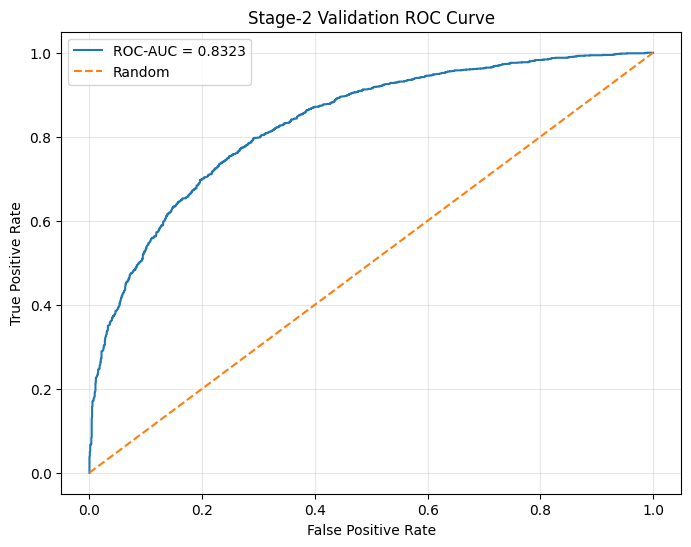

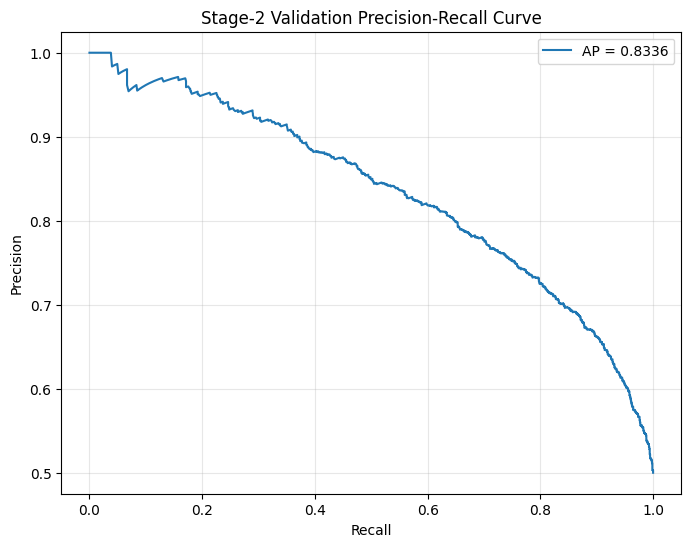

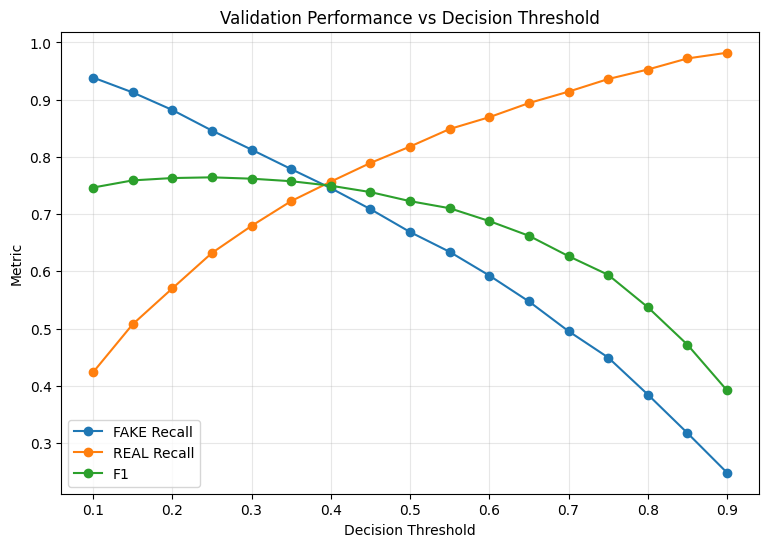

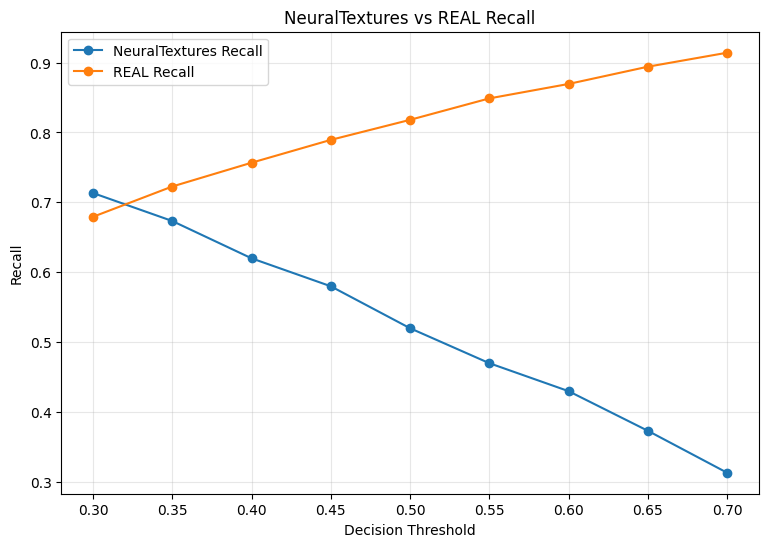


CELL 33 — VALIDATION THRESHOLD ANALYSIS COMPLETE
Overall ROC-AUC: 0.8323
Average Precision: 0.8336
Best F1 threshold: 0.25
Best F1: 0.7642
Current threshold: 0.50
Current overall FAKE recall: 0.6687
NeuralTextures mean probability: 0.5153
NeuralTextures median probability: 0.5317
Test set used: NO

Saved:
/kaggle/working/efficientnet_b0_stage2_threshold_analysis.csv
/kaggle/working/efficientnet_b0_stage2_method_auc_analysis.csv
/kaggle/working/efficientnet_b0_stage2_method_threshold_analysis.csv
/kaggle/working/efficientnet_b0_stage2_neuraltextures_threshold_analysis.csv
/kaggle/working/efficientnet_b0_stage2_neuraltextures_vs_real_thresholds.csv
CELL 33 — COMPLETE


In [50]:
# ============================================================
# CELL 33 — VALIDATION ROC / PR / THRESHOLD ANALYSIS
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 70)
print("CELL 33 — VALIDATION ROC / PR / THRESHOLD ANALYSIS")
print("=" * 70)


# ============================================================
# 1. LOAD VALIDATION PREDICTIONS
# ============================================================

prediction_path = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_validation_predictions.csv"
)

metadata_path = (
    "/kaggle/input/notebooks/ramsaikoravi/"
    "deepfake-01-faceforensics-preprocessing/"
    "ffpp_faces_v1/metadata.csv"
)

if not os.path.exists(prediction_path):
    raise FileNotFoundError(
        f"Prediction file not found:\n{prediction_path}"
    )

if not os.path.exists(metadata_path):
    raise FileNotFoundError(
        f"Metadata file not found:\n{metadata_path}"
    )

pred_df = pd.read_csv(prediction_path)
metadata_df = pd.read_csv(metadata_path)


# ============================================================
# 2. PREPARE VALIDATION METADATA
# ============================================================

val_meta = metadata_df[
    metadata_df["split"] == "val"
].copy()

val_meta = val_meta.reset_index(drop=True)
pred_df = pred_df.reset_index(drop=True)

print("\n" + "-" * 70)
print("VALIDATION DATA")
print("-" * 70)

print("Prediction rows :", len(pred_df))
print("Metadata rows   :", len(val_meta))

if len(pred_df) != len(val_meta):
    raise RuntimeError(
        "Prediction and validation metadata row counts differ."
    )

print(
    "Prediction columns:",
    list(pred_df.columns)
)

print(
    "Metadata columns:",
    list(val_meta.columns)
)

print(
    "\nMetadata class counts:"
)

print(
    val_meta["label"].value_counts()
)

print(
    "\nPrediction class counts:"
)

print(
    pred_df["true_label"].value_counts()
)


# ============================================================
# 3. VERIFIED ROW-ORDER ALIGNMENT
# ============================================================

metadata_numeric_labels = (
    val_meta["label"]
    .map({
        "REAL": 0,
        "FAKE": 1
    })
    .astype(int)
)

prediction_numeric_labels = (
    pred_df["true_label"]
    .astype(int)
)

if not np.array_equal(
    metadata_numeric_labels.values,
    prediction_numeric_labels.values
):
    raise RuntimeError(
        "CRITICAL: validation metadata labels and "
        "prediction true_label values do not match "
        "row-by-row.\n"
        "Row-order alignment is unsafe."
    )

print(
    "\n✅ Row-by-row label alignment verified"
)

print(
    "✅ Manipulation metadata can safely be attached "
    "to predictions by row order"
)


# ============================================================
# 4. COMBINE PREDICTIONS + METADATA
# ============================================================

work_df = val_meta.copy()

work_df["y_true"] = (
    prediction_numeric_labels.values
)

work_df["predicted_label"] = (
    pred_df["predicted_label"]
    .astype(int)
    .values
)

work_df["fake_probability"] = (
    pred_df["fake_probability"]
    .astype(float)
    .values
)

work_df["confidence"] = (
    pred_df["confidence"]
    .astype(float)
    .values
)

print("\n" + "-" * 70)
print("COMBINED VALIDATION DATA")
print("-" * 70)

print(
    "Rows:",
    len(work_df)
)

print(
    "Unique source videos:",
    work_df["source_video"].nunique()
)

print(
    "Unique methods:",
    work_df["method"].nunique()
)

print(
    "Methods:",
    sorted(
        work_df["method"].unique()
    )
)


# ============================================================
# 5. BASIC PREDICTION INTEGRITY
# ============================================================

if work_df["fake_probability"].isna().any():
    raise RuntimeError(
        "Missing fake probabilities detected."
    )

if not np.isfinite(
    work_df["fake_probability"]
).all():
    raise RuntimeError(
        "Non-finite fake probabilities detected."
    )

if (
    (work_df["fake_probability"] < 0)
    |
    (work_df["fake_probability"] > 1)
).any():
    raise RuntimeError(
        "Fake probabilities outside [0,1]."
    )

print(
    "✅ Probability values valid"
)


# ============================================================
# 6. OVERALL ROC
# ============================================================

print("\n" + "=" * 70)
print("OVERALL VALIDATION ROC ANALYSIS")
print("=" * 70)

y_true = (
    work_df["y_true"]
    .values
)

y_prob = (
    work_df["fake_probability"]
    .values
)

overall_auc = roc_auc_score(
    y_true,
    y_prob
)

fpr, tpr, roc_thresholds = roc_curve(
    y_true,
    y_prob
)

print(
    "Validation ROC-AUC:",
    f"{overall_auc:.6f}"
)

print(
    "Stage-2 recorded ROC-AUC:",
    "0.832292"
)

print(
    "AUC difference:",
    f"{overall_auc - 0.832292:+.8f}"
)


# ============================================================
# 7. PRECISION-RECALL
# ============================================================

print("\n" + "=" * 70)
print("PRECISION-RECALL ANALYSIS")
print("=" * 70)

precision_curve, recall_curve, pr_thresholds = (
    precision_recall_curve(
        y_true,
        y_prob
    )
)

average_precision = (
    average_precision_score(
        y_true,
        y_prob
    )
)

print(
    "Average Precision:",
    f"{average_precision:.6f}"
)


# ============================================================
# 8. OVERALL THRESHOLD SWEEP
# ============================================================

print("\n" + "=" * 70)
print("OVERALL VALIDATION THRESHOLD SWEEP")
print("=" * 70)

thresholds = np.round(
    np.arange(
        0.10,
        0.91,
        0.05
    ),
    2
)

threshold_rows = []

for threshold in thresholds:

    y_pred = (
        y_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = (
        confusion_matrix(
            y_true,
            y_pred,
            labels=[0, 1]
        )
        .ravel()
    )

    threshold_rows.append(
        {
            "threshold": threshold,

            "accuracy":
                accuracy_score(
                    y_true,
                    y_pred
                ),

            "precision":
                precision_score(
                    y_true,
                    y_pred,
                    zero_division=0
                ),

            "recall":
                recall_score(
                    y_true,
                    y_pred,
                    zero_division=0
                ),

            "f1":
                f1_score(
                    y_true,
                    y_pred,
                    zero_division=0
                ),

            "real_recall":
                tn / (tn + fp),

            "false_positive_rate":
                fp / (fp + tn),

            "fake_as_real_rate":
                fn / (fn + tp),

            "true_negative": tn,
            "false_positive": fp,
            "false_negative": fn,
            "true_positive": tp
        }
    )

threshold_df = pd.DataFrame(
    threshold_rows
)

display(threshold_df)


# ============================================================
# 9. BEST F1 THRESHOLD
# ============================================================

print("\n" + "-" * 70)
print("BEST VALIDATION F1 THRESHOLD")
print("-" * 70)

best_f1_row = (
    threshold_df
    .sort_values(
        "f1",
        ascending=False
    )
    .iloc[0]
)

print(
    "Threshold:",
    best_f1_row["threshold"]
)

print(
    "Accuracy:",
    f"{best_f1_row['accuracy']:.4f}"
)

print(
    "Precision:",
    f"{best_f1_row['precision']:.4f}"
)

print(
    "Recall:",
    f"{best_f1_row['recall']:.4f}"
)

print(
    "F1:",
    f"{best_f1_row['f1']:.4f}"
)


# ============================================================
# 10. THRESHOLDS WITH REAL RECALL >= 80%
# ============================================================

print("\n" + "-" * 70)
print("THRESHOLDS WITH REAL RECALL >= 80%")
print("-" * 70)

real_80 = threshold_df[
    threshold_df["real_recall"] >= 0.80
]

display(real_80)


# ============================================================
# 11. THRESHOLDS WITH FAKE RECALL >= 70%
# ============================================================

print("\n" + "-" * 70)
print("THRESHOLDS WITH FAKE RECALL >= 70%")
print("-" * 70)

fake_70 = threshold_df[
    threshold_df["recall"] >= 0.70
]

display(fake_70)


# ============================================================
# 12. MANIPULATION-SPECIFIC ROC-AUC
# ============================================================

print("\n" + "=" * 70)
print("MANIPULATION-SPECIFIC ROC-AUC")
print("=" * 70)

fake_methods = sorted(
    work_df.loc[
        work_df["y_true"] == 1,
        "method"
    ].unique()
)

method_auc_rows = []

for method in fake_methods:

    fake_part = work_df[
        (
            (work_df["y_true"] == 1)
            &
            (work_df["method"] == method)
        )
    ]

    real_part = work_df[
        work_df["y_true"] == 0
    ]

    method_eval = pd.concat(
        [
            real_part,
            fake_part
        ],
        ignore_index=True
    )

    method_auc = roc_auc_score(
        method_eval["y_true"],
        method_eval["fake_probability"]
    )

    method_ap = average_precision_score(
        method_eval["y_true"],
        method_eval["fake_probability"]
    )

    method_auc_rows.append(
        {
            "method": method,
            "real_images": len(real_part),
            "fake_images": len(fake_part),
            "roc_auc": method_auc,
            "average_precision": method_ap,
            "mean_fake_probability":
                fake_part["fake_probability"].mean(),
            "median_fake_probability":
                fake_part["fake_probability"].median()
        }
    )

method_auc_df = (
    pd.DataFrame(
        method_auc_rows
    )
    .sort_values(
        "roc_auc",
        ascending=False
    )
    .reset_index(drop=True)
)

display(method_auc_df)


# ============================================================
# 13. MANIPULATION-SPECIFIC THRESHOLD BEHAVIOR
# ============================================================

print("\n" + "=" * 70)
print("MANIPULATION-SPECIFIC THRESHOLD BEHAVIOR")
print("=" * 70)

method_threshold_rows = []

method_thresholds = [
    0.30,
    0.35,
    0.40,
    0.45,
    0.50,
    0.55,
    0.60,
    0.65,
    0.70
]

for method in fake_methods:

    fake_part = work_df[
        (
            (work_df["y_true"] == 1)
            &
            (work_df["method"] == method)
        )
    ]

    fake_probs = (
        fake_part["fake_probability"]
        .values
    )

    for threshold in method_thresholds:

        fake_recall = (
            fake_probs >= threshold
        ).mean()

        method_threshold_rows.append(
            {
                "method": method,
                "threshold": threshold,
                "fake_recall": fake_recall,
                "fake_error_rate":
                    1.0 - fake_recall,
                "mean_fake_probability":
                    fake_probs.mean(),
                "median_fake_probability":
                    np.median(fake_probs)
            }
        )

method_threshold_df = pd.DataFrame(
    method_threshold_rows
)

display(method_threshold_df)


# ============================================================
# 14. NEURALTEXTURES THRESHOLD ANALYSIS
# ============================================================

print("\n" + "=" * 70)
print("NEURALTEXTURES THRESHOLD ANALYSIS")
print("=" * 70)

nt_probs = (
    work_df[
        (
            (work_df["y_true"] == 1)
            &
            (
                work_df["method"]
                == "NeuralTextures"
            )
        )
    ]["fake_probability"]
    .values
)

print(
    "NeuralTextures images:",
    len(nt_probs)
)

print(
    "Mean probability:",
    f"{nt_probs.mean():.6f}"
)

print(
    "Median probability:",
    f"{np.median(nt_probs):.6f}"
)

nt_threshold_rows = []

for threshold in method_thresholds:

    recall_value = (
        nt_probs >= threshold
    ).mean()

    nt_threshold_rows.append(
        {
            "threshold": threshold,
            "neuraltextures_recall":
                recall_value,
            "neuraltextures_error_rate":
                1.0 - recall_value
        }
    )

nt_threshold_df = pd.DataFrame(
    nt_threshold_rows
)

display(nt_threshold_df)


# ============================================================
# 15. REAL THRESHOLD BEHAVIOR
# ============================================================

print("\n" + "=" * 70)
print("REAL THRESHOLD BEHAVIOR")
print("=" * 70)

real_probs = (
    work_df[
        work_df["y_true"] == 0
    ]["fake_probability"]
    .values
)

real_threshold_rows = []

for threshold in method_thresholds:

    real_recall = (
        real_probs < threshold
    ).mean()

    real_false_positive_rate = (
        real_probs >= threshold
    ).mean()

    real_threshold_rows.append(
        {
            "threshold": threshold,
            "real_recall":
                real_recall,
            "real_as_fake_rate":
                real_false_positive_rate
        }
    )

real_threshold_df = pd.DataFrame(
    real_threshold_rows
)

display(real_threshold_df)


# ============================================================
# 16. NEURALTEXTURES vs REAL
# ============================================================

print("\n" + "=" * 70)
print("NEURALTEXTURES vs REAL THRESHOLD BEHAVIOR")
print("=" * 70)

nt_real_rows = []

for threshold in method_thresholds:

    nt_recall = (
        nt_probs >= threshold
    ).mean()

    real_recall = (
        real_probs < threshold
    ).mean()

    nt_real_rows.append(
        {
            "threshold": threshold,

            "NeuralTextures_recall":
                nt_recall,

            "REAL_recall":
                real_recall,

            "NeuralTextures_error":
                1.0 - nt_recall,

            "REAL_as_FAKE":
                1.0 - real_recall
        }
    )

nt_real_df = pd.DataFrame(
    nt_real_rows
)

display(nt_real_df)


# ============================================================
# 17. PLOTS
# ============================================================

print("\n" + "=" * 70)
print("GENERATING VALIDATION DIAGNOSTIC PLOTS")
print("=" * 70)


# ---- ROC ----

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {overall_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(
    "Stage-2 Validation ROC Curve"
)

plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ---- Precision Recall ----

plt.figure(figsize=(8, 6))

plt.plot(
    recall_curve,
    precision_curve,
    label=f"AP = {average_precision:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(
    "Stage-2 Validation Precision-Recall Curve"
)

plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ---- Threshold performance ----

plt.figure(figsize=(9, 6))

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    marker="o",
    label="FAKE Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["real_recall"],
    marker="o",
    label="REAL Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1"],
    marker="o",
    label="F1"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Metric")
plt.title(
    "Validation Performance vs Decision Threshold"
)

plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ---- NeuralTextures vs REAL ----

plt.figure(figsize=(9, 6))

plt.plot(
    nt_real_df["threshold"],
    nt_real_df["NeuralTextures_recall"],
    marker="o",
    label="NeuralTextures Recall"
)

plt.plot(
    nt_real_df["threshold"],
    nt_real_df["REAL_recall"],
    marker="o",
    label="REAL Recall"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Recall")
plt.title(
    "NeuralTextures vs REAL Recall"
)

plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ============================================================
# 18. SAVE AUDIT FILES
# ============================================================

threshold_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_threshold_analysis.csv"
)

method_auc_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_method_auc_analysis.csv"
)

method_threshold_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_method_threshold_analysis.csv"
)

nt_threshold_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_neuraltextures_threshold_analysis.csv"
)

nt_real_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_neuraltextures_vs_real_thresholds.csv"
)

threshold_df.to_csv(
    threshold_output,
    index=False
)

method_auc_df.to_csv(
    method_auc_output,
    index=False
)

method_threshold_df.to_csv(
    method_threshold_output,
    index=False
)

nt_threshold_df.to_csv(
    nt_threshold_output,
    index=False
)

nt_real_df.to_csv(
    nt_real_output,
    index=False
)


# ============================================================
# 19. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("CELL 33 — VALIDATION THRESHOLD ANALYSIS COMPLETE")
print("=" * 70)

current_50 = (
    threshold_df[
        threshold_df["threshold"] == 0.50
    ]["recall"]
    .iloc[0]
)

print(
    "Overall ROC-AUC:",
    f"{overall_auc:.4f}"
)

print(
    "Average Precision:",
    f"{average_precision:.4f}"
)

print(
    "Best F1 threshold:",
    best_f1_row["threshold"]
)

print(
    "Best F1:",
    f"{best_f1_row['f1']:.4f}"
)

print(
    "Current threshold:",
    "0.50"
)

print(
    "Current overall FAKE recall:",
    f"{current_50:.4f}"
)

print(
    "NeuralTextures mean probability:",
    f"{nt_probs.mean():.4f}"
)

print(
    "NeuralTextures median probability:",
    f"{np.median(nt_probs):.4f}"
)

print(
    "Test set used: NO"
)

print("\nSaved:")
print(threshold_output)
print(method_auc_output)
print(method_threshold_output)
print(nt_threshold_output)
print(nt_real_output)

print("=" * 70)
print("CELL 33 — COMPLETE")
print("=" * 70)

In [51]:
# ============================================================
# CELL 34 — SOURCE / MANIPULATION THRESHOLD STABILITY AUDIT
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 70)
print("CELL 34 — SOURCE / MANIPULATION THRESHOLD STABILITY AUDIT")
print("=" * 70)


# ============================================================
# 1. PATHS
# ============================================================

prediction_path = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_validation_predictions.csv"
)

metadata_path = (
    "/kaggle/input/notebooks/ramsaikoravi/"
    "deepfake-01-faceforensics-preprocessing/"
    "ffpp_faces_v1/metadata.csv"
)

if not os.path.exists(prediction_path):
    raise FileNotFoundError(
        f"Prediction file not found:\n{prediction_path}"
    )

if not os.path.exists(metadata_path):
    raise FileNotFoundError(
        f"Metadata file not found:\n{metadata_path}"
    )


# ============================================================
# 2. LOAD DATA
# ============================================================

pred_df = pd.read_csv(
    prediction_path
)

metadata_df = pd.read_csv(
    metadata_path
)

val_meta = (
    metadata_df[
        metadata_df["split"] == "val"
    ]
    .copy()
    .reset_index(drop=True)
)

pred_df = (
    pred_df
    .copy()
    .reset_index(drop=True)
)


# ============================================================
# 3. BASIC INTEGRITY CHECK
# ============================================================

print("\n" + "-" * 70)
print("VALIDATION DATA")
print("-" * 70)

print(
    "Prediction rows:",
    len(pred_df)
)

print(
    "Validation metadata rows:",
    len(val_meta)
)

if len(pred_df) != len(val_meta):
    raise RuntimeError(
        "Prediction and validation metadata row counts differ."
    )

metadata_labels = (
    val_meta["label"]
    .map(
        {
            "REAL": 0,
            "FAKE": 1
        }
    )
    .astype(int)
)

prediction_labels = (
    pred_df["true_label"]
    .astype(int)
)

if not np.array_equal(
    metadata_labels.values,
    prediction_labels.values
):
    raise RuntimeError(
        "Row-by-row validation label alignment failed."
    )

print(
    "✅ Row-by-row prediction/metadata alignment verified"
)


# ============================================================
# 4. BUILD ANALYSIS DATAFRAME
# ============================================================

analysis_df = val_meta.copy()

analysis_df["y_true"] = (
    prediction_labels.values
)

analysis_df["predicted_label"] = (
    pred_df["predicted_label"]
    .astype(int)
    .values
)

analysis_df["fake_probability"] = (
    pred_df["fake_probability"]
    .astype(float)
    .values
)

analysis_df["confidence"] = (
    pred_df["confidence"]
    .astype(float)
    .values
)


# ============================================================
# 5. RECONSTRUCT SOURCE ID
# ============================================================

def reconstruct_source_id(source_video):
    """
    Convert:
        029.mp4      -> 029
        029_123.mp4  -> 029

    FaceForensics++ source pairing uses the
    original source identifier.
    """

    name = str(source_video)

    name = os.path.basename(
        name
    )

    stem = os.path.splitext(
        name
    )[0]

    return stem.split("_")[0]


analysis_df["source_id"] = (
    analysis_df["source_video"]
    .apply(
        reconstruct_source_id
    )
)


# ============================================================
# 6. SOURCE STRUCTURE CHECK
# ============================================================

print("\n" + "-" * 70)
print("SOURCE STRUCTURE")
print("-" * 70)

print(
    "Unique validation source IDs:",
    analysis_df["source_id"].nunique()
)

print(
    "REAL source IDs:",
    analysis_df.loc[
        analysis_df["y_true"] == 0,
        "source_id"
    ].nunique()
)

print(
    "FAKE source IDs:",
    analysis_df.loc[
        analysis_df["y_true"] == 1,
        "source_id"
    ].nunique()
)

expected_sources = 150

if (
    analysis_df["source_id"].nunique()
    != expected_sources
):
    raise RuntimeError(
        "Unexpected validation source count."
    )

print(
    "✅ Expected 150 validation source IDs confirmed"
)


# ============================================================
# 7. THRESHOLDS
# ============================================================

thresholds = np.round(
    np.arange(
        0.20,
        0.61,
        0.05
    ),
    2
)

print("\nThresholds tested:")
print(
    thresholds
)


# ============================================================
# 8. SOURCE-LEVEL FAKE PERFORMANCE
# ============================================================

print("\n" + "=" * 70)
print("SOURCE-LEVEL FAKE THRESHOLD STABILITY")
print("=" * 70)

source_fake_rows = []

fake_df = analysis_df[
    analysis_df["y_true"] == 1
].copy()

for threshold in thresholds:

    fake_df["threshold_prediction"] = (
        fake_df["fake_probability"]
        >= threshold
    ).astype(int)

    for source_id, group in fake_df.groupby(
        "source_id"
    ):

        total_fake = len(group)

        detected_fake = (
            group["threshold_prediction"]
            .sum()
        )

        fake_recall = (
            detected_fake / total_fake
            if total_fake > 0
            else np.nan
        )

        source_fake_rows.append(
            {
                "threshold": threshold,
                "source_id": source_id,
                "total_fake_images": total_fake,
                "detected_fake": detected_fake,
                "missed_fake":
                    total_fake - detected_fake,
                "fake_recall":
                    fake_recall,
                "fake_error_rate":
                    1.0 - fake_recall
            }
        )

source_fake_df = pd.DataFrame(
    source_fake_rows
)

print(
    "Source-threshold records:",
    len(source_fake_df)
)

print(
    "Expected:",
    len(thresholds) * expected_sources
)

if len(source_fake_df) != (
    len(thresholds)
    * expected_sources
):
    raise RuntimeError(
        "Unexpected source-threshold record count."
    )

print(
    "✅ Source-level threshold records complete"
)


# ============================================================
# 9. SOURCE-LEVEL SUMMARY
# ============================================================

source_summary_rows = []

for threshold in thresholds:

    subset = source_fake_df[
        source_fake_df["threshold"]
        == threshold
    ]

    source_summary_rows.append(
        {
            "threshold": threshold,

            "mean_source_fake_recall":
                subset["fake_recall"].mean(),

            "median_source_fake_recall":
                subset["fake_recall"].median(),

            "std_source_fake_recall":
                subset["fake_recall"].std(),

            "min_source_fake_recall":
                subset["fake_recall"].min(),

            "max_source_fake_recall":
                subset["fake_recall"].max(),

            "sources_with_100pct_detection":
                (
                    subset["fake_recall"] == 1.0
                ).sum(),

            "sources_with_0pct_detection":
                (
                    subset["fake_recall"] == 0.0
                ).sum(),

            "sources_below_50pct_recall":
                (
                    subset["fake_recall"] < 0.50
                ).sum(),

            "sources_below_70pct_recall":
                (
                    subset["fake_recall"] < 0.70
                ).sum(),

            "sources_above_90pct_recall":
                (
                    subset["fake_recall"] >= 0.90
                ).sum()
        }
    )

source_summary_df = pd.DataFrame(
    source_summary_rows
)

print("\nSOURCE-LEVEL SUMMARY")

display(
    source_summary_df
)


# ============================================================
# 10. REAL SOURCE-LEVEL PERFORMANCE
# ============================================================

print("\n" + "=" * 70)
print("REAL SOURCE-LEVEL THRESHOLD STABILITY")
print("=" * 70)

real_df = analysis_df[
    analysis_df["y_true"] == 0
].copy()

source_real_rows = []

for threshold in thresholds:

    real_df["threshold_prediction"] = (
        real_df["fake_probability"]
        >= threshold
    ).astype(int)

    for source_id, group in real_df.groupby(
        "source_id"
    ):

        total_real = len(group)

        correctly_real = (
            group["threshold_prediction"]
            == 0
        ).sum()

        real_recall = (
            correctly_real / total_real
            if total_real > 0
            else np.nan
        )

        source_real_rows.append(
            {
                "threshold": threshold,
                "source_id": source_id,
                "total_real_images": total_real,
                "correct_real": correctly_real,
                "real_as_fake":
                    total_real - correctly_real,
                "real_recall":
                    real_recall,
                "real_as_fake_rate":
                    1.0 - real_recall
            }
        )

source_real_df = pd.DataFrame(
    source_real_rows
)

real_summary_rows = []

for threshold in thresholds:

    subset = source_real_df[
        source_real_df["threshold"]
        == threshold
    ]

    real_summary_rows.append(
        {
            "threshold": threshold,

            "mean_source_real_recall":
                subset["real_recall"].mean(),

            "median_source_real_recall":
                subset["real_recall"].median(),

            "std_source_real_recall":
                subset["real_recall"].std(),

            "min_source_real_recall":
                subset["real_recall"].min(),

            "max_source_real_recall":
                subset["real_recall"].max(),

            "sources_with_100pct_real_detection":
                (
                    subset["real_recall"] == 1.0
                ).sum(),

            "sources_below_70pct_real_recall":
                (
                    subset["real_recall"] < 0.70
                ).sum(),

            "sources_below_80pct_real_recall":
                (
                    subset["real_recall"] < 0.80
                ).sum(),

            "sources_above_90pct_real_recall":
                (
                    subset["real_recall"] >= 0.90
                ).sum()
        }
    )

real_summary_df = pd.DataFrame(
    real_summary_rows
)

display(
    real_summary_df
)


# ============================================================
# 11. MANIPULATION-LEVEL STABILITY
# ============================================================

print("\n" + "=" * 70)
print("MANIPULATION-LEVEL THRESHOLD STABILITY")
print("=" * 70)

method_rows = []

fake_methods = sorted(
    fake_df["method"].unique()
)

for method in fake_methods:

    method_df = fake_df[
        fake_df["method"] == method
    ].copy()

    for threshold in thresholds:

        detected = (
            method_df["fake_probability"]
            >= threshold
        ).sum()

        total = len(
            method_df
        )

        recall = (
            detected / total
        )

        method_rows.append(
            {
                "method": method,
                "threshold": threshold,
                "images": total,
                "detected_fake": detected,
                "missed_fake":
                    total - detected,
                "fake_recall": recall,
                "fake_error_rate":
                    1.0 - recall
            }
        )

method_threshold_df = pd.DataFrame(
    method_rows
)

display(
    method_threshold_df
)


# ============================================================
# 12. MANIPULATION SOURCE-TO-SOURCE VARIABILITY
# ============================================================

print("\n" + "=" * 70)
print(
    "MANIPULATION SOURCE-TO-SOURCE VARIABILITY"
)
print("=" * 70)

method_source_rows = []

for method in fake_methods:

    method_source_df = source_fake_df.merge(
        fake_df[
            [
                "source_id",
                "method"
            ]
        ].drop_duplicates(),
        on="source_id",
        how="inner"
    )

    method_source_df = method_source_df[
        method_source_df["method"]
        == method
    ]

    for threshold in thresholds:

        subset = method_source_df[
            method_source_df["threshold"]
            == threshold
        ]

        method_source_rows.append(
            {
                "method": method,
                "threshold": threshold,

                "mean_source_recall":
                    subset["fake_recall"].mean(),

                "median_source_recall":
                    subset["fake_recall"].median(),

                "std_source_recall":
                    subset["fake_recall"].std(),

                "min_source_recall":
                    subset["fake_recall"].min(),

                "max_source_recall":
                    subset["fake_recall"].max(),

                "sources_below_50pct":
                    (
                        subset["fake_recall"] < 0.50
                    ).sum(),

                "sources_below_70pct":
                    (
                        subset["fake_recall"] < 0.70
                    ).sum(),

                "sources_at_100pct":
                    (
                        subset["fake_recall"] == 1.0
                    ).sum()
            }
        )

method_source_stability_df = pd.DataFrame(
    method_source_rows
)

display(
    method_source_stability_df
)


# ============================================================
# 13. NEURALTEXTURES SOURCE-LEVEL DEEP DIVE
# ============================================================

print("\n" + "=" * 70)
print("NEURALTEXTURES SOURCE-LEVEL DEEP DIVE")
print("=" * 70)

nt_source_df = source_fake_df.merge(
    fake_df[
        [
            "source_id",
            "method"
        ]
    ].drop_duplicates(),
    on="source_id",
    how="inner"
)

nt_source_df = nt_source_df[
    nt_source_df["method"]
    == "NeuralTextures"
].copy()

print(
    "NeuralTextures sources:",
    nt_source_df["source_id"].nunique()
)

nt_rows = []

for threshold in thresholds:

    subset = nt_source_df[
        nt_source_df["threshold"]
        == threshold
    ]

    nt_rows.append(
        {
            "threshold": threshold,

            "mean_source_recall":
                subset["fake_recall"].mean(),

            "median_source_recall":
                subset["fake_recall"].median(),

            "std_source_recall":
                subset["fake_recall"].std(),

            "min_source_recall":
                subset["fake_recall"].min(),

            "max_source_recall":
                subset["fake_recall"].max(),

            "sources_0pct":
                (
                    subset["fake_recall"] == 0.0
                ).sum(),

            "sources_50pct_or_less":
                (
                    subset["fake_recall"] <= 0.50
                ).sum(),

            "sources_100pct":
                (
                    subset["fake_recall"] == 1.0
                ).sum()
        }
    )

nt_stability_df = pd.DataFrame(
    nt_rows
)

display(
    nt_stability_df
)


# ============================================================
# 14. THRESHOLD STABILITY SCORE
# ============================================================

print("\n" + "=" * 70)
print("THRESHOLD STABILITY SUMMARY")
print("=" * 70)

stability_rows = []

for threshold in thresholds:

    fake_subset = source_fake_df[
        source_fake_df["threshold"]
        == threshold
    ]

    real_subset = source_real_df[
        source_real_df["threshold"]
        == threshold
    ]

    # A descriptive stability measure:
    # higher fake recall
    # + higher real recall
    # - source variability
    #
    # This is NOT used to select a deployment threshold.
    stability_score = (
        (
            fake_subset["fake_recall"].mean()
            +
            real_subset["real_recall"].mean()
        )
        / 2
    ) - (
        (
            fake_subset["fake_recall"].std()
            +
            real_subset["real_recall"].std()
        )
        / 2
    )

    stability_rows.append(
        {
            "threshold": threshold,

            "mean_fake_recall":
                fake_subset["fake_recall"].mean(),

            "mean_real_recall":
                real_subset["real_recall"].mean(),

            "fake_source_std":
                fake_subset["fake_recall"].std(),

            "real_source_std":
                real_subset["real_recall"].std(),

            "descriptive_stability_score":
                stability_score
        }
    )

stability_df = pd.DataFrame(
    stability_rows
)

display(
    stability_df
)

print(
    "\nNOTE:"
)

print(
    "The descriptive stability score is NOT a final "
    "threshold-selection criterion."
)

print(
    "It is used only to inspect source-level stability."
)


# ============================================================
# 15. THRESHOLD-TO-THRESHOLD CHANGES
# ============================================================

print("\n" + "=" * 70)
print("THRESHOLD-TO-THRESHOLD CHANGES")
print("=" * 70)

change_rows = []

for i in range(
    1,
    len(thresholds)
):

    previous_threshold = thresholds[i - 1]
    current_threshold = thresholds[i]

    previous = stability_df[
        stability_df["threshold"]
        == previous_threshold
    ].iloc[0]

    current = stability_df[
        stability_df["threshold"]
        == current_threshold
    ].iloc[0]

    change_rows.append(
        {
            "from_threshold":
                previous_threshold,

            "to_threshold":
                current_threshold,

            "fake_recall_change":
                current["mean_fake_recall"]
                -
                previous["mean_fake_recall"],

            "real_recall_change":
                current["mean_real_recall"]
                -
                previous["mean_real_recall"],

            "fake_source_std_change":
                current["fake_source_std"]
                -
                previous["fake_source_std"],

            "real_source_std_change":
                current["real_source_std"]
                -
                previous["real_source_std"]
        }
    )

threshold_change_df = pd.DataFrame(
    change_rows
)

display(
    threshold_change_df
)


# ============================================================
# 16. SAVE AUDIT FILES
# ============================================================

source_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_source_threshold_stability.csv"
)

source_real_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_real_source_threshold_stability.csv"
)

method_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_method_threshold_stability.csv"
)

method_source_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_method_source_threshold_stability.csv"
)

nt_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_neuraltextures_source_stability.csv"
)

stability_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_threshold_stability_summary.csv"
)

change_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_threshold_change_analysis.csv"
)

source_fake_df.to_csv(
    source_output,
    index=False
)

source_real_df.to_csv(
    source_real_output,
    index=False
)

method_threshold_df.to_csv(
    method_output,
    index=False
)

method_source_stability_df.to_csv(
    method_source_output,
    index=False
)

nt_stability_df.to_csv(
    nt_output,
    index=False
)

stability_df.to_csv(
    stability_output,
    index=False
)

threshold_change_df.to_csv(
    change_output,
    index=False
)


# ============================================================
# 17. FINAL AUDIT SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("CELL 34 — SOURCE / MANIPULATION THRESHOLD STABILITY")
print("AUDIT COMPLETE")
print("=" * 70)

print(
    "Validation images analyzed:",
    len(analysis_df)
)

print(
    "Validation source IDs:",
    analysis_df["source_id"].nunique()
)

print(
    "Thresholds analyzed:",
    len(thresholds)
)

print(
    "Threshold range:",
    f"{thresholds.min():.2f}"
    " → "
    f"{thresholds.max():.2f}"
)

print(
    "Manipulations analyzed:",
    len(fake_methods)
)

print(
    "NeuralTextures sources:",
    nt_source_df["source_id"].nunique()
)

print(
    "\nFinal threshold selection:",
    "NOT PERFORMED"
)

print(
    "Test set used:",
    "NO"
)

print("\nSaved:")
print(source_output)
print(source_real_output)
print(method_output)
print(method_source_output)
print(nt_output)
print(stability_output)
print(change_output)

print("=" * 70)

CELL 34 — SOURCE / MANIPULATION THRESHOLD STABILITY AUDIT

----------------------------------------------------------------------
VALIDATION DATA
----------------------------------------------------------------------
Prediction rows: 3000
Validation metadata rows: 3000
✅ Row-by-row prediction/metadata alignment verified

----------------------------------------------------------------------
SOURCE STRUCTURE
----------------------------------------------------------------------
Unique validation source IDs: 150
REAL source IDs: 150
FAKE source IDs: 150
✅ Expected 150 validation source IDs confirmed

Thresholds tested:
[0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6 ]

SOURCE-LEVEL FAKE THRESHOLD STABILITY
Source-threshold records: 1350
Expected: 1350
✅ Source-level threshold records complete

SOURCE-LEVEL SUMMARY


,threshold,mean_source_fake_recall,median_source_fake_recall,std_source_fake_recall,min_source_fake_recall,max_source_fake_recall,sources_with_100pct_detection,sources_with_0pct_detection,sources_below_50pct_recall,sources_below_70pct_recall,sources_above_90pct_recall
0,0.20,0.882000,1.00,0.172650,0.2,1.0,81,0,4,20,107
1,0.25,0.846000,0.90,0.189535,0.2,1.0,67,0,6,22,92
2,0.30,0.812667,0.90,0.208316,0.2,1.0,54,0,11,36,87
3,0.35,0.778667,0.80,0.225128,0.2,1.0,46,0,16,40,72
4,0.40,0.745333,0.80,0.238166,0.1,1.0,40,0,21,44,59
5,0.45,0.708667,0.75,0.249815,0.1,1.0,35,0,30,53,51
6,0.50,0.668667,0.70,0.257801,0.1,1.0,28,0,35,64,43
7,0.55,0.634000,0.65,0.269434,0.1,1.0,24,0,43,75,40
8,0.60,0.592667,0.60,0.274924,0.1,1.0,17,0,49,83,35



REAL SOURCE-LEVEL THRESHOLD STABILITY


,threshold,mean_source_real_recall,median_source_real_recall,std_source_real_recall,min_source_real_recall,max_source_real_recall,sources_with_100pct_real_detection,sources_below_70pct_real_recall,sources_below_80pct_real_recall,sources_above_90pct_real_recall
0,0.20,0.570000,0.60,0.368336,0.0,1.0,36,76,88,50
1,0.25,0.632000,0.70,0.350325,0.0,1.0,39,63,76,59
2,0.30,0.679333,0.80,0.337638,0.0,1.0,48,58,66,68
3,0.35,0.722667,0.80,0.319636,0.0,1.0,56,48,58,74
4,0.40,0.756667,0.90,0.303761,0.0,1.0,60,40,52,83
5,0.45,0.789333,0.90,0.281450,0.0,1.0,66,34,42,89
6,0.50,0.818000,0.95,0.267745,0.0,1.0,75,31,33,96
7,0.55,0.848667,1.00,0.253231,0.0,1.0,87,27,31,108
8,0.60,0.869333,1.00,0.243836,0.0,1.0,96,24,29,116



MANIPULATION-LEVEL THRESHOLD STABILITY


,method,threshold,images,detected_fake,missed_fake,fake_recall,fake_error_rate
0,Deepfakes,0.20,300,279,21,0.930000,0.070000
1,Deepfakes,0.25,300,273,27,0.910000,0.090000
2,Deepfakes,0.30,300,265,35,0.883333,0.116667
3,Deepfakes,0.35,300,261,39,0.870000,0.130000
4,Deepfakes,0.40,300,257,43,0.856667,0.143333
5,Deepfakes,0.45,300,250,50,0.833333,0.166667
6,Deepfakes,0.50,300,244,56,0.813333,0.186667
7,Deepfakes,0.55,300,237,63,0.790000,0.210000
8,Deepfakes,0.60,300,228,72,0.760000,0.240000
9,Face2Face,0.20,300,267,33,0.890000,0.110000


... (5 outputs left out)

,threshold,mean_fake_recall,mean_real_recall,fake_source_std,real_source_std,descriptive_stability_score
0,0.20,0.882000,0.570000,0.172650,0.368336,0.455507
1,0.25,0.846000,0.632000,0.189535,0.350325,0.469070
2,0.30,0.812667,0.679333,0.208316,0.337638,0.473023
3,0.35,0.778667,0.722667,0.225128,0.319636,0.478284
4,0.40,0.745333,0.756667,0.238166,0.303761,0.480037
5,0.45,0.708667,0.789333,0.249815,0.281450,0.483367
6,0.50,0.668667,0.818000,0.257801,0.267745,0.480561
7,0.55,0.634000,0.848667,0.269434,0.253231,0.480001
8,0.60,0.592667,0.869333,0.274924,0.243836,0.471620



NOTE:
The descriptive stability score is NOT a final threshold-selection criterion.
It is used only to inspect source-level stability.

THRESHOLD-TO-THRESHOLD CHANGES


,from_threshold,to_threshold,fake_recall_change,real_recall_change,fake_source_std_change,real_source_std_change
0,0.20,0.25,-0.036000,0.062000,0.016885,-0.018011
1,0.25,0.30,-0.033333,0.047333,0.018781,-0.012687
2,0.30,0.35,-0.034000,0.043333,0.016812,-0.018002
3,0.35,0.40,-0.033333,0.034000,0.013038,-0.015875
4,0.40,0.45,-0.036667,0.032667,0.011649,-0.022311
5,0.45,0.50,-0.040000,0.028667,0.007986,-0.013706
6,0.50,0.55,-0.034667,0.030667,0.011633,-0.014514
7,0.55,0.60,-0.041333,0.020667,0.005491,-0.009395



CELL 34 — SOURCE / MANIPULATION THRESHOLD STABILITY
AUDIT COMPLETE
Validation images analyzed: 3000
Validation source IDs: 150
Thresholds analyzed: 9
Threshold range: 0.20 → 0.60
Manipulations analyzed: 5
NeuralTextures sources: 150

Final threshold selection: NOT PERFORMED
Test set used: NO

Saved:
/kaggle/working/efficientnet_b0_stage2_source_threshold_stability.csv
/kaggle/working/efficientnet_b0_stage2_real_source_threshold_stability.csv
/kaggle/working/efficientnet_b0_stage2_method_threshold_stability.csv
/kaggle/working/efficientnet_b0_stage2_method_source_threshold_stability.csv
/kaggle/working/efficientnet_b0_stage2_neuraltextures_source_stability.csv
/kaggle/working/efficientnet_b0_stage2_threshold_stability_summary.csv
/kaggle/working/efficientnet_b0_stage2_threshold_change_analysis.csv


In [52]:
# ============================================================
# CELL 34B — CORRECTED MANIPULATION × SOURCE THRESHOLD AUDIT
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 70)
print("CELL 34B — CORRECTED MANIPULATION × SOURCE THRESHOLD AUDIT")
print("=" * 70)


# ============================================================
# 1. LOAD EXISTING VALIDATION PREDICTIONS
# ============================================================

prediction_path = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_validation_predictions.csv"
)

metadata_path = (
    "/kaggle/input/notebooks/ramsaikoravi/"
    "deepfake-01-faceforensics-preprocessing/"
    "ffpp_faces_v1/metadata.csv"
)

if not os.path.exists(prediction_path):
    raise FileNotFoundError(
        f"Prediction file not found:\n{prediction_path}"
    )

if not os.path.exists(metadata_path):
    raise FileNotFoundError(
        f"Metadata file not found:\n{metadata_path}"
    )


pred_df = pd.read_csv(
    prediction_path
)

metadata_df = pd.read_csv(
    metadata_path
)


# ============================================================
# 2. VALIDATION METADATA
# ============================================================

val_meta = (
    metadata_df[
        metadata_df["split"] == "val"
    ]
    .copy()
    .reset_index(drop=True)
)

pred_df = (
    pred_df
    .copy()
    .reset_index(drop=True)
)

print("\n" + "-" * 70)
print("DATA ALIGNMENT")
print("-" * 70)

print(
    "Prediction rows:",
    len(pred_df)
)

print(
    "Validation metadata rows:",
    len(val_meta)
)

if len(pred_df) != len(val_meta):
    raise RuntimeError(
        "Prediction and metadata row counts do not match."
    )


metadata_labels = (
    val_meta["label"]
    .map(
        {
            "REAL": 0,
            "FAKE": 1
        }
    )
    .astype(int)
)

prediction_labels = (
    pred_df["true_label"]
    .astype(int)
)

if not np.array_equal(
    metadata_labels.values,
    prediction_labels.values
):
    raise RuntimeError(
        "Prediction labels are not aligned with metadata."
    )

print(
    "✅ Prediction / metadata alignment confirmed"
)


# ============================================================
# 3. BUILD DATAFRAME
# ============================================================

df = val_meta.copy()

df["y_true"] = (
    prediction_labels.values
)

df["fake_probability"] = (
    pred_df["fake_probability"]
    .astype(float)
    .values
)


# ============================================================
# 4. SOURCE ID
# ============================================================

def reconstruct_source_id(source_video):

    filename = os.path.basename(
        str(source_video)
    )

    stem = os.path.splitext(
        filename
    )[0]

    return stem.split("_")[0]


df["source_id"] = (
    df["source_video"]
    .apply(
        reconstruct_source_id
    )
)


# ============================================================
# 5. FAKE ONLY
# ============================================================

fake_df = df[
    df["y_true"] == 1
].copy()

print("\n" + "-" * 70)
print("FAKE DATA")
print("-" * 70)

print(
    "FAKE images:",
    len(fake_df)
)

print(
    "Manipulations:",
    sorted(
        fake_df["method"].unique()
    )
)

print(
    "Sources:",
    fake_df["source_id"].nunique()
)


# ============================================================
# 6. VERIFY SOURCE × METHOD STRUCTURE
# ============================================================

source_method_counts = (
    fake_df
    .groupby(
        [
            "source_id",
            "method"
        ]
    )
    .size()
    .reset_index(
        name="images"
    )
)

print("\n" + "-" * 70)
print("SOURCE × MANIPULATION STRUCTURE")
print("-" * 70)

print(
    "Source × method groups:",
    len(source_method_counts)
)

expected_groups = (
    150 * 5
)

print(
    "Expected:",
    expected_groups
)

if len(source_method_counts) != expected_groups:
    raise RuntimeError(
        "Unexpected source × manipulation structure."
    )

if (
    source_method_counts["images"]
    .nunique()
    != 1
):
    raise RuntimeError(
        "Different source/method groups contain "
        "different numbers of images."
    )

images_per_group = (
    source_method_counts["images"]
    .iloc[0]
)

print(
    "Images per source × method:",
    images_per_group
)

print(
    "✅ Source × manipulation structure confirmed"
)


# ============================================================
# 7. THRESHOLDS
# ============================================================

thresholds = np.round(
    np.arange(
        0.20,
        0.61,
        0.05
    ),
    2
)


# ============================================================
# 8. CORRECT SOURCE × METHOD × THRESHOLD ANALYSIS
# ============================================================

rows = []

for method in sorted(
    fake_df["method"].unique()
):

    method_df = fake_df[
        fake_df["method"] == method
    ]

    for source_id, source_group in (
        method_df.groupby("source_id")
    ):

        total_images = len(
            source_group
        )

        for threshold in thresholds:

            detected = (
                source_group[
                    "fake_probability"
                ]
                >= threshold
            ).sum()

            missed = (
                total_images
                - detected
            )

            recall = (
                detected / total_images
            )

            rows.append(
                {
                    "method": method,
                    "source_id": source_id,
                    "threshold": threshold,
                    "images": total_images,
                    "detected_fake": detected,
                    "missed_fake": missed,
                    "fake_recall": recall,
                    "fake_error_rate":
                        1.0 - recall
                }
            )


corrected_source_method_df = (
    pd.DataFrame(rows)
)


# ============================================================
# 9. VERIFY ROW COUNT
# ============================================================

expected_rows = (
    5
    * 150
    * len(thresholds)
)

print("\n" + "-" * 70)
print("SOURCE × METHOD × THRESHOLD AUDIT")
print("-" * 70)

print(
    "Rows:",
    len(corrected_source_method_df)
)

print(
    "Expected:",
    expected_rows
)

if len(corrected_source_method_df) != expected_rows:
    raise RuntimeError(
        "Incorrect source × method × threshold row count."
    )

print(
    "✅ Correct source × manipulation × threshold "
    "records generated"
)


# ============================================================
# 10. MANIPULATION SOURCE-TO-SOURCE SUMMARY
# ============================================================

summary_rows = []

for method in sorted(
    corrected_source_method_df["method"].unique()
):

    method_data = (
        corrected_source_method_df[
            corrected_source_method_df["method"]
            == method
        ]
    )

    for threshold in thresholds:

        subset = method_data[
            method_data["threshold"]
            == threshold
        ]

        summary_rows.append(
            {
                "method": method,
                "threshold": threshold,

                "mean_source_recall":
                    subset[
                        "fake_recall"
                    ].mean(),

                "median_source_recall":
                    subset[
                        "fake_recall"
                    ].median(),

                "std_source_recall":
                    subset[
                        "fake_recall"
                    ].std(),

                "min_source_recall":
                    subset[
                        "fake_recall"
                    ].min(),

                "max_source_recall":
                    subset[
                        "fake_recall"
                    ].max(),

                "sources_below_50pct":
                    (
                        subset[
                            "fake_recall"
                        ] < 0.50
                    ).sum(),

                "sources_below_70pct":
                    (
                        subset[
                            "fake_recall"
                        ] < 0.70
                    ).sum(),

                "sources_at_100pct":
                    (
                        subset[
                            "fake_recall"
                        ] == 1.0
                    ).sum(),

                "sources_at_0pct":
                    (
                        subset[
                            "fake_recall"
                        ] == 0.0
                    ).sum()
            }
        )


corrected_method_source_df = (
    pd.DataFrame(summary_rows)
)


# ============================================================
# 11. DISPLAY COMPLETE SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("CORRECTED MANIPULATION SOURCE-TO-SOURCE VARIABILITY")
print("=" * 70)

display(
    corrected_method_source_df
)


# ============================================================
# 12. NEURALTEXTURES CORRECTED DEEP DIVE
# ============================================================

print("\n" + "=" * 70)
print("CORRECTED NEURALTEXTURES SOURCE-LEVEL DEEP DIVE")
print("=" * 70)

nt_source_summary = (
    corrected_method_source_df[
        corrected_method_source_df["method"]
        == "NeuralTextures"
    ]
    .copy()
)

display(
    nt_source_summary
)


# ============================================================
# 13. COMPARE METHODS AT KEY THRESHOLDS
# ============================================================

key_thresholds = [
    0.25,
    0.30,
    0.35,
    0.40,
    0.45,
    0.50
]

comparison_df = (
    corrected_method_source_df[
        corrected_method_source_df[
            "threshold"
        ].isin(key_thresholds)
    ]
    [
        [
            "method",
            "threshold",
            "mean_source_recall",
            "median_source_recall",
            "std_source_recall",
            "sources_below_50pct",
            "sources_below_70pct",
            "sources_at_100pct"
        ]
    ]
    .sort_values(
        [
            "threshold",
            "mean_source_recall"
        ],
        ascending=[
            True,
            False
        ]
    )
    .reset_index(
        drop=True
    )
)

print("\n" + "=" * 70)
print("KEY THRESHOLD COMPARISON")
print("=" * 70)

display(
    comparison_df
)


# ============================================================
# 14. IDENTIFY HARDEST METHOD AT EACH THRESHOLD
# ============================================================

hardest_rows = []

for threshold in thresholds:

    subset = corrected_method_source_df[
        corrected_method_source_df[
            "threshold"
        ] == threshold
    ]

    hardest = (
        subset
        .sort_values(
            "mean_source_recall"
        )
        .iloc[0]
    )

    easiest = (
        subset
        .sort_values(
            "mean_source_recall",
            ascending=False
        )
        .iloc[0]
    )

    hardest_rows.append(
        {
            "threshold": threshold,
            "hardest_method":
                hardest["method"],
            "hardest_mean_source_recall":
                hardest[
                    "mean_source_recall"
                ],
            "easiest_method":
                easiest["method"],
            "easiest_mean_source_recall":
                easiest[
                    "mean_source_recall"
                ]
        }
    )

hardest_method_df = (
    pd.DataFrame(
        hardest_rows
    )
)

print("\n" + "=" * 70)
print("HARDEST / EASIEST MANIPULATION BY THRESHOLD")
print("=" * 70)

display(
    hardest_method_df
)


# ============================================================
# 15. SAVE CORRECTED FILES
# ============================================================

corrected_source_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_corrected_method_source_threshold.csv"
)

corrected_summary_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_corrected_method_source_summary.csv"
)

corrected_nt_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_corrected_neuraltextures_source_summary.csv"
)

hardest_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_hardest_method_by_threshold.csv"
)

corrected_source_method_df.to_csv(
    corrected_source_output,
    index=False
)

corrected_method_source_df.to_csv(
    corrected_summary_output,
    index=False
)

nt_source_summary.to_csv(
    corrected_nt_output,
    index=False
)

hardest_method_df.to_csv(
    hardest_output,
    index=False
)


# ============================================================
# 16. FINAL AUDIT
# ============================================================

print("\n" + "=" * 70)
print("CELL 34B — CORRECTED AUDIT COMPLETE")
print("=" * 70)

print(
    "Validation images:",
    len(df)
)

print(
    "Validation sources:",
    df["source_id"].nunique()
)

print(
    "Manipulations:",
    len(
        fake_df["method"].unique()
    )
)

print(
    "Thresholds:",
    len(thresholds)
)

print(
    "Source × method groups:",
    len(source_method_counts)
)

print(
    "Source × method × threshold rows:",
    len(corrected_source_method_df)
)

print(
    "Test set used:",
    "NO"
)

print(
    "Final threshold selection:",
    "NOT PERFORMED"
)

print("\nSaved:")
print(corrected_source_output)
print(corrected_summary_output)
print(corrected_nt_output)
print(hardest_output)

print("=" * 70)

CELL 34B — CORRECTED MANIPULATION × SOURCE THRESHOLD AUDIT

----------------------------------------------------------------------
DATA ALIGNMENT
----------------------------------------------------------------------
Prediction rows: 3000
Validation metadata rows: 3000
✅ Prediction / metadata alignment confirmed

----------------------------------------------------------------------
FAKE DATA
----------------------------------------------------------------------
FAKE images: 1500
Manipulations: ['Deepfakes', 'Face2Face', 'FaceShifter', 'FaceSwap', 'NeuralTextures']
Sources: 150

----------------------------------------------------------------------
SOURCE × MANIPULATION STRUCTURE
----------------------------------------------------------------------
Source × method groups: 750
Expected: 750
Images per source × method: 2
✅ Source × manipulation structure confirmed

----------------------------------------------------------------------
SOURCE × METHOD × THRESHOLD AUDIT
------------------

,method,threshold,mean_source_recall,median_source_recall,std_source_recall,min_source_recall,max_source_recall,sources_below_50pct,sources_below_70pct,sources_at_100pct,sources_at_0pct
0,Deepfakes,0.20,0.930000,1.0,0.224580,0.0,1.0,6,15,135,6
1,Deepfakes,0.25,0.910000,1.0,0.259517,0.0,1.0,9,18,132,9
2,Deepfakes,0.30,0.883333,1.0,0.286243,0.0,1.0,11,24,126,11
3,Deepfakes,0.35,0.870000,1.0,0.292123,0.0,1.0,11,28,122,11
4,Deepfakes,0.40,0.856667,1.0,0.308366,0.0,1.0,13,30,120,13
5,Deepfakes,0.45,0.833333,1.0,0.336118,0.0,1.0,17,33,117,17
6,Deepfakes,0.50,0.813333,1.0,0.350200,0.0,1.0,19,37,113,19
7,Deepfakes,0.55,0.790000,1.0,0.367606,0.0,1.0,22,41,109,22
8,Deepfakes,0.60,0.760000,1.0,0.383029,0.0,1.0,25,47,103,25
9,Face2Face,0.20,0.890000,1.0,0.251639,0.0,1.0,6,27,123,6



CORRECTED NEURALTEXTURES SOURCE-LEVEL DEEP DIVE


,method,threshold,mean_source_recall,median_source_recall,std_source_recall,min_source_recall,max_source_recall,sources_below_50pct,sources_below_70pct,sources_at_100pct,sources_at_0pct
36,NeuralTextures,0.20,0.786667,1.0,0.344402,0.0,1.0,17,47,103,17
37,NeuralTextures,0.25,0.750000,1.0,0.369790,0.0,1.0,22,53,97,22
38,NeuralTextures,0.30,0.713333,1.0,0.385765,0.0,1.0,26,60,90,26
39,NeuralTextures,0.35,0.673333,1.0,0.397081,0.0,1.0,30,68,82,30
40,NeuralTextures,0.40,0.620000,0.5,0.412392,0.0,1.0,37,77,73,37
41,NeuralTextures,0.45,0.580000,0.5,0.418049,0.0,1.0,42,84,66,42
42,NeuralTextures,0.50,0.520000,0.5,0.433032,0.0,1.0,53,91,59,53
43,NeuralTextures,0.55,0.470000,0.5,0.426591,0.0,1.0,59,100,50,59
44,NeuralTextures,0.60,0.430000,0.5,0.421845,0.0,1.0,65,106,44,65



KEY THRESHOLD COMPARISON


,method,threshold,mean_source_recall,median_source_recall,std_source_recall,sources_below_50pct,sources_below_70pct,sources_at_100pct
0,Deepfakes,0.25,0.910000,1.0,0.259517,9,18,132
1,FaceShifter,0.25,0.903333,1.0,0.236705,5,24,126
2,Face2Face,0.25,0.840000,1.0,0.279741,7,41,109
3,FaceSwap,0.25,0.826667,1.0,0.317217,13,39,111
4,NeuralTextures,0.25,0.750000,1.0,0.369790,22,53,97
5,Deepfakes,0.30,0.883333,1.0,0.286243,11,24,126
6,FaceShifter,0.30,0.870000,1.0,0.280400,9,30,120
7,Face2Face,0.30,0.806667,1.0,0.321420,13,45,105
8,FaceSwap,0.30,0.790000,1.0,0.344029,17,46,104
9,NeuralTextures,0.30,0.713333,1.0,0.385765,26,60,90



HARDEST / EASIEST MANIPULATION BY THRESHOLD


,threshold,hardest_method,hardest_mean_source_recall,easiest_method,easiest_mean_source_recall
0,0.20,NeuralTextures,0.786667,Deepfakes,0.930000
1,0.25,NeuralTextures,0.750000,Deepfakes,0.910000
2,0.30,NeuralTextures,0.713333,Deepfakes,0.883333
3,0.35,NeuralTextures,0.673333,Deepfakes,0.870000
4,0.40,NeuralTextures,0.620000,Deepfakes,0.856667
5,0.45,NeuralTextures,0.580000,Deepfakes,0.833333
6,0.50,NeuralTextures,0.520000,Deepfakes,0.813333
7,0.55,NeuralTextures,0.470000,Deepfakes,0.790000
8,0.60,NeuralTextures,0.430000,Deepfakes,0.760000



CELL 34B — CORRECTED AUDIT COMPLETE
Validation images: 3000
Validation sources: 150
Manipulations: 5
Thresholds: 9
Source × method groups: 750
Source × method × threshold rows: 6750
Test set used: NO
Final threshold selection: NOT PERFORMED

Saved:
/kaggle/working/efficientnet_b0_stage2_corrected_method_source_threshold.csv
/kaggle/working/efficientnet_b0_stage2_corrected_method_source_summary.csv
/kaggle/working/efficientnet_b0_stage2_corrected_neuraltextures_source_summary.csv
/kaggle/working/efficientnet_b0_stage2_hardest_method_by_threshold.csv


In [53]:
# ============================================================
# CELL 35 — VALIDATION THRESHOLD SELECTION AUDIT
# ============================================================

import os
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    roc_auc_score
)

print("=" * 70)
print("CELL 35 — VALIDATION THRESHOLD SELECTION AUDIT")
print("=" * 70)


# ============================================================
# 1. LOAD VALIDATION PREDICTIONS
# ============================================================

prediction_path = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_validation_predictions.csv"
)

metadata_path = (
    "/kaggle/input/notebooks/ramsaikoravi/"
    "deepfake-01-faceforensics-preprocessing/"
    "ffpp_faces_v1/metadata.csv"
)

if not os.path.exists(prediction_path):
    raise FileNotFoundError(
        f"Prediction file not found:\n{prediction_path}"
    )

if not os.path.exists(metadata_path):
    raise FileNotFoundError(
        f"Metadata file not found:\n{metadata_path}"
    )

pred_df = pd.read_csv(
    prediction_path
)

metadata_df = pd.read_csv(
    metadata_path
)


# ============================================================
# 2. VALIDATION METADATA
# ============================================================

val_meta = (
    metadata_df[
        metadata_df["split"] == "val"
    ]
    .copy()
    .reset_index(drop=True)
)

pred_df = (
    pred_df
    .copy()
    .reset_index(drop=True)
)


# ============================================================
# 3. ALIGNMENT AUDIT
# ============================================================

print("\n" + "-" * 70)
print("VALIDATION ALIGNMENT")
print("-" * 70)

print(
    "Prediction rows:",
    len(pred_df)
)

print(
    "Validation metadata rows:",
    len(val_meta)
)

if len(pred_df) != len(val_meta):
    raise RuntimeError(
        "Prediction and validation metadata row counts differ."
    )


metadata_labels = (
    val_meta["label"]
    .map(
        {
            "REAL": 0,
            "FAKE": 1
        }
    )
    .astype(int)
    .values
)

prediction_labels = (
    pred_df["true_label"]
    .astype(int)
    .values
)

if not np.array_equal(
    metadata_labels,
    prediction_labels
):
    raise RuntimeError(
        "Prediction labels do not align with validation metadata."
    )

print(
    "✅ Row-by-row validation alignment confirmed"
)


# ============================================================
# 4. BASE ARRAYS
# ============================================================

y_true = (
    prediction_labels
)

fake_probability = (
    pred_df["fake_probability"]
    .astype(float)
    .values
)

if not np.all(
    np.isfinite(fake_probability)
):
    raise RuntimeError(
        "Non-finite fake probabilities detected."
    )

if np.any(
    fake_probability < 0
) or np.any(
    fake_probability > 1
):
    raise RuntimeError(
        "Fake probabilities outside [0, 1]."
    )


# ============================================================
# 5. SOURCE / METHOD
# ============================================================

analysis_df = val_meta.copy()

analysis_df["y_true"] = y_true

analysis_df["fake_probability"] = (
    fake_probability
)


def reconstruct_source_id(
    source_video
):
    filename = os.path.basename(
        str(source_video)
    )

    stem = os.path.splitext(
        filename
    )[0]

    return stem.split("_")[0]


analysis_df["source_id"] = (
    analysis_df["source_video"]
    .apply(
        reconstruct_source_id
    )
)


# ============================================================
# 6. CANDIDATE THRESHOLDS
# ============================================================

candidate_thresholds = [
    0.30,
    0.35,
    0.40,
    0.45,
    0.50
]

print("\n" + "-" * 70)
print("CANDIDATE THRESHOLDS")
print("-" * 70)

print(
    candidate_thresholds
)


# ============================================================
# 7. OVERALL THRESHOLD METRICS
# ============================================================

overall_rows = []

for threshold in candidate_thresholds:

    y_pred = (
        fake_probability
        >= threshold
    ).astype(int)

    tn, fp, fn, tp = (
        confusion_matrix(
            y_true,
            y_pred,
            labels=[0, 1]
        ).ravel()
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    false_positive_rate = (
        fp / (fp + tn)
        if (fp + tn) > 0
        else np.nan
    )

    false_negative_rate = (
        fn / (fn + tp)
        if (fn + tp) > 0
        else np.nan
    )

    fake_recall = recall_score(
        y_true,
        y_pred,
        pos_label=1,
        zero_division=0
    )

    real_recall = recall_score(
        y_true,
        y_pred,
        pos_label=0,
        zero_division=0
    )

    precision = precision_score(
        y_true,
        y_pred,
        pos_label=1,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        pos_label=1,
        zero_division=0
    )

    balanced_acc = (
        balanced_accuracy_score(
            y_true,
            y_pred
        )
    )

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    # Equal-weight tradeoff between REAL and FAKE recall.
    # This is a descriptive balanced operating score,
    # not an optimization against the test set.
    balanced_recall = (
        fake_recall
        +
        real_recall
    ) / 2

    overall_rows.append(
        {
            "threshold": threshold,
            "accuracy": accuracy,
            "precision_fake": precision,
            "fake_recall": fake_recall,
            "real_recall": real_recall,
            "f1": f1,
            "balanced_accuracy": balanced_acc,
            "balanced_recall": balanced_recall,
            "specificity": specificity,
            "false_positive_rate": false_positive_rate,
            "false_negative_rate": false_negative_rate,
            "true_negative": tn,
            "false_positive": fp,
            "false_negative": fn,
            "true_positive": tp
        }
    )


threshold_df = pd.DataFrame(
    overall_rows
)


# ============================================================
# 8. DISPLAY OVERALL RESULTS
# ============================================================

print("\n" + "=" * 70)
print("OVERALL VALIDATION THRESHOLD COMPARISON")
print("=" * 70)

display(
    threshold_df
)


# ============================================================
# 9. MANIPULATION-LEVEL PERFORMANCE
# ============================================================

print("\n" + "=" * 70)
print("MANIPULATION-LEVEL THRESHOLD COMPARISON")
print("=" * 70)

fake_methods = sorted(
    analysis_df.loc[
        analysis_df["y_true"] == 1,
        "method"
    ].unique()
)

method_rows = []

for method in fake_methods:

    method_df = analysis_df[
        analysis_df["method"] == method
    ]

    # Only fake images are relevant for manipulation recall.
    method_fake = method_df[
        method_df["y_true"] == 1
    ]

    for threshold in candidate_thresholds:

        detected = (
            method_fake[
                "fake_probability"
            ]
            >= threshold
        ).sum()

        total = len(
            method_fake
        )

        recall = (
            detected / total
            if total > 0
            else np.nan
        )

        method_rows.append(
            {
                "method": method,
                "threshold": threshold,
                "fake_images": total,
                "detected_fake": detected,
                "missed_fake":
                    total - detected,
                "fake_recall": recall,
                "fake_error_rate":
                    1.0 - recall
            }
        )


method_df = pd.DataFrame(
    method_rows
)

display(
    method_df
)


# ============================================================
# 10. WORST-MANIPULATION RECALL
# ============================================================

print("\n" + "=" * 70)
print("WORST-MANIPULATION ROBUSTNESS")
print("=" * 70)

robustness_rows = []

for threshold in candidate_thresholds:

    subset = method_df[
        method_df["threshold"]
        == threshold
    ]

    recalls = (
        subset["fake_recall"]
    )

    worst_recall = recalls.min()
    best_recall = recalls.max()

    recall_spread = (
        best_recall
        -
        worst_recall
    )

    robustness_rows.append(
        {
            "threshold": threshold,
            "worst_manipulation_recall":
                worst_recall,
            "best_manipulation_recall":
                best_recall,
            "manipulation_recall_spread":
                recall_spread
        }
    )


robustness_df = pd.DataFrame(
    robustness_rows
)

display(
    robustness_df
)


# ============================================================
# 11. SOURCE-LEVEL ROBUSTNESS
# ============================================================

print("\n" + "=" * 70)
print("SOURCE-LEVEL ROBUSTNESS")
print("=" * 70)

fake_source_rows = []
real_source_rows = []

for threshold in candidate_thresholds:

    # ------------------------------
    # FAKE SOURCE RECALL
    # ------------------------------

    fake_subset = analysis_df[
        analysis_df["y_true"] == 1
    ].copy()

    fake_subset["pred"] = (
        fake_subset["fake_probability"]
        >= threshold
    ).astype(int)

    for source_id, group in (
        fake_subset.groupby("source_id")
    ):

        total = len(group)

        detected = (
            group["pred"].sum()
        )

        recall = (
            detected / total
        )

        fake_source_rows.append(
            {
                "threshold": threshold,
                "source_id": source_id,
                "fake_recall": recall
            }
        )

    # ------------------------------
    # REAL SOURCE RECALL
    # ------------------------------

    real_subset = analysis_df[
        analysis_df["y_true"] == 0
    ].copy()

    real_subset["pred"] = (
        real_subset["fake_probability"]
        >= threshold
    ).astype(int)

    for source_id, group in (
        real_subset.groupby("source_id")
    ):

        total = len(group)

        correct_real = (
            group["pred"] == 0
        ).sum()

        recall = (
            correct_real / total
        )

        real_source_rows.append(
            {
                "threshold": threshold,
                "source_id": source_id,
                "real_recall": recall
            }
        )


fake_source_df = pd.DataFrame(
    fake_source_rows
)

real_source_df = pd.DataFrame(
    real_source_rows
)


source_rows = []

for threshold in candidate_thresholds:

    fake_subset = fake_source_df[
        fake_source_df["threshold"]
        == threshold
    ]

    real_subset = real_source_df[
        real_source_df["threshold"]
        == threshold
    ]

    source_rows.append(
        {
            "threshold": threshold,

            "mean_fake_source_recall":
                fake_subset["fake_recall"].mean(),

            "median_fake_source_recall":
                fake_subset["fake_recall"].median(),

            "fake_source_recall_std":
                fake_subset["fake_recall"].std(),

            "sources_below_50pct_fake_recall":
                (
                    fake_subset["fake_recall"]
                    < 0.50
                ).sum(),

            "mean_real_source_recall":
                real_subset["real_recall"].mean(),

            "median_real_source_recall":
                real_subset["real_recall"].median(),

            "real_source_recall_std":
                real_subset["real_recall"].std(),

            "sources_below_70pct_real_recall":
                (
                    real_subset["real_recall"]
                    < 0.70
                ).sum()
        }
    )


source_summary_df = pd.DataFrame(
    source_rows
)

display(
    source_summary_df
)


# ============================================================
# 12. THRESHOLD DECISION FRAMEWORK
# ============================================================

print("\n" + "=" * 70)
print("THRESHOLD DECISION FRAMEWORK")
print("=" * 70)

decision_df = (
    threshold_df[
        [
            "threshold",
            "fake_recall",
            "real_recall",
            "f1",
            "balanced_accuracy",
            "false_positive_rate",
            "false_negative_rate"
        ]
    ]
    .merge(
        robustness_df[
            [
                "threshold",
                "worst_manipulation_recall",
                "manipulation_recall_spread"
            ]
        ],
        on="threshold"
    )
)

decision_df = (
    decision_df
    .merge(
        source_summary_df[
            [
                "threshold",
                "mean_fake_source_recall",
                "mean_real_source_recall",
                "fake_source_recall_std",
                "real_source_recall_std"
            ]
        ],
        on="threshold"
    )
)

display(
    decision_df
)


# ============================================================
# 13. OBJECTIVE RANKINGS
# ============================================================

print("\n" + "=" * 70)
print("VALIDATION-ONLY OBJECTIVE RANKINGS")
print("=" * 70)

# Ranking 1:
# Maximum F1
best_f1 = (
    threshold_df
    .sort_values(
        [
            "f1",
            "balanced_accuracy"
        ],
        ascending=False
    )
    .iloc[0]
)

# Ranking 2:
# Maximum balanced accuracy
best_balanced = (
    threshold_df
    .sort_values(
        [
            "balanced_accuracy",
            "f1"
        ],
        ascending=False
    )
    .iloc[0]
)

# Ranking 3:
# Maximum worst-manipulation recall
best_worst_method = (
    robustness_df
    .sort_values(
        [
            "worst_manipulation_recall",
            "manipulation_recall_spread"
        ],
        ascending=[
            False,
            True
        ]
    )
    .iloc[0]
)

print(
    "Best F1 threshold:",
    best_f1["threshold"],
    "| F1 =",
    f"{best_f1['f1']:.4f}"
)

print(
    "Best balanced-accuracy threshold:",
    best_balanced["threshold"],
    "| Balanced Accuracy =",
    f"{best_balanced['balanced_accuracy']:.4f}"
)

print(
    "Best worst-manipulation threshold:",
    best_worst_method["threshold"],
    "| Worst manipulation recall =",
    f"{best_worst_method['worst_manipulation_recall']:.4f}"
)


# ============================================================
# 14. PREDEFINED CONSERVATIVE CANDIDATE FILTER
# ============================================================

# We don't want to select a threshold merely because
# it maximizes one metric.
#
# Candidate must satisfy:
#
#   FAKE recall >= 70%
#   REAL recall >= 70%
#
# among the explicitly evaluated operating points.

eligible_df = threshold_df[
    (
        threshold_df["fake_recall"]
        >= 0.70
    )
    &
    (
        threshold_df["real_recall"]
        >= 0.70
    )
].copy()

print("\n" + "-" * 70)
print("BALANCED OPERATING-POINT FILTER")
print("-" * 70)

print(
    "Criterion:"
)

print(
    "FAKE recall >= 70%"
)

print(
    "REAL recall >= 70%"
)

if len(eligible_df) == 0:

    print(
        "⚠ No candidate satisfies both criteria."
    )

else:

    print(
        "Eligible thresholds:"
    )

    display(
        eligible_df[
            [
                "threshold",
                "fake_recall",
                "real_recall",
                "f1",
                "balanced_accuracy"
            ]
        ]
    )


# ============================================================
# 15. DO NOT AUTOMATICALLY SELECT FINAL THRESHOLD
# ============================================================

print("\n" + "=" * 70)
print("THRESHOLD SELECTION STATUS")
print("=" * 70)

print(
    "Final deployment threshold:",
    "NOT YET FROZEN"
)

print(
    "Reason:"
)

print(
    "Validation analysis identifies candidate operating "
    "points, but the final threshold will be frozen "
    "explicitly before the untouched test evaluation."
)

print(
    "\nTest set used:",
    "NO"
)


# ============================================================
# 16. SAVE RESULTS
# ============================================================

threshold_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_threshold_selection.csv"
)

method_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_threshold_manipulation.csv"
)

robustness_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_threshold_robustness.csv"
)

source_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_threshold_source_robustness.csv"
)

decision_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_threshold_decision_table.csv"
)

threshold_df.to_csv(
    threshold_output,
    index=False
)

method_df.to_csv(
    method_output,
    index=False
)

robustness_df.to_csv(
    robustness_output,
    index=False
)

source_summary_df.to_csv(
    source_output,
    index=False
)

decision_df.to_csv(
    decision_output,
    index=False
)


# ============================================================
# 17. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("CELL 35 — VALIDATION THRESHOLD SELECTION AUDIT COMPLETE")
print("=" * 70)

print(
    "Validation images:",
    len(y_true)
)

print(
    "Validation sources:",
    analysis_df["source_id"].nunique()
)

print(
    "Candidate thresholds:",
    candidate_thresholds
)

print(
    "Best F1 threshold:",
    best_f1["threshold"]
)

print(
    "Best F1:",
    f"{best_f1['f1']:.4f}"
)

print(
    "Best balanced-accuracy threshold:",
    best_balanced["threshold"]
)

print(
    "Best balanced accuracy:",
    f"{best_balanced['balanced_accuracy']:.4f}"
)

print(
    "Best worst-manipulation threshold:",
    best_worst_method["threshold"]
)

print(
    "Worst-manipulation recall:",
    f"{best_worst_method['worst_manipulation_recall']:.4f}"
)

print(
    "\nFinal threshold:",
    "NOT FROZEN"
)

print(
    "Test set used:",
    "NO"
)

print("\nSaved:")
print(threshold_output)
print(method_output)
print(robustness_output)
print(source_output)
print(decision_output)

print("=" * 70)

CELL 35 — VALIDATION THRESHOLD SELECTION AUDIT

----------------------------------------------------------------------
VALIDATION ALIGNMENT
----------------------------------------------------------------------
Prediction rows: 3000
Validation metadata rows: 3000
✅ Row-by-row validation alignment confirmed

----------------------------------------------------------------------
CANDIDATE THRESHOLDS
----------------------------------------------------------------------
[0.3, 0.35, 0.4, 0.45, 0.5]

OVERALL VALIDATION THRESHOLD COMPARISON


,threshold,accuracy,precision_fake,fake_recall,real_recall,f1,balanced_accuracy,balanced_recall,specificity,false_positive_rate,false_negative_rate,true_negative,false_positive,false_negative,true_positive
0,0.30,0.746000,0.717059,0.812667,0.679333,0.761875,0.746000,0.746000,0.679333,0.320667,0.187333,1019,481,281,1219
1,0.35,0.750667,0.737374,0.778667,0.722667,0.757458,0.750667,0.750667,0.722667,0.277333,0.221333,1084,416,332,1168
2,0.40,0.751000,0.753877,0.745333,0.756667,0.749581,0.751000,0.751000,0.756667,0.243333,0.254667,1135,365,382,1118
3,0.45,0.749000,0.770848,0.708667,0.789333,0.738451,0.749000,0.749000,0.789333,0.210667,0.291333,1184,316,437,1063
4,0.50,0.743333,0.786050,0.668667,0.818000,0.722622,0.743333,0.743333,0.818000,0.182000,0.331333,1227,273,497,1003



MANIPULATION-LEVEL THRESHOLD COMPARISON


,method,threshold,fake_images,detected_fake,missed_fake,fake_recall,fake_error_rate
0,Deepfakes,0.30,300,265,35,0.883333,0.116667
1,Deepfakes,0.35,300,261,39,0.870000,0.130000
2,Deepfakes,0.40,300,257,43,0.856667,0.143333
3,Deepfakes,0.45,300,250,50,0.833333,0.166667
4,Deepfakes,0.50,300,244,56,0.813333,0.186667
5,Face2Face,0.30,300,242,58,0.806667,0.193333
6,Face2Face,0.35,300,229,71,0.763333,0.236667
7,Face2Face,0.40,300,218,82,0.726667,0.273333
8,Face2Face,0.45,300,206,94,0.686667,0.313333
9,Face2Face,0.50,300,193,107,0.643333,0.356667



WORST-MANIPULATION ROBUSTNESS


,threshold,worst_manipulation_recall,best_manipulation_recall,manipulation_recall_spread
0,0.30,0.713333,0.883333,0.170000
1,0.35,0.673333,0.870000,0.196667
2,0.40,0.620000,0.856667,0.236667
3,0.45,0.580000,0.833333,0.253333
4,0.50,0.520000,0.813333,0.293333


... (3 outputs left out)

,threshold,fake_recall,real_recall,f1,balanced_accuracy,false_positive_rate,false_negative_rate,worst_manipulation_recall,manipulation_recall_spread,mean_fake_source_recall,mean_real_source_recall,fake_source_recall_std,real_source_recall_std
0,0.30,0.812667,0.679333,0.761875,0.746000,0.320667,0.187333,0.713333,0.170000,0.812667,0.679333,0.208316,0.337638
1,0.35,0.778667,0.722667,0.757458,0.750667,0.277333,0.221333,0.673333,0.196667,0.778667,0.722667,0.225128,0.319636
2,0.40,0.745333,0.756667,0.749581,0.751000,0.243333,0.254667,0.620000,0.236667,0.745333,0.756667,0.238166,0.303761
3,0.45,0.708667,0.789333,0.738451,0.749000,0.210667,0.291333,0.580000,0.253333,0.708667,0.789333,0.249815,0.281450
4,0.50,0.668667,0.818000,0.722622,0.743333,0.182000,0.331333,0.520000,0.293333,0.668667,0.818000,0.257801,0.267745



VALIDATION-ONLY OBJECTIVE RANKINGS
Best F1 threshold: 0.3 | F1 = 0.7619
Best balanced-accuracy threshold: 0.4 | Balanced Accuracy = 0.7510
Best worst-manipulation threshold: 0.3 | Worst manipulation recall = 0.7133

----------------------------------------------------------------------
BALANCED OPERATING-POINT FILTER
----------------------------------------------------------------------
Criterion:
FAKE recall >= 70%
REAL recall >= 70%
Eligible thresholds:


,threshold,fake_recall,real_recall,f1,balanced_accuracy
1,0.35,0.778667,0.722667,0.757458,0.750667
2,0.40,0.745333,0.756667,0.749581,0.751000
3,0.45,0.708667,0.789333,0.738451,0.749000



THRESHOLD SELECTION STATUS
Final deployment threshold: NOT YET FROZEN
Reason:
Validation analysis identifies candidate operating points, but the final threshold will be frozen explicitly before the untouched test evaluation.

Test set used: NO

CELL 35 — VALIDATION THRESHOLD SELECTION AUDIT COMPLETE
Validation images: 3000
Validation sources: 150
Candidate thresholds: [0.3, 0.35, 0.4, 0.45, 0.5]
Best F1 threshold: 0.3
Best F1: 0.7619
Best balanced-accuracy threshold: 0.4
Best balanced accuracy: 0.7510
Best worst-manipulation threshold: 0.3
Worst-manipulation recall: 0.7133

Final threshold: NOT FROZEN
Test set used: NO

Saved:
/kaggle/working/efficientnet_b0_stage2_threshold_selection.csv
/kaggle/working/efficientnet_b0_stage2_threshold_manipulation.csv
/kaggle/working/efficientnet_b0_stage2_threshold_robustness.csv
/kaggle/working/efficientnet_b0_stage2_threshold_source_robustness.csv
/kaggle/working/efficientnet_b0_stage2_threshold_decision_table.csv


In [54]:
# ============================================================
# CELL 36 — FINAL VALIDATION THRESHOLD FREEZE
# ============================================================

import os
import pandas as pd

print("=" * 70)
print("CELL 36 — FINAL VALIDATION THRESHOLD FREEZE")
print("=" * 70)


# ============================================================
# 1. FINAL THRESHOLD
# ============================================================

FINAL_THRESHOLD = 0.40


# ============================================================
# 2. LOAD VALIDATION THRESHOLD RESULTS
# ============================================================

threshold_path = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_threshold_selection.csv"
)

decision_path = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_threshold_decision_table.csv"
)

if not os.path.exists(threshold_path):
    raise FileNotFoundError(
        f"Threshold analysis not found:\n{threshold_path}"
    )

if not os.path.exists(decision_path):
    raise FileNotFoundError(
        f"Threshold decision table not found:\n{decision_path}"
    )

threshold_df = pd.read_csv(
    threshold_path
)

decision_df = pd.read_csv(
    decision_path
)


# ============================================================
# 3. VERIFY SELECTED THRESHOLD EXISTS
# ============================================================

selected_rows = threshold_df[
    threshold_df["threshold"]
    == FINAL_THRESHOLD
]

if len(selected_rows) != 1:
    raise RuntimeError(
        "Selected threshold 0.40 was not found "
        "exactly once in validation results."
    )

selected = selected_rows.iloc[0]


# ============================================================
# 4. VALIDATION METRICS AT FROZEN THRESHOLD
# ============================================================

print("\n" + "-" * 70)
print("FROZEN THRESHOLD")
print("-" * 70)

print(
    "Final threshold:",
    FINAL_THRESHOLD
)

print(
    "Selection basis:",
    "Validation balanced operating point"
)

print(
    "Validation accuracy:",
    f"{selected['accuracy']:.4f}"
)

print(
    "Validation FAKE precision:",
    f"{selected['precision_fake']:.4f}"
)

print(
    "Validation FAKE recall:",
    f"{selected['fake_recall']:.4f}"
)

print(
    "Validation REAL recall:",
    f"{selected['real_recall']:.4f}"
)

print(
    "Validation F1:",
    f"{selected['f1']:.4f}"
)

print(
    "Validation balanced accuracy:",
    f"{selected['balanced_accuracy']:.4f}"
)

print(
    "Validation false-positive rate:",
    f"{selected['false_positive_rate']:.4f}"
)

print(
    "Validation false-negative rate:",
    f"{selected['false_negative_rate']:.4f}"
)


# ============================================================
# 5. BALANCE CHECK
# ============================================================

recall_difference = abs(
    selected["fake_recall"]
    -
    selected["real_recall"]
)

print("\n" + "-" * 70)
print("REAL / FAKE RECALL BALANCE")
print("-" * 70)

print(
    "FAKE recall:",
    f"{selected['fake_recall']:.4f}"
)

print(
    "REAL recall:",
    f"{selected['real_recall']:.4f}"
)

print(
    "Absolute recall difference:",
    f"{recall_difference:.4f}"
)

if recall_difference <= 0.05:
    print(
        "✅ REAL/FAKE recall difference is within 5 percentage points"
    )
else:
    print(
        "⚠ Recall difference exceeds 5 percentage points"
    )


# ============================================================
# 6. DECISION JUSTIFICATION
# ============================================================

print("\n" + "=" * 70)
print("THRESHOLD DECISION JUSTIFICATION")
print("=" * 70)

print(
    "Selected threshold: 0.40"
)

print(
    "Reason:"
)

print(
    "0.40 produced the highest validation balanced accuracy "
    "among the evaluated candidate thresholds."
)

print(
    "It also produced a near-balanced REAL/FAKE recall:"
)

print(
    f"    REAL recall = {selected['real_recall']:.4f}"
)

print(
    f"    FAKE recall = {selected['fake_recall']:.4f}"
)

print(
    "The threshold was selected using validation data only."
)


# ============================================================
# 7. TEST SET ISOLATION
# ============================================================

print("\n" + "-" * 70)
print("TEST SET ISOLATION")
print("-" * 70)

print(
    "Test set used during threshold selection: NO"
)

print(
    "Test set used during threshold freeze: NO"
)

print(
    "Final threshold frozen before test evaluation: YES"
)


# ============================================================
# 8. SAVE THRESHOLD DECISION
# ============================================================

freeze_path = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_final_threshold.csv"
)

freeze_record = pd.DataFrame(
    [
        {
            "final_threshold": FINAL_THRESHOLD,
            "selection_dataset": "validation",
            "selection_metric": "balanced_accuracy",
            "validation_accuracy":
                selected["accuracy"],
            "validation_fake_precision":
                selected["precision_fake"],
            "validation_fake_recall":
                selected["fake_recall"],
            "validation_real_recall":
                selected["real_recall"],
            "validation_f1":
                selected["f1"],
            "validation_balanced_accuracy":
                selected["balanced_accuracy"],
            "validation_false_positive_rate":
                selected["false_positive_rate"],
            "validation_false_negative_rate":
                selected["false_negative_rate"],
            "test_used": False
        }
    ]
)

freeze_record.to_csv(
    freeze_path,
    index=False
)


# ============================================================
# 9. FINAL STATUS
# ============================================================

print("\n" + "=" * 70)
print("CELL 36 — FINAL THRESHOLD FROZEN")
print("=" * 70)

print(
    "FINAL THRESHOLD:",
    FINAL_THRESHOLD
)

print(
    "Selection dataset:",
    "VALIDATION ONLY"
)

print(
    "Selection criterion:",
    "BALANCED ACCURACY"
)

print(
    "Threshold status:",
    "FROZEN"
)

print(
    "Test set used:",
    "NO"
)

print(
    "\nSaved:"
)

print(
    freeze_path
)

print("=" * 70)

CELL 36 — FINAL VALIDATION THRESHOLD FREEZE

----------------------------------------------------------------------
FROZEN THRESHOLD
----------------------------------------------------------------------
Final threshold: 0.4
Selection basis: Validation balanced operating point
Validation accuracy: 0.7510
Validation FAKE precision: 0.7539
Validation FAKE recall: 0.7453
Validation REAL recall: 0.7567
Validation F1: 0.7496
Validation balanced accuracy: 0.7510
Validation false-positive rate: 0.2433
Validation false-negative rate: 0.2547

----------------------------------------------------------------------
REAL / FAKE RECALL BALANCE
----------------------------------------------------------------------
FAKE recall: 0.7453
REAL recall: 0.7567
Absolute recall difference: 0.0113
✅ REAL/FAKE recall difference is within 5 percentage points

THRESHOLD DECISION JUSTIFICATION
Selected threshold: 0.40
Reason:
0.40 produced the highest validation balanced accuracy among the evaluated candidate thre

In [55]:
# ============================================================
# CELL 37 — FINAL UNTOUCHED TEST-SET EVALUATION
# ============================================================

import os
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

print("=" * 70)
print("CELL 37 — FINAL UNTOUCHED TEST-SET EVALUATION")
print("=" * 70)


# ============================================================
# 1. CONFIGURATION
# ============================================================

FINAL_THRESHOLD = 0.40

checkpoint_path = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_best.pth"
)

threshold_path = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_final_threshold.csv"
)

print("\n" + "-" * 70)
print("FINAL EVALUATION CONFIGURATION")
print("-" * 70)

print(
    "Checkpoint:",
    checkpoint_path
)

print(
    "Frozen threshold:",
    FINAL_THRESHOLD
)

print(
    "Evaluation dataset:",
    "TEST"
)


# ============================================================
# 2. VERIFY CHECKPOINT
# ============================================================

if not os.path.exists(checkpoint_path):
    raise FileNotFoundError(
        f"Stage-2 checkpoint not found:\n"
        f"{checkpoint_path}"
    )

print(
    "✅ Stage-2 best checkpoint exists"
)


# ============================================================
# 3. VERIFY FROZEN THRESHOLD
# ============================================================

if not os.path.exists(threshold_path):
    raise FileNotFoundError(
        f"Frozen threshold record not found:\n"
        f"{threshold_path}"
    )

threshold_record = pd.read_csv(
    threshold_path
)

if len(threshold_record) != 1:
    raise RuntimeError(
        "Frozen threshold file should contain exactly one record."
    )

saved_threshold = float(
    threshold_record.loc[
        0,
        "final_threshold"
    ]
)

if not np.isclose(
    saved_threshold,
    FINAL_THRESHOLD
):
    raise RuntimeError(
        f"Threshold mismatch.\n"
        f"Saved: {saved_threshold}\n"
        f"Expected: {FINAL_THRESHOLD}"
    )

if (
    threshold_record.loc[
        0,
        "selection_dataset"
    ]
    != "validation"
):
    raise RuntimeError(
        "Final threshold was not selected from validation data."
    )

if bool(
    threshold_record.loc[
        0,
        "test_used"
    ]
):
    raise RuntimeError(
        "Threshold record indicates test-set usage."
    )

print(
    "✅ Frozen validation threshold verified"
)


# ============================================================
# 4. VERIFY TEST DATASET
# ============================================================

print("\n" + "-" * 70)
print("TEST DATASET")
print("-" * 70)

print(
    "Test dataset size:",
    len(test_dataset)
)

print(
    "Test DataLoader batches:",
    len(test_loader)
)

if len(test_dataset) != 3000:
    raise RuntimeError(
        f"Unexpected test dataset size: "
        f"{len(test_dataset)}"
    )

print(
    "✅ Test dataset contains exactly 3,000 images"
)


# ============================================================
# 5. LOAD BEST STAGE-2 CHECKPOINT
# ============================================================

print("\n" + "-" * 70)
print("LOADING BEST STAGE-2 CHECKPOINT")
print("-" * 70)

checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)

print(
    "Saved epoch:",
    checkpoint["epoch"]
)

print(
    "Saved validation ROC-AUC:",
    f"{checkpoint['val_roc_auc']:.6f}"
)

print(
    "Saved validation loss:",
    f"{checkpoint['val_loss']:.6f}"
)

# Restore the best Stage-2 weights.
model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.to(DEVICE)

print(
    "✅ Best Stage-2 weights loaded"
)


# ============================================================
# 6. TEST EVALUATION
# ============================================================

print("\n" + "=" * 70)
print("RUNNING FINAL TEST EVALUATION")
print("=" * 70)

model.eval()

test_true = []
test_fake_probability = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        outputs = model(
            images
        )

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        fake_probs = (
            probabilities[:, 1]
        )

        test_true.extend(
            labels.cpu().numpy()
        )

        test_fake_probability.extend(
            fake_probs.cpu().numpy()
        )


y_test = np.asarray(
    test_true,
    dtype=int
)

test_fake_probability = np.asarray(
    test_fake_probability,
    dtype=float
)


# ============================================================
# 7. COVERAGE AUDIT
# ============================================================

print("\n" + "-" * 70)
print("TEST PREDICTION COVERAGE")
print("-" * 70)

print(
    "Test labels collected:",
    len(y_test)
)

print(
    "Test probabilities collected:",
    len(test_fake_probability)
)

if len(y_test) != 3000:
    raise RuntimeError(
        "Test evaluation did not process all 3,000 images."
    )

if len(test_fake_probability) != 3000:
    raise RuntimeError(
        "Test probability count is incorrect."
    )

if not np.all(
    np.isfinite(test_fake_probability)
):
    raise RuntimeError(
        "Non-finite test probabilities detected."
    )

if np.any(
    test_fake_probability < 0
) or np.any(
    test_fake_probability > 1
):
    raise RuntimeError(
        "Test probabilities outside [0, 1]."
    )

print(
    "REAL test images:",
    int((y_test == 0).sum())
)

print(
    "FAKE test images:",
    int((y_test == 1).sum())
)

print(
    "✅ Complete test-set coverage confirmed"
)


# ============================================================
# 8. APPLY FROZEN THRESHOLD
# ============================================================

y_test_pred = (
    test_fake_probability
    >= FINAL_THRESHOLD
).astype(int)


# ============================================================
# 9. TEST METRICS
# ============================================================

test_accuracy = accuracy_score(
    y_test,
    y_test_pred
)

test_precision = precision_score(
    y_test,
    y_test_pred,
    pos_label=1,
    zero_division=0
)

test_fake_recall = recall_score(
    y_test,
    y_test_pred,
    pos_label=1,
    zero_division=0
)

test_real_recall = recall_score(
    y_test,
    y_test_pred,
    pos_label=0,
    zero_division=0
)

test_f1 = f1_score(
    y_test,
    y_test_pred,
    pos_label=1,
    zero_division=0
)

test_balanced_accuracy = (
    balanced_accuracy_score(
        y_test,
        y_test_pred
    )
)

test_auc = roc_auc_score(
    y_test,
    test_fake_probability
)

test_ap = average_precision_score(
    y_test,
    test_fake_probability
)


# ============================================================
# 10. CONFUSION MATRIX
# ============================================================

tn, fp, fn, tp = (
    confusion_matrix(
        y_test,
        y_test_pred,
        labels=[0, 1]
    ).ravel()
)

test_specificity = (
    tn / (tn + fp)
)

test_fpr = (
    fp / (fp + tn)
)

test_fnr = (
    fn / (fn + tp)
)


# ============================================================
# 11. FINAL TEST RESULTS
# ============================================================

print("\n")
print("=" * 70)
print("FINAL TEST-SET RESULTS")
print("=" * 70)

print(
    "Threshold          :",
    f"{FINAL_THRESHOLD:.2f}"
)

print(
    "ROC-AUC            :",
    f"{test_auc:.4f}"
)

print(
    "Average Precision  :",
    f"{test_ap:.4f}"
)

print(
    "Accuracy           :",
    f"{test_accuracy:.4f}"
)

print(
    "Precision (FAKE)   :",
    f"{test_precision:.4f}"
)

print(
    "Recall (FAKE)      :",
    f"{test_fake_recall:.4f}"
)

print(
    "Recall (REAL)      :",
    f"{test_real_recall:.4f}"
)

print(
    "F1 (FAKE)          :",
    f"{test_f1:.4f}"
)

print(
    "Balanced Accuracy  :",
    f"{test_balanced_accuracy:.4f}"
)

print(
    "Specificity        :",
    f"{test_specificity:.4f}"
)

print(
    "False Positive Rate:",
    f"{test_fpr:.4f}"
)

print(
    "False Negative Rate:",
    f"{test_fnr:.4f}"
)


# ============================================================
# 12. CONFUSION MATRIX
# ============================================================

print("\n" + "-" * 70)
print("TEST CONFUSION MATRIX")
print("-" * 70)

print(
    "                 Predicted"
)

print(
    "              REAL    FAKE"
)

print(
    f"Actual REAL   {tn:4d}    {fp:4d}"
)

print(
    f"Actual FAKE   {fn:4d}    {tp:4d}"
)


# ============================================================
# 13. CLASSIFICATION REPORT
# ============================================================

print("\n" + "-" * 70)
print("TEST CLASSIFICATION REPORT")
print("-" * 70)

print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=[
            "REAL",
            "FAKE"
        ],
        digits=4,
        zero_division=0
    )
)


# ============================================================
# 14. SAVE IMAGE-LEVEL TEST PREDICTIONS
# ============================================================

test_prediction_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_test_predictions.csv"
)

test_prediction_df = pd.DataFrame(
    {
        "true_label": y_test,
        "predicted_label": y_test_pred,
        "fake_probability":
            test_fake_probability,
        "confidence":
            np.maximum(
                test_fake_probability,
                1.0 -
                test_fake_probability
            ),
        "threshold":
            FINAL_THRESHOLD
    }
)

test_prediction_df.to_csv(
    test_prediction_output,
    index=False
)


# ============================================================
# 15. SAVE FINAL TEST SUMMARY
# ============================================================

test_summary_output = (
    "/kaggle/working/"
    "efficientnet_b0_stage2_final_test_results.csv"
)

test_summary_df = pd.DataFrame(
    [
        {
            "checkpoint_epoch":
                checkpoint["epoch"],

            "validation_roc_auc":
                checkpoint["val_roc_auc"],

            "final_threshold":
                FINAL_THRESHOLD,

            "test_roc_auc":
                test_auc,

            "test_average_precision":
                test_ap,

            "test_accuracy":
                test_accuracy,

            "test_precision_fake":
                test_precision,

            "test_recall_fake":
                test_fake_recall,

            "test_recall_real":
                test_real_recall,

            "test_f1":
                test_f1,

            "test_balanced_accuracy":
                test_balanced_accuracy,

            "test_specificity":
                test_specificity,

            "test_false_positive_rate":
                test_fpr,

            "test_false_negative_rate":
                test_fnr,

            "true_negative":
                tn,

            "false_positive":
                fp,

            "false_negative":
                fn,

            "true_positive":
                tp,

            "test_images":
                len(y_test),

            "threshold_selected_from":
                "validation",

            "test_used_for_selection":
                False
        }
    ]
)

test_summary_df.to_csv(
    test_summary_output,
    index=False
)


# ============================================================
# 16. FINAL INTEGRITY STATEMENT
# ============================================================

print("\n" + "=" * 70)
print("FINAL TEST EVALUATION INTEGRITY")
print("=" * 70)

print(
    "Model checkpoint selected from validation:",
    "YES"
)

print(
    "Threshold selected from validation:",
    "YES"
)

print(
    "Threshold changed after seeing test results:",
    "NO"
)

print(
    "Test set used for training:",
    "NO"
)

print(
    "Test set used for scheduler:",
    "NO"
)

print(
    "Test set used for early stopping:",
    "NO"
)

print(
    "Test set used for model selection:",
    "NO"
)

print(
    "Test set used for threshold selection:",
    "NO"
)

print(
    "Test images evaluated:",
    len(y_test)
)

print(
    "Final threshold:",
    FINAL_THRESHOLD
)


# ============================================================
# 17. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("CELL 37 — FINAL TEST-SET EVALUATION COMPLETE")
print("=" * 70)

print(
    "Final threshold:",
    f"{FINAL_THRESHOLD:.2f}"
)

print(
    "Test ROC-AUC:",
    f"{test_auc:.4f}"
)

print(
    "Test Average Precision:",
    f"{test_ap:.4f}"
)

print(
    "Test Accuracy:",
    f"{test_accuracy:.4f}"
)

print(
    "Test FAKE Recall:",
    f"{test_fake_recall:.4f}"
)

print(
    "Test REAL Recall:",
    f"{test_real_recall:.4f}"
)

print(
    "Test F1:",
    f"{test_f1:.4f}"
)

print(
    "Test Balanced Accuracy:",
    f"{test_balanced_accuracy:.4f}"
)

print(
    "\nSaved:"
)

print(
    test_prediction_output
)

print(
    test_summary_output
)

print(
    "\n⚠️ IMPORTANT:"
)

print(
    "These are the final held-out test results."
)

print(
    "Do not modify the model or threshold based on these results."
)

print("=" * 70)

CELL 37 — FINAL UNTOUCHED TEST-SET EVALUATION

----------------------------------------------------------------------
FINAL EVALUATION CONFIGURATION
----------------------------------------------------------------------
Checkpoint: /kaggle/working/efficientnet_b0_stage2_best.pth
Frozen threshold: 0.4
Evaluation dataset: TEST
✅ Stage-2 best checkpoint exists
✅ Frozen validation threshold verified

----------------------------------------------------------------------
TEST DATASET
----------------------------------------------------------------------
Test dataset size: 3000
Test DataLoader batches: 94
✅ Test dataset contains exactly 3,000 images

----------------------------------------------------------------------
LOADING BEST STAGE-2 CHECKPOINT
----------------------------------------------------------------------
Saved epoch: 8
Saved validation ROC-AUC: 0.832292
Saved validation loss: 0.539407
✅ Best Stage-2 weights loaded

RUNNING FINAL TEST EVALUATION

-----------------------------